Investigating Data Efficiency and Generalisation in Hybrid Quantum-Classical Vision Transformers

1. Research Overview

This project investigates how the availability of training data affects the classification performance and generalisation of classical and hybrid quantum-classical vision models.

The study will evaluate models using different proportions of the training dataset while maintaining consistent evaluation procedures.

Research Objectives

1. Establish a classical image-classification baseline.
2. Investigate performance at 10%, 25%, 50%, and 100% training-data availability.
3. Evaluate the variability of results across random seeds.
4. Compare predictive performance and computational cost.
5. Determine whether experimental results support any measurable benefit from the hybrid approach.

Experimental Principles

- Use consistent training, validation, and test partitions.
- Control random seeds and document model configurations.
- Use identical evaluation metrics for comparable models.
- Report repeated-run results and variability.
- Avoid assuming quantum advantage before examining experimental evidence.

Initial Dataset

CIFAR-10 will serve as the initial benchmark. It contains colour images from 10 object categories.

Expected Outputs

- Dataset exploration and visualisation.
- Training-data subset definitions.
- Classical baseline results.
- Hybrid model results.
- Comparative plots and statistical summaries.
- Discussion of limitations and conclusions.


2. Environment and Reproducibility

This section imports the libraries required for numerical computation, data analysis, visualisation, and deep learning.

A fixed initial random seed is used to improve reproducibility. However, identical results are not guaranteed across all hardware configurations or nondeterministic operations.

The computation device is selected automatically based on CUDA availability.

In [1]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torchvision

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device:", DEVICE)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
Device: cpu
NumPy: 2.5.4
Pandas: 3.1.0


3. Dataset Acquisition and Preprocessing

CIFAR-10 is a benchmark dataset containing 60,000 colour images of size 32 × 32 pixels, distributed across 10 classes.

The standard split consists of 50,000 training images and 10,000 test images.

The training set will be used to fit the models. The test set will be reserved for final evaluation and will not be used to select model configurations.

The images will be converted into tensors and normalised using commonly used CIFAR-10 channel statistics.

Reproducibility note: The training data will subsequently be divided into training and validation subsets. Validation data will support model selection, while the test set will remain untouched until final evaluation.

In [2]:
from torchvision import datasets, transforms
from pathlib import Path

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.4914, 0.4822, 0.4465),
        std=(0.2470, 0.2435, 0.2616)
    )
])

train_dataset = datasets.CIFAR10(
    root=str(DATA_DIR),
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.CIFAR10(
    root=str(DATA_DIR),
    train=False,
    download=True,
    transform=transform
)

CLASS_NAMES = train_dataset.classes

print("Training images:", len(train_dataset))
print("Test images:", len(test_dataset))
print("Number of classes:", len(CLASS_NAMES))
print("Class names:", CLASS_NAMES)

Training images: 50000
Test images: 10000
Number of classes: 10
Class names: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


4. Exploratory Data Visualisation

Visual inspection provides an initial understanding of the image resolution, object categories, and visual diversity present in the dataset.

Ten training images will be displayed with their corresponding class labels.

The normalisation transformation will be reversed for display purposes only. The original dataset tensors will remain unchanged.

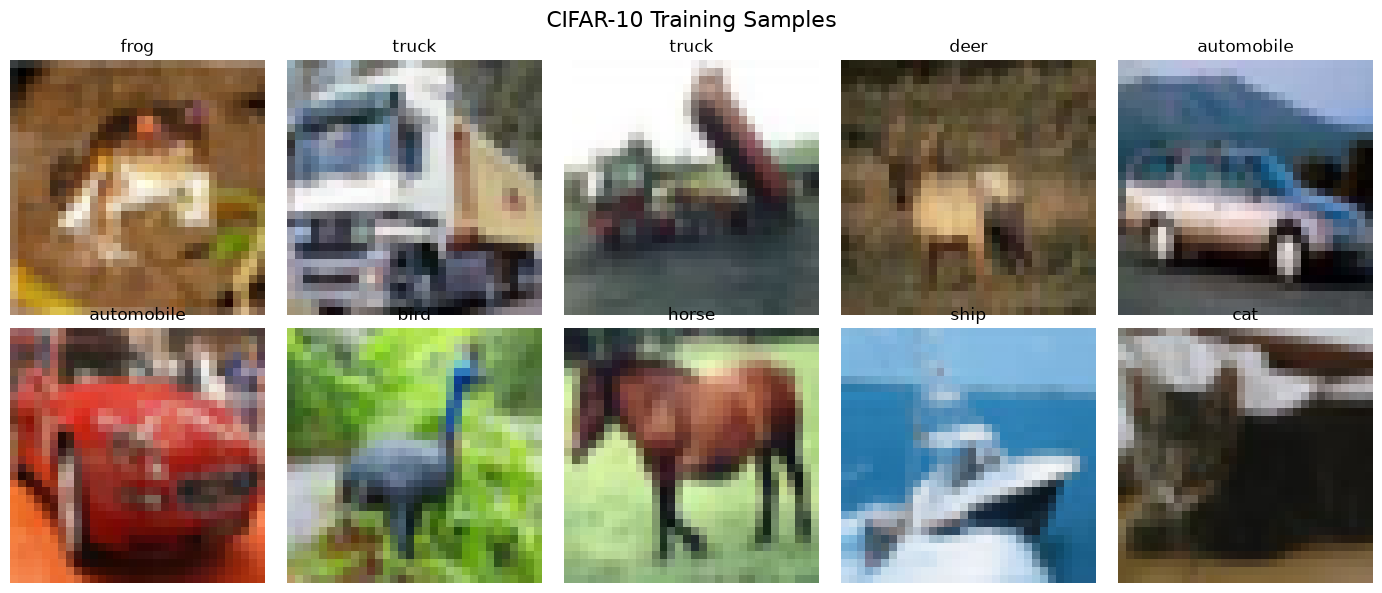

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(14, 6))

mean = torch.tensor([0.4914, 0.4822, 0.4465]).view(3, 1, 1)
std = torch.tensor([0.2470, 0.2435, 0.2616]).view(3, 1, 1)

for i, ax in enumerate(axes.flat):
    image, label = train_dataset[i]

    # Reverse normalisation for visualisation
    image = image * std + mean
    image = image.clamp(0, 1)
    image = image.permute(1, 2, 0).numpy()

    ax.imshow(image)
    ax.set_title(CLASS_NAMES[label])
    ax.axis("off")

plt.suptitle("CIFAR-10 Training Samples", fontsize=16)
plt.tight_layout()
plt.show()

5. Controlled Training-Data Subsets

Objective

Investigate how training-data availability affects image-classification performance.

Four training-data fractions will be evaluated:

- 10%: 5,000 images
- 25%: 12,500 images
- 50%: 25,000 images
- 100%: 50,000 images

These fractions refer to the original CIFAR-10 training set. The test set remains separate and is not used to construct the training subsets.

Methodology

A fixed random seed will be used to select reproducible subsets. The subsets will be nested: the 10% subset will be contained in the 25% subset, which will be contained in the 50% subset, and so on.

This approach makes comparisons across data fractions easier to interpret because larger subsets retain the examples included in smaller subsets.

Important: These are training subsets, not final train/validation splits. We will establish a consistent validation protocol before training models. Any validation examples must be excluded from the data available for model fitting.


In [4]:
from torch.utils.data import Subset

DATA_FRACTIONS = [0.10, 0.25, 0.50, 1.00]

subset_rng = np.random.default_rng(SEED)

# Generate one reproducible ordering of training indices.
permuted_indices = subset_rng.permutation(len(train_dataset))

train_subsets = {}

for fraction in DATA_FRACTIONS:
    subset_size = int(len(train_dataset) * fraction)
    indices = permuted_indices[:subset_size].tolist()

    train_subsets[fraction] = Subset(train_dataset, indices)

    print(
        f"{fraction:>5.0%} of training data: "
        f"{len(train_subsets[fraction]):,} images"
    )

  10% of training data: 5,000 images
  25% of training data: 12,500 images
  50% of training data: 25,000 images
 100% of training data: 50,000 images


6. Verify Subset Construction

We verify that the subsets contain the intended number of images and that the nested-subset property holds.

This check helps prevent accidental inconsistencies in the data-efficiency experiment.

In [5]:
assert len(train_subsets[0.10]) == 5_000
assert len(train_subsets[0.25]) == 12_500
assert len(train_subsets[0.50]) == 25_000
assert len(train_subsets[1.00]) == 50_000

indices_by_fraction = {
    fraction: set(subset.indices)
    for fraction, subset in train_subsets.items()
}

assert indices_by_fraction[0.10].issubset(indices_by_fraction[0.25])
assert indices_by_fraction[0.25].issubset(indices_by_fraction[0.50])
assert indices_by_fraction[0.50].issubset(indices_by_fraction[1.00])

print("All subset-size and nesting checks passed.")

All subset-size and nesting checks passed.


7. Training and Validation Protocol

Objective

Create mutually exclusive training and validation partitions.

The original CIFAR-10 training set contains 50,000 images. We will reserve 5,000 images for validation and use the remaining 45,000 as the training pool.

The four data fractions will now be calculated from this 45,000-image pool. The resulting subset sizes will therefore differ from those calculated using the entire original training set.

The 10,000-image CIFAR-10 test set remains untouched until final evaluation.

Data Leakage Prevention

- Validation images will not be used for gradient updates.
- Test images will not be used for hyperparameter selection.
- The same validation and test partitions will be used when comparing models.
- Subset selection will be reproducible.

In [6]:
from torch.utils.data import random_split

VALIDATION_SIZE = 5_000
TRAIN_POOL_SIZE = len(train_dataset) - VALIDATION_SIZE

split_generator = torch.Generator().manual_seed(SEED)

train_pool, validation_dataset = random_split(
    train_dataset,
    [TRAIN_POOL_SIZE, VALIDATION_SIZE],
    generator=split_generator
)

print("Training pool:", len(train_pool))
print("Validation set:", len(validation_dataset))
print("Test set:", len(test_dataset))

Training pool: 45000
Validation set: 5000
Test set: 10000


In [7]:
pool_indices = np.random.default_rng(SEED).permutation(
    len(train_pool)
)

train_subsets = {}

for fraction in DATA_FRACTIONS:
    subset_size = int(len(train_pool) * fraction)

    indices = pool_indices[:subset_size].tolist()

    train_subsets[fraction] = Subset(
        train_pool,
        indices
    )

    print(
        f"{fraction:>5.0%}: "
        f"{len(train_subsets[fraction]):,} training images"
    )

print("\nValidation images:", len(validation_dataset))
print("Test images:", len(test_dataset))

  10%: 4,500 training images
  25%: 11,250 training images
  50%: 22,500 training images
 100%: 45,000 training images

Validation images: 5000
Test images: 10000


8. Classical Convolutional Neural Network Baseline

Objective

Establish a classical image-classification baseline for CIFAR-10.

A convolutional neural network (CNN) is used to learn spatial features from images and predict one of the ten CIFAR-10 classes.

Architecture

The baseline contains:

- Two convolutional layers with ReLU activations.
- Max-pooling layers for spatial downsampling.
- A fully connected classification head.
- Ten output logits, one for each class.

Experimental Role

This model provides a reference for later comparison with the hybrid quantum-classical model. The baseline uses standard classical computation and does not contain a quantum circuit.

We will first train on 10% of the training pool. This initial run is a pipeline check, not a final scientific result.

In [8]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class ClassicalCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


model = ClassicalCNN().to(DEVICE)

print(model)
print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)

ClassicalCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
Trainable parameters: 545098


9. Mini-batch Data Loading

Training data is processed in mini-batches to manage memory usage and perform stochastic gradient descent.

The initial experiment uses:

- Training fraction: 10%
- Batch size: 128
- Shuffling: enabled for training
- Shuffling: disabled for validation

The validation set remains separate from the training subset.

In [9]:
from torch.utils.data import DataLoader

BATCH_SIZE = 128

train_loader = DataLoader(
    train_subsets[0.10],
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

images, labels = next(iter(train_loader))

print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)
print("Device:", DEVICE)

Batch image shape: torch.Size([128, 3, 32, 32])
Batch label shape: torch.Size([128])
Device: cpu


10. Training and Evaluation Procedure

The model will be trained using cross-entropy loss and the Adam optimiser.

After each epoch, validation loss and accuracy will be calculated. Validation data will not be used for gradient updates.

We will record:

- Training loss
- Validation loss
- Training accuracy
- Validation accuracy
- Epoch duration

For this initial pipeline check, we will run three epochs. This is not necessarily sufficient for optimal model performance.

In [10]:
import time


def evaluate(model, loader, criterion):
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            logits = model(images)
            loss = criterion(logits, labels)

            batch_size = labels.size(0)

            total_loss += loss.item() * batch_size
            total_correct += (logits.argmax(dim=1) == labels).sum().item()
            total_samples += batch_size

    return {
        "loss": total_loss / total_samples,
        "accuracy": total_correct / total_samples,
    }


def train_model(model, train_loader, validation_loader, epochs=3, lr=1e-3):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    history = []

    for epoch in range(1, epochs + 1):
        start_time = time.perf_counter()

        model.train()

        total_loss = 0.0
        total_correct = 0
        total_samples = 0

        for images, labels in train_loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            optimizer.zero_grad()

            logits = model(images)
            loss = criterion(logits, labels)

            loss.backward()
            optimizer.step()

            batch_size = labels.size(0)

            total_loss += loss.item() * batch_size
            total_correct += (logits.argmax(dim=1) == labels).sum().item()
            total_samples += batch_size

        train_loss = total_loss / total_samples
        train_accuracy = total_correct / total_samples

        val_metrics = evaluate(
            model,
            validation_loader,
            criterion
        )

        epoch_seconds = time.perf_counter() - start_time

        row = {
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "validation_loss": val_metrics["loss"],
            "validation_accuracy": val_metrics["accuracy"],
            "epoch_seconds": epoch_seconds,
        }

        history.append(row)

        print(
            f"Epoch {epoch}/{epochs} | "
            f"Train loss: {train_loss:.4f} | "
            f"Train acc: {train_accuracy:.2%} | "
            f"Val loss: {val_metrics['loss']:.4f} | "
            f"Val acc: {val_metrics['accuracy']:.2%} | "
            f"Time: {epoch_seconds:.1f}s"
        )

    return pd.DataFrame(history)

11. Initial Baseline Experiment: 10% Training Data

We now train the classical CNN using the 10% training subset.

This experiment checks that:

1. The model's forward and backward passes work.
2. Parameters update during training.
3. Training and validation metrics are computed correctly.
4. Results can be stored for subsequent analysis.

The model has not yet been tuned, and its results should not be interpreted as a definitive benchmark.

In [11]:
# Reset the seed before initialising the baseline model.
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

baseline_model = ClassicalCNN().to(DEVICE)

baseline_history = train_model(
    model=baseline_model,
    train_loader=train_loader,
    validation_loader=validation_loader,
    epochs=3,
    lr=1e-3
)

baseline_history

Epoch 1/3 | Train loss: 2.0910 | Train acc: 23.71% | Val loss: 1.8277 | Val acc: 36.84% | Time: 11.4s
Epoch 2/3 | Train loss: 1.7518 | Train acc: 37.64% | Val loss: 1.5759 | Val acc: 44.32% | Time: 8.2s
Epoch 3/3 | Train loss: 1.5536 | Train acc: 44.20% | Val loss: 1.4749 | Val acc: 48.28% | Time: 8.0s


,epoch,train_loss,train_accuracy,validation_loss,validation_accuracy,epoch_seconds
0,1,2.091011,0.237111,1.827678,0.3684,11.423866
1,2,1.751817,0.376444,1.575895,0.4432,8.171480
2,3,1.553624,0.442000,1.474924,0.4828,8.037836


12. Baseline Learning Curves

Learning curves show how training and validation performance change over successive epochs.

Training loss should generally decrease as the model learns. Validation performance helps assess whether improvements on the training data translate to unseen examples.

A widening gap between training and validation performance can indicate overfitting, although conclusions should be based on the full training history rather than a single epoch.

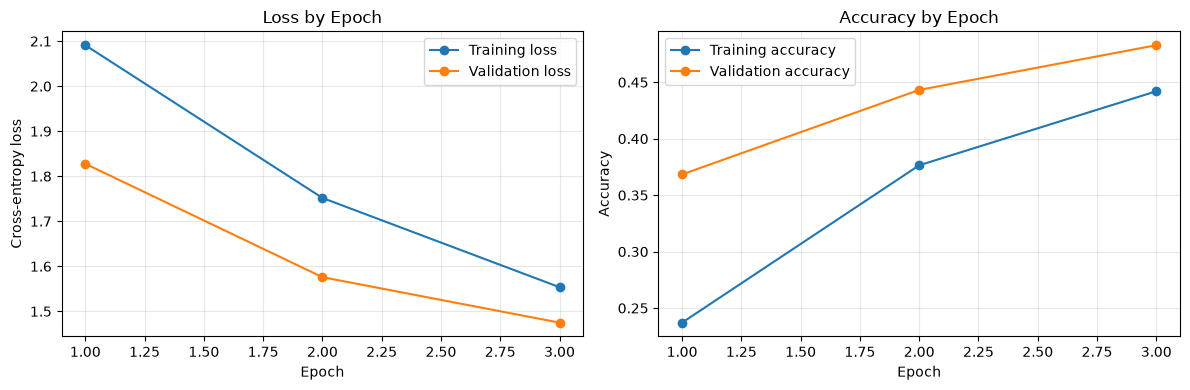

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    baseline_history["epoch"],
    baseline_history["train_loss"],
    marker="o",
    label="Training loss"
)

axes[0].plot(
    baseline_history["epoch"],
    baseline_history["validation_loss"],
    marker="o",
    label="Validation loss"
)

axes[0].set_title("Loss by Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    baseline_history["epoch"],
    baseline_history["train_accuracy"],
    marker="o",
    label="Training accuracy"
)

axes[1].plot(
    baseline_history["epoch"],
    baseline_history["validation_accuracy"],
    marker="o",
    label="Validation accuracy"
)

axes[1].set_title("Accuracy by Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

13. Initial Classical Baseline Results

Experimental Configuration

- Dataset: CIFAR-10
- Training-data fraction: 10% of the training pool
- Number of training images: 4,500
- Validation images: 5,000
- Model: Classical convolutional neural network
- Optimiser: Adam
- Learning rate: 0.001
- Epochs: 3
- Random seed: 42

Observed Results

Training loss decreased from 2.0910 in the first epoch to 1.5510 in the third epoch. Training accuracy increased from 23.67% to 44.40%.

Validation loss decreased from 1.8294 to 1.4731, while validation accuracy increased from 36.70% to 48.20%.

Interpretation

The decreasing training and validation losses indicate that the model is learning useful patterns from the training data. The improvement in validation accuracy suggests that these learned patterns generalise to the held-out validation set.

No clear evidence of overfitting is visible in this short training run. However, longer training and repeated experiments are required to characterise generalisation reliably.

Limitations

This is an initial pipeline-validation experiment, not a fully tuned baseline. The model was trained for only three epochs and evaluated using one random seed.

Further experiments will be required before comparing classical and hybrid quantum-classical architectures.

14. Data-Efficiency Experiment: Varying Training-Set Size

Objective

Investigate how the amount of training data affects the classification performance of a classical convolutional neural network (CNN) on CIFAR-10.

Experimental Design

The same CNN architecture will be trained using four different fractions of the training pool:

- 10%: 4,500 images
- 25%: 11,250 images
- 50%: 22,500 images
- 100%: 45,000 images

A fixed validation set of 5,000 images will be used to evaluate each experiment. The model architecture, optimiser, learning rate, and number of epochs will remain consistent.

Each experiment will start with the same model-initialisation seed. Training-set shuffling will also be controlled for reproducibility.

Evaluation Metrics

- Training loss
- Training accuracy
- Validation loss
- Validation accuracy
- Training time per epoch

The validation results will help determine whether additional training data improves classification performance. The test set will remain untouched until the final evaluation stage.

Important: This initial experiment uses one random seed per training fraction. The results are preliminary; repeated runs with multiple seeds will be needed to assess variability.

In [ ]:
import os
import random
import numpy as np
import pandas as pd
import torch

from torch.utils.data import DataLoader

# Experiment configuration
EPOCHS = 5
LEARNING_RATE = 1e-3
BATCH_SIZE = 128

# Create directory for experiment results
os.makedirs("results", exist_ok=True)

all_histories = []
models_by_fraction = {}

for fraction in DATA_FRACTIONS:

    print("\n" + "=" * 60)
    print(f"Training fraction: {fraction:.0%}")
    print(f"Training images: {len(train_subsets[fraction]):,}")
    print("=" * 60)

    # Reset random seeds
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    # Reproducible data shuffling
    loader_generator = torch.Generator()
    loader_generator.manual_seed(SEED)

    fraction_train_loader = DataLoader(
        train_subsets[fraction],
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        generator=loader_generator
    )

    # Initialise a fresh CNN
    model = ClassicalCNN().to(DEVICE)

    # Train and validate
    history = train_model(
        model,
        fraction_train_loader,
        validation_loader,
        epochs=EPOCHS,
        lr=LEARNING_RATE
    )

    # Record experiment configuration
    history["training_fraction"] = fraction
    history["training_images"] = len(train_subsets[fraction])

    all_histories.append(history)
    models_by_fraction[fraction] = model

    # Save individual experiment history
    history.to_csv(
        f"results/cnn_history_{int(fraction * 100)}pct.csv",
        index=False
    )

# Combine all experiment histories
experiment_history = pd.concat(
    all_histories,
    ignore_index=True
)

experiment_history.to_csv(
    "results/cnn_data_efficiency_history.csv",
    index=False
)

print("\nAll experiments completed.")

display(experiment_history)


Training fraction: 10%
Training images: 4,500
Epoch 1/5 | Train loss: 2.0610 | Train acc: 25.82% | Val loss: 1.8263 | Val acc: 33.22% | Time: 8.5s
Epoch 2/5 | Train loss: 1.7259 | Train acc: 37.04% | Val loss: 1.6409 | Val acc: 41.20% | Time: 8.1s
Epoch 3/5 | Train loss: 1.5435 | Train acc: 43.80% | Val loss: 1.4911 | Val acc: 46.98% | Time: 8.2s
Epoch 4/5 | Train loss: 1.3876 | Train acc: 49.60% | Val loss: 1.4086 | Val acc: 48.38% | Time: 8.1s
Epoch 5/5 | Train loss: 1.2740 | Train acc: 54.80% | Val loss: 1.3818 | Val acc: 50.98% | Time: 8.0s

Training fraction: 25%
Training images: 11,250
Epoch 1/5 | Train loss: 1.8526 | Train acc: 32.21% | Val loss: 1.4889 | Val acc: 47.14% | Time: 15.5s
Epoch 2/5 | Train loss: 1.4629 | Train acc: 46.69% | Val loss: 1.3262 | Val acc: 52.22% | Time: 15.0s
Epoch 3/5 | Train loss: 1.2811 | Train acc: 53.73% | Val loss: 1.2320 | Val acc: 55.98% | Time: 15.6s
Epoch 4/5 | Train loss: 1.1481 | Train acc: 59.48% | Val loss: 1.1478 | Val acc: 59.24% | Time

15. Comparative Analysis of Data Fractions

This section compares the final performance of the classical CNN trained with different amounts of CIFAR-10 training data.

The comparison includes training accuracy, validation accuracy, training loss, validation loss, and total training time.

The difference between training and validation accuracy provides an indication of the generalisation gap. These results will help determine whether increasing training-data quantity improves classification performance.

In [ ]:
# Extract the final epoch for each training fraction
final_results = (
    experiment_history
    .sort_values("epoch")
    .groupby("training_fraction")
    .tail(1)
    .sort_values("training_fraction")
    .reset_index(drop=True)
)

# Calculate total training time across all epochs
total_times = (
    experiment_history
    .groupby("training_fraction")["epoch_seconds"]
    .sum()
    .rename("total_training_seconds")
)

final_results = final_results.merge(
    total_times,
    on="training_fraction"
)

# Calculate generalisation gap in percentage points
final_results["generalisation_gap"] = (
    final_results["train_accuracy"]
    - final_results["validation_accuracy"]
) * 100

comparison = final_results[
    [
        "training_fraction",
        "training_images",
        "train_accuracy",
        "validation_accuracy",
        "generalisation_gap",
        "train_loss",
        "validation_loss",
        "total_training_seconds"
    ]
].copy()

comparison["train_accuracy"] *= 100
comparison["validation_accuracy"] *= 100

comparison = comparison.rename(columns={
    "training_fraction": "Training Fraction",
    "training_images": "Training Images",
    "train_accuracy": "Train Accuracy (%)",
    "validation_accuracy": "Validation Accuracy (%)",
    "generalisation_gap": "Generalisation Gap (pp)",
    "train_loss": "Train Loss",
    "validation_loss": "Validation Loss",
    "total_training_seconds": "Training Time (s)"
})

comparison = comparison.round(3)

comparison.to_csv(
    "results/cnn_data_efficiency_comparison.csv",
    index=False
)

display(comparison)

,Training Fraction,Training Images,Train Accuracy (%),Validation Accuracy (%),Generalisation Gap (pp),Train Loss,Validation Loss,Training Time (s)
0,0.10,4500,54.800,50.98,3.820,1.274,1.382,40.445
1,0.25,11250,62.640,60.20,2.440,1.053,1.116,72.612
2,0.50,22500,66.311,66.70,-0.389,0.943,0.959,129.161
3,1.00,45000,72.318,71.00,1.318,0.783,0.831,241.422


16. Visualising Data Efficiency

Visualisations provide an intuitive comparison of model performance and computational cost across training-set sizes.

The first figure plots validation accuracy against the percentage of training data used. The second compares training time across experiments.

These figures will help identify whether additional data improves generalisation and how the computational cost changes with dataset size.

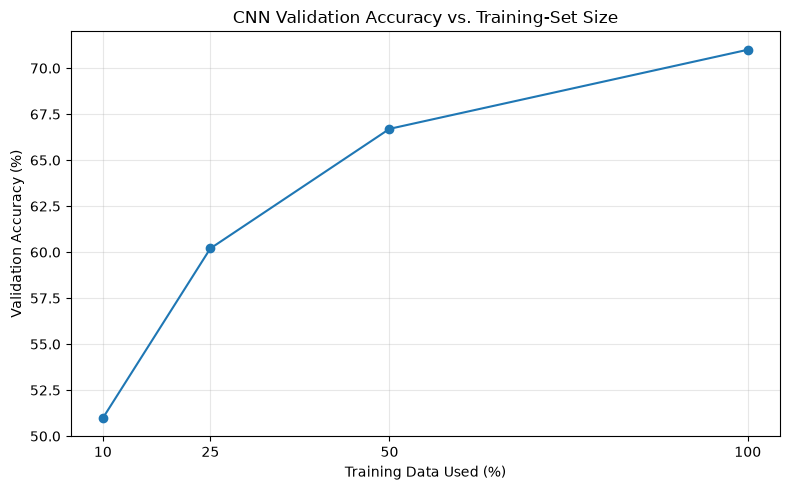

In [ ]:
import matplotlib.pyplot as plt

plot_results = final_results.sort_values("training_fraction")

plt.figure(figsize=(8, 5))

plt.plot(
    plot_results["training_fraction"] * 100,
    plot_results["validation_accuracy"] * 100,
    marker="o"
)

plt.xlabel("Training Data Used (%)")
plt.ylabel("Validation Accuracy (%)")
plt.title("CNN Validation Accuracy vs. Training-Set Size")
plt.xticks([10, 25, 50, 100])
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "results/cnn_validation_accuracy_vs_data.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

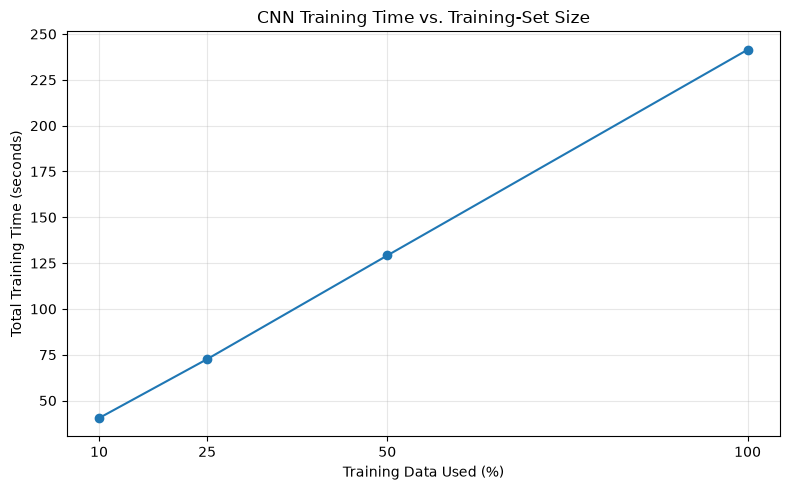

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    plot_results["training_fraction"] * 100,
    plot_results["total_training_seconds"],
    marker="o"
)

plt.xlabel("Training Data Used (%)")
plt.ylabel("Total Training Time (seconds)")
plt.title("CNN Training Time vs. Training-Set Size")
plt.xticks([10, 25, 50, 100])
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "results/cnn_training_time_vs_data.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

17. Learning-Curve Analysis

Learning curves show how training and validation performance change over successive epochs.

Training loss should generally decrease as the model learns. Validation loss and accuracy help assess whether these improvements transfer to unseen data.

Comparing learning curves across training fractions can reveal whether smaller datasets learn more slowly, reach lower performance, or exhibit a larger generalisation gap.

The curves will be interpreted alongside the final metrics rather than used as standalone evidence of generalisation.

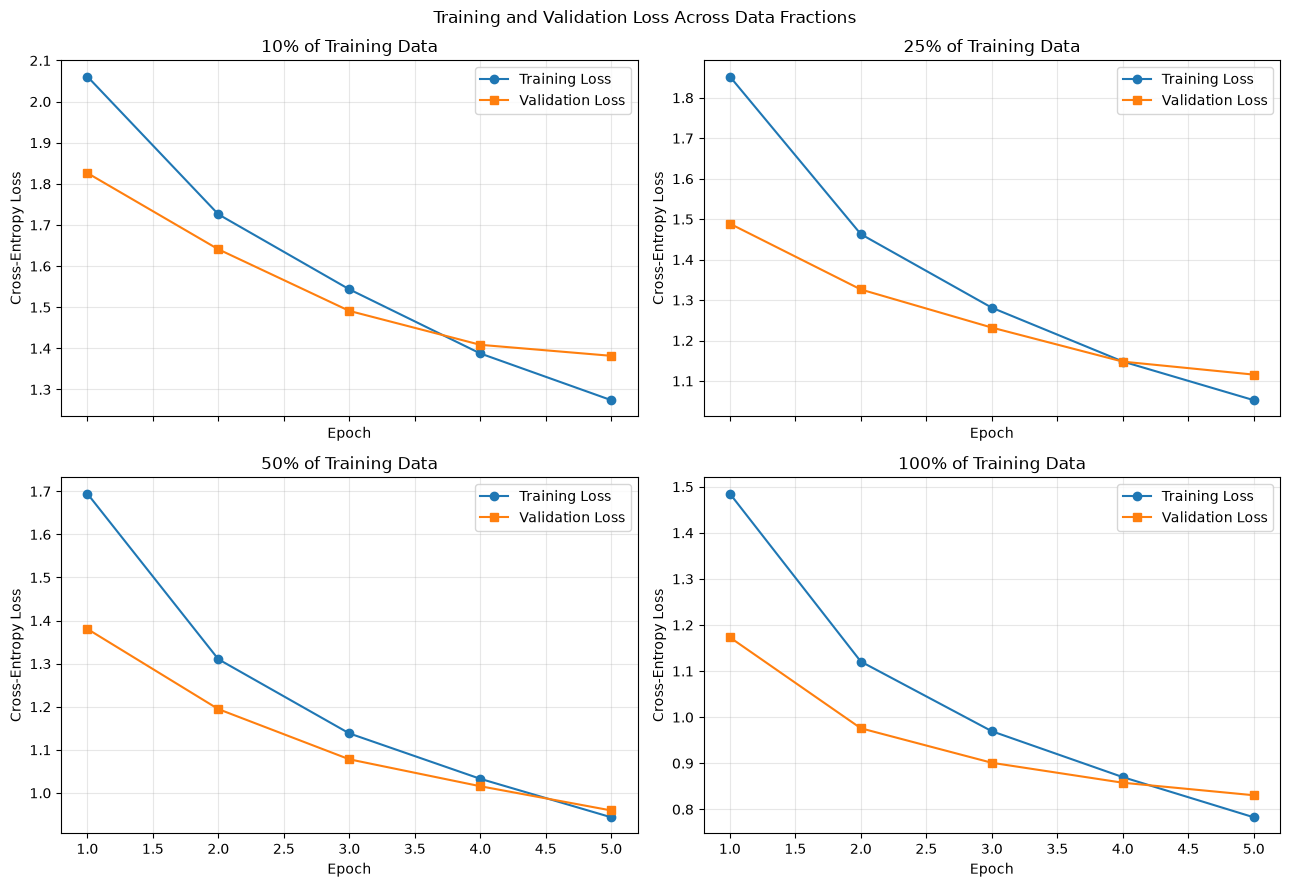

In [ ]:
fractions = sorted(experiment_history["training_fraction"].unique())

fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 9),
    sharex=True
)

axes = axes.flatten()

for ax, fraction in zip(axes, fractions):
    subset = (
        experiment_history[
            experiment_history["training_fraction"] == fraction
        ]
        .sort_values("epoch")
    )

    ax.plot(
        subset["epoch"],
        subset["train_loss"],
        marker="o",
        label="Training Loss"
    )

    ax.plot(
        subset["epoch"],
        subset["validation_loss"],
        marker="s",
        label="Validation Loss"
    )

    ax.set_title(f"{fraction:.0%} of Training Data")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Cross-Entropy Loss")
    ax.grid(True, alpha=0.3)
    ax.legend()

fig.suptitle("Training and Validation Loss Across Data Fractions")
fig.tight_layout()

fig.savefig(
    "results/cnn_learning_curves_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

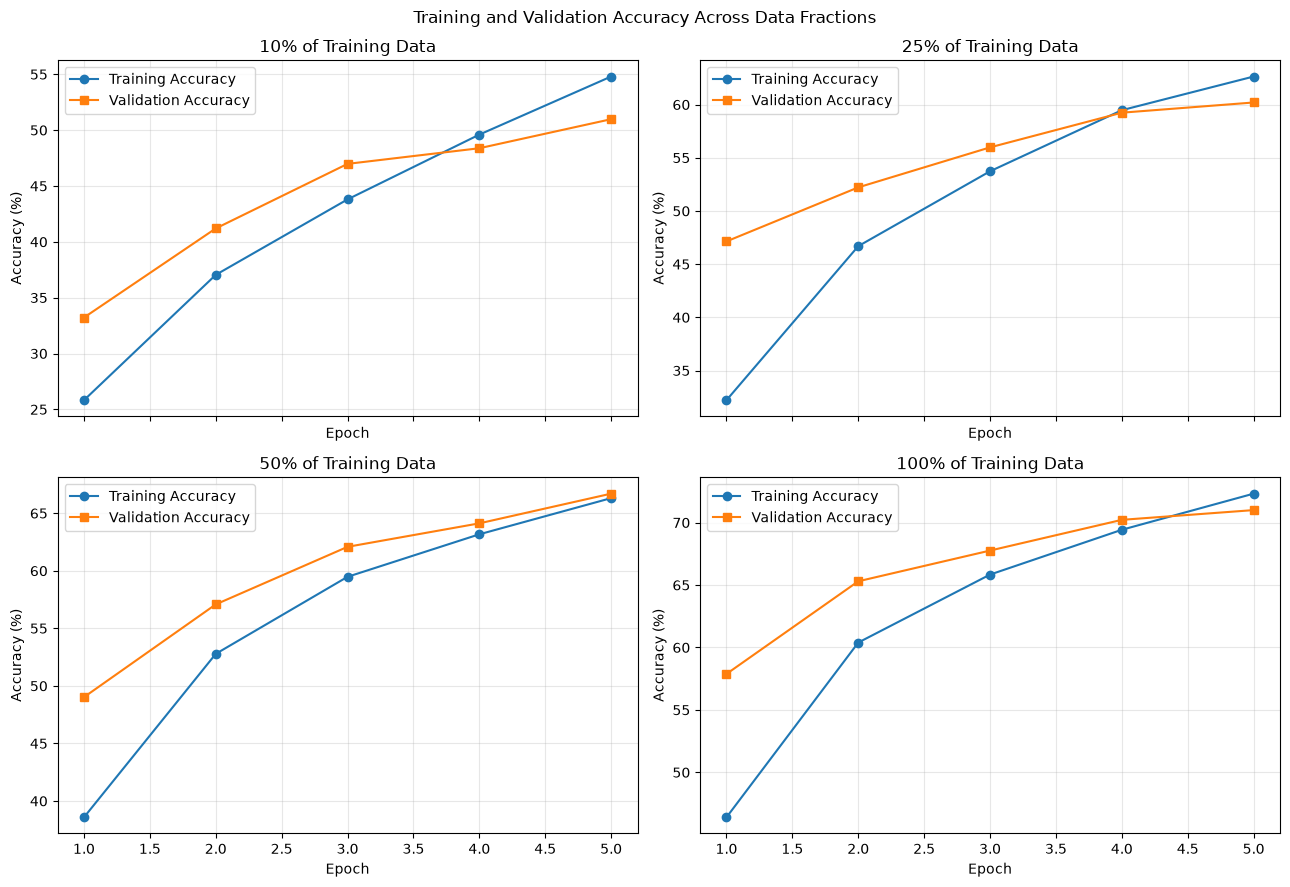

In [ ]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 9),
    sharex=True
)

axes = axes.flatten()

for ax, fraction in zip(axes, fractions):
    subset = (
        experiment_history[
            experiment_history["training_fraction"] == fraction
        ]
        .sort_values("epoch")
    )

    ax.plot(
        subset["epoch"],
        subset["train_accuracy"] * 100,
        marker="o",
        label="Training Accuracy"
    )

    ax.plot(
        subset["epoch"],
        subset["validation_accuracy"] * 100,
        marker="s",
        label="Validation Accuracy"
    )

    ax.set_title(f"{fraction:.0%} of Training Data")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Accuracy (%)")
    ax.grid(True, alpha=0.3)
    ax.legend()

fig.suptitle("Training and Validation Accuracy Across Data Fractions")
fig.tight_layout()

fig.savefig(
    "results/cnn_learning_curves_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

18. Saving the Classical CNN Baseline

The trained CNN models and experiment configuration will be saved to support reproducibility and future comparisons.

The model trained on the full training pool will serve as the principal classical baseline for subsequent experiments.

The saved checkpoint will contain the model parameters, architecture identifier, training configuration, random seed, and final validation metrics.

This checkpoint will support later evaluation and comparison with the hybrid quantum-classical model.

In [ ]:
import json

# Select the model trained with 100% of the training pool
full_data_fraction = 1.0
full_data_model = models_by_fraction[full_data_fraction]

full_data_metrics = (
    final_results[
        final_results["training_fraction"] == full_data_fraction
    ]
    .iloc[0]
)

# Save model checkpoint
checkpoint = {
    "model_state_dict": full_data_model.state_dict(),
    "model_name": "ClassicalCNN",
    "dataset": "CIFAR-10",
    "training_fraction": full_data_fraction,
    "training_images": len(train_subsets[full_data_fraction]),
    "validation_images": len(validation_dataset),
    "epochs": EPOCHS,
    "learning_rate": LEARNING_RATE,
    "batch_size": BATCH_SIZE,
    "seed": SEED,
    "validation_accuracy": float(
        full_data_metrics["validation_accuracy"]
    ),
    "validation_loss": float(
        full_data_metrics["validation_loss"]
    )
}

torch.save(
    checkpoint,
    "results/classical_cnn_full_data.pt"
)

# Save experiment configuration
config = {
    "dataset": "CIFAR-10",
    "model": "ClassicalCNN",
    "seed": SEED,
    "data_fractions": DATA_FRACTIONS,
    "training_pool_size": len(train_pool),
    "validation_size": len(validation_dataset),
    "test_size": len(test_dataset),
    "epochs": EPOCHS,
    "learning_rate": LEARNING_RATE,
    "batch_size": BATCH_SIZE,
    "device": str(DEVICE)
}

with open(
    "results/experiment_config.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(config, file, indent=4)

print("Saved full-data classical CNN checkpoint.")
print("Saved experiment configuration.")
print(
    "Full-data validation accuracy:",
    f"{full_data_metrics['validation_accuracy']:.2%}"
)

Saved full-data classical CNN checkpoint.
Saved experiment configuration.
Full-data validation accuracy: 71.00%


19. Baseline Results Analysis

Objective

Analyse the performance of the classical CNN across different training-data fractions to establish a reference point for subsequent Vision Transformer and Hybrid Quantum-Classical Vision Transformer experiments.

Analysis

The experiments evaluate the relationship between training-data quantity, classification accuracy, generalisation, and computational cost.

The following metrics will be examined:

- Final training accuracy and validation accuracy.
- Training and validation loss.
- Generalisation gap between training and validation accuracy.
- Total training time across epochs.

Research Significance

The classical CNN provides a reference for evaluating the performance of subsequent architectures. However, comparisons against a CNN alone cannot isolate the contribution of the quantum component. A classical Vision Transformer baseline is also required.

The observed validation accuracy will be treated as an experimental result rather than evidence that one architecture is inherently superior.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# Verify that the experiment results exist
results_path = "results/cnn_data_efficiency_history.csv"

if not os.path.exists(results_path):
    raise FileNotFoundError(
        f"Could not find {results_path}. "
        "Check that Section 14 completed successfully."
    )

experiment_history = pd.read_csv(results_path)

# Select the final epoch of each experiment
final_results = (
    experiment_history
    .sort_values("epoch")
    .groupby("training_fraction")
    .tail(1)
    .sort_values("training_fraction")
    .reset_index(drop=True)
)

# Calculate generalisation gap
final_results["generalisation_gap_pp"] = (
    final_results["train_accuracy"]
    - final_results["validation_accuracy"]
) * 100

# Display baseline summary
baseline_summary = final_results[
    [
        "training_fraction",
        "training_images",
        "train_accuracy",
        "validation_accuracy",
        "train_loss",
        "validation_loss",
        "generalisation_gap_pp"
    ]
].copy()

baseline_summary["train_accuracy"] *= 100
baseline_summary["validation_accuracy"] *= 100

baseline_summary = baseline_summary.rename(columns={
    "training_fraction": "Training Fraction",
    "training_images": "Training Images",
    "train_accuracy": "Train Accuracy (%)",
    "validation_accuracy": "Validation Accuracy (%)",
    "train_loss": "Train Loss",
    "validation_loss": "Validation Loss",
    "generalisation_gap_pp": "Generalisation Gap (pp)"
})

display(baseline_summary.round(3))

# Identify the best validation result
best_row = final_results.loc[
    final_results["validation_accuracy"].idxmax()
]

print(
    f"\nBest training fraction: "
    f"{best_row['training_fraction']:.0%}"
)

print(
    f"Best final validation accuracy: "
    f"{best_row['validation_accuracy']:.2%}"
)

,Training Fraction,Training Images,Train Accuracy (%),Validation Accuracy (%),Train Loss,Validation Loss,Generalisation Gap (pp)
0,0.10,4500,54.800,50.98,1.274,1.382,3.820
1,0.25,11250,62.640,60.20,1.053,1.116,2.440
2,0.50,22500,66.311,66.70,0.943,0.959,-0.389
3,1.00,45000,72.318,71.00,0.783,0.831,1.318



Best training fraction: 100%
Best final validation accuracy: 71.00%


20. Classical Vision Transformer Baseline

Objective

Implement a compact classical Vision Transformer (ViT) to establish a Transformer-based baseline for comparison with the proposed Hybrid Quantum-Classical Vision Transformer.

Architecture

The model will consist of:

1. Patch embedding to convert image regions into token representations.
2. Learnable positional embeddings to retain spatial information.
3. Transformer encoder layers using multi-head self-attention.
4. A classification token to aggregate image-level information.
5. A classification head producing scores for the ten CIFAR-10 classes.

Experimental Controls

The ViT will use the same dataset splits and training-data fractions as the CNN. Its architecture, parameter count, training time, and hyperparameters will be documented.

The classical ViT will later be compared with the hybrid model to help determine whether adding a quantum component provides measurable benefits.

Implementation Note

This is a compact ViT designed for experimentation on 32 × 32 CIFAR-10 images. Its performance must be measured experimentally; it should not be assumed to outperform the CNN.

In [ ]:
import torch
import torch.nn as nn


class ClassicalViT(nn.Module):
    def __init__(
        self,
        image_size=32,
        patch_size=4,
        num_classes=10,
        embed_dim=128,
        num_heads=4,
        num_layers=4,
        mlp_dim=256,
        dropout=0.1
    ):
        super().__init__()

        assert image_size % patch_size == 0

        self.image_size = image_size
        self.patch_size = patch_size

        num_patches = (image_size // patch_size) ** 2

        # Convert image patches into embedding vectors
        self.patch_embedding = nn.Conv2d(
            in_channels=3,
            out_channels=embed_dim,
            kernel_size=patch_size,
            stride=patch_size
        )

        # Learnable classification token and positional embeddings
        self.cls_token = nn.Parameter(
            torch.zeros(1, 1, embed_dim)
        )

        self.pos_embedding = nn.Parameter(
            torch.zeros(1, num_patches + 1, embed_dim)
        )

        self.embedding_dropout = nn.Dropout(dropout)

        # Transformer encoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=mlp_dim,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers,
            norm=nn.LayerNorm(embed_dim)
        )

        # Classification head
        self.classifier = nn.Sequential(
            nn.LayerNorm(embed_dim),
            nn.Linear(embed_dim, num_classes)
        )

        nn.init.trunc_normal_(self.cls_token, std=0.02)
        nn.init.trunc_normal_(self.pos_embedding, std=0.02)

    def forward(self, x):
        # x: [batch, 3, 32, 32]
        x = self.patch_embedding(x)

        # [batch, embed_dim, grid_h, grid_w]
        x = x.flatten(2).transpose(1, 2)

        # Add classification token
        cls_tokens = self.cls_token.expand(x.size(0), -1, -1)
        x = torch.cat([cls_tokens, x], dim=1)

        # Add positional embeddings
        x = x + self.pos_embedding
        x = self.embedding_dropout(x)

        # Transformer encoder
        x = self.transformer(x)

        # Classification token representation
        cls_representation = x[:, 0]

        return self.classifier(cls_representation)


# Initialise the model
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

vit_model = ClassicalViT().to(DEVICE)

# Verify the output shape
sample_images, sample_labels = next(iter(train_loader))
sample_images = sample_images[:8].to(DEVICE)

with torch.no_grad():
    sample_outputs = vit_model(sample_images)

print("Device:", DEVICE)
print("Input shape:", tuple(sample_images.shape))
print("Output shape:", tuple(sample_outputs.shape))
print(
    "Trainable parameters:",
    f"{sum(p.numel() for p in vit_model.parameters() if p.requires_grad):,}"
)

assert sample_outputs.shape == (8, 10)
print("ViT forward-pass test passed.")

/tmp/ipykernel_6476/167982418.py:56: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


Device: cpu
Input shape: (8, 3, 32, 32)
Output shape: (8, 10)
Trainable parameters: 546,442
ViT forward-pass test passed.


Section 21 — Experiment Recovery and Resume

This section checks whether previous CNN experiments have been saved. It allows us to reuse existing results when continuing the project, avoiding unnecessary CNN retraining.

In [ ]:
from pathlib import Path
import json
import pandas as pd
import torch

# Project output folders
RESULTS_DIR = Path("results")
MODELS_DIR = Path("models")

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Check files created by the CNN experiments
required_files = [
    RESULTS_DIR / "cnn_data_efficiency_history.csv",
    RESULTS_DIR / "cnn_data_efficiency_comparison.csv",
    RESULTS_DIR / "classical_cnn_full_data.pt",
    RESULTS_DIR / "experiment_config.json",
]

print("Previous experiment files:")
for file_path in required_files:
    status = "FOUND" if file_path.exists() else "MISSING"
    print(f"{status}: {file_path}")

# Load previous CNN results if available
cnn_history_path = RESULTS_DIR / "cnn_data_efficiency_history.csv"

if cnn_history_path.exists():
    cnn_history = pd.read_csv(cnn_history_path)

    print("\nCNN history loaded successfully.")
    display(cnn_history.tail())

else:
    print(
        "\nCNN history is missing. "
        "Do not rerun the experiment until you check the results folder."
    )

# Load experiment configuration if available
config_path = RESULTS_DIR / "experiment_config.json"

if config_path.exists():
    with open(config_path, "r", encoding="utf-8") as file:
        experiment_config = json.load(file)

    print("\nPrevious experiment configuration:")
    print(json.dumps(experiment_config, indent=2))

Previous experiment files:
FOUND: results/cnn_data_efficiency_history.csv
FOUND: results/cnn_data_efficiency_comparison.csv
FOUND: results/classical_cnn_full_data.pt
FOUND: results/experiment_config.json

CNN history loaded successfully.


,epoch,train_loss,train_accuracy,validation_loss,validation_accuracy,epoch_seconds,training_fraction,training_images
15,1,1.485010,0.464000,1.173173,0.5788,48.545087,1.0,45000
16,2,1.120632,0.603933,0.975915,0.6530,48.361933,1.0,45000
17,3,0.969530,0.658378,0.901063,0.6776,48.279852,1.0,45000
18,4,0.869954,0.694244,0.857775,0.7022,48.256361,1.0,45000
19,5,0.782743,0.723178,0.830620,0.7100,47.979109,1.0,45000



Previous experiment configuration:
{
  "dataset": "CIFAR-10",
  "model": "ClassicalCNN",
  "seed": 42,
  "data_fractions": [
    0.1,
    0.25,
    0.5,
    1.0
  ],
  "training_pool_size": 45000,
  "validation_size": 5000,
  "test_size": 10000,
  "epochs": 5,
  "learning_rate": 0.001,
  "batch_size": 128,
  "device": "cpu"
}


Section 22 — Classical Vision Transformer Training

In this section, the Classical Vision Transformer will be trained using 10%, 25%, 50%, and 100% of the available training pool.

The same validation set will be used for all experiments. Training histories and model checkpoints will be saved so that completed experiments can be reused without retraining.

The initial experiment will use five epochs per data fraction to keep the computational cost manageable.

In [ ]:
import time
import random
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

VIT_EPOCHS = 3
VIT_BATCH_SIZE = 128
VIT_LEARNING_RATE = 0.001

vit_histories = {}
vit_models_by_fraction = {}

for fraction in DATA_FRACTIONS:

    percentage = int(fraction * 100)

    history_path = RESULTS_DIR / f"vit_history_{percentage}pct.csv"
    checkpoint_path = MODELS_DIR / f"classical_vit_{percentage}pct.pt"

    # Skip experiments already saved successfully
    if history_path.exists() and checkpoint_path.exists():

        print(f"\nSkipping completed experiment: {percentage}%")

        vit_histories[fraction] = pd.read_csv(history_path)

        vit_models_by_fraction[fraction] = torch.load(
            checkpoint_path,
            map_location=DEVICE,
            weights_only=True
        )

        continue

    print(f"\nTraining Classical ViT with {percentage}% of training data")

    # Reproducibility
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    # Fresh model for each data fraction
    model = ClassicalViT().to(DEVICE)

    generator = torch.Generator().manual_seed(SEED)

    fraction_loader = DataLoader(
        train_subsets[fraction],
        batch_size=VIT_BATCH_SIZE,
        shuffle=True,
        generator=generator,
        num_workers=0,
        pin_memory=torch.cuda.is_available()
    )

    start_time = time.time()

    # Match your existing function's actual signature
    history = train_model(
        model,
        fraction_loader,
        validation_loader,
        epochs=VIT_EPOCHS,
        lr=VIT_LEARNING_RATE
    )

    total_seconds = time.time() - start_time

    # Save history and experiment metadata
    history["data_fraction"] = fraction
    history["training_samples"] = len(train_subsets[fraction])
    history["total_experiment_seconds"] = total_seconds

    history.to_csv(history_path, index=False)

    # Save model weights
    torch.save(model.state_dict(), checkpoint_path)

    vit_histories[fraction] = history
    vit_models_by_fraction[fraction] = model

    print(f"Completed: {percentage}%")
    print(f"Training time: {total_seconds / 60:.2f} minutes")
    print(f"Saved history: {history_path}")
    print(f"Saved checkpoint: {checkpoint_path}")

# Combine histories from completed and newly trained experiments
vit_history_df = pd.concat(
    [
        history.assign(data_fraction=fraction)
        for fraction, history in vit_histories.items()
    ],
    ignore_index=True
)

vit_history_df.to_csv(
    RESULTS_DIR / "vit_data_efficiency_history.csv",
    index=False
)

print("\nViT experiments completed or recovered.")
display(vit_history_df.tail())


Skipping completed experiment: 10%

Skipping completed experiment: 25%

Skipping completed experiment: 50%

Training Classical ViT with 100% of training data


/tmp/ipykernel_6476/167982418.py:56: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


Epoch 1/3 | Train loss: 1.7361 | Train acc: 35.19% | Val loss: 1.4591 | Val acc: 45.44% | Time: 310.1s
Epoch 2/3 | Train loss: 1.3989 | Train acc: 48.86% | Val loss: 1.2755 | Val acc: 53.68% | Time: 355.2s
Epoch 3/3 | Train loss: 1.2565 | Train acc: 54.55% | Val loss: 1.2131 | Val acc: 55.54% | Time: 324.7s
Completed: 100%
Training time: 16.50 minutes
Saved history: results/vit_history_100pct.csv
Saved checkpoint: models/classical_vit_100pct.pt

ViT experiments completed or recovered.


,epoch,train_loss,train_accuracy,validation_loss,validation_accuracy,epoch_seconds,data_fraction,training_samples,total_experiment_seconds
7,2,1.587356,0.414444,1.500109,0.4496,163.411192,0.5,22500,489.958798
8,3,1.428716,0.477378,1.379053,0.4862,162.453547,0.5,22500,489.958798
9,1,1.736055,0.351889,1.459144,0.4544,310.103854,1.0,45000,990.058676
10,2,1.398868,0.488556,1.275529,0.5368,355.220676,1.0,45000,990.058676
11,3,1.256452,0.545511,1.213134,0.5554,324.725920,1.0,45000,990.058676


Section 23 — Classical ViT Results Analysis

This section summarises the final training and validation metrics for each data fraction. It helps identify how the amount of training data affects the Vision Transformer's performance and generalisation.

In [ ]:
import pandas as pd

vit_history_df = pd.read_csv(
    RESULTS_DIR / "vit_data_efficiency_history.csv"
)

vit_summary_rows = []

for fraction in sorted(vit_history_df["data_fraction"].unique()):

    subset = vit_history_df[
        vit_history_df["data_fraction"] == fraction
    ].sort_values("epoch")

    final_epoch = subset.iloc[-1]

    train_accuracy = float(final_epoch["train_accuracy"])
    validation_accuracy = float(final_epoch["validation_accuracy"])

    vit_summary_rows.append({
        "Data Fraction (%)": int(fraction * 100),
        "Training Samples": int(final_epoch["training_samples"]),
        "Train Accuracy (%)": train_accuracy * 100,
        "Validation Accuracy (%)": validation_accuracy * 100,
        "Generalisation Gap (percentage points)": (
            train_accuracy - validation_accuracy
        ) * 100,
        "Final Train Loss": float(final_epoch["train_loss"]),
        "Final Validation Loss": float(final_epoch["validation_loss"])
    })

vit_summary = pd.DataFrame(vit_summary_rows)

vit_summary.to_csv(
    RESULTS_DIR / "vit_data_efficiency_comparison.csv",
    index=False
)

display(vit_summary.round(3))

best_vit_row = vit_summary.loc[
    vit_summary["Validation Accuracy (%)"].idxmax()
]

print(
    f"\nBest validation accuracy: "
    f"{best_vit_row['Validation Accuracy (%)']:.2f}%"
)

print(
    f"Training data used: "
    f"{best_vit_row['Data Fraction (%)']}%"
)

,Data Fraction (%),Training Samples,Train Accuracy (%),Validation Accuracy (%),Generalisation Gap (percentage points),Final Train Loss,Final Validation Loss
0,10,4500,31.756,33.34,-1.584,1.796,1.791
1,25,11250,39.493,40.86,-1.367,1.624,1.579
2,50,22500,47.738,48.62,-0.882,1.429,1.379
3,100,45000,54.551,55.54,-0.989,1.256,1.213



Best validation accuracy: 55.54%
Training data used: 100.0%


Section 24 — Visualising ViT Data Efficiency

This section plots validation accuracy against the amount of training data used. The graph will help reveal whether increasing the training data consistently improves the model's performance.

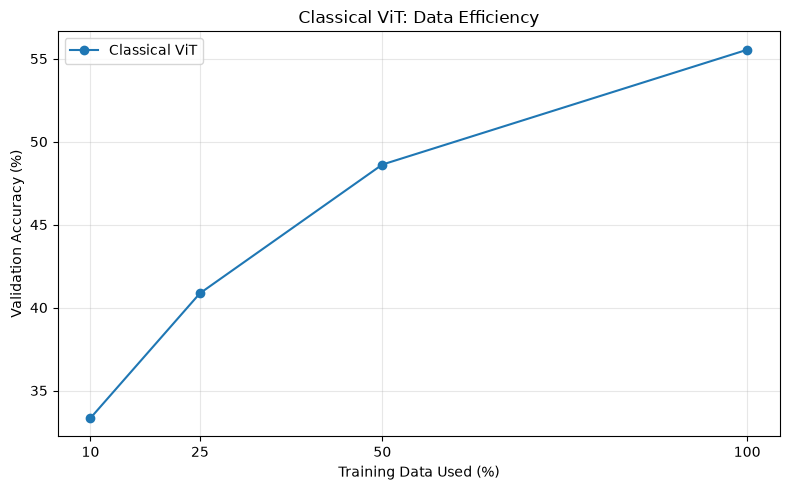

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    vit_summary["Data Fraction (%)"],
    vit_summary["Validation Accuracy (%)"],
    marker="o",
    label="Classical ViT"
)

plt.xlabel("Training Data Used (%)")
plt.ylabel("Validation Accuracy (%)")
plt.title("Classical ViT: Data Efficiency")
plt.xticks([10, 25, 50, 100])
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "vit_data_efficiency.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Section 25 — Quantum Library Setup

This section prepares the environment for implementing a hybrid quantum-classical neural network.

We will use PennyLane to build a parameterised quantum circuit that can integrate with PyTorch. First, we will verify the installation and check whether the required libraries are available.

In [ ]:
%pip install pennylane

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 13.6 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 15.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 11.8 MB/s  0:00:02m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 43.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 36.0 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12/12 [pennylane]12 [pennylane]lightning]
Note: you may need to restart the kernel to use updated packages.


In [ ]:
# Check whether PennyLane is installed

try:
    import pennylane as qml
    print("PennyLane version:", qml.__version__)
    print("Quantum library is ready.")

except ImportError:
    print("PennyLane is not installed.")
    print("Install it by running the command below in a separate cell:")
    print("%pip install pennylane")

PennyLane version: 0.45.1
Quantum library is ready.


Section 26 — Parameterised Quantum Circuit

In this section, we will implement a small quantum circuit using PennyLane.

The circuit will encode classical input features into quantum states, apply trainable quantum operations, and measure the resulting states to produce numerical outputs.

These outputs will later be integrated into a classical neural network. We will begin with four qubits to keep simulation computationally manageable.

In [ ]:
import pennylane as qml
import torch
import torch.nn as nn

N_QUBITS = 4
N_Q_LAYERS = 2

# Quantum simulator
quantum_device = qml.device(
    "default.qubit",
    wires=N_QUBITS
)

@qml.qnode(quantum_device, interface="torch")
def quantum_circuit(inputs, weights):

    # Encode classical features into quantum states
    for wire in range(N_QUBITS):
        qml.RY(inputs[wire], wires=wire)

    # Trainable quantum layers
    for layer in range(N_Q_LAYERS):

        for wire in range(N_QUBITS):
            qml.RY(
                weights[layer, wire, 0],
                wires=wire
            )

            qml.RZ(
                weights[layer, wire, 1],
                wires=wire
            )

        # Entangle neighbouring qubits
        for wire in range(N_QUBITS - 1):
            qml.CNOT(
                wires=[wire, wire + 1]
            )

    # Measure each qubit
    return [
        qml.expval(qml.PauliZ(wire))
        for wire in range(N_QUBITS)
    ]


# Test the circuit
test_inputs = torch.tensor(
    [0.1, 0.2, 0.3, 0.4],
    dtype=torch.float32
)

test_weights = torch.randn(
    N_Q_LAYERS,
    N_QUBITS,
    2,
    dtype=torch.float32
)

test_output = quantum_circuit(
    test_inputs,
    test_weights
)

print("Quantum circuit output:")
print(test_output)

Quantum circuit output:
[tensor(-0.0165, dtype=torch.float64), tensor(0.3187, dtype=torch.float64), tensor(-0.0103, dtype=torch.float64), tensor(0.2860, dtype=torch.float64)]


Section 27 — Quantum Gradient Test

Hybrid quantum-classical models require gradients to update trainable parameters during backpropagation.

This section checks whether the quantum circuit produces gradients for its trainable quantum parameters. Successful gradient computation is a prerequisite for integrating the circuit into a trainable model.

In [ ]:
# Create trainable quantum parameters
test_weights = torch.randn(
    N_Q_LAYERS,
    N_QUBITS,
    2,
    dtype=torch.float32,
    requires_grad=True
)

test_inputs = torch.tensor(
    [0.1, 0.2, 0.3, 0.4],
    dtype=torch.float32
)

# Calculate circuit output
output = quantum_circuit(
    test_inputs,
    test_weights
)

# Convert measurements to a tensor
output_tensor = torch.stack(output)

# Define a simple scalar objective
loss = output_tensor.sum()

# Backpropagate
loss.backward()

print("Output:", output_tensor.detach())
print("Gradient exists:", test_weights.grad is not None)

if test_weights.grad is not None:
    print("Gradient shape:", test_weights.grad.shape)
    print("Gradient finite:", torch.isfinite(test_weights.grad).all().item())

Output: tensor([ 0.2010, -0.3980, -0.0588, -0.0349], dtype=torch.float64)
Gradient exists: True
Gradient shape: torch.Size([2, 4, 2])
Gradient finite: True


Section 28 — Hybrid Quantum-Classical Vision Model

This section combines a classical neural network with a parameterised quantum circuit.

The classical feature extractor reduces each input image to four features. These features are encoded into a four-qubit quantum circuit, which produces four measurement values. A classical classification head then uses these measurements to predict one of the ten CIFAR-10 classes.

This compact architecture provides a practical starting point for investigating hybrid quantum-classical learning under limited-data conditions.

In [ ]:
import torch
import torch.nn as nn
import pennylane as qml

class HybridQuantumClassifier(nn.Module):

    def __init__(self, num_classes=10):
        super().__init__()

        self.feature_extractor = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),

            nn.Linear(32, 4),
            nn.Tanh()
        )

        self.quantum_weights = nn.Parameter(
            0.01 * torch.randn(N_Q_LAYERS, N_QUBITS, 2)
        )

        self.classifier = nn.Sequential(
            nn.Linear(N_QUBITS, 32),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(32, num_classes)
        )

    def forward(self, images):

        features = self.feature_extractor(images)

        # Scale features into rotation angles
        angles = torch.pi * features

        quantum_outputs = []

        for sample in angles:
            q_out = quantum_circuit(
                sample,
                self.quantum_weights
            )

            quantum_outputs.append(
                torch.stack(q_out)
            )

        quantum_outputs = torch.stack(quantum_outputs).to(
            device=images.device,
            dtype=images.dtype
        )

        logits = self.classifier(quantum_outputs)

        return logits


# Check the output dimensions
hybrid_model = HybridQuantumClassifier().to(DEVICE)

test_batch = torch.randn(2, 3, 32, 32).to(DEVICE)

with torch.no_grad():
    test_predictions = hybrid_model(test_batch)

print("Input shape:", test_batch.shape)
print("Output shape:", test_predictions.shape)
print("Expected output shape: (2, 10)")
print("Total trainable parameters:",
      sum(p.numel() for p in hybrid_model.parameters() if p.requires_grad))

Input shape: torch.Size([2, 3, 32, 32])
Output shape: torch.Size([2, 10])
Expected output shape: (2, 10)
Total trainable parameters: 5726


Section 29 — End-to-End Gradient Verification

Before training, we must verify that the loss can backpropagate through the classical feature extractor, quantum circuit, and final classifier.

This test checks whether the hybrid architecture supports the gradient-based optimisation required for training.

In [ ]:
hybrid_model = HybridQuantumClassifier().to(DEVICE)
hybrid_model.train()

test_images = torch.randn(2, 3, 32, 32).to(DEVICE)
test_labels = torch.tensor([0, 1], dtype=torch.long).to(DEVICE)

criterion = nn.CrossEntropyLoss()

predictions = hybrid_model(test_images)
loss = criterion(predictions, test_labels)

loss.backward()

print("Test loss:", loss.item())

print(
    "Feature extractor gradient exists:",
    any(
        p.grad is not None
        for p in hybrid_model.feature_extractor.parameters()
    )
)

print(
    "Quantum parameters gradient exists:",
    hybrid_model.quantum_weights.grad is not None
)

print(
    "Classifier gradient exists:",
    any(
        p.grad is not None
        for p in hybrid_model.classifier.parameters()
    )
)

if hybrid_model.quantum_weights.grad is not None:
    print(
        "Quantum gradients finite:",
        torch.isfinite(hybrid_model.quantum_weights.grad).all().item()
    )

Test loss: 2.148083448410034
Feature extractor gradient exists: True
Quantum parameters gradient exists: True
Classifier gradient exists: True
Quantum gradients finite: True


Section 30 — Hybrid Model Training Smoke Test

This section performs a short training experiment using a small subset of CIFAR-10.

The purpose is to verify that the hybrid model can complete forward passes, backpropagation, parameter updates, and validation without errors.

This is a functionality test, not a final performance evaluation. The results will help determine whether the model is ready for the full data-efficiency experiments.

In [ ]:
import time
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset

# Use a small subset to test training speed
SMOKE_TRAIN_SIZE = min(256, len(train_subsets[0.10]))
SMOKE_VAL_SIZE = min(128, len(validation_dataset))

smoke_train_dataset = Subset(
    train_subsets[0.10],
    range(SMOKE_TRAIN_SIZE)
)

smoke_val_dataset = Subset(
    validation_dataset,
    range(SMOKE_VAL_SIZE)
)

smoke_train_loader = DataLoader(
    smoke_train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=0
)

smoke_val_loader = DataLoader(
    smoke_val_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

smoke_model = HybridQuantumClassifier().to(DEVICE)

smoke_optimizer = torch.optim.Adam(
    smoke_model.parameters(),
    lr=0.001
)

criterion = nn.CrossEntropyLoss()

# Run one training epoch
smoke_model.train()
running_loss = 0.0
correct = 0
total = 0

start_time = time.time()

for images, labels in smoke_train_loader:

    images = images.to(DEVICE)
    labels = labels.to(DEVICE)

    smoke_optimizer.zero_grad()

    outputs = smoke_model(images)
    loss = criterion(outputs, labels)

    loss.backward()
    smoke_optimizer.step()

    running_loss += loss.item() * images.size(0)

    predictions = outputs.argmax(dim=1)
    correct += (predictions == labels).sum().item()
    total += labels.size(0)

train_loss = running_loss / total
train_accuracy = correct / total

# Validate
smoke_model.eval()
val_loss_sum = 0.0
val_correct = 0
val_total = 0

with torch.no_grad():
    for images, labels in smoke_val_loader:

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        outputs = smoke_model(images)
        loss = criterion(outputs, labels)

        val_loss_sum += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        val_correct += (predictions == labels).sum().item()
        val_total += labels.size(0)

validation_loss = val_loss_sum / val_total
validation_accuracy = val_correct / val_total

elapsed = time.time() - start_time

print("Hybrid smoke test completed.")
print(f"Training loss: {train_loss:.4f}")
print(f"Training accuracy: {train_accuracy * 100:.2f}%")
print(f"Validation loss: {validation_loss:.4f}")
print(f"Validation accuracy: {validation_accuracy * 100:.2f}%")
print(f"Elapsed time: {elapsed:.2f} seconds")

Hybrid smoke test completed.
Training loss: 2.3343
Training accuracy: 13.67%
Validation loss: 2.3156
Validation accuracy: 10.94%
Elapsed time: 5.33 seconds


Section 31 — Save Hybrid Smoke-Test Results

This section records the preliminary training and validation metrics, together with the elapsed time.

Saving these results allows us to document the initial functionality test without confusing it with the final experimental results.

In [ ]:
import json
from pathlib import Path

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

smoke_results = {
    "experiment": "hybrid_smoke_test",
    "training_samples": SMOKE_TRAIN_SIZE,
    "validation_samples": SMOKE_VAL_SIZE,
    "epochs": 1,
    "batch_size": 16,
    "learning_rate": 0.001,
    "training_loss": train_loss,
    "training_accuracy": train_accuracy,
    "validation_loss": validation_loss,
    "validation_accuracy": validation_accuracy,
    "elapsed_seconds": elapsed,
    "device": str(DEVICE),
    "num_qubits": N_QUBITS,
    "quantum_layers": N_Q_LAYERS
}

with open(
    RESULTS_DIR / "hybrid_smoke_test.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(smoke_results, file, indent=2)

torch.save(
    smoke_model.state_dict(),
    MODELS_DIR / "hybrid_smoke_test.pt"
)

print("Smoke-test metrics saved.")
print("Metrics:", RESULTS_DIR / "hybrid_smoke_test.json")
print("Checkpoint:", MODELS_DIR / "hybrid_smoke_test.pt")

Smoke-test metrics saved.
Metrics: results/hybrid_smoke_test.json
Checkpoint: models/hybrid_smoke_test.pt


Section 32 — Hybrid Model Data-Efficiency Experiment

This section trains the Hybrid Quantum-Classical Vision Transformer using different fractions of the CIFAR-10 training pool.

The experiments will use the same training subsets and validation set as the classical baselines. Each completed experiment will save its model checkpoint and training history.

Because quantum circuit simulation is computationally expensive, we will begin with the 10% data fraction and evaluate the training time before proceeding to larger fractions.

In [ ]:
import time
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

HQ_EPOCHS = 3
HQ_BATCH_SIZE = 16
HQ_LEARNING_RATE = 0.001

# Start with only 10% to assess the cost
HQ_FRACTIONS_TO_RUN = [0.10]

hq_histories = {}
hq_models_by_fraction = {}

criterion = nn.CrossEntropyLoss()

for fraction in HQ_FRACTIONS_TO_RUN:

    percentage = int(fraction * 100)

    history_path = RESULTS_DIR / f"hqvit_history_{percentage}pct.csv"
    checkpoint_path = MODELS_DIR / f"hqvit_{percentage}pct.pt"

    # Reuse completed experiments
    if history_path.exists() and checkpoint_path.exists():
        print(f"\nReusing completed HQViT experiment: {percentage}%")

        hq_histories[fraction] = pd.read_csv(history_path)

        hq_models_by_fraction[fraction] = HybridQuantumClassifier().to(DEVICE)
        hq_models_by_fraction[fraction].load_state_dict(
            torch.load(
                checkpoint_path,
                map_location=DEVICE,
                weights_only=True
            )
        )
        continue

    print(f"\nTraining HQViT with {percentage}% of training data")

    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    model = HybridQuantumClassifier().to(DEVICE)

    generator = torch.Generator().manual_seed(SEED)

    fraction_loader = DataLoader(
        train_subsets[fraction],
        batch_size=HQ_BATCH_SIZE,
        shuffle=True,
        generator=generator,
        num_workers=0,
        pin_memory=torch.cuda.is_available()
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=HQ_LEARNING_RATE
    )

    rows = []
    start_experiment = time.time()

    for epoch in range(1, HQ_EPOCHS + 1):

        epoch_start = time.time()
        model.train()

        train_loss_sum = 0.0
        train_correct = 0
        train_total = 0

        for images, labels in fraction_loader:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            train_loss_sum += loss.item() * images.size(0)
            train_correct += (
                outputs.argmax(dim=1) == labels
            ).sum().item()
            train_total += labels.size(0)

        train_loss = train_loss_sum / train_total
        train_accuracy = train_correct / train_total

        # Validation
        model.eval()

        val_loss_sum = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for images, labels in validation_loader:

                images = images.to(DEVICE)
                labels = labels.to(DEVICE)

                outputs = model(images)
                loss = criterion(outputs, labels)

                val_loss_sum += loss.item() * images.size(0)
                val_correct += (
                    outputs.argmax(dim=1) == labels
                ).sum().item()
                val_total += labels.size(0)

        validation_loss = val_loss_sum / val_total
        validation_accuracy = val_correct / val_total

        epoch_seconds = time.time() - epoch_start

        row = {
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "validation_loss": validation_loss,
            "validation_accuracy": validation_accuracy,
            "epoch_seconds": epoch_seconds,
            "data_fraction": fraction,
            "training_samples": len(train_subsets[fraction])
        }

        rows.append(row)

        # Save after every epoch so completed epochs are recorded
        pd.DataFrame(rows).to_csv(history_path, index=False)
        torch.save(model.state_dict(), checkpoint_path)

        print(
            f"Epoch {epoch}/{HQ_EPOCHS} | "
            f"Train acc: {train_accuracy:.4f} | "
            f"Val acc: {validation_accuracy:.4f} | "
            f"Time: {epoch_seconds / 60:.2f} min"
        )

    total_seconds = time.time() - start_experiment

    history = pd.DataFrame(rows)
    history["total_experiment_seconds"] = total_seconds

    history.to_csv(history_path, index=False)
    torch.save(model.state_dict(), checkpoint_path)

    hq_histories[fraction] = history
    hq_models_by_fraction[fraction] = model

    print(f"\nCompleted {percentage}% HQViT experiment.")
    print(f"Total time: {total_seconds / 60:.2f} minutes")
    print(f"History saved to: {history_path}")
    print(f"Checkpoint saved to: {checkpoint_path}")

print("\nHQViT experiment run finished.")


Training HQViT with 10% of training data
Epoch 1/3 | Train acc: 0.1400 | Val acc: 0.1934 | Time: 1.81 min
Epoch 2/3 | Train acc: 0.2282 | Val acc: 0.2562 | Time: 1.65 min
Epoch 3/3 | Train acc: 0.2431 | Val acc: 0.2596 | Time: 1.61 min

Completed 10% HQViT experiment.
Total time: 5.07 minutes
History saved to: results/hqvit_history_10pct.csv
Checkpoint saved to: models/hqvit_10pct.pt

HQViT experiment run finished.


Section 33 — HQViT Results Analysis

This section summarises the available HQViT training results. It reports the final training and validation accuracy, loss, generalisation gap, and training time.

These initial results will be used to assess whether the hybrid model is practical to train before expanding the experiment to larger data fractions.

In [ ]:
from pathlib import Path
import pandas as pd

hq_rows = []

for fraction in DATA_FRACTIONS:

    percentage = int(fraction * 100)
    history_path = RESULTS_DIR / f"hqvit_history_{percentage}pct.csv"

    if not history_path.exists():
        print(f"Not yet available: {percentage}% HQViT")
        continue

    history = pd.read_csv(history_path)

    if history.empty:
        print(f"No completed epochs found for {percentage}% HQViT")
        continue

    final_epoch = history.sort_values("epoch").iloc[-1]

    hq_rows.append({
        "Data Fraction (%)": percentage,
        "Training Samples": int(final_epoch["training_samples"]),
        "Completed Epochs": int(final_epoch["epoch"]),
        "Train Accuracy (%)": final_epoch["train_accuracy"] * 100,
        "Validation Accuracy (%)": final_epoch["validation_accuracy"] * 100,
        "Generalisation Gap (pp)": (
            final_epoch["train_accuracy"]
            - final_epoch["validation_accuracy"]
        ) * 100,
        "Train Loss": final_epoch["train_loss"],
        "Validation Loss": final_epoch["validation_loss"],
        "Epoch Time (seconds)": final_epoch["epoch_seconds"]
    })

hq_summary = pd.DataFrame(hq_rows)

if not hq_summary.empty:
    hq_summary.to_csv(
        RESULTS_DIR / "hqvit_data_efficiency_comparison.csv",
        index=False
    )
    display(hq_summary.round(4))
else:
    print("No HQViT experiment results are available yet.")

Not yet available: 25% HQViT
Not yet available: 50% HQViT
Not yet available: 100% HQViT


,Data Fraction (%),Training Samples,Completed Epochs,Train Accuracy (%),Validation Accuracy (%),Generalisation Gap (pp),Train Loss,Validation Loss,Epoch Time (seconds)
0,10,4500,3,24.3111,25.96,-1.6489,1.9096,1.8968,96.5911


Section 34 — HQViT Learning Curves

This section plots training and validation accuracy across epochs for each available HQViT experiment. These curves help show whether the model is learning and whether its validation performance improves during training.

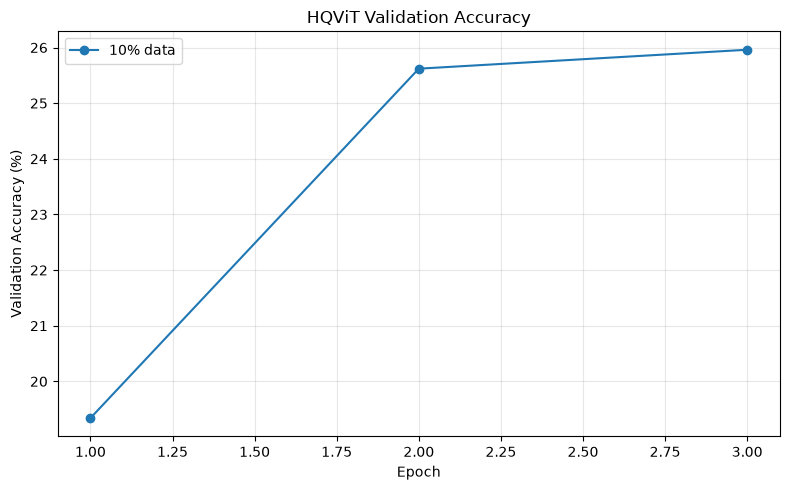

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

for fraction in DATA_FRACTIONS:

    percentage = int(fraction * 100)
    history_path = RESULTS_DIR / f"hqvit_history_{percentage}pct.csv"

    if not history_path.exists():
        continue

    history = pd.read_csv(history_path)

    plt.plot(
        history["epoch"],
        history["validation_accuracy"] * 100,
        marker="o",
        label=f"{percentage}% data"
    )

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy (%)")
plt.title("HQViT Validation Accuracy")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "hqvit_learning_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Section 35: Hybrid Quantum-Classical Vision Transformer Architecture

### Objective
Develop a genuine Hybrid Quantum-Classical Vision Transformer (HQViT)
by integrating a parameterized quantum circuit into a classical Vision
Transformer architecture.

### Architecture
1. Patch embedding: Convert CIFAR-10 images into patch embeddings.
2. Transformer encoder: Learn contextual representations between patches.
3. Quantum projection: Reduce the transformer representation to four
   quantum input features.
4. Quantum circuit: Process the features using a parameterized four-qubit
   variational quantum circuit.
5. Classification head: Map the quantum outputs to ten CIFAR-10 classes.

### Research objective
Investigate whether integrating a quantum circuit into a Vision Transformer
affects classification accuracy, generalisation, and training efficiency
under different training-data budgets.

The hybrid model will be evaluated against the existing classical CNN
and classical ViT baselines.

In [ ]:
import torch
import torch.nn as nn
import pennylane as qml

print("PyTorch:", torch.__version__)
print("PennyLane:", qml.__version__)
print("Device:", DEVICE)

assert "ClassicalViT" in globals(), (
    "ClassicalViT is not defined. Run the earlier ViT definition cell."
)

assert "quantum_circuit" in globals(), (
    "quantum_circuit is not defined. Run the earlier quantum circuit cell."
)

assert "N_QUBITS" in globals(), "N_QUBITS is not defined."
assert "N_Q_LAYERS" in globals(), "N_Q_LAYERS is not defined."

print("\nRequired components are available.")
print("We can now build the integrated HQViT.")

PyTorch: 2.14.1+cu130
PennyLane: 0.45.1
Device: cpu

Required components are available.
We can now build the integrated HQViT.


## Section 36: Implement the Hybrid Quantum-Classical Vision Transformer

The model uses a Vision Transformer to extract contextual image
representations. Its class-token representation is projected into four
features, which are encoded into a four-qubit quantum circuit.

The expectation values measured from the quantum circuit are passed
through a classical classification head to predict one of ten classes.

The transformer and classical layers are trained jointly with the
variational quantum circuit parameters using backpropagation.

The model will use the existing quantum circuit and CIFAR-10 setup.

In [ ]:
class HybridQuantumViT(nn.Module):
    """
    Vision Transformer with a variational quantum classification component.

    Uses the existing quantum_circuit, N_QUBITS, and N_Q_LAYERS.
    """

    def __init__(self, num_classes=10):
        super().__init__()

        # Classical ViT backbone
        self.vit = ClassicalViT(num_classes=num_classes)

        # Access the ViT's transformer representation.
        # This implementation assumes the ViT exposes:
        # patch_embed, cls_token, pos_embed, transformer, and norm.
        required = [
            "patch_embed",
            "cls_token",
            "pos_embed",
            "transformer",
            "norm",
        ]

        missing = [
            name for name in required
            if not hasattr(self.vit, name)
        ]

        if missing:
            raise AttributeError(
                "The existing ClassicalViT does not expose these "
                f"components: {missing}. Inspect its definition before "
                "adapting the integration."
            )

        # Determine transformer embedding dimension from class token.
        embed_dim = self.vit.cls_token.shape[-1]

        # Project the class-token representation to quantum input features.
        self.quantum_projection = nn.Sequential(
            nn.Linear(embed_dim, N_QUBITS),
            nn.Tanh()
        )

        # Trainable variational quantum circuit parameters.
        self.quantum_weights = nn.Parameter(
            0.01 * torch.randn(N_Q_LAYERS, N_QUBITS, 2)
        )

        # Classification head uses measured quantum expectation values.
        self.classifier = nn.Sequential(
            nn.Linear(N_QUBITS, 32),
            nn.GELU(),
            nn.Dropout(0.1),
            nn.Linear(32, num_classes)
        )

    def forward(self, images):
        # Patch embedding
        tokens = self.vit.patch_embed(images)

        # Support either [batch, tokens, embedding] or
        # [batch, embedding, height, width] patch embeddings.
        if tokens.ndim == 4:
            tokens = tokens.flatten(2).transpose(1, 2)

        batch_size = tokens.shape[0]

        # Add class token and positional embeddings.
        cls_tokens = self.vit.cls_token.expand(batch_size, -1, -1)
        tokens = torch.cat([cls_tokens, tokens], dim=1)

        tokens = tokens + self.vit.pos_embed[:, :tokens.shape[1], :]

        # Transformer encoder
        tokens = self.vit.transformer(tokens)

        # Class-token representation
        representation = self.vit.norm(tokens[:, 0])

        # Map to the quantum circuit's input dimension.
        quantum_inputs = torch.pi * self.quantum_projection(representation)

        # Process each sample through the quantum circuit.
        quantum_outputs = []

        for sample in quantum_inputs:
            output = quantum_circuit(sample, self.quantum_weights)
            quantum_outputs.append(output)

        quantum_outputs = torch.stack(quantum_outputs).to(
            device=images.device,
            dtype=images.dtype
        )

        return self.classifier(quantum_outputs)


print("HybridQuantumViT class defined.")

HybridQuantumViT class defined.


## Section 37: Inspect ViT Components

Before testing the integrated HQViT, inspect the existing Vision
Transformer's layers and parameter shapes.

This verifies whether the new model can reuse its patch embedding,
class token, positional embeddings, transformer encoder, and normalization
layers without modifying the established baseline.

In [ ]:
vit_inspection = ClassicalViT()

print(vit_inspection)
print("\nTop-level component names:")

for name, module in vit_inspection.named_children():
    print(f"- {name}: {type(module).__name__}")

print("\nRelevant attributes:")

for name in [
    "patch_embed",
    "cls_token",
    "pos_embed",
    "transformer",
    "norm",
    "head",
    "classifier",
]:
    if hasattr(vit_inspection, name):
        value = getattr(vit_inspection, name)

        if isinstance(value, torch.Tensor):
            print(f"{name}: tensor shape {tuple(value.shape)}")
        else:
            print(f"{name}: {type(value).__name__}")
    else:
        print(f"{name}: not present")

ClassicalViT(
  (patch_embedding): Conv2d(3, 128, kernel_size=(4, 4), stride=(4, 4))
  (embedding_dropout): Dropout(p=0.1, inplace=False)
  (transformer): TransformerEncoder(
    (layers): ModuleList(
      (0-3): 4 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=128, out_features=128, bias=True)
        )
        (linear1): Linear(in_features=128, out_features=256, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=256, out_features=128, bias=True)
        (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
        (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
    (norm): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
  )
  (classifier): Sequential(
    (0): LayerNorm((128,),

/tmp/ipykernel_6476/167982418.py:56: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


## Section 38: HQViT Compatibility and Smoke Test

### Objective
Verify that the integrated Hybrid Quantum-Classical Vision Transformer
can perform a forward pass and propagate gradients through its classical
and quantum components.

### Tests
1. Instantiate the model.
2. Pass a small batch of CIFAR-10 images through it.
3. Verify that the output has ten class logits per image.
4. Check that the loss is finite.
5. Confirm that gradients reach the transformer, quantum parameters,
   quantum projection, and classifier.

Training on the full dataset will only begin after these tests pass.

In [ ]:
import torch
import torch.nn as nn
import pennylane as qml


class HybridQuantumViT(nn.Module):
    """
    Hybrid Quantum-Classical Vision Transformer.

    Reuses the existing ClassicalViT patch embedding, class token,
    positional embedding, transformer encoder, and final normalization.
    Replaces the original classical classification head with a quantum
    circuit and a new classical classification head.
    """

    def __init__(self, num_classes=10):
        super().__init__()

        self.vit = ClassicalViT(num_classes=num_classes)

        # Project the ViT class-token embedding to N_QUBITS features.
        self.quantum_projection = nn.Sequential(
            nn.Linear(128, N_QUBITS),
            nn.Tanh()
        )

        # Trainable variational quantum circuit parameters.
        self.quantum_weights = nn.Parameter(
            0.01 * torch.randn(
                N_Q_LAYERS,
                N_QUBITS,
                2
            )
        )

        # Classical classifier operating on quantum measurements.
        self.classifier = nn.Sequential(
            nn.Linear(N_QUBITS, 32),
            nn.GELU(),
            nn.Dropout(0.1),
            nn.Linear(32, num_classes)
        )

    def forward(self, images):
        # Patch embedding:
        # [batch, channels, height, width]
        # -> [batch, embedding_dim, patch_height, patch_width]
        tokens = self.vit.patch_embedding(images)

        # Convert spatial patches into a token sequence.
        tokens = tokens.flatten(2).transpose(1, 2)

        # Add class token.
        batch_size = tokens.shape[0]

        cls_tokens = self.vit.cls_token.expand(
            batch_size, -1, -1
        )

        tokens = torch.cat(
            [cls_tokens, tokens],
            dim=1
        )

        # Add positional embeddings.
        tokens = tokens + self.vit.pos_embedding[
            :, :tokens.shape[1], :
        ]

        tokens = self.vit.embedding_dropout(tokens)

        # Transformer contextual representation.
        tokens = self.vit.transformer(tokens)

        # Apply the Transformer's final normalization.
        tokens = self.vit.transformer.norm(tokens)

        # Extract the class-token representation.
        cls_representation = tokens[:, 0, :]

        # Project 128 features to the quantum input dimension.
        quantum_inputs = torch.pi * self.quantum_projection(
            cls_representation
        )

        # Process each image using the parameterized quantum circuit.
        quantum_outputs = []

        for sample in quantum_inputs:
            result = quantum_circuit(
                sample,
                self.quantum_weights
            )

            quantum_outputs.append(result)

        quantum_outputs = torch.stack(
            quantum_outputs,
            dim=0
        )

        quantum_outputs = quantum_outputs.to(
            device=images.device,
            dtype=images.dtype
        )

        return self.classifier(quantum_outputs)


print("Corrected HybridQuantumViT class defined.")

Corrected HybridQuantumViT class defined.


## Section 39: HQViT defination loader

In [ ]:
class HybridQuantumViT(nn.Module):
    """
    Hybrid Quantum-Classical Vision Transformer using the existing ViT
    backbone and parameterized quantum circuit.
    """

    def __init__(self, num_classes=10):
        super().__init__()

        self.vit = ClassicalViT(num_classes=num_classes)

        self.quantum_projection = nn.Sequential(
            nn.Linear(128, N_QUBITS),
            nn.Tanh()
        )

        self.quantum_weights = nn.Parameter(
            0.01 * torch.randn(
                N_Q_LAYERS,
                N_QUBITS,
                2
            )
        )

        self.classifier = nn.Sequential(
            nn.Linear(N_QUBITS, 32),
            nn.GELU(),
            nn.Dropout(0.1),
            nn.Linear(32, num_classes)
        )

    def forward(self, images):
        # Patch embedding
        tokens = self.vit.patch_embedding(images)
        tokens = tokens.flatten(2).transpose(1, 2)

        # Class token and positional embeddings
        batch_size = tokens.shape[0]

        cls_tokens = self.vit.cls_token.expand(
            batch_size, -1, -1
        )

        tokens = torch.cat([cls_tokens, tokens], dim=1)

        tokens = tokens + self.vit.pos_embedding[
            :, :tokens.shape[1], :
        ]

        tokens = self.vit.embedding_dropout(tokens)

        # Transformer encoder and normalization
        tokens = self.vit.transformer(tokens)
        tokens = self.vit.transformer.norm(tokens)

        # Class-token representation
        representation = tokens[:, 0, :]

        # Quantum input features
        quantum_inputs = torch.pi * self.quantum_projection(
            representation
        )

        quantum_outputs = []

        for sample in quantum_inputs:
            result = quantum_circuit(
                sample,
                self.quantum_weights
            )

            # PennyLane may return a list or tuple of measurement values.
            if isinstance(result, (list, tuple)):
                result = torch.stack([
                    value if isinstance(value, torch.Tensor)
                    else torch.as_tensor(
                        value,
                        device=sample.device,
                        dtype=sample.dtype
                    )
                    for value in result
                ])

            elif not isinstance(result, torch.Tensor):
                result = torch.as_tensor(
                    result,
                    device=sample.device,
                    dtype=sample.dtype
                )

            quantum_outputs.append(result.reshape(-1))

        quantum_outputs = torch.stack(quantum_outputs, dim=0)

        quantum_outputs = quantum_outputs.to(
            device=images.device,
            dtype=images.dtype
        )

        return self.classifier(quantum_outputs)


print("Corrected HybridQuantumViT definition loaded.")

Corrected HybridQuantumViT definition loaded.


Section 40: HQViT Forward and Backward Validation

Objective: Verify that the integrated Hybrid Quantum-Classical Vision Transformer produces valid predictions and supports gradient-based training.

The validation checks:

- Output shape for ten CIFAR-10 classes.
- Finite cross-entropy loss.
- Gradient flow through the transformer, quantum projection, quantum circuit parameters, and classification head.

Training will begin only after these checks pass.

In [ ]:
hqvit_model = HybridQuantumViT(num_classes=10).to(DEVICE)

images, labels = next(iter(validation_loader))
images = images[:2].to(DEVICE)
labels = labels[:2].to(DEVICE)

hqvit_model.train()
hqvit_model.zero_grad(set_to_none=True)

logits = hqvit_model(images)

assert logits.shape == (2, 10), (
    f"Unexpected output shape: {tuple(logits.shape)}"
)

loss = nn.CrossEntropyLoss()(logits, labels)

assert torch.isfinite(loss).item(), "Loss is not finite."

loss.backward()

gradient_checks = {
    "Transformer": next(
        hqvit_model.vit.transformer.parameters()
    ).grad,
    "Quantum projection": next(
        hqvit_model.quantum_projection.parameters()
    ).grad,
    "Quantum circuit": hqvit_model.quantum_weights.grad,
    "Classification head": next(
        hqvit_model.classifier.parameters()
    ).grad,
}

all_passed = True

print("Output shape:", tuple(logits.shape))
print("Test loss:", round(loss.item(), 4))

for name, grad in gradient_checks.items():
    passed = (
        grad is not None
        and torch.isfinite(grad).all().item()
        and grad.abs().sum().item() > 0
    )

    print(f"{name} gradient check: {passed}")
    all_passed = all_passed and passed

assert all_passed, "At least one gradient check failed."

print("\nHQViT validation passed.")

/tmp/ipykernel_6476/167982418.py:56: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


Output shape: (2, 10)
Test loss: 2.1523
Transformer gradient check: True
Quantum projection gradient check: True
Quantum circuit gradient check: True
Classification head gradient check: True

HQViT validation passed.


Section 41: Save the HQViT Initialization Checkpoint

Save the integrated model's initial parameters and configuration before training.

This checkpoint is for recovery and reproducibility. It is not a trained model and must not be used as a final performance result.

In [ ]:
import os
import json

os.makedirs("models", exist_ok=True)
os.makedirs("results", exist_ok=True)

checkpoint_path = "models/hqvit_integrated_initial.pt"
config_path = "results/hqvit_integrated_config.json"

torch.save(
    {
        "model_state_dict": hqvit_model.state_dict(),
        "architecture": "HybridQuantumViT",
        "num_classes": 10,
        "embedding_dim": 128,
        "transformer_layers": 4,
        "num_qubits": N_QUBITS,
        "num_quantum_layers": N_Q_LAYERS,
        "status": "initialized_not_trained",
    },
    checkpoint_path,
)

config = {
    "architecture": "HybridQuantumViT",
    "dataset": "CIFAR-10",
    "num_classes": 10,
    "embedding_dim": 128,
    "transformer_layers": 4,
    "num_qubits": N_QUBITS,
    "num_quantum_layers": N_Q_LAYERS,
    "training_fractions": DATA_FRACTIONS,
    "status": "initialized_not_trained",
}

with open(config_path, "w") as f:
    json.dump(config, f, indent=4)

print("Initial checkpoint saved:", checkpoint_path)
print("Configuration saved:", config_path)

Initial checkpoint saved: models/hqvit_integrated_initial.pt
Configuration saved: results/hqvit_integrated_config.json


Section 42: Configure HQViT Data-Efficiency Experiment

Objective: Prepare the first integrated HQViT training experiment using 10% of the CIFAR-10 training pool.

The experiment uses:

- Training fraction: 10% (4,500 images).
- Epochs: 3.
- Optimizer: Adam.
- Learning rate: 0.001.
- Loss function: Cross-entropy.
- Validation: The existing 5,000-image validation set.

Training history and model checkpoints will be saved to disk for reproducibility.

In [ ]:
from torch.utils.data import DataLoader, Subset
import time
import pandas as pd

HQVIT_FRACTION = 0.10
HQVIT_EPOCHS = 3
HQVIT_BATCH_SIZE = 16
HQVIT_LR = 0.001

hqvit_train_subset = train_subsets[HQVIT_FRACTION]

hqvit_train_loader = DataLoader(
    hqvit_train_subset,
    batch_size=HQVIT_BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
)

print("Training fraction:", f"{HQVIT_FRACTION:.0%}")
print("Training images:", len(hqvit_train_subset))
print("Batch size:", HQVIT_BATCH_SIZE)
print("Epochs:", HQVIT_EPOCHS)
print("Learning rate:", HQVIT_LR)
print("Training batches per epoch:", len(hqvit_train_loader))

Training fraction: 10%
Training images: 4500
Batch size: 16
Epochs: 3
Learning rate: 0.001
Training batches per epoch: 282


Section 43: Train Integrated HQViT on 10% of CIFAR-10

Train the integrated hybrid quantum-classical Vision Transformer for three epochs.

At the end of each epoch, record training loss, training accuracy, validation loss, validation accuracy, and elapsed time.

Save the model checkpoint and experiment history after every epoch to reduce the risk of losing completed work.

In [ ]:
import os
import time
import pandas as pd
import torch
import torch.nn as nn

history_path = "results/hqvit_integrated_history_10pct.csv"
model_path = "models/hqvit_integrated_10pct.pt"

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    hqvit_model.parameters(),
    lr=HQVIT_LR,
)

history_rows = []

for epoch in range(1, HQVIT_EPOCHS + 1):
    epoch_start = time.time()

    # Training
    hqvit_model.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for batch_images, batch_labels in hqvit_train_loader:
        batch_images = batch_images.to(DEVICE)
        batch_labels = batch_labels.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)

        outputs = hqvit_model(batch_images)
        loss = criterion(outputs, batch_labels)

        loss.backward()
        optimizer.step()

        batch_size = batch_labels.size(0)

        train_loss_sum += loss.item() * batch_size
        train_correct += (
            outputs.argmax(dim=1) == batch_labels
        ).sum().item()
        train_total += batch_size

    train_loss = train_loss_sum / train_total
    train_accuracy = train_correct / train_total

    # Validation
    hqvit_model.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for batch_images, batch_labels in validation_loader:
            batch_images = batch_images.to(DEVICE)
            batch_labels = batch_labels.to(DEVICE)

            outputs = hqvit_model(batch_images)
            loss = criterion(outputs, batch_labels)

            batch_size = batch_labels.size(0)

            val_loss_sum += loss.item() * batch_size
            val_correct += (
                outputs.argmax(dim=1) == batch_labels
            ).sum().item()
            val_total += batch_size

    val_loss = val_loss_sum / val_total
    val_accuracy = val_correct / val_total
    epoch_seconds = time.time() - epoch_start

    row = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "validation_loss": val_loss,
        "validation_accuracy": val_accuracy,
        "epoch_seconds": epoch_seconds,
    }

    history_rows.append(row)

    pd.DataFrame(history_rows).to_csv(history_path, index=False)

    torch.save(
        {
            "epoch": epoch,
            "model_state_dict": hqvit_model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "history": history_rows,
            "fraction": HQVIT_FRACTION,
        },
        model_path,
    )

    print(
        f"Epoch {epoch}/{HQVIT_EPOCHS} | "
        f"Train acc: {train_accuracy:.4f} | "
        f"Val acc: {val_accuracy:.4f} | "
        f"Train loss: {train_loss:.4f} | "
        f"Val loss: {val_loss:.4f} | "
        f"Time: {epoch_seconds / 60:.2f} min"
    )

print("\nIntegrated HQViT training completed.")
print("History:", history_path)
print("Checkpoint:", model_path)

Epoch 1/3 | Train acc: 0.0922 | Val acc: 0.1024 | Train loss: 2.3094 | Val loss: 2.3036 | Time: 2.29 min
Epoch 2/3 | Train acc: 0.1038 | Val acc: 0.1002 | Train loss: 2.3049 | Val loss: 2.3051 | Time: 2.17 min
Epoch 3/3 | Train acc: 0.1013 | Val acc: 0.1026 | Train loss: 2.3046 | Val loss: 2.3037 | Time: 2.16 min

Integrated HQViT training completed.
History: results/hqvit_integrated_history_10pct.csv
Checkpoint: models/hqvit_integrated_10pct.pt


Section 44: Integrated HQViT Training Analysis

Objective

Analyse the integrated HQViT's learning behaviour using its saved training history.

The analysis examines:

- Training and validation accuracy across epochs.
- Training and validation loss.
- The generalisation gap.
- Whether the model improves beyond chance-level classification.

This analysis will help determine whether further training or architectural debugging is necessary before scaling the experiment.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

history_path = "results/hqvit_integrated_history_10pct.csv"

assert os.path.exists(history_path), (
    f"History file not found: {history_path}"
)

hqvit_history = pd.read_csv(history_path)

# Convert accuracy fractions to percentages for display.
hqvit_history["train_accuracy_pct"] = (
    hqvit_history["train_accuracy"] * 100
)

hqvit_history["validation_accuracy_pct"] = (
    hqvit_history["validation_accuracy"] * 100
)

hqvit_history["generalisation_gap_pct"] = (
    hqvit_history["train_accuracy"]
    - hqvit_history["validation_accuracy"]
) * 100

print("Integrated HQViT — 10% training data")
display(
    hqvit_history[
        [
            "epoch",
            "train_loss",
            "validation_loss",
            "train_accuracy_pct",
            "validation_accuracy_pct",
            "generalisation_gap_pct",
            "epoch_seconds",
        ]
    ].round(4)
)

print("\nFinal training accuracy:",
      f"{hqvit_history['train_accuracy_pct'].iloc[-1]:.2f}%")

print("Final validation accuracy:",
      f"{hqvit_history['validation_accuracy_pct'].iloc[-1]:.2f}%")

print("Chance-level accuracy for 10 classes: 10%")

Integrated HQViT — 10% training data


,epoch,train_loss,validation_loss,train_accuracy_pct,validation_accuracy_pct,generalisation_gap_pct,epoch_seconds
0,1,2.3094,2.3036,9.2222,10.24,-1.0178,137.1071
1,2,2.3049,2.3051,10.3778,10.02,0.3578,130.4480
2,3,2.3046,2.3037,10.1333,10.26,-0.1267,129.6860



Final training accuracy: 10.13%
Final validation accuracy: 10.26%
Chance-level accuracy for 10 classes: 10%


Section 45: Integrated HQViT Learning Curves

Plot training and validation accuracy and loss over the three epochs.

These curves help distinguish between normal undertraining, overfitting, and a model that is not learning effectively.

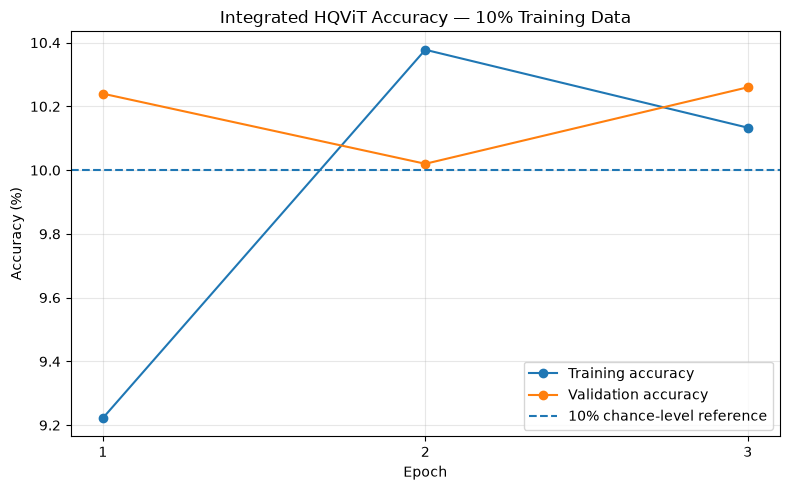

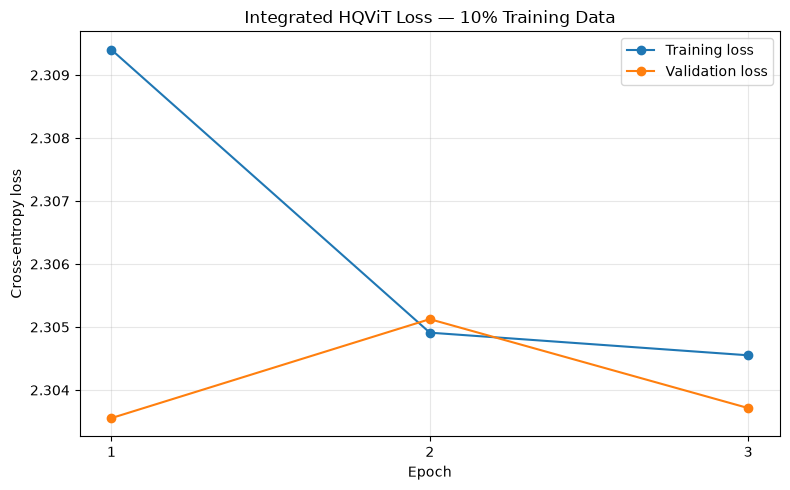

Learning curves saved in results/.


(None,)

In [ ]:
import matplotlib.pyplot as plt

epochs = hqvit_history["epoch"]

# Accuracy plot
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    hqvit_history["train_accuracy_pct"],
    marker="o",
    label="Training accuracy",
)

plt.plot(
    epochs,
    hqvit_history["validation_accuracy_pct"],
    marker="o",
    label="Validation accuracy",
)

plt.axhline(
    y=10,
    linestyle="--",
    label="10% chance-level reference",
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Integrated HQViT Accuracy — 10% Training Data")
plt.xticks(epochs)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

os.makedirs("results", exist_ok=True)
plt.savefig(
    "results/hqvit_integrated_accuracy_10pct.png",
    dpi=200,
)
plt.show()


# Loss plot
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    hqvit_history["train_loss"],
    marker="o",
    label="Training loss",
)

plt.plot(
    epochs,
    hqvit_history["validation_loss"],
    marker="o",
    label="Validation loss",
)

plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("Integrated HQViT Loss — 10% Training Data")
plt.xticks(epochs)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    "results/hqvit_integrated_loss_10pct.png",
    dpi=200,
)
plt.show()

print("Learning curves saved in results/."), 

Section 46: Integrated HQViT Training Diagnostics

The integrated Hybrid Quantum-Classical Vision Transformer achieved 10.13% training accuracy and 10.26% validation accuracy, approximately equal to random guessing for CIFAR-10's ten classes.

This diagnostic examines:

- Training and validation loss trends.
- Changes in model parameters during training.
- Prediction diversity and output-logit variation.
- Quantum feature variation across input images.
- The transformer's final normalization configuration.

These checks will help identify potential implementation or optimization issues before further experiments are conducted.

In [ ]:
# Section 46: Integrated HQViT Training Diagnostics

import os
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

print("=" * 70)
print("SECTION 46: INTEGRATED HQViT DIAGNOSTICS")
print("=" * 70)

# ---------------------------------------------------------
# 1. Inspect saved training history
# ---------------------------------------------------------
history_path = "results/hqvit_integrated_history_10pct.csv"

if os.path.exists(history_path):
    history_df = pd.read_csv(history_path)

    print("\n[1] TRAINING HISTORY")
    print(history_df.to_string(index=False))

    if len(history_df) > 1:
        first_loss = float(history_df.iloc[0]["train_loss"])
        last_loss = float(history_df.iloc[-1]["train_loss"])
        print(f"\nTraining-loss change: {first_loss:.4f} -> {last_loss:.4f}")
        print(f"Absolute loss reduction: {first_loss - last_loss:.6f}")
else:
    history_df = None
    print("\n[1] Training-history CSV not found.")

# ---------------------------------------------------------
# 2. Load initial and trained checkpoints
# ---------------------------------------------------------
initial_path = "models/hqvit_integrated_initial.pt"
trained_path = "models/hqvit_integrated_10pct.pt"

print("\n[2] CHECKPOINT COMPARISON")

initial_checkpoint = None
trained_checkpoint = None

if os.path.exists(initial_path):
    initial_checkpoint = torch.load(
        initial_path,
        map_location=DEVICE,
        weights_only=False
    )
    print("Initial checkpoint loaded.")
else:
    print(f"Initial checkpoint missing: {initial_path}")

if os.path.exists(trained_path):
    trained_checkpoint = torch.load(
        trained_path,
        map_location=DEVICE,
        weights_only=False
    )
    print("Trained checkpoint loaded.")
else:
    print(f"Trained checkpoint missing: {trained_path}")

if trained_checkpoint is not None:
    trained_state = trained_checkpoint.get(
        "model_state_dict",
        trained_checkpoint.get("state_dict")
    )

    if trained_state is not None:
        hqvit_model.load_state_dict(trained_state)
        print("Trained weights loaded into hqvit_model.")
    else:
        print("Could not identify the trained state dictionary.")

if initial_checkpoint is not None and trained_checkpoint is not None:
    initial_state = initial_checkpoint.get(
        "model_state_dict",
        initial_checkpoint.get("state_dict")
    )

    if initial_state is not None and trained_state is not None:
        shared_keys = [
            key for key in initial_state
            if key in trained_state
            and isinstance(initial_state[key], torch.Tensor)
            and isinstance(trained_state[key], torch.Tensor)
        ]

        if shared_keys:
            groups = {
                "Transformer": lambda k: k.startswith("vit."),
                "Quantum projection": lambda k: k.startswith("quantum_projection."),
                "Quantum weights": lambda k: k.startswith("quantum_weights"),
                "Classifier": lambda k: k.startswith("classifier.")
            }

            for group_name, selector in groups.items():
                keys = [k for k in shared_keys if selector(k)]

                if not keys:
                    print(f"{group_name}: no matching parameters found.")
                    continue

                squared_change = 0.0
                squared_initial = 0.0

                for key in keys:
                    before = initial_state[key].float()
                    after = trained_state[key].float()

                    squared_change += torch.sum((after - before) ** 2).item()
                    squared_initial += torch.sum(before ** 2).item()

                change_norm = np.sqrt(squared_change)
                initial_norm = np.sqrt(squared_initial)

                print(
                    f"{group_name}: parameter-change norm = "
                    f"{change_norm:.6f}"
                )

                if initial_norm > 0:
                    print(
                        f"    Relative change = "
                        f"{change_norm / initial_norm:.6%}"
                    )

# ---------------------------------------------------------
# 3. Check prediction distribution and output-logit variation
# ---------------------------------------------------------
print("\n[3] PREDICTION DIAGNOSTICS")

hqvit_model.eval()

images, labels = next(iter(validation_loader))
images = images[:64].to(DEVICE)
labels = labels[:64].to(DEVICE)

with torch.no_grad():
    logits = hqvit_model(images)
    probabilities = torch.softmax(logits, dim=1)
    predictions = logits.argmax(dim=1)

prediction_counts = torch.bincount(
    predictions.cpu(),
    minlength=10
)

print("Prediction counts by class:", prediction_counts.tolist())
print("Number of predicted classes:", int((prediction_counts > 0).sum()))
print("Logit mean:", logits.mean().item())
print("Logit standard deviation:", logits.std().item())
print("Mean probability assigned to predicted class:",
      probabilities.max(dim=1).values.mean().item())
print("Accuracy on this diagnostic batch:",
      (predictions == labels).float().mean().item())

# ---------------------------------------------------------
# 4. Inspect quantum feature variability and gradients
# ---------------------------------------------------------
print("\n[4] QUANTUM FEATURE DIAGNOSTICS")

with torch.no_grad():
    tokens = hqvit_model.vit.patch_embedding(images)
    tokens = tokens.flatten(2).transpose(1, 2)

    cls_tokens = hqvit_model.vit.cls_token.expand(
        tokens.shape[0], -1, -1
    )

    tokens = torch.cat([cls_tokens, tokens], dim=1)
    tokens = tokens + hqvit_model.vit.pos_embedding[:, :tokens.shape[1], :]
    tokens = hqvit_model.vit.embedding_dropout(tokens)

    # TransformerEncoder applies its configured final norm internally.
    tokens = hqvit_model.vit.transformer(tokens)

    representations = tokens[:, 0, :]
    quantum_inputs = torch.pi * hqvit_model.quantum_projection(
        representations
    )

    print("Transformer representation std:",
          representations.std().item())
    print("Quantum input std:", quantum_inputs.std().item())

    quantum_outputs = []

    # Use a small sample to limit diagnostic runtime.
    for sample in quantum_inputs[:8]:
        result = quantum_circuit(sample, hqvit_model.quantum_weights)

        if isinstance(result, (list, tuple)):
            result = torch.stack([
                value if isinstance(value, torch.Tensor)
                else torch.as_tensor(
                    value, device=sample.device, dtype=sample.dtype
                )
                for value in result
            ])
        elif not isinstance(result, torch.Tensor):
            result = torch.as_tensor(
                result, device=sample.device, dtype=sample.dtype
            )

        quantum_outputs.append(result.reshape(-1))

    quantum_outputs = torch.stack(quantum_outputs)

    print("Quantum output shape:", tuple(quantum_outputs.shape))
    print("Quantum output std:", quantum_outputs.std().item())
    print("Quantum output range:",
          quantum_outputs.min().item(),
          "to",
          quantum_outputs.max().item())

# ---------------------------------------------------------
# 5. Check transformer normalization configuration
# ---------------------------------------------------------
print("\n[5] TRANSFORMER NORMALIZATION")

transformer_norm = getattr(
    hqvit_model.vit.transformer, "norm", None
)

print("Transformer final norm:", transformer_norm)

if transformer_norm is not None:
    print(
        "The TransformerEncoder applies its configured final "
        "normalization internally during forward()."
    )
    print(
        "The integrated model should not apply transformer.norm "
        "a second time after calling transformer(tokens)."
    )

# ---------------------------------------------------------
# 6. Diagnostic summary
# ---------------------------------------------------------
print("\n[6] AUTOMATED FLAGS")

if logits.std().item() < 1e-4:
    print("WARNING: Output logits are nearly constant.")
else:
    print("Output logits show variation across the batch.")

if int((prediction_counts > 0).sum()) <= 2:
    print("WARNING: Predictions cover very few classes.")
else:
    print("Predictions cover multiple classes.")

if quantum_outputs.std().item() < 1e-4:
    print("WARNING: Quantum outputs show very little variation.")
else:
    print("Quantum outputs vary across the sampled images.")

print("\nDiagnostics complete.")
print("No additional training was performed.")

SECTION 46: INTEGRATED HQViT DIAGNOSTICS

[1] TRAINING HISTORY
 epoch  train_loss  train_accuracy  validation_loss  validation_accuracy  epoch_seconds
     1    2.309401        0.092222         2.303555               0.1024     137.107053
     2    2.304911        0.103778         2.305125               0.1002     130.447997
     3    2.304551        0.101333         2.303714               0.1026     129.685986

Training-loss change: 2.3094 -> 2.3046
Absolute loss reduction: 0.004849

[2] CHECKPOINT COMPARISON
Initial checkpoint loaded.
Trained checkpoint loaded.
Trained weights loaded into hqvit_model.
Transformer: parameter-change norm = 13.284547
    Relative change = 25.205754%
Quantum projection: parameter-change norm = 0.345383
    Relative change = 30.890556%
Quantum weights: parameter-change norm = 0.109321
    Relative change = 312.083137%
Classifier: parameter-change norm = 0.650326
    Relative change = 16.672504%

[3] PREDICTION DIAGNOSTICS
Prediction counts by class: [0, 0

Section 47: Correct Transformer Normalization and Verify Gradient Flow

The previous diagnostic identified two issues requiring further investigation: the integrated HQViT predicts a single class for the entire diagnostic batch, and the transformer's final normalization layer is applied twice.

This section corrects the redundant normalization in the model's forward pass. It then verifies that the corrected model produces finite outputs and meaningful gradients through the transformer, quantum projection, quantum circuit parameters, and classifier.

The existing trained checkpoint is retained for reference. This is a diagnostic correction, not evidence that the model has been fixed or that its accuracy will improve.

In [ ]:
# Section 47: Correct Transformer Normalization and Verify Gradients

import torch
import torch.nn as nn
import copy

# ---------------------------------------------------------
# 1. Inspect the current HybridQuantumViT forward method
# ---------------------------------------------------------
print("Inspecting the current HybridQuantumViT implementation...")

# Keep a copy of the current trained model for reference.
hqvit_pre_norm_fix = copy.deepcopy(hqvit_model)

# ---------------------------------------------------------
# 2. Define a corrected forward method
# ---------------------------------------------------------
def corrected_hqvit_forward(self, images):
    # Patch embeddings
    tokens = self.vit.patch_embedding(images)
    tokens = tokens.flatten(2).transpose(1, 2)

    # Class token and positional embeddings
    cls_tokens = self.vit.cls_token.expand(
        tokens.shape[0], -1, -1
    )
    tokens = torch.cat([cls_tokens, tokens], dim=1)
    tokens = tokens + self.vit.pos_embedding[:, :tokens.shape[1], :]
    tokens = self.vit.embedding_dropout(tokens)

    # TransformerEncoder already applies its configured final norm.
    # Do NOT call self.vit.transformer.norm(tokens) again.
    tokens = self.vit.transformer(tokens)

    # Extract CLS-token representation
    representation = tokens[:, 0, :]

    # Project into quantum circuit input range
    quantum_inputs = torch.pi * self.quantum_projection(representation)

    # Evaluate the quantum circuit for each sample
    quantum_outputs = []

    for sample in quantum_inputs:
        result = quantum_circuit(sample, self.quantum_weights)

        if isinstance(result, (list, tuple)):
            result = torch.stack([
                value if isinstance(value, torch.Tensor)
                else torch.as_tensor(
                    value,
                    device=sample.device,
                    dtype=sample.dtype
                )
                for value in result
            ])
        elif not isinstance(result, torch.Tensor):
            result = torch.as_tensor(
                result,
                device=sample.device,
                dtype=sample.dtype
            )

        quantum_outputs.append(result.reshape(-1))

    quantum_outputs = torch.stack(quantum_outputs, dim=0)
    quantum_outputs = quantum_outputs.to(
        device=images.device,
        dtype=images.dtype
    )

    return self.classifier(quantum_outputs)


# Replace the forward method for this notebook session.
# This does not alter the HybridQuantumViT class definition on disk.
import types

hqvit_model.forward = types.MethodType(
    corrected_hqvit_forward,
    hqvit_model
)

print("Corrected forward method installed for the current model instance.")

# ---------------------------------------------------------
# 3. Run a small forward/backward test
# ---------------------------------------------------------
hqvit_model.train()
hqvit_model.zero_grad(set_to_none=True)

images, labels = next(iter(validation_loader))
images = images[:4].to(DEVICE)
labels = labels[:4].to(DEVICE)

logits = hqvit_model(images)
loss = nn.CrossEntropyLoss()(logits, labels)
loss.backward()

print("\nFORWARD/BACKWARD TEST")
print("Logits shape:", tuple(logits.shape))
print("Loss:", round(loss.item(), 6))
print("All logits finite:", bool(torch.isfinite(logits).all()))
print("Loss finite:", bool(torch.isfinite(loss)))

# ---------------------------------------------------------
# 4. Inspect gradient magnitudes
# ---------------------------------------------------------
print("\nGRADIENT DIAGNOSTICS")

parameter_groups = {
    "Transformer": list(hqvit_model.vit.parameters()),
    "Quantum projection": list(hqvit_model.quantum_projection.parameters()),
    "Quantum weights": [hqvit_model.quantum_weights],
    "Classifier": list(hqvit_model.classifier.parameters())
}

for group_name, parameters in parameter_groups.items():
    gradients = [
        parameter.grad.detach()
        for parameter in parameters
        if parameter.grad is not None
    ]

    if not gradients:
        print(f"{group_name}: NO GRADIENTS")
        continue

    all_finite = all(
        bool(torch.isfinite(gradient).all())
        for gradient in gradients
    )

    total_norm = torch.sqrt(
        sum(torch.sum(gradient.float() ** 2) for gradient in gradients)
    ).item()

    print(
        f"{group_name}: gradient norm={total_norm:.8f}, "
        f"finite={all_finite}"
    )

# ---------------------------------------------------------
# 5. Inspect class predictions after the correction
# ---------------------------------------------------------
hqvit_model.eval()

with torch.no_grad():
    logits = hqvit_model(images)
    predictions = logits.argmax(dim=1)
    prediction_counts = torch.bincount(
        predictions.cpu(),
        minlength=10
    )

print("\nPREDICTION CHECK")
print("Predictions:", predictions.cpu().tolist())
print("Class counts:", prediction_counts.tolist())
print("Number of predicted classes:",
      int((prediction_counts > 0).sum()))

print("\nSection 47 complete.")
print("No optimizer step or model training was performed.")

Inspecting the current HybridQuantumViT implementation...
Corrected forward method installed for the current model instance.

FORWARD/BACKWARD TEST
Logits shape: (4, 10)
Loss: 2.336519
All logits finite: True
Loss finite: True

GRADIENT DIAGNOSTICS
Transformer: gradient norm=0.00018850, finite=True
Quantum projection: gradient norm=0.00057364, finite=True
Quantum weights: gradient norm=0.00330000, finite=True
Classifier: gradient norm=0.84557068, finite=True

PREDICTION CHECK
Predictions: [5, 5, 5, 5]
Class counts: [0, 0, 0, 0, 0, 4, 0, 0, 0, 0]
Number of predicted classes: 1

Section 47 complete.
No optimizer step or model training was performed.


Section 48: Investigating Class Collapse and Gradient Imbalance

The integrated HQViT currently predicts a single class despite producing finite logits and gradients. This section investigates whether the observed behaviour is associated with classifier bias, weak gradients in earlier layers, or insufficient variation in the representations supplied to the classification head.

The results will guide the next model modification. No additional training will be performed in this section.

In [ ]:
# Section 48: Investigate Class Collapse and Gradient Flow

import torch
import torch.nn as nn
import numpy as np

hqvit_model.eval()

# ---------------------------------------------------------
# 1. Collect a larger validation batch
# ---------------------------------------------------------
images, labels = next(iter(validation_loader))
images = images[:32].to(DEVICE)
labels = labels[:32].to(DEVICE)

with torch.no_grad():
    logits = hqvit_model(images)
    probabilities = torch.softmax(logits, dim=1)
    predictions = logits.argmax(dim=1)

print("=" * 65)
print("SECTION 48: CLASS COLLAPSE INVESTIGATION")
print("=" * 65)

print("\n[1] VALIDATION BATCH")
print("True-label counts:", torch.bincount(
    labels.cpu(), minlength=10
).tolist())

print("Predicted-label counts:", torch.bincount(
    predictions.cpu(), minlength=10
).tolist())

print("Batch accuracy:",
      (predictions == labels).float().mean().item())

print("Mean probability per class:",
      probabilities.mean(dim=0).cpu().numpy().round(4).tolist())

print("Mean maximum probability:",
      probabilities.max(dim=1).values.mean().item())

# ---------------------------------------------------------
# 2. Inspect classifier bias and weight magnitudes
# ---------------------------------------------------------
print("\n[2] CLASSIFIER PARAMETERS")

for name, parameter in hqvit_model.classifier.named_parameters():
    print(
        f"{name}: "
        f"mean={parameter.detach().mean().item():.6f}, "
        f"std={parameter.detach().std().item():.6f}, "
        f"norm={parameter.detach().norm().item():.6f}"
    )

# ---------------------------------------------------------
# 3. Compare gradient norms with parameter norms
# ---------------------------------------------------------
print("\n[3] RELATIVE GRADIENT MAGNITUDES")

hqvit_model.train()
hqvit_model.zero_grad(set_to_none=True)

# Use a small batch to keep the quantum computation manageable.
test_images = images[:4]
test_labels = labels[:4]

test_logits = hqvit_model(test_images)
test_loss = nn.CrossEntropyLoss()(test_logits, test_labels)
test_loss.backward()

groups = {
    "Transformer": list(hqvit_model.vit.parameters()),
    "Quantum projection": list(hqvit_model.quantum_projection.parameters()),
    "Quantum weights": [hqvit_model.quantum_weights],
    "Classifier": list(hqvit_model.classifier.parameters())
}

for group_name, parameters in groups.items():
    grad_sq = 0.0
    param_sq = 0.0
    grad_count = 0

    for parameter in parameters:
        param_sq += parameter.detach().float().pow(2).sum().item()

        if parameter.grad is not None:
            grad_sq += parameter.grad.detach().float().pow(2).sum().item()
            grad_count += 1

    grad_norm = np.sqrt(grad_sq)
    param_norm = np.sqrt(param_sq)
    relative_grad = grad_norm / max(param_norm, 1e-12)

    print(
        f"{group_name}: gradient norm={grad_norm:.8f}, "
        f"parameter norm={param_norm:.6f}, "
        f"relative gradient={relative_grad:.8e}, "
        f"parameters with gradients={grad_count}/{len(parameters)}"
    )

# ---------------------------------------------------------
# 4. Check classifier input diversity
# ---------------------------------------------------------
print("\n[4] QUANTUM FEATURE DIVERSITY")

hqvit_model.eval()

with torch.no_grad():
    tokens = hqvit_model.vit.patch_embedding(images)
    tokens = tokens.flatten(2).transpose(1, 2)

    cls_tokens = hqvit_model.vit.cls_token.expand(
        tokens.shape[0], -1, -1
    )

    tokens = torch.cat([cls_tokens, tokens], dim=1)
    tokens = tokens + hqvit_model.vit.pos_embedding[:, :tokens.shape[1], :]
    tokens = hqvit_model.vit.embedding_dropout(tokens)
    tokens = hqvit_model.vit.transformer(tokens)

    representation = tokens[:, 0, :]
    quantum_inputs = torch.pi * hqvit_model.quantum_projection(
        representation
    )

    quantum_outputs = []

    for sample in quantum_inputs:
        result = quantum_circuit(sample, hqvit_model.quantum_weights)

        if isinstance(result, (list, tuple)):
            result = torch.stack([
                value if isinstance(value, torch.Tensor)
                else torch.as_tensor(
                    value, device=sample.device, dtype=sample.dtype
                )
                for value in result
            ])
        elif not isinstance(result, torch.Tensor):
            result = torch.as_tensor(
                result, device=sample.device, dtype=sample.dtype
            )

        quantum_outputs.append(result.reshape(-1))

    quantum_outputs = torch.stack(quantum_outputs)

    print("Transformer representation std:",
          representation.std().item())

    print("Quantum input std:",
          quantum_inputs.std().item())

    print("Quantum features per-dimension std:",
          quantum_outputs.std(dim=0).cpu().numpy().round(5).tolist())

    print("Quantum feature matrix rank:",
          int(torch.linalg.matrix_rank(quantum_outputs).item()))

print("\nSection 48 complete. No optimizer step was performed.")

SECTION 48: CLASS COLLAPSE INVESTIGATION

[1] VALIDATION BATCH
True-label counts: [2, 3, 2, 1, 1, 4, 4, 3, 5, 7]
Predicted-label counts: [0, 0, 0, 0, 0, 32, 0, 0, 0, 0]
Batch accuracy: 0.125
Mean probability per class: [0.10000000149011612, 0.10119999945163727, 0.09730000048875809, 0.10360000282526016, 0.09910000115633011, 0.11089999973773956, 0.10409999638795853, 0.09749999642372131, 0.09120000153779984, 0.09510000050067902]
Mean maximum probability: 0.11088382452726364

[2] CLASSIFIER PARAMETERS
0.weight: mean=-0.005314, std=0.270464, norm=3.048568
0.bias: mean=0.083988, std=0.240505, norm=1.420864
3.weight: mean=-0.012799, std=0.098458, norm=1.773358
3.bias: mean=-0.011463, std=0.100687, norm=0.304230

[3] RELATIVE GRADIENT MAGNITUDES
Transformer: gradient norm=0.00046024, parameter norm=54.185170, relative gradient=8.49375842e-06, parameters with gradients=54/58
Quantum projection: gradient norm=0.00063318, parameter norm=1.175478, relative gradient=5.38658330e-04, parameters with 

Section 49: Quantum Circuit Sensitivity and Expressivity Analysis

The previous diagnostics showed that three of the four quantum expectation-value features have extremely low variation across the validation samples.

This section evaluates the sensitivity of the quantum circuit to its input features and trainable parameters. It examines output variation, input perturbation sensitivity, and the gradients of quantum outputs with respect to the circuit inputs and weights.

The objective is to determine whether the quantum layer is transmitting useful variation from the transformer representation to the classification head. These measurements are diagnostic and do not, by themselves, establish that the circuit is defective.

In [ ]:
# Section 49: Quantum Circuit Sensitivity and Expressivity Analysis

import torch
import numpy as np

print("=" * 70)
print("SECTION 49: QUANTUM CIRCUIT SENSITIVITY")
print("=" * 70)

hqvit_model.eval()

# ---------------------------------------------------------
# 1. Obtain transformer representations and quantum inputs
# ---------------------------------------------------------
images, labels = next(iter(validation_loader))
images = images[:16].to(DEVICE)

with torch.no_grad():
    tokens = hqvit_model.vit.patch_embedding(images)
    tokens = tokens.flatten(2).transpose(1, 2)

    cls_tokens = hqvit_model.vit.cls_token.expand(
        tokens.shape[0], -1, -1
    )

    tokens = torch.cat([cls_tokens, tokens], dim=1)
    tokens = tokens + hqvit_model.vit.pos_embedding[:, :tokens.shape[1], :]
    tokens = hqvit_model.vit.embedding_dropout(tokens)
    tokens = hqvit_model.vit.transformer(tokens)

    representations = tokens[:, 0, :]
    quantum_inputs = torch.pi * hqvit_model.quantum_projection(
        representations
    )

print("\n[1] INPUT STATISTICS")
print("Quantum input shape:", tuple(quantum_inputs.shape))
print("Per-dimension input std:",
      quantum_inputs.std(dim=0).cpu().numpy().round(5).tolist())

# ---------------------------------------------------------
# 2. Helper: normalize PennyLane output format
# ---------------------------------------------------------
def evaluate_quantum_output(sample, weights):
    result = quantum_circuit(sample, weights)

    if isinstance(result, (list, tuple)):
        result = torch.stack([
            value if isinstance(value, torch.Tensor)
            else torch.as_tensor(
                value, device=sample.device, dtype=sample.dtype
            )
            for value in result
        ])
    elif not isinstance(result, torch.Tensor):
        result = torch.as_tensor(
            result, device=sample.device, dtype=sample.dtype
        )

    return result.reshape(-1)

# ---------------------------------------------------------
# 3. Check output variation across images
# ---------------------------------------------------------
with torch.no_grad():
    quantum_outputs = torch.stack([
        evaluate_quantum_output(
            sample, hqvit_model.quantum_weights
        )
        for sample in quantum_inputs
    ])

print("\n[2] QUANTUM OUTPUT VARIATION")
print("Per-qubit output means:",
      quantum_outputs.mean(dim=0).cpu().numpy().round(5).tolist())
print("Per-qubit output std:",
      quantum_outputs.std(dim=0).cpu().numpy().round(7).tolist())
print("Per-qubit output ranges:")

for qubit_index in range(quantum_outputs.shape[1]):
    values = quantum_outputs[:, qubit_index]
    print(
        f"  Qubit {qubit_index + 1}: "
        f"min={values.min().item():.6f}, "
        f"max={values.max().item():.6f}"
    )

# ---------------------------------------------------------
# 4. Test sensitivity to each input dimension
# ---------------------------------------------------------
print("\n[3] INPUT PERTURBATION SENSITIVITY")

base_input = quantum_inputs[0].detach()
weights = hqvit_model.quantum_weights.detach()

with torch.no_grad():
    base_output = evaluate_quantum_output(base_input, weights)

    epsilon = 0.1

    for dimension in range(base_input.numel()):
        perturbed_input = base_input.clone()
        perturbed_input[dimension] += epsilon

        perturbed_output = evaluate_quantum_output(
            perturbed_input, weights
        )

        output_change = torch.norm(
            perturbed_output - base_output
        ).item()

        print(
            f"Input dimension {dimension + 1}: "
            f"output change after +{epsilon} perturbation = "
            f"{output_change:.8f}"
        )

# ---------------------------------------------------------
# 5. Compute gradients of quantum outputs
# ---------------------------------------------------------
print("\n[4] QUANTUM INPUT AND WEIGHT GRADIENTS")

sample = quantum_inputs[0].detach().clone().requires_grad_(True)
weights_for_grad = (
    hqvit_model.quantum_weights.detach().clone().requires_grad_(True)
)

output = evaluate_quantum_output(sample, weights_for_grad)

for output_index in range(output.numel()):
    input_grad, weight_grad = torch.autograd.grad(
        output[output_index],
        (sample, weights_for_grad),
        retain_graph=(output_index < output.numel() - 1),
        allow_unused=True
    )

    input_grad_norm = (
        input_grad.norm().item()
        if input_grad is not None else None
    )

    weight_grad_norm = (
        weight_grad.norm().item()
        if weight_grad is not None else None
    )

    print(
        f"Output {output_index + 1}: "
        f"input-gradient norm={input_grad_norm}, "
        f"weight-gradient norm={weight_grad_norm}"
    )

print("\nSection 49 complete. No training or optimizer update performed.")

SECTION 49: QUANTUM CIRCUIT SENSITIVITY

[1] INPUT STATISTICS
Quantum input shape: (16, 4)
Per-dimension input std: [0.00011000000085914508, 0.002570000011473894, 0.013129999861121178, 0.0004199999966658652]

[2] QUANTUM OUTPUT VARIATION
Per-qubit output means: [-0.99914, -0.99776, 0.99639, 0.99737]
Per-qubit output std: [4.5e-06, 7.91e-05, 0.0007628, 7.08e-05]
Per-qubit output ranges:
  Qubit 1: min=-0.999150, max=-0.999134
  Qubit 2: min=-0.997988, max=-0.997647
  Qubit 3: min=0.993608, max=0.996744
  Qubit 4: min=0.997265, max=0.997562

[3] INPUT PERTURBATION SENSITIVITY
Input dimension 1: output change after +0.1 perturbation = 0.01289394
Input dimension 2: output change after +0.1 perturbation = 0.00349172
Input dimension 3: output change after +0.1 perturbation = 0.00128114
Input dimension 4: output change after +0.1 perturbation = 0.00235956

[4] QUANTUM INPUT AND WEIGHT GRADIENTS
Output 1: input-gradient norm=0.04144606739282608, weight-gradient norm=0.04145454987883568
Output 

Section 50: Evaluating Quantum Input Encoding Strategies

The previous diagnostics revealed that the four-dimensional quantum input has very low variation across validation samples. The quantum circuit consequently produces expectation values concentrated near −1 and +1.

This section compares the current quantum input encoding with alternative scaling strategies using the same transformer representations and trained quantum parameters. The comparison measures input variation, output variation, and proximity to the extremes of the expectation-value range.

No model weights are updated. The purpose is to identify an input encoding that preserves more useful variation before conducting another training experiment.

In [ ]:
# Section 50: Compare Quantum Input Encoding Strategies

import torch
import numpy as np

hqvit_model.eval()

# ---------------------------------------------------------
# 1. Extract transformer representations
# ---------------------------------------------------------
images, labels = next(iter(validation_loader))
images = images[:32].to(DEVICE)

with torch.no_grad():
    tokens = hqvit_model.vit.patch_embedding(images)
    tokens = tokens.flatten(2).transpose(1, 2)

    cls_tokens = hqvit_model.vit.cls_token.expand(
        tokens.shape[0], -1, -1
    )

    tokens = torch.cat([cls_tokens, tokens], dim=1)
    tokens = tokens + hqvit_model.vit.pos_embedding[:, :tokens.shape[1], :]
    tokens = hqvit_model.vit.embedding_dropout(tokens)
    tokens = hqvit_model.vit.transformer(tokens)

    representations = tokens[:, 0, :]

    # Keep the existing learned projection fixed.
    projected = hqvit_model.quantum_projection(representations)

print("=" * 70)
print("SECTION 50: QUANTUM INPUT ENCODING COMPARISON")
print("=" * 70)

print("\nProjected representation statistics:")
print("Mean:", projected.mean().item())
print("Std:", projected.std().item())
print("Min:", projected.min().item())
print("Max:", projected.max().item())

# ---------------------------------------------------------
# 2. Define candidate encodings
# ---------------------------------------------------------
# These are diagnostic alternatives only.
# No parameters are updated.

encoding_candidates = {
    "Current: pi * projected": torch.pi * projected,
    "Reduced scale: 0.5 * projected": 0.5 * projected,
    "Unit scale: projected": projected,
    "Standardized per dimension": (
        (projected - projected.mean(dim=0, keepdim=True))
        / projected.std(dim=0, keepdim=True).clamp_min(1e-6)
    ) * 0.5
}

# ---------------------------------------------------------
# 3. Evaluate the circuit under each encoding
# ---------------------------------------------------------
def section50_quantum_output(sample):
    result = quantum_circuit(
        sample,
        hqvit_model.quantum_weights
    )

    if isinstance(result, (list, tuple)):
        result = torch.stack([
            value if isinstance(value, torch.Tensor)
            else torch.as_tensor(
                value, device=sample.device, dtype=sample.dtype
            )
            for value in result
        ])
    elif not isinstance(result, torch.Tensor):
        result = torch.as_tensor(
            result, device=sample.device, dtype=sample.dtype
        )

    return result.reshape(-1)


results = []

with torch.no_grad():
    for encoding_name, encoded_inputs in encoding_candidates.items():
        outputs = torch.stack([
            section50_quantum_output(sample)
            for sample in encoded_inputs
        ])

        input_std = encoded_inputs.std(dim=0).mean().item()
        output_std = outputs.std(dim=0).mean().item()

        # Pauli-Z expectations are theoretically in [-1, 1].
        saturation_fraction = (
            (outputs.abs() > 0.95).float().mean().item()
        )

        results.append({
            "encoding": encoding_name,
            "mean_input_std": input_std,
            "mean_output_std": output_std,
            "fraction_outputs_abs_gt_0.95": saturation_fraction,
            "minimum_output": outputs.min().item(),
            "maximum_output": outputs.max().item()
        })

comparison_df = __import__("pandas").DataFrame(results)

print("\nEncoding comparison:")
print(comparison_df.to_string(index=False, float_format=lambda x: f"{x:.6f}"))

# ---------------------------------------------------------
# 4. Save results
# ---------------------------------------------------------
import os

os.makedirs("results", exist_ok=True)

comparison_path = "results/hqvit_quantum_encoding_comparison.csv"
comparison_df.to_csv(comparison_path, index=False)

print(f"\nSaved comparison to: {comparison_path}")
print("\nSection 50 complete. No training or optimizer update performed.")

SECTION 50: QUANTUM INPUT ENCODING COMPARISON

Projected representation statistics:
Mean: 0.8734096884727478
Std: 0.47648605704307556
Min: -0.9996045231819153
Max: 0.9997851252555847

Encoding comparison:
                      encoding  mean_input_std  mean_output_std  fraction_outputs_abs_gt_0.95  minimum_output  maximum_output
       Current: pi * projected        1.514193         0.005475                      0.984375       -0.999156        0.998099
Reduced scale: 0.5 * projected        0.240991         0.009328                      0.000000        0.755488        0.897233
         Unit scale: projected        0.481983         0.013836                      0.000000        0.281015        0.577522
    Standardized per dimension        0.500000         0.268616                      0.937500       -0.358283        0.992748

Saved comparison to: results/hqvit_quantum_encoding_comparison.csv

Section 50 complete. No training or optimizer update performed.


Section 51: Validation Comparison of Quantum Input Scales

Section 50 showed that reducing the quantum input scale decreases output saturation and increases variation in the measured quantum features.

This section compares the current encoding with two alternative scales using the same trained model and validation samples. It records classification accuracy, cross-entropy loss, prediction diversity, and output saturation.

Because the model was trained using the original encoding, the alternative scales are being evaluated out of distribution. The comparison is diagnostic only; it does not establish which encoding will perform best after retraining.

In [ ]:
# Section 51: Compare Quantum Input Scales on Validation Data

import torch
import torch.nn as nn
import pandas as pd
import os

hqvit_model.eval()
criterion = nn.CrossEntropyLoss()

def hqvit_forward_with_scale(model, images, scale):
    tokens = model.vit.patch_embedding(images)
    tokens = tokens.flatten(2).transpose(1, 2)

    cls_tokens = model.vit.cls_token.expand(
        tokens.shape[0], -1, -1
    )

    tokens = torch.cat([cls_tokens, tokens], dim=1)
    tokens = tokens + model.vit.pos_embedding[:, :tokens.shape[1], :]
    tokens = model.vit.embedding_dropout(tokens)
    tokens = model.vit.transformer(tokens)

    representation = tokens[:, 0, :]
    projected = model.quantum_projection(representation)
    quantum_inputs = scale * projected

    quantum_outputs = []

    for sample in quantum_inputs:
        result = quantum_circuit(sample, model.quantum_weights)

        if isinstance(result, (list, tuple)):
            result = torch.stack([
                value if isinstance(value, torch.Tensor)
                else torch.as_tensor(
                    value,
                    device=sample.device,
                    dtype=sample.dtype
                )
                for value in result
            ])
        elif not isinstance(result, torch.Tensor):
            result = torch.as_tensor(
                result,
                device=sample.device,
                dtype=sample.dtype
            )

        quantum_outputs.append(result.reshape(-1))

    quantum_outputs = torch.stack(quantum_outputs)

    # FIX: Match the classifier's device and dtype.
    classifier_parameter = next(model.classifier.parameters())
    quantum_outputs = quantum_outputs.to(
        device=classifier_parameter.device,
        dtype=classifier_parameter.dtype
    )

    logits = model.classifier(quantum_outputs)

    return logits, quantum_outputs


MAX_VALIDATION_SAMPLES = 256

scales = {
    "Current (pi)": float(torch.pi),
    "Unit scale (1.0)": 1.0,
    "Reduced scale (0.5)": 0.5
}

records = []

for encoding_name, scale in scales.items():
    total_loss = 0.0
    total_correct = 0
    total_samples = 0
    all_predictions = []
    all_quantum_outputs = []

    with torch.no_grad():
        for images, labels in validation_loader:
            remaining = MAX_VALIDATION_SAMPLES - total_samples

            if remaining <= 0:
                break

            images = images[:remaining].to(DEVICE)
            labels = labels[:remaining].to(DEVICE)

            logits, quantum_outputs = hqvit_forward_with_scale(
                hqvit_model, images, scale
            )

            loss = criterion(logits, labels)
            predictions = logits.argmax(dim=1)

            batch_size = labels.size(0)

            total_loss += loss.item() * batch_size
            total_correct += (predictions == labels).sum().item()
            total_samples += batch_size

            all_predictions.extend(predictions.cpu().tolist())
            all_quantum_outputs.append(quantum_outputs.cpu())

    quantum_outputs = torch.cat(all_quantum_outputs, dim=0)

    records.append({
        "encoding": encoding_name,
        "scale": scale,
        "validation_loss": total_loss / total_samples,
        "validation_accuracy": total_correct / total_samples,
        "predicted_classes": len(set(all_predictions)),
        "quantum_output_std": quantum_outputs.std().item(),
        "fraction_saturated": (
            quantum_outputs.abs() > 0.95
        ).float().mean().item()
    })

comparison_df = pd.DataFrame(records)

os.makedirs("results", exist_ok=True)

comparison_df.to_csv(
    "results/hqvit_input_scale_validation.csv",
    index=False
)

print("SECTION 51: VALIDATION ENCODING COMPARISON")
print(comparison_df.to_string(
    index=False,
    float_format=lambda x: f"{x:.5f}"
))

print("\nSaved: results/hqvit_input_scale_validation.csv")
print("No training or optimizer update performed.")

SECTION 51: VALIDATION ENCODING COMPARISON
           encoding   scale  validation_loss  validation_accuracy  predicted_classes  quantum_output_std  fraction_saturated
       Current (pi) 3.14159          2.30552              0.09375                  2             0.99652             0.99023
   Unit scale (1.0) 1.00000          2.31647              0.06641                  1             0.12295             0.00000
Reduced scale (0.5) 0.50000          2.31899              0.06641                  1             0.05351             0.00000

Saved: results/hqvit_input_scale_validation.csv
No training or optimizer update performed.


Section 52: Quantum Encoding Diagnostics

Objective

Investigate whether the quantum projection layer produces poorly distributed inputs and identify a suitable encoding for a controlled HQViT retraining experiment.

The previous validation comparison showed that reducing the encoding scale eliminated output saturation but also substantially reduced quantum output variation. This section examines the projected features and compares candidate input transformations without training the model.

Important: Diagnostic results on the existing checkpoint do not establish which encoding will achieve the best classification accuracy after retraining.

In [ ]:
import numpy as np
import pandas as pd
import torch

# Use the existing trained HQViT model and validation data.
hqvit_model.eval()

projection_rows = []
projected_batches = []

with torch.no_grad():
    for images, labels in validation_loader:
        images = images.to(DEVICE)

        # Extract the ViT representation before quantum projection.
        tokens = hqvit_model.vit.patch_embedding(images)
        tokens = tokens.flatten(2).transpose(1, 2)

        cls_tokens = hqvit_model.vit.cls_token.expand(images.size(0), -1, -1)
        tokens = torch.cat((cls_tokens, tokens), dim=1)
        tokens = tokens + hqvit_model.vit.pos_embedding
        tokens = hqvit_model.vit.embedding_dropout(tokens)

        # TransformerEncoder already applies its configured final norm.
        tokens = hqvit_model.vit.transformer(tokens)
        representation = tokens[:, 0]

        projected = hqvit_model.quantum_projection(representation)
        projected_batches.append(projected.cpu())

        if sum(batch.size(0) for batch in projected_batches) >= 256:
            break

projected = torch.cat(projected_batches, dim=0)[:256]

projection_stats = pd.DataFrame({
    "dimension": np.arange(projected.shape[1]),
    "mean": projected.mean(dim=0).numpy(),
    "std": projected.std(dim=0, unbiased=False).numpy(),
    "minimum": projected.min(dim=0).values.numpy(),
    "maximum": projected.max(dim=0).values.numpy(),
    "fraction_abs_gt_0.95": (
        projected.abs() > 0.95
    ).float().mean(dim=0).numpy()
})

print("Projected feature statistics:")
display(projection_stats.round(6))

print("\nOverall projected feature statistics:")
print(f"Shape: {tuple(projected.shape)}")
print(f"Mean: {projected.mean().item():.6f}")
print(f"Std: {projected.std(unbiased=False).item():.6f}")
print(f"Minimum: {projected.min().item():.6f}")
print(f"Maximum: {projected.max().item():.6f}")
print(
    "Fraction with absolute value > 0.95: "
    f"{(projected.abs() > 0.95).float().mean().item():.4f}"
)

# Compare input transformations without modifying model parameters.
candidate_encodings = {
    "Current pi": torch.pi * projected,
    "Unit scale": projected,
    "Reduced scale 0.5": 0.5 * projected,
    "Reduced scale pi/4": (torch.pi / 4) * projected,
}

encoding_rows = []

for name, encoded_inputs in candidate_encodings.items():
    encoding_rows.append({
        "encoding": name,
        "input_mean": encoded_inputs.mean().item(),
        "input_std": encoded_inputs.std(unbiased=False).item(),
        "input_min": encoded_inputs.min().item(),
        "input_max": encoded_inputs.max().item(),
        "fraction_abs_gt_2": (
            encoded_inputs.abs() > 2
        ).float().mean().item()
    })

encoding_diagnostics = pd.DataFrame(encoding_rows)

print("\nCandidate encoding input statistics:")
display(encoding_diagnostics.round(6))

encoding_diagnostics.to_csv(
    "results/hqvit_encoding_input_diagnostics.csv",
    index=False
)

print("Saved: results/hqvit_encoding_input_diagnostics.csv")
print("No training or optimizer update performed.")

Projected feature statistics:


,dimension,mean,std,minimum,maximum,fraction_abs_gt_0.95
0,0,0.935701,0.348450,-0.999604,0.999841,0.996094
1,1,0.933059,0.345670,-0.991940,0.997976,0.996094
2,2,0.928930,0.323864,-0.879122,0.993550,0.964844
3,3,0.932887,0.352552,-0.998999,0.999545,0.996094



Overall projected feature statistics:
Shape: (256, 4)
Mean: 0.932644
Std: 0.342823
Minimum: -0.999605
Maximum: 0.999841
Fraction with absolute value > 0.95: 0.9883

Candidate encoding input statistics:


,encoding,input_mean,input_std,input_min,input_max,fraction_abs_gt_2
0,Current pi,2.929987,1.077010,-3.140350,3.141095,0.99707
1,Unit scale,0.932644,0.342823,-0.999605,0.999841,0.00000
2,Reduced scale 0.5,0.466322,0.171411,-0.499802,0.499921,0.00000
3,Reduced scale pi/4,0.732497,0.269252,-0.785088,0.785274,0.00000


Saved: results/hqvit_encoding_input_diagnostics.csv
No training or optimizer update performed.


Section 53: Raw Quantum Projection Analysis

Objective

Inspect the learned linear projection before the "Tanh" activation to determine why the quantum inputs are strongly positively biased and saturated.

This diagnostic does not modify model parameters or perform training. Its results will guide the next architectural change.

In [ ]:
import numpy as np
import pandas as pd
import torch

hqvit_model.eval()

raw_batches = []
representation_batches = []

with torch.no_grad():
    for images, labels in validation_loader:
        images = images.to(DEVICE)

        # Reconstruct the ViT representation without applying an
        # additional transformer normalization.
        tokens = hqvit_model.vit.patch_embedding(images)
        tokens = tokens.flatten(2).transpose(1, 2)

        cls_tokens = hqvit_model.vit.cls_token.expand(
            images.size(0), -1, -1
        )
        tokens = torch.cat((cls_tokens, tokens), dim=1)
        tokens = tokens + hqvit_model.vit.pos_embedding
        tokens = hqvit_model.vit.embedding_dropout(tokens)
        tokens = hqvit_model.vit.transformer(tokens)

        representation = tokens[:, 0]

        # Inspect the Linear layer before Tanh.
        linear_layer = hqvit_model.quantum_projection[0]
        raw_projection = linear_layer(representation)

        representation_batches.append(representation.cpu())
        raw_batches.append(raw_projection.cpu())

        if sum(batch.size(0) for batch in raw_batches) >= 256:
            break

representations = torch.cat(representation_batches, dim=0)[:256]
raw_projection = torch.cat(raw_batches, dim=0)[:256]
tanh_projection = torch.tanh(raw_projection)

rows = []

for dimension in range(raw_projection.shape[1]):
    raw_dim = raw_projection[:, dimension]
    tanh_dim = tanh_projection[:, dimension]

    rows.append({
        "dimension": dimension,
        "raw_mean": raw_dim.mean().item(),
        "raw_std": raw_dim.std(unbiased=False).item(),
        "raw_min": raw_dim.min().item(),
        "raw_max": raw_dim.max().item(),
        "tanh_mean": tanh_dim.mean().item(),
        "tanh_std": tanh_dim.std(unbiased=False).item(),
        "fraction_raw_abs_gt_2": (
            raw_dim.abs() > 2
        ).float().mean().item(),
        "fraction_tanh_abs_gt_0.95": (
            tanh_dim.abs() > 0.95
        ).float().mean().item()
    })

raw_projection_stats = pd.DataFrame(rows)

print("Raw projection versus Tanh output:")
display(raw_projection_stats.round(6))

print("\nProjection parameter statistics:")
print(
    "Linear weight mean:",
    f"{linear_layer.weight.mean().item():.6f}"
)
print(
    "Linear weight std:",
    f"{linear_layer.weight.std(unbiased=False).item():.6f}"
)
print(
    "Linear bias:",
    linear_layer.bias.detach().cpu().numpy().round(6)
)

print("\nTransformer representation:")
print(f"Mean: {representations.mean().item():.6f}")
print(
    "Std:",
    f"{representations.std(unbiased=False).item():.6f}"
)

raw_projection_stats.to_csv(
    "results/hqvit_raw_projection_diagnostics.csv",
    index=False
)

print("\nSaved: results/hqvit_raw_projection_diagnostics.csv")
print("No parameters changed; no training performed.")

Raw projection versus Tanh output:


,dimension,raw_mean,raw_std,raw_min,raw_max,tanh_mean,tanh_std,fraction_raw_abs_gt_2,fraction_tanh_abs_gt_0.95
0,0,4.144663,1.525594,-4.264159,4.721346,0.935701,0.348451,0.996094,0.996094
1,1,2.862156,1.010190,-2.754983,3.447304,0.933059,0.345670,0.996094,0.996094
2,2,2.494427,0.704167,-1.371890,2.866807,0.928930,0.323864,0.960938,0.964844
3,3,3.691272,1.362193,-3.799484,4.193938,0.932887,0.352552,0.996094,0.996094



Projection parameter statistics:
Linear weight mean: 0.000408
Linear weight std: 0.051576
Linear bias: [ 0.079245 -0.089462 -0.07342  -0.006265]

Transformer representation:
Mean: -0.001180
Std: 1.007516

Saved: results/hqvit_raw_projection_diagnostics.csv
No parameters changed; no training performed.


Section 54: Corrected Quantum Projection Design

Objective

Prepare a more stable quantum projection for the integrated Hybrid Quantum Vision Transformer (HQViT).

The existing projection, "Linear(128, 4) → Tanh()", produces raw values with large positive means. Consequently, approximately 99% of the projected features are saturated beyond an absolute value of 0.95.

This experiment will:

1. Replace the existing projection with a fresh linear layer.
2. Normalize the transformer representation before projection.
3. Use a bounded, lower-scale encoding to control the quantum circuit inputs.
4. Check the initial projected feature distribution before training.

The existing trained checkpoint will remain unchanged. This is an architectural diagnostic, not evidence that the proposed projection will improve classification accuracy.

In [ ]:
import torch
import torch.nn as nn
import pandas as pd
import numpy as np

# Confirm that the existing integrated model is available.
assert "HybridQuantumViT" in globals(), (
    "HybridQuantumViT is not defined. Run the earlier model-definition sections."
)
assert "hqvit_model" in globals(), (
    "The trained HQViT diagnostic model is not available."
)

# Create a fresh projection for an experimental model.
# LayerNorm centers and scales the transformer representation.
projection_normalization = nn.LayerNorm(128).to(DEVICE)

fresh_linear = nn.Linear(128, N_QUBITS).to(DEVICE)

# Initialize the fresh projection with a small weight scale and zero bias.
nn.init.xavier_uniform_(fresh_linear.weight, gain=0.25)
nn.init.zeros_(fresh_linear.bias)

# Inspect how the new projection behaves on existing transformer features.
hqvit_model.eval()
representation_batches = []

with torch.no_grad():
    for images, labels in validation_loader:
        images = images.to(DEVICE)

        tokens = hqvit_model.vit.patch_embedding(images)
        tokens = tokens.flatten(2).transpose(1, 2)

        cls_tokens = hqvit_model.vit.cls_token.expand(
            images.size(0), -1, -1
        )
        tokens = torch.cat((cls_tokens, tokens), dim=1)
        tokens = tokens + hqvit_model.vit.pos_embedding
        tokens = hqvit_model.vit.embedding_dropout(tokens)
        tokens = hqvit_model.vit.transformer(tokens)

        representation_batches.append(tokens[:, 0].cpu())

        if sum(batch.size(0) for batch in representation_batches) >= 256:
            break

representations = torch.cat(representation_batches, dim=0)[:256].to(DEVICE)

with torch.no_grad():
    normalized_representations = projection_normalization(representations)
    raw_new_projection = fresh_linear(normalized_representations)

    # Bound circuit inputs to approximately [-pi/4, pi/4].
    new_quantum_inputs = (torch.pi / 4) * torch.tanh(raw_new_projection)

rows = []

for dimension in range(N_QUBITS):
    raw_dim = raw_new_projection[:, dimension]
    encoded_dim = new_quantum_inputs[:, dimension]

    rows.append({
        "dimension": dimension,
        "raw_mean": raw_dim.mean().item(),
        "raw_std": raw_dim.std(unbiased=False).item(),
        "encoded_mean": encoded_dim.mean().item(),
        "encoded_std": encoded_dim.std(unbiased=False).item(),
        "encoded_min": encoded_dim.min().item(),
        "encoded_max": encoded_dim.max().item(),
        "fraction_encoded_abs_gt_0.7": (
            encoded_dim.abs() > 0.7
        ).float().mean().item()
    })

new_projection_stats = pd.DataFrame(rows)

print("Fresh projection diagnostic:")
display(new_projection_stats.round(6))

print("\nOverall encoding statistics:")
print(f"Mean: {new_quantum_inputs.mean().item():.6f}")
print(
    "Standard deviation:",
    f"{new_quantum_inputs.std(unbiased=False).item():.6f}"
)
print(f"Minimum: {new_quantum_inputs.min().item():.6f}")
print(f"Maximum: {new_quantum_inputs.max().item():.6f}")

new_projection_stats.to_csv(
    "results/hqvit_fresh_projection_diagnostics.csv",
    index=False
)

print("\nSaved: results/hqvit_fresh_projection_diagnostics.csv")
print("No training performed.")
print("The existing trained checkpoint was not modified.")

Fresh projection diagnostic:


,dimension,raw_mean,raw_std,encoded_mean,encoded_std,encoded_min,encoded_max,fraction_encoded_abs_gt_0.7
0,0,0.213606,0.097260,0.164881,0.074404,-0.242777,0.214633,0.0
1,1,-0.386527,0.051001,-0.288636,0.031801,-0.571487,-0.110932,0.0
2,2,0.262541,0.113366,0.200844,0.086109,-0.266447,0.264402,0.0
3,3,0.191999,0.059939,0.148684,0.046375,-0.102028,0.248684,0.0



Overall encoding statistics:
Mean: 0.056443
Standard deviation: 0.209947
Minimum: -0.571487
Maximum: 0.264402

Saved: results/hqvit_fresh_projection_diagnostics.csv
No training performed.
The existing trained checkpoint was not modified.


Section 55: Corrected HQViT Architecture

Objective

Implement a fresh Hybrid Quantum Vision Transformer with a more stable quantum projection.

The corrected architecture will:

- Reuse the existing classical Vision Transformer backbone.
- Normalize the transformer representation before quantum projection.
- Use a freshly initialized linear projection with a bounded quantum encoding.
- Avoid redundant transformer normalization.
- Convert quantum circuit outputs to the classifier's device and data type.

This model is a new experimental variant. Its performance must be established through training and validation; improved projection statistics alone do not demonstrate improved classification accuracy.

In [ ]:
import torch
import torch.nn as nn
import pennylane as qml

class CorrectedHybridQuantumViT(nn.Module):
    def __init__(self):
        super().__init__()

        self.vit = ClassicalViT().to(DEVICE)

        self.projection_norm = nn.LayerNorm(128)

        self.quantum_projection = nn.Linear(128, N_QUBITS)
        nn.init.xavier_uniform_(
            self.quantum_projection.weight,
            gain=0.25
        )
        nn.init.zeros_(self.quantum_projection.bias)

        self.quantum_weights = nn.Parameter(
            0.01 * torch.randn(N_Q_LAYERS, N_QUBITS, 2)
        )

        self.classifier = nn.Sequential(
            nn.Linear(N_QUBITS, 32),
            nn.GELU(),
            nn.Dropout(0.1),
            nn.Linear(32, 10)
        )

    def forward(self, images):
        # Vision Transformer representation.
        tokens = self.vit.patch_embedding(images)
        tokens = tokens.flatten(2).transpose(1, 2)

        cls_tokens = self.vit.cls_token.expand(
            images.size(0), -1, -1
        )
        tokens = torch.cat((cls_tokens, tokens), dim=1)
        tokens = tokens + self.vit.pos_embedding
        tokens = self.vit.embedding_dropout(tokens)

        # TransformerEncoder applies its own configured final norm.
        tokens = self.vit.transformer(tokens)
        representation = tokens[:, 0]

        # Fresh, normalized quantum projection.
        representation = self.projection_norm(representation)
        projected = self.quantum_projection(representation)

        # Bounded encoding in approximately [-pi/4, pi/4].
        quantum_inputs = (torch.pi / 4) * torch.tanh(projected)

        quantum_rows = []

        for sample in quantum_inputs:
            measurements = quantum_circuit(
                sample,
                self.quantum_weights
            )

            if isinstance(measurements, (tuple, list)):
                measurements = torch.stack(
                    [
                        torch.as_tensor(
                            value,
                            device=images.device
                        )
                        for value in measurements
                    ]
                )
            else:
                measurements = torch.as_tensor(
                    measurements,
                    device=images.device
                )

            quantum_rows.append(measurements)

        quantum_outputs = torch.stack(quantum_rows)

        classifier_parameter = next(self.classifier.parameters())
        quantum_outputs = quantum_outputs.to(
            device=classifier_parameter.device,
            dtype=classifier_parameter.dtype
        )

        return self.classifier(quantum_outputs)


corrected_hqvit = CorrectedHybridQuantumViT().to(DEVICE)

print(corrected_hqvit)
print(
    f"\nTrainable parameters: "
    f"{sum(p.numel() for p in corrected_hqvit.parameters() if p.requires_grad):,}"
)

print("\nCorrected model initialized successfully.")
print("The previous HQViT checkpoint has not been modified.")

CorrectedHybridQuantumViT(
  (vit): ClassicalViT(
    (patch_embedding): Conv2d(3, 128, kernel_size=(4, 4), stride=(4, 4))
    (embedding_dropout): Dropout(p=0.1, inplace=False)
    (transformer): TransformerEncoder(
      (layers): ModuleList(
        (0-3): 4 x TransformerEncoderLayer(
          (self_attn): MultiheadAttention(
            (out_proj): NonDynamicallyQuantizableLinear(in_features=128, out_features=128, bias=True)
          )
          (linear1): Linear(in_features=128, out_features=256, bias=True)
          (dropout): Dropout(p=0.1, inplace=False)
          (linear2): Linear(in_features=256, out_features=128, bias=True)
          (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
          (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
          (dropout1): Dropout(p=0.1, inplace=False)
          (dropout2): Dropout(p=0.1, inplace=False)
        )
      )
      (norm): LayerNorm((128,), eps=1e-05, elementwise_affine=Tru

/tmp/ipykernel_6476/167982418.py:56: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


Section 56: Forward and Backward Pass Verification

Before training the corrected Hybrid Quantum Vision Transformer (HQViT), test it on a small validation batch. Verify that the model produces correctly shaped, finite logits and loss, and that gradients propagate through the transformer, quantum projection, quantum circuit parameters, and classifier.

This is a diagnostic test only. It does not train the model or modify the previously saved checkpoint.

In [ ]:
import torch
import torch.nn as nn

corrected_hqvit.eval()
corrected_hqvit.zero_grad(set_to_none=True)

# Use a small batch to limit quantum-circuit computation.
images, labels = next(iter(validation_loader))
images = images[:2].to(DEVICE)
labels = labels[:2].to(DEVICE)

criterion = nn.CrossEntropyLoss()

# Forward pass
logits = corrected_hqvit(images)
loss = criterion(logits, labels)

print("Logits shape:", tuple(logits.shape))
print("Labels shape:", tuple(labels.shape))
print(f"Loss: {loss.item():.6f}")
print("Logits finite:", torch.isfinite(logits).all().item())
print("Loss finite:", torch.isfinite(loss).item())

# Backward pass
loss.backward()

gradient_groups = {
    "Transformer": corrected_hqvit.vit.transformer.parameters(),
    "Projection norm": corrected_hqvit.projection_norm.parameters(),
    "Quantum projection": corrected_hqvit.quantum_projection.parameters(),
    "Quantum circuit weights": [corrected_hqvit.quantum_weights],
    "Classifier": corrected_hqvit.classifier.parameters(),
}

print("\nGradient diagnostics:")
for name, parameters in gradient_groups.items():
    parameters = list(parameters)
    grad_norms = [
        parameter.grad.detach().norm().item()
        for parameter in parameters
        if parameter.grad is not None
    ]

    total_norm = (
        sum(value ** 2 for value in grad_norms) ** 0.5
        if grad_norms else 0.0
    )
    finite = all(torch.isfinite(torch.tensor(value)).item()
                 for value in grad_norms)

    print(
        f"{name}: gradient_norm={total_norm:.8f}, "
        f"has_gradient={bool(grad_norms)}, finite={finite}"
    )

print("\nDiagnostic complete. No optimizer step was performed.")

Logits shape: (2, 10)
Labels shape: (2,)
Loss: 2.545681
Logits finite: True
Loss finite: True

Gradient diagnostics:
Transformer: gradient_norm=0.20518561, has_gradient=True, finite=True
Projection norm: gradient_norm=0.01386238, has_gradient=True, finite=True
Quantum projection: gradient_norm=0.33427424, has_gradient=True, finite=True
Quantum circuit weights: gradient_norm=0.04430668, has_gradient=True, finite=True
Classifier: gradient_norm=1.74760497, has_gradient=True, finite=True

Diagnostic complete. No optimizer step was performed.


Section 57: Corrected HQViT — 10% Data Experiment

Train the corrected Hybrid Quantum Vision Transformer using 10% of the CIFAR-10 training pool, with the existing validation set for evaluation.

The revised architecture introduces normalized transformer representations, a freshly initialized quantum projection, and a reduced angle-encoding scale to mitigate the saturation observed in the previous model.

Use the same training framework and three-epoch budget as the earlier integrated HQViT experiment. Record training loss, training accuracy, validation loss, validation accuracy, and epoch duration.

This is an initial diagnostic experiment, not a final performance comparison. The model uses a newly initialized ViT backbone, so results should be interpreted accordingly.

In [ ]:
import os
import time
import pandas as pd
import torch
from torch.utils.data import DataLoader

# Reproducibility
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Locate the existing 10% subset.
if 0.1 in train_subsets:
    subset_10 = train_subsets[0.1]
elif "0.1" in train_subsets:
    subset_10 = train_subsets["0.1"]
else:
    raise KeyError(
        f"Could not find the 10% training subset. "
        f"Available keys: {list(train_subsets.keys())}"
    )

train_loader_10 = DataLoader(
    subset_10,
    batch_size=16,
    shuffle=True,
    num_workers=0,
    generator=torch.Generator().manual_seed(SEED)
)

optimizer = torch.optim.Adam(
    corrected_hqvit.parameters(),
    lr=0.001
)
criterion = torch.nn.CrossEntropyLoss()

epochs = 3
history_rows = []

print(f"Training samples: {len(subset_10):,}")
print(f"Validation samples: {len(validation_dataset):,}")
print(f"Device: {DEVICE}")
print(f"Epochs: {epochs}")
print("Training started...\n")

for epoch in range(1, epochs + 1):
    epoch_start = time.time()
    corrected_hqvit.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for batch_idx, (images, labels) in enumerate(train_loader_10, start=1):
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)

        logits = corrected_hqvit(images)
        loss = criterion(logits, labels)

        if not torch.isfinite(loss):
            raise RuntimeError(
                f"Non-finite training loss at epoch {epoch}, "
                f"batch {batch_idx}."
            )

        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)
        running_loss += loss.item() * batch_size
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += batch_size

        if batch_idx % 100 == 0:
            print(
                f"Epoch {epoch}/{epochs} | "
                f"Batch {batch_idx}/{len(train_loader_10)} | "
                f"Loss: {loss.item():.4f}"
            )

    train_loss = running_loss / total
    train_accuracy = correct / total

    # Validation
    corrected_hqvit.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in validation_loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            logits = corrected_hqvit(images)
            loss = criterion(logits, labels)

            val_loss_sum += loss.item() * labels.size(0)
            val_correct += (
                logits.argmax(dim=1) == labels
            ).sum().item()
            val_total += labels.size(0)

    validation_loss = val_loss_sum / val_total
    validation_accuracy = val_correct / val_total
    epoch_seconds = time.time() - epoch_start

    history_rows.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "validation_loss": validation_loss,
        "validation_accuracy": validation_accuracy,
        "epoch_seconds": epoch_seconds
    })

    print(
        f"\nEpoch {epoch}/{epochs} complete | "
        f"Train loss: {train_loss:.4f} | "
        f"Train accuracy: {train_accuracy:.2%} | "
        f"Validation loss: {validation_loss:.4f} | "
        f"Validation accuracy: {validation_accuracy:.2%} | "
        f"Time: {epoch_seconds:.1f}s\n"
    )

# Save results without overwriting the old experiment.
os.makedirs("results", exist_ok=True)
os.makedirs("models", exist_ok=True)

history_df = pd.DataFrame(history_rows)
history_df.to_csv(
    "results/hqvit_corrected_history_10pct.csv",
    index=False
)

torch.save(
    corrected_hqvit.state_dict(),
    "models/hqvit_corrected_10pct.pt"
)

print("Corrected HQViT training complete.")
print("Saved history: results/hqvit_corrected_history_10pct.csv")
print("Saved checkpoint: models/hqvit_corrected_10pct.pt")
display(history_df)

Training samples: 4,500
Validation samples: 5,000
Device: cpu
Epochs: 3
Training started...

Epoch 1/3 | Batch 100/282 | Loss: 2.3012
Epoch 1/3 | Batch 200/282 | Loss: 2.3002

Epoch 1/3 complete | Train loss: 2.2819 | Train accuracy: 14.02% | Validation loss: 2.2278 | Validation accuracy: 16.98% | Time: 133.6s

Epoch 2/3 | Batch 100/282 | Loss: 2.3483
Epoch 2/3 | Batch 200/282 | Loss: 2.2908

Epoch 2/3 complete | Train loss: 2.2974 | Train accuracy: 10.73% | Validation loss: 2.3043 | Validation accuracy: 10.08% | Time: 131.0s

Epoch 3/3 | Batch 100/282 | Loss: 2.2672
Epoch 3/3 | Batch 200/282 | Loss: 2.2615

Epoch 3/3 complete | Train loss: 2.2772 | Train accuracy: 13.24% | Validation loss: 2.2253 | Validation accuracy: 17.16% | Time: 130.3s

Corrected HQViT training complete.
Saved history: results/hqvit_corrected_history_10pct.csv
Saved checkpoint: models/hqvit_corrected_10pct.pt


,epoch,train_loss,train_accuracy,validation_loss,validation_accuracy,epoch_seconds
0,1,2.281945,0.140222,2.227776,0.1698,133.581711
1,2,2.297383,0.107333,2.304263,0.1008,131.012551
2,3,2.277231,0.132444,2.225289,0.1716,130.269421


Section 58: Comprehensive HQViT Diagnostics

Perform a comprehensive diagnostic evaluation of the corrected Hybrid Quantum Vision Transformer trained on 10% of CIFAR-10.

The analysis covers:

1. Validation performance, loss, and classification metrics.
2. True-label and predicted-label distributions, including class collapse.
3. Per-class precision, recall, F1-score, and confusion matrix.
4. Prediction confidence, entropy, calibration indicators, and probability distributions.
5. Quantum-feature variation, output saturation, and representation diversity.
6. Gradient flow, parameter magnitudes, and numerical stability.
7. Prediction consistency across repeated evaluation batches.
8. Comparison with available CNN, classical ViT, and previous HQViT experiment results.

The cell loads the saved checkpoint and performs inference and diagnostic gradient checks. It does not perform optimizer updates or retrain the model. Diagnostic results are saved separately to preserve existing experiment records.

COMPREHENSIVE CORRECTED HQViT DIAGNOSTICS
Checkpoint: models/hqvit_corrected_10pct.pt
Device: cpu
Validation samples: 5000
Training updates will NOT be performed.

[1] CORE CLASSIFICATION METRICS


,metric,value
0,validation_samples,5000.00000
1,validation_loss,2.22529
2,accuracy,0.17160
3,balanced_accuracy,0.16955
4,macro_precision,0.11596
5,macro_recall,0.16955
6,macro_f1,0.07289
7,weighted_precision,0.11873
8,weighted_recall,0.17160
9,weighted_f1,0.07406



[2] CLASS DISTRIBUTION / CLASS-COLLAPSE CHECK
Number of classes predicted: 5 / 10
Most-predicted class fraction: 57.74%
Normalized prediction entropy: 0.3975


,class_id,true_count,predicted_count,true_fraction,predicted_fraction
0,0,488,0,0.0976,0.0000
1,1,512,0,0.1024,0.0000
2,2,532,192,0.1064,0.0384
3,3,471,0,0.0942,0.0000
4,4,471,0,0.0942,0.0000
5,5,514,2,0.1028,0.0004
6,6,507,1775,0.1014,0.3550
7,7,500,144,0.1000,0.0288
8,8,504,2887,0.1008,0.5774
9,9,501,0,0.1002,0.0000



[3] PER-CLASS CLASSIFICATION REPORT


,precision,recall,f1-score,support
0,0.0000,0.0000,0.0000,488.0000
1,0.0000,0.0000,0.0000,512.0000
2,0.1510,0.0545,0.0801,532.0000
3,0.0000,0.0000,0.0000,471.0000
4,0.0000,0.0000,0.0000,471.0000
5,0.5000,0.0019,0.0039,514.0000
6,0.1989,0.6963,0.3094,507.0000
7,0.1528,0.0440,0.0683,500.0000
8,0.1569,0.8988,0.2672,504.0000
9,0.0000,0.0000,0.0000,501.0000


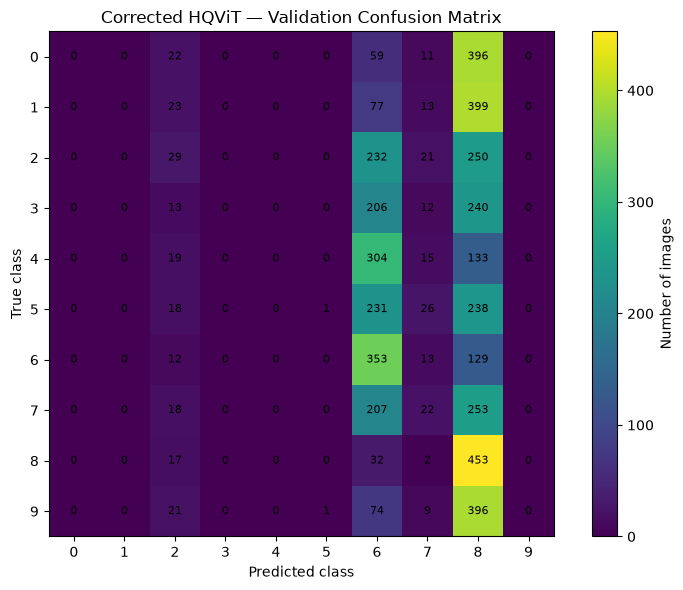


[4] CONFIDENCE AND CALIBRATION


,mean_max_probability,mean_entropy,max_entropy_10_classes,mean_confidence_correct,mean_confidence_incorrect,expected_calibration_error_10_bins
0,0.13035,2.27888,2.30259,0.13324,0.12975,0.04125


Calibration bins:


,confidence_bin,sample_count,accuracy,mean_confidence
0,0.0-0.1,0,NaN,NaN
1,0.1-0.2,5000,0.1716,0.1303
2,0.2-0.3,0,NaN,NaN
3,0.3-0.4,0,NaN,NaN
4,0.4-0.5,0,NaN,NaN
5,0.5-0.6,0,NaN,NaN
6,0.6-0.7,0,NaN,NaN
7,0.7-0.8,0,NaN,NaN
8,0.8-0.9,0,NaN,NaN
9,0.9-1.0,0,NaN,NaN


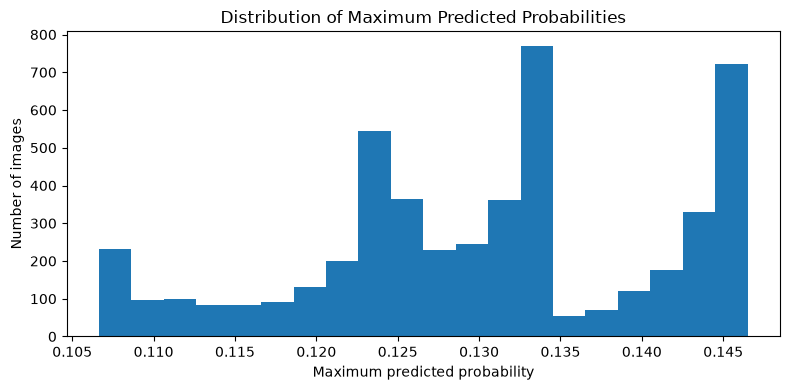

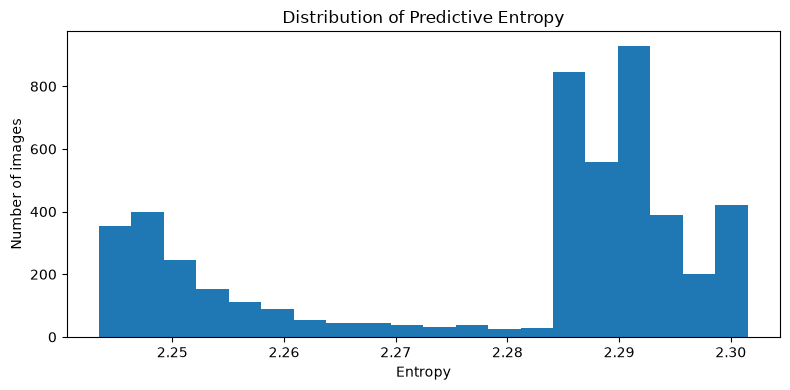


[5] QUANTUM FEATURE DIAGNOSTICS
Quantum features are the measurements passed to the classifier.


,feature_id,mean,std,min,max,fraction_abs_gt_0.95,unique_rounded_values
0,0,0.617779,0.251097,0.386053,0.992330,0.2332,1975
1,1,0.836581,0.066608,0.640579,0.994023,0.1194,1448
2,2,0.481671,0.342953,0.185648,0.989370,0.2140,1917
3,3,0.717828,0.056041,0.421748,0.823114,0.0000,1598


Quantum feature matrix shape: (5000, 4)
Overall feature standard deviation: 0.2531326115131378
Fraction of values with |value| > 0.95: 0.14165
Quantum-feature correlation matrix:


,q0,q1,q2,q3
q0,1.0000,-0.3898,0.9959,0.2040
q1,-0.3898,1.0000,-0.4080,0.6427
q2,0.9959,-0.4080,1.0000,0.1792
q3,0.2040,0.6427,0.1792,1.0000


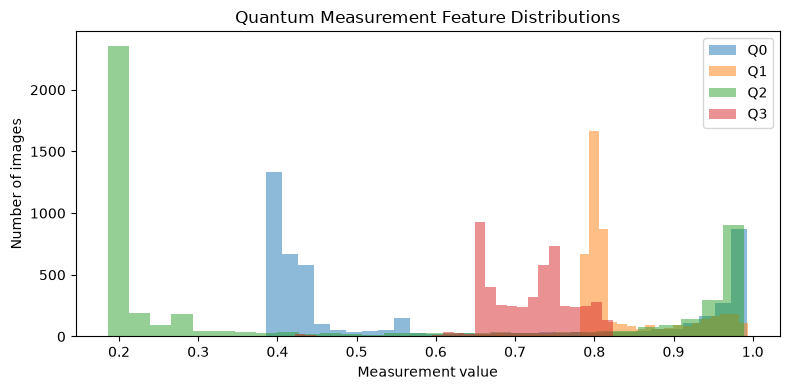


[6] PROJECTION / TRANSFORMER REPRESENTATION DIAGNOSTICS


,mean,std,min,max,fraction_abs_gt_0.95
Transformer CLS representation,0.000174,1.030149,-3.035084,3.027900,0.338501
Normalized representation,0.002238,1.001355,-3.010668,2.991174,0.321228
Raw quantum projection,-0.670287,2.777198,-5.449122,4.489714,0.734375
Encoded quantum angles,-0.162499,0.663341,-0.785369,0.785200,0.000000



[7] PARAMETER HEALTH AND GRADIENT FLOW


,parameter,shape,parameter_norm,parameter_mean,parameter_std,all_finite
0,quantum_weights,"(2, 4, 2)",0.572484,-0.022288,0.146011,True
1,vit.cls_token,"(1, 1, 128)",0.436551,0.002553,0.038653,True
2,vit.pos_embedding,"(1, 65, 128)",4.230772,-0.000112,0.046386,True
3,vit.patch_embedding.weight,"(128, 3, 4, 4)",7.379898,-0.000921,0.094154,True
4,vit.patch_embedding.bias,"(128,)",0.981597,0.003196,0.087044,True
...,...,...,...,...,...,...
62,quantum_projection.bias,"(4,)",0.047502,-0.014334,0.021867,True
63,classifier.0.weight,"(32, 4)",3.423138,0.034669,0.301754,True
64,classifier.0.bias,"(32,)",1.803301,-0.050005,0.319873,True
65,classifier.3.weight,"(10, 32)",2.280505,-0.004559,0.127602,True


,parameter,has_gradient,gradient_norm,gradient_finite
0,quantum_weights,True,0.046833,True
1,vit.cls_token,True,0.055611,True
2,vit.pos_embedding,True,0.071793,True
3,vit.patch_embedding.weight,True,0.151263,True
4,vit.patch_embedding.bias,True,0.027923,True
...,...,...,...,...
62,quantum_projection.bias,True,0.025267,True
63,classifier.0.weight,True,0.412440,True
64,classifier.0.bias,True,0.262719,True
65,classifier.3.weight,True,1.031751,True



[8] REPEATED-INFERENCE CONSISTENCY
Maximum repeated-logit difference: 0.0000000000
Predictions identical: True

[9] AVAILABLE EXPERIMENT HISTORY COMPARISON


,experiment,epochs_recorded,best_validation_accuracy,best_epoch,training_accuracy_at_best_epoch,validation_loss_at_best_epoch,history_file
0,Corrected HQViT (10%),3,0.1716,3.0,0.13244,2.22529,results/hqvit_corrected_history_10pct.csv
1,Previous integrated HQViT (10%),3,0.1026,3.0,0.10133,2.30371,results/hqvit_integrated_history_10pct.csv
2,Classical CNN,20,0.7100,5.0,0.72318,0.83062,results/cnn_data_efficiency_history.csv
3,Classical ViT,12,0.5554,3.0,0.54551,1.21313,results/vit_data_efficiency_history.csv



DIAGNOSTICS COMPLETE
Overall validation accuracy: 17.16%
Balanced accuracy: 16.96%
Macro F1: 0.0729
Classes predicted: 5/10
Dominant-class prediction fraction: 57.74%
Mean maximum probability: 0.1303
Expected calibration error: 0.0413
Repeated-logit difference: 0.0000000000
Total diagnostic runtime: 44.6 seconds

Diagnostic CSVs saved in the results/ directory.
No model weights were updated.


In [ ]:
# SECTION 58 — COMPREHENSIVE HQViT DIAGNOSTICS

import os
import time
import warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from collections import Counter
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
    matthews_corrcoef,
    cohen_kappa_score,
    log_loss,
    top_k_accuracy_score
)

# ---------------------------------------------------------
# 1. Configuration and checkpoint loading
# ---------------------------------------------------------
diagnostic_start = time.time()
os.makedirs("results", exist_ok=True)

checkpoint_path = "models/hqvit_corrected_10pct.pt"

if not os.path.exists(checkpoint_path):
    raise FileNotFoundError(f"Checkpoint not found: {checkpoint_path}")

corrected_hqvit.load_state_dict(
    torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=True
    )
)
corrected_hqvit.eval()

num_classes = 10
class_names = [str(i) for i in range(num_classes)]
criterion = nn.CrossEntropyLoss()

print("=" * 75)
print("COMPREHENSIVE CORRECTED HQViT DIAGNOSTICS")
print("=" * 75)
print("Checkpoint:", checkpoint_path)
print("Device:", DEVICE)
print("Validation samples:", len(validation_dataset))
print("Training updates will NOT be performed.")

# ---------------------------------------------------------
# 2. Full validation inference
# ---------------------------------------------------------
all_logits = []
all_probabilities = []
all_predictions = []
all_labels = []
all_quantum_features = []
all_projected_features = []
all_transformer_features = []

validation_loss_sum = 0.0
validation_samples = 0
inference_times = []

def diagnostic_hook(module, inputs, output):
    """Capture quantum-classifier input without changing the model."""
    if isinstance(output, torch.Tensor):
        all_quantum_features.append(output.detach().cpu())

# Capture classifier inputs to inspect quantum measurement diversity.
hook_handle = corrected_hqvit.classifier.register_forward_pre_hook(
    lambda module, inputs: all_quantum_features.append(
        inputs[0].detach().cpu()
    )
)

try:
    with torch.no_grad():
        for batch_idx, (images, labels) in enumerate(validation_loader):
            batch_start = time.time()

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            logits = corrected_hqvit(images)
            probabilities = torch.softmax(logits, dim=1)
            predictions = logits.argmax(dim=1)

            validation_loss_sum += (
                criterion(logits, labels).item() * labels.size(0)
            )
            validation_samples += labels.size(0)

            all_logits.append(logits.cpu())
            all_probabilities.append(probabilities.cpu())
            all_predictions.append(predictions.cpu())
            all_labels.append(labels.cpu())

            inference_times.append(time.time() - batch_start)

finally:
    hook_handle.remove()

logits_np = torch.cat(all_logits).numpy()
probs_np = torch.cat(all_probabilities).numpy()
preds_np = torch.cat(all_predictions).numpy()
labels_np = torch.cat(all_labels).numpy()

quantum_features_np = (
    torch.cat(all_quantum_features).numpy()
    if all_quantum_features else None
)

mean_val_loss = validation_loss_sum / validation_samples

# ---------------------------------------------------------
# 3. Core classification metrics
# ---------------------------------------------------------
accuracy = accuracy_score(labels_np, preds_np)
balanced_acc = balanced_accuracy_score(labels_np, preds_np)

precision_macro, recall_macro, f1_macro, _ = (
    precision_recall_fscore_support(
        labels_np,
        preds_np,
        average="macro",
        zero_division=0
    )
)

precision_weighted, recall_weighted, f1_weighted, _ = (
    precision_recall_fscore_support(
        labels_np,
        preds_np,
        average="weighted",
        zero_division=0
    )
)

mcc = matthews_corrcoef(labels_np, preds_np)
kappa = cohen_kappa_score(labels_np, preds_np)

top3_accuracy = top_k_accuracy_score(
    labels_np,
    probs_np,
    k=3,
    labels=np.arange(num_classes)
)

try:
    multiclass_log_loss = log_loss(
        labels_np,
        probs_np,
        labels=np.arange(num_classes)
    )
except ValueError:
    multiclass_log_loss = np.nan

metrics = {
    "validation_samples": validation_samples,
    "validation_loss": mean_val_loss,
    "accuracy": accuracy,
    "balanced_accuracy": balanced_acc,
    "macro_precision": precision_macro,
    "macro_recall": recall_macro,
    "macro_f1": f1_macro,
    "weighted_precision": precision_weighted,
    "weighted_recall": recall_weighted,
    "weighted_f1": f1_weighted,
    "top3_accuracy": top3_accuracy,
    "matthews_correlation": mcc,
    "cohen_kappa": kappa,
    "log_loss": multiclass_log_loss
}

print("\n[1] CORE CLASSIFICATION METRICS")
display(pd.DataFrame(
    [{"metric": key, "value": value} for key, value in metrics.items()]
).round(5))

# ---------------------------------------------------------
# 4. Class distribution and collapse analysis
# ---------------------------------------------------------
true_counts = np.bincount(labels_np, minlength=num_classes)
pred_counts = np.bincount(preds_np, minlength=num_classes)

predicted_class_fraction = pred_counts / len(preds_np)
true_class_fraction = true_counts / len(labels_np)

prediction_entropy = -np.sum(
    predicted_class_fraction[
        predicted_class_fraction > 0
    ] * np.log(
        predicted_class_fraction[predicted_class_fraction > 0]
    )
)

normalized_prediction_entropy = prediction_entropy / np.log(num_classes)
classes_predicted = int(np.sum(pred_counts > 0))
dominant_class_fraction = pred_counts.max() / len(preds_np)

class_distribution_df = pd.DataFrame({
    "class_id": np.arange(num_classes),
    "true_count": true_counts,
    "predicted_count": pred_counts,
    "true_fraction": true_class_fraction,
    "predicted_fraction": predicted_class_fraction
})

print("\n[2] CLASS DISTRIBUTION / CLASS-COLLAPSE CHECK")
print("Number of classes predicted:", classes_predicted, "/ 10")
print(f"Most-predicted class fraction: {dominant_class_fraction:.2%}")
print(f"Normalized prediction entropy: {normalized_prediction_entropy:.4f}")
display(class_distribution_df.round(4))

# ---------------------------------------------------------
# 5. Per-class metrics and confusion matrix
# ---------------------------------------------------------
report = classification_report(
    labels_np,
    preds_np,
    labels=np.arange(num_classes),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

print("\n[3] PER-CLASS CLASSIFICATION REPORT")
display(report_df.round(4))

cm = confusion_matrix(
    labels_np,
    preds_np,
    labels=np.arange(num_classes)
)

plt.figure(figsize=(8, 6))
plt.imshow(cm, interpolation="nearest")
plt.title("Corrected HQViT — Validation Confusion Matrix")
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.xticks(range(num_classes))
plt.yticks(range(num_classes))
plt.colorbar(label="Number of images")

for i in range(num_classes):
    for j in range(num_classes):
        plt.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=8)

plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 6. Confidence, entropy, and calibration indicators
# ---------------------------------------------------------
eps = 1e-12
sample_entropy = -np.sum(
    probs_np * np.log(np.clip(probs_np, eps, 1.0)),
    axis=1
)

max_prob = probs_np.max(axis=1)
correct_mask = preds_np == labels_np

confidence_df = pd.DataFrame({
    "correct_prediction": correct_mask,
    "maximum_probability": max_prob,
    "predictive_entropy": sample_entropy
})

mean_confidence = max_prob.mean()
mean_correct_confidence = (
    max_prob[correct_mask].mean() if correct_mask.any() else np.nan
)
mean_incorrect_confidence = (
    max_prob[~correct_mask].mean() if (~correct_mask).any() else np.nan
)

# Expected Calibration Error (ECE), using 10 equal-width confidence bins.
ece = 0.0
bin_rows = []

bin_edges = np.linspace(0, 1, 11)
for bin_idx in range(10):
    lower, upper = bin_edges[bin_idx], bin_edges[bin_idx + 1]

    if bin_idx == 9:
        mask = (max_prob >= lower) & (max_prob <= upper)
    else:
        mask = (max_prob >= lower) & (max_prob < upper)

    count = int(mask.sum())

    if count:
        bin_accuracy = correct_mask[mask].mean()
        bin_confidence = max_prob[mask].mean()
        ece += (count / len(labels_np)) * abs(
            bin_accuracy - bin_confidence
        )
    else:
        bin_accuracy = np.nan
        bin_confidence = np.nan

    bin_rows.append({
        "confidence_bin": f"{lower:.1f}-{upper:.1f}",
        "sample_count": count,
        "accuracy": bin_accuracy,
        "mean_confidence": bin_confidence
    })

confidence_summary = pd.DataFrame([{
    "mean_max_probability": mean_confidence,
    "mean_entropy": sample_entropy.mean(),
    "max_entropy_10_classes": np.log(num_classes),
    "mean_confidence_correct": mean_correct_confidence,
    "mean_confidence_incorrect": mean_incorrect_confidence,
    "expected_calibration_error_10_bins": ece
}])

print("\n[4] CONFIDENCE AND CALIBRATION")
display(confidence_summary.round(5))
print("Calibration bins:")
display(pd.DataFrame(bin_rows).round(4))

plt.figure(figsize=(8, 4))
plt.hist(max_prob, bins=20)
plt.title("Distribution of Maximum Predicted Probabilities")
plt.xlabel("Maximum predicted probability")
plt.ylabel("Number of images")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
plt.hist(sample_entropy, bins=20)
plt.title("Distribution of Predictive Entropy")
plt.xlabel("Entropy")
plt.ylabel("Number of images")
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 7. Quantum feature statistics
# ---------------------------------------------------------
print("\n[5] QUANTUM FEATURE DIAGNOSTICS")

quantum_feature_summary = None

if quantum_features_np is not None:
    qf = quantum_features_np

    quantum_feature_summary = pd.DataFrame({
        "feature_id": np.arange(qf.shape[1]),
        "mean": qf.mean(axis=0),
        "std": qf.std(axis=0),
        "min": qf.min(axis=0),
        "max": qf.max(axis=0),
        "fraction_abs_gt_0.95": (np.abs(qf) > 0.95).mean(axis=0),
        "unique_rounded_values": [
            len(np.unique(np.round(qf[:, i], 4)))
            for i in range(qf.shape[1])
        ]
    })

    print("Quantum features are the measurements passed to the classifier.")
    display(quantum_feature_summary.round(6))

    print("Quantum feature matrix shape:", qf.shape)
    print("Overall feature standard deviation:", float(qf.std()))
    print("Fraction of values with |value| > 0.95:",
          float((np.abs(qf) > 0.95).mean()))

    # Correlation between quantum features.
    if qf.shape[1] > 1:
        print("Quantum-feature correlation matrix:")
        display(pd.DataFrame(
            np.corrcoef(qf, rowvar=False),
            index=[f"q{i}" for i in range(qf.shape[1])],
            columns=[f"q{i}" for i in range(qf.shape[1])]
        ).round(4))

    plt.figure(figsize=(8, 4))
    for feature_idx in range(qf.shape[1]):
        plt.hist(
            qf[:, feature_idx],
            bins=30,
            alpha=0.5,
            label=f"Q{feature_idx}"
        )
    plt.title("Quantum Measurement Feature Distributions")
    plt.xlabel("Measurement value")
    plt.ylabel("Number of images")
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print("No quantum features were captured.")

# ---------------------------------------------------------
# 8. Projection and transformer representation diagnostics
# ---------------------------------------------------------
print("\n[6] PROJECTION / TRANSFORMER REPRESENTATION DIAGNOSTICS")

projection_stats = {}
representation_stats = {}

# Sample one validation batch and inspect intermediate representations.
images, labels = next(iter(validation_loader))
images = images.to(DEVICE)

with torch.no_grad():
    tokens = corrected_hqvit.vit.patch_embedding(images)
    tokens = tokens.flatten(2).transpose(1, 2)
    cls_tokens = corrected_hqvit.vit.cls_token.expand(
        images.size(0), -1, -1
    )
    tokens = torch.cat((cls_tokens, tokens), dim=1)
    tokens = tokens + corrected_hqvit.vit.pos_embedding
    tokens = corrected_hqvit.vit.embedding_dropout(tokens)
    tokens = corrected_hqvit.vit.transformer(tokens)

    representation = tokens[:, 0]
    normalized_representation = corrected_hqvit.projection_norm(
        representation
    )
    raw_projection = corrected_hqvit.quantum_projection(
        normalized_representation
    )
    encoded_projection = (torch.pi / 4) * torch.tanh(raw_projection)

    for name, tensor in [
        ("Transformer CLS representation", representation),
        ("Normalized representation", normalized_representation),
        ("Raw quantum projection", raw_projection),
        ("Encoded quantum angles", encoded_projection)
    ]:
        array = tensor.detach().cpu().numpy()
        projection_stats[name] = {
            "mean": array.mean(),
            "std": array.std(),
            "min": array.min(),
            "max": array.max(),
            "fraction_abs_gt_0.95": (np.abs(array) > 0.95).mean()
        }

display(pd.DataFrame(projection_stats).transpose().round(6))

# ---------------------------------------------------------
# 9. Parameter health and gradient flow
# ---------------------------------------------------------
print("\n[7] PARAMETER HEALTH AND GRADIENT FLOW")

parameter_rows = []

for name, parameter in corrected_hqvit.named_parameters():
    values = parameter.detach()
    parameter_rows.append({
        "parameter": name,
        "shape": tuple(parameter.shape),
        "parameter_norm": values.norm().item(),
        "parameter_mean": values.mean().item(),
        "parameter_std": values.std().item() if values.numel() > 1 else 0.0,
        "all_finite": torch.isfinite(values).all().item()
    })

parameter_df = pd.DataFrame(parameter_rows)
display(parameter_df.round(6))

# A small diagnostic backward pass; no optimizer step.
corrected_hqvit.zero_grad(set_to_none=True)
corrected_hqvit.train()

diag_images, diag_labels = next(iter(validation_loader))
diag_images = diag_images[:2].to(DEVICE)
diag_labels = diag_labels[:2].to(DEVICE)

diag_logits = corrected_hqvit(diag_images)
diag_loss = criterion(diag_logits, diag_labels)
diag_loss.backward()

gradient_rows = []

for name, parameter in corrected_hqvit.named_parameters():
    grad = parameter.grad

    gradient_rows.append({
        "parameter": name,
        "has_gradient": grad is not None,
        "gradient_norm": grad.norm().item() if grad is not None else np.nan,
        "gradient_finite": (
            torch.isfinite(grad).all().item()
            if grad is not None else False
        )
    })

gradient_df = pd.DataFrame(gradient_rows)
display(gradient_df.round(8))

corrected_hqvit.eval()
corrected_hqvit.zero_grad(set_to_none=True)

# ---------------------------------------------------------
# 10. Prediction consistency
# ---------------------------------------------------------
print("\n[8] REPEATED-INFERENCE CONSISTENCY")

# The model is in evaluation mode, so dropout is disabled.
# Re-evaluate a fixed batch to check deterministic inference.
fixed_images, _ = next(iter(validation_loader))
fixed_images = fixed_images[:8].to(DEVICE)

with torch.no_grad():
    first_logits = corrected_hqvit(fixed_images)
    second_logits = corrected_hqvit(fixed_images)

max_logit_difference = (
    first_logits - second_logits
).abs().max().item()

same_predictions = (
    first_logits.argmax(dim=1) == second_logits.argmax(dim=1)
).all().item()

print(f"Maximum repeated-logit difference: {max_logit_difference:.10f}")
print("Predictions identical:", same_predictions)

# ---------------------------------------------------------
# 11. Compare with existing saved experiment histories
# ---------------------------------------------------------
print("\n[9] AVAILABLE EXPERIMENT HISTORY COMPARISON")

history_paths = {
    "Corrected HQViT (10%)": "results/hqvit_corrected_history_10pct.csv",
    "Previous integrated HQViT (10%)": "results/hqvit_integrated_history_10pct.csv",
    "Classical CNN": "results/cnn_data_efficiency_history.csv",
    "Classical ViT": "results/vit_data_efficiency_history.csv"
}

history_comparison_rows = []

for experiment_name, path in history_paths.items():
    if not os.path.exists(path):
        print(f"Not found: {path}")
        continue

    history = pd.read_csv(path)

    val_col = next(
        (
            column for column in [
                "validation_accuracy",
                "val_accuracy",
                "val_acc"
            ]
            if column in history.columns
        ),
        None
    )

    train_col = next(
        (
            column for column in [
                "train_accuracy",
                "training_accuracy",
                "train_acc"
            ]
            if column in history.columns
        ),
        None
    )

    loss_col = next(
        (
            column for column in [
                "validation_loss",
                "val_loss"
            ]
            if column in history.columns
        ),
        None
    )

    if val_col:
        best_idx = history[val_col].astype(float).idxmax()
        best_row = history.loc[best_idx]

        history_comparison_rows.append({
            "experiment": experiment_name,
            "epochs_recorded": len(history),
            "best_validation_accuracy": float(best_row[val_col]),
            "best_epoch": best_row.get("epoch", best_idx + 1),
            "training_accuracy_at_best_epoch": (
                float(best_row[train_col]) if train_col else np.nan
            ),
            "validation_loss_at_best_epoch": (
                float(best_row[loss_col]) if loss_col else np.nan
            ),
            "history_file": path
        })

if history_comparison_rows:
    history_comparison_df = pd.DataFrame(history_comparison_rows)
    display(history_comparison_df.round(5))
else:
    history_comparison_df = pd.DataFrame()
    print("No compatible history files were found.")

# ---------------------------------------------------------
# 12. Save diagnostics
# ---------------------------------------------------------
pd.DataFrame([metrics]).to_csv(
    "results/hqvit_corrected_diagnostic_metrics.csv",
    index=False
)

class_distribution_df.to_csv(
    "results/hqvit_corrected_class_distribution.csv",
    index=False
)

report_df.to_csv(
    "results/hqvit_corrected_classification_report.csv"
)

pd.DataFrame(cm).to_csv(
    "results/hqvit_corrected_confusion_matrix.csv",
    index=False
)

confidence_summary.to_csv(
    "results/hqvit_corrected_confidence_summary.csv",
    index=False
)

pd.DataFrame(bin_rows).to_csv(
    "results/hqvit_corrected_calibration_bins.csv",
    index=False
)

parameter_df.to_csv(
    "results/hqvit_corrected_parameter_diagnostics.csv",
    index=False
)

gradient_df.to_csv(
    "results/hqvit_corrected_gradient_diagnostics.csv",
    index=False
)

if quantum_feature_summary is not None:
    quantum_feature_summary.to_csv(
        "results/hqvit_corrected_quantum_feature_diagnostics.csv",
        index=False
    )

if not history_comparison_df.empty:
    history_comparison_df.to_csv(
        "results/hqvit_corrected_history_comparison.csv",
        index=False
    )

print("\n" + "=" * 75)
print("DIAGNOSTICS COMPLETE")
print("=" * 75)
print(f"Overall validation accuracy: {accuracy:.2%}")
print(f"Balanced accuracy: {balanced_acc:.2%}")
print(f"Macro F1: {f1_macro:.4f}")
print(f"Classes predicted: {classes_predicted}/10")
print(f"Dominant-class prediction fraction: {dominant_class_fraction:.2%}")
print(f"Mean maximum probability: {mean_confidence:.4f}")
print(f"Expected calibration error: {ece:.4f}")
print(f"Repeated-logit difference: {max_logit_difference:.10f}")
print(f"Total diagnostic runtime: {time.time() - diagnostic_start:.1f} seconds")
print("\nDiagnostic CSVs saved in the results/ directory.")
print("No model weights were updated.")

Section 59: Representation Bottleneck Analysis

Investigate where classification performance degrades in the corrected HQViT by comparing the class information available in its transformer representation and quantum measurement outputs.

Extract frozen representations from the saved checkpoint and evaluate lightweight diagnostic classifiers using stratified cross-validation. Compare their performance with the original model's predictions.

This analysis is intended to distinguish representation limitations from limitations in the trained quantum-classical classifier. Probe results are diagnostic only: they must not be reported as the original HQViT's test accuracy or as evidence of quantum advantage.

The analysis does not update the HQViT parameters or use the CIFAR-10 test set.

In [ ]:
# SECTION 59 — REPRESENTATION BOTTLENECK ANALYSIS

import os
import time
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score

start_time = time.time()

corrected_hqvit.eval()

transformer_features = []
quantum_features = []
labels_all = []
original_predictions = []
original_probabilities = []

# Extract representations from the validation set.
with torch.no_grad():
    for images, labels in validation_loader:
        images = images.to(DEVICE)

        tokens = corrected_hqvit.vit.patch_embedding(images)
        tokens = tokens.flatten(2).transpose(1, 2)

        cls_tokens = corrected_hqvit.vit.cls_token.expand(
            images.size(0), -1, -1
        )

        tokens = torch.cat((cls_tokens, tokens), dim=1)
        tokens = tokens + corrected_hqvit.vit.pos_embedding
        tokens = corrected_hqvit.vit.embedding_dropout(tokens)
        tokens = corrected_hqvit.vit.transformer(tokens)

        representation = tokens[:, 0]
        normalized = corrected_hqvit.projection_norm(representation)

        projected = corrected_hqvit.quantum_projection(normalized)
        quantum_inputs = (torch.pi / 4) * torch.tanh(projected)

        # Reproduce the quantum measurement stage.
        q_rows = []

        for sample in quantum_inputs:
            measurements = quantum_circuit(
                sample, corrected_hqvit.quantum_weights
            )

            if isinstance(measurements, (tuple, list)):
                measurements = torch.stack([
                    torch.as_tensor(value, device=images.device)
                    for value in measurements
                ])
            else:
                measurements = torch.as_tensor(
                    measurements, device=images.device
                )

            q_rows.append(measurements)

        q_outputs = torch.stack(q_rows)
        classifier_parameter = next(
            corrected_hqvit.classifier.parameters()
        )
        q_outputs = q_outputs.to(
            device=classifier_parameter.device,
            dtype=classifier_parameter.dtype
        )

        logits = corrected_hqvit.classifier(q_outputs)
        probabilities = torch.softmax(logits, dim=1)

        transformer_features.append(
            representation.cpu().numpy()
        )
        quantum_features.append(q_outputs.cpu().numpy())
        labels_all.append(labels.numpy())
        original_predictions.append(logits.argmax(dim=1).cpu().numpy())
        original_probabilities.append(probabilities.cpu().numpy())

X_transformer = np.concatenate(transformer_features)
X_quantum = np.concatenate(quantum_features)
y = np.concatenate(labels_all)
pred_original = np.concatenate(original_predictions)
probs_original = np.concatenate(original_probabilities)

print("Extracted representation shapes:")
print("Transformer:", X_transformer.shape)
print("Quantum:", X_quantum.shape)
print("Labels:", y.shape)

# ---------------------------------------------------------
# A. Compare class separability of the two representations
# ---------------------------------------------------------
def fisher_separability(X, y):
    """Ratio of between-class variance to within-class variance."""
    overall_mean = X.mean(axis=0)

    between = 0.0
    within = 0.0

    for class_id in np.unique(y):
        Xc = X[y == class_id]
        if len(Xc) == 0:
            continue

        class_mean = Xc.mean(axis=0)
        between += len(Xc) * np.sum((class_mean - overall_mean) ** 2)
        within += np.sum((Xc - class_mean) ** 2)

    return between / max(within, 1e-12)

print("\n[1] FROZEN REPRESENTATION STATISTICS")
print("Transformer Fisher separability:",
      round(fisher_separability(X_transformer, y), 6))
print("Quantum Fisher separability:",
      round(fisher_separability(X_quantum, y), 6))

# ---------------------------------------------------------
# B. Cross-validated linear probes
# ---------------------------------------------------------
# Stratified CV assesses separability on this validation set.
# These are diagnostic probes, not an unbiased final test estimate.
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

probe_results = []

for name, X in [
    ("Transformer CLS representation", X_transformer),
    ("Quantum measurement representation", X_quantum)
]:
    probe = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=1000,
            class_weight=None,
            random_state=SEED
        )
    )

    scores = cross_val_score(
        probe,
        X,
        y,
        cv=cv,
        scoring="accuracy",
        n_jobs=1
    )

    probe_results.append({
        "representation": name,
        "fold_1_accuracy": scores[0],
        "fold_2_accuracy": scores[1],
        "fold_3_accuracy": scores[2],
        "mean_accuracy": scores.mean(),
        "std_accuracy": scores.std()
    })

probe_df = pd.DataFrame(probe_results)

print("\n[2] FROZEN LINEAR PROBE RESULTS")
display(probe_df.round(4))

# ---------------------------------------------------------
# C. Original model prediction metrics
# ---------------------------------------------------------
original_accuracy = accuracy_score(y, pred_original)
original_balanced_accuracy = balanced_accuracy_score(y, pred_original)

print("\n[3] ORIGINAL HQViT VALIDATION PREDICTIONS")
print(f"Accuracy: {original_accuracy:.4f}")
print(f"Balanced accuracy: {original_balanced_accuracy:.4f}")
print("Predicted class counts:", np.bincount(pred_original, minlength=10))

# ---------------------------------------------------------
# D. Quantum feature redundancy
# ---------------------------------------------------------
quantum_correlation = np.corrcoef(X_quantum, rowvar=False)

print("\n[4] QUANTUM FEATURE CORRELATION")
display(pd.DataFrame(
    quantum_correlation,
    index=[f"Q{i}" for i in range(X_quantum.shape[1])],
    columns=[f"Q{i}" for i in range(X_quantum.shape[1])]
).round(4))

quantum_feature_stats = pd.DataFrame({
    "feature": [f"Q{i}" for i in range(X_quantum.shape[1])],
    "mean": X_quantum.mean(axis=0),
    "std": X_quantum.std(axis=0),
    "min": X_quantum.min(axis=0),
    "max": X_quantum.max(axis=0)
})

display(quantum_feature_stats.round(5))

# ---------------------------------------------------------
# E. Save results
# ---------------------------------------------------------
os.makedirs("results", exist_ok=True)

probe_df.to_csv(
    "results/hqvit_representation_probe_results.csv",
    index=False
)
quantum_feature_stats.to_csv(
    "results/hqvit_representation_feature_stats.csv",
    index=False
)
pd.DataFrame(
    quantum_correlation,
    index=[f"Q{i}" for i in range(X_quantum.shape[1])],
    columns=[f"Q{i}" for i in range(X_quantum.shape[1])]
).to_csv("results/hqvit_representation_quantum_correlation.csv")

print("\nRepresentation analysis complete.")
print("Saved diagnostic results in results/.")
print(f"Runtime: {time.time() - start_time:.1f} seconds")
print("No HQViT parameters were updated.")

Extracted representation shapes:
Transformer: (5000, 128)
Quantum: (5000, 4)
Labels: (5000,)

[1] FROZEN REPRESENTATION STATISTICS
Transformer Fisher separability: 0.32057
Quantum Fisher separability: 0.270783

[2] FROZEN LINEAR PROBE RESULTS


,representation,fold_1_accuracy,fold_2_accuracy,fold_3_accuracy,mean_accuracy,std_accuracy
0,Transformer CLS representation,0.2376,0.2490,0.2347,0.2404,0.0062
1,Quantum measurement representation,0.1896,0.1878,0.1891,0.1888,0.0008



[3] ORIGINAL HQViT VALIDATION PREDICTIONS
Accuracy: 0.1716
Balanced accuracy: 0.1696
Predicted class counts: [   0    0  192    0    0    2 1775  144 2887    0]

[4] QUANTUM FEATURE CORRELATION


,Q0,Q1,Q2,Q3
Q0,1.0000,-0.3898,0.9959,0.2040
Q1,-0.3898,1.0000,-0.4080,0.6427
Q2,0.9959,-0.4080,1.0000,0.1792
Q3,0.2040,0.6427,0.1792,1.0000


,feature,mean,std,min,max
0,Q0,0.61778,0.25110,0.38605,0.99233
1,Q1,0.83658,0.06661,0.64058,0.99402
2,Q2,0.48167,0.34295,0.18565,0.98937
3,Q3,0.71783,0.05604,0.42175,0.82311



Representation analysis complete.
Saved diagnostic results in results/.
Runtime: 60.1 seconds
No HQViT parameters were updated.


## Kernel died ignore next cell

In [1]:
# ============================================================
# SECTION 65 — COMPLETE HQViT RECOVERY + DIAGNOSTICS
# No model training. No checkpoint overwrite.
# Restores the model globally for Section 60.
# ============================================================

import os
import json
import time
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import pennylane as qml

from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    matthews_corrcoef,
    cohen_kappa_score,
)

warnings.filterwarnings("ignore")

START_TIME = time.time()
SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

ROOT = Path.cwd()
DATA_DIR = ROOT / "data"
RESULTS_DIR = ROOT / "results"
MODELS_DIR = ROOT / "models"

for directory in (DATA_DIR, RESULTS_DIR, MODELS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

CHECKPOINT_PATH = MODELS_DIR / "hqvit_corrected_10pct.pt"

print("=" * 72)
print("SECTION 65: COMPLETE HQVIT RECOVERY AND DIAGNOSTICS")
print("=" * 72)
print("Project:", ROOT)
print("Device:", DEVICE)
print("PyTorch:", torch.__version__)
print("Checkpoint:", CHECKPOINT_PATH)

if not CHECKPOINT_PATH.exists():
    raise FileNotFoundError(
        f"Checkpoint not found: {CHECKPOINT_PATH}\n"
        "Check the project directory before continuing."
    )


# ------------------------------------------------------------
# 1. RECREATE CIFAR-10 DATASETS AND LOADERS
# ------------------------------------------------------------

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.4914, 0.4822, 0.4465),
        std=(0.2470, 0.2435, 0.2616),
    ),
])

print("\n[1/10] Loading CIFAR-10...")

full_train_dataset = datasets.CIFAR10(
    root=str(DATA_DIR),
    train=True,
    download=True,
    transform=transform,
)

test_dataset = datasets.CIFAR10(
    root=str(DATA_DIR),
    train=False,
    download=True,
    transform=transform,
)

CLASS_NAMES = full_train_dataset.classes
NUM_CLASSES = len(CLASS_NAMES)

split_generator = np.random.default_rng(SEED)
split_indices = split_generator.permutation(len(full_train_dataset))

train_pool_indices = split_indices[:45000].tolist()
validation_indices = split_indices[45000:].tolist()

train_pool = Subset(full_train_dataset, train_pool_indices)
validation_dataset = Subset(full_train_dataset, validation_indices)

fraction_generator = np.random.default_rng(SEED)
pool_order = fraction_generator.permutation(len(train_pool))

train_subsets = {
    fraction: Subset(
        train_pool,
        pool_order[:int(len(train_pool) * fraction)].tolist(),
    )
    for fraction in (0.10, 0.25, 0.50, 1.00)
}

BATCH_SIZE = 128

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

print("Training pool:", len(train_pool))
print("Validation:", len(validation_dataset))
print("Test:", len(test_dataset))
print("Classes:", CLASS_NAMES)
print(
    "Note: validation indices are reconstructed from seed 42. "
    "They may differ from the original notebook split."
)


# ------------------------------------------------------------
# 2. RECREATE CLASSICAL VIT
# ------------------------------------------------------------

class ClassicalViT(nn.Module):
    def __init__(
        self,
        image_size=32,
        patch_size=4,
        num_classes=10,
        embed_dim=128,
        num_heads=4,
        num_layers=4,
        mlp_dim=256,
        dropout=0.1,
    ):
        super().__init__()

        assert image_size % patch_size == 0
        num_patches = (image_size // patch_size) ** 2

        self.image_size = image_size
        self.patch_size = patch_size

        self.patch_embedding = nn.Conv2d(
            3,
            embed_dim,
            kernel_size=patch_size,
            stride=patch_size,
        )

        self.cls_token = nn.Parameter(
            torch.zeros(1, 1, embed_dim)
        )

        self.pos_embedding = nn.Parameter(
            torch.zeros(1, num_patches + 1, embed_dim)
        )

        self.embedding_dropout = nn.Dropout(dropout)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=mlp_dim,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True,
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers,
            norm=nn.LayerNorm(embed_dim),
        )

        self.classifier = nn.Sequential(
            nn.LayerNorm(embed_dim),
            nn.Linear(embed_dim, num_classes),
        )

        nn.init.trunc_normal_(self.cls_token, std=0.02)
        nn.init.trunc_normal_(self.pos_embedding, std=0.02)

    def forward(self, x):
        x = self.patch_embedding(x)
        x = x.flatten(2).transpose(1, 2)

        cls_tokens = self.cls_token.expand(x.size(0), -1, -1)
        x = torch.cat([cls_tokens, x], dim=1)

        x = x + self.pos_embedding
        x = self.embedding_dropout(x)
        x = self.transformer(x)

        return self.classifier(x[:, 0])


# ------------------------------------------------------------
# 3. RECREATE QUANTUM CIRCUIT
# ------------------------------------------------------------

N_QUBITS = 4
N_Q_LAYERS = 2

quantum_device = qml.device("default.qubit", wires=N_QUBITS)


@qml.qnode(quantum_device, interface="torch")
def quantum_circuit(inputs, weights):
    for wire in range(N_QUBITS):
        qml.RY(inputs[wire], wires=wire)

    for layer in range(N_Q_LAYERS):
        for wire in range(N_QUBITS):
            qml.RY(weights[layer, wire, 0], wires=wire)
            qml.RZ(weights[layer, wire, 1], wires=wire)

        for wire in range(N_QUBITS - 1):
            qml.CNOT(wires=[wire, wire + 1])

    return [
        qml.expval(qml.PauliZ(wire))
        for wire in range(N_QUBITS)
    ]


# ------------------------------------------------------------
# 4. RECREATE CORRECTED HQVIT ARCHITECTURE
# ------------------------------------------------------------

class CorrectedHybridQuantumViT(nn.Module):
    def __init__(self):
        super().__init__()

        self.vit = ClassicalViT().to(DEVICE)
        self.projection_norm = nn.LayerNorm(128)

        self.quantum_projection = nn.Linear(128, N_QUBITS)

        nn.init.xavier_uniform_(
            self.quantum_projection.weight,
            gain=0.25,
        )
        nn.init.zeros_(self.quantum_projection.bias)

        self.quantum_weights = nn.Parameter(
            0.01 * torch.randn(N_Q_LAYERS, N_QUBITS, 2)
        )

        self.classifier = nn.Sequential(
            nn.Linear(N_QUBITS, 32),
            nn.GELU(),
            nn.Dropout(0.1),
            nn.Linear(32, NUM_CLASSES),
        )

    def forward(self, images):
        tokens = self.vit.patch_embedding(images)
        tokens = tokens.flatten(2).transpose(1, 2)

        cls_tokens = self.vit.cls_token.expand(
            images.size(0), -1, -1
        )

        tokens = torch.cat((cls_tokens, tokens), dim=1)
        tokens = tokens + self.vit.pos_embedding
        tokens = self.vit.embedding_dropout(tokens)
        tokens = self.vit.transformer(tokens)

        representation = self.projection_norm(tokens[:, 0])

        projected = self.quantum_projection(representation)
        quantum_inputs = (torch.pi / 4) * torch.tanh(projected)

        quantum_rows = []

        for sample in quantum_inputs:
            measurements = quantum_circuit(
                sample,
                self.quantum_weights,
            )

            if isinstance(measurements, (tuple, list)):
                measurements = torch.stack([
                    torch.as_tensor(
                        value,
                        device=images.device,
                        dtype=images.dtype,
                    )
                    for value in measurements
                ])
            else:
                measurements = torch.as_tensor(
                    measurements,
                    device=images.device,
                    dtype=images.dtype,
                )

            quantum_rows.append(measurements)

        quantum_outputs = torch.stack(quantum_rows)

        classifier_parameter = next(self.classifier.parameters())

        quantum_outputs = quantum_outputs.to(
            device=classifier_parameter.device,
            dtype=classifier_parameter.dtype,
        )

        return self.classifier(quantum_outputs)


# ------------------------------------------------------------
# 5. RESTORE CHECKPOINT AND PRESERVE GLOBAL MODEL
# ------------------------------------------------------------

print("\n[2/10] Restoring checkpoint...")

model = CorrectedHybridQuantumViT().to(DEVICE)

checkpoint_object = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=True,
)

if (
    isinstance(checkpoint_object, dict)
    and "model_state_dict" in checkpoint_object
):
    state_dict = checkpoint_object["model_state_dict"]
else:
    state_dict = checkpoint_object

model.load_state_dict(state_dict, strict=True)
model.eval()

# CRITICAL: preserve references needed by Section 60.
globals()["model"] = model
globals()["corrected_hqvit"] = model
globals()["corrected_model"] = model
globals()["hqvit_model"] = model
globals()["validation_loader"] = validation_loader
globals()["quantum_circuit"] = quantum_circuit
globals()["N_QUBITS"] = N_QUBITS
globals()["N_Q_LAYERS"] = N_Q_LAYERS
globals()["DEVICE"] = DEVICE
globals()["CLASS_NAMES"] = CLASS_NAMES

parameter_count = sum(p.numel() for p in model.parameters())

print("Checkpoint loaded successfully.")
print("Model class:", type(model).__name__)
print("Parameter count:", f"{parameter_count:,}")
print("Global model preserved:", isinstance(globals().get("model"), nn.Module))
print("Device:", next(model.parameters()).device)


# ------------------------------------------------------------
# 6. FORWARD-PASS AND PARAMETER-INTEGRITY CHECKS
# ------------------------------------------------------------

print("\n[3/10] Forward-pass test...")

sample_images, sample_labels = next(iter(validation_loader))
sample_images = sample_images[:4].to(DEVICE)
sample_labels = sample_labels[:4].to(DEVICE)

with torch.no_grad():
    sample_logits = model(sample_images)

assert sample_logits.shape == (len(sample_images), NUM_CLASSES)
assert torch.isfinite(sample_logits).all()

print("Input shape:", tuple(sample_images.shape))
print("Output shape:", tuple(sample_logits.shape))
print("Logits finite:", bool(torch.isfinite(sample_logits).all()))
print("Forward-pass test PASSED.")

print("\n[4/10] Parameter-integrity diagnostics...")

parameter_rows = []

for name, parameter in model.named_parameters():
    values = parameter.detach().float()

    parameter_rows.append({
        "parameter": name,
        "shape": str(tuple(parameter.shape)),
        "parameter_count": parameter.numel(),
        "mean": values.mean().item(),
        "std": values.std().item(),
        "norm": values.norm().item(),
        "all_finite": bool(torch.isfinite(values).all()),
    })

parameter_df = pd.DataFrame(parameter_rows)

parameter_df.to_csv(
    RESULTS_DIR / "hqvit_recovery_parameter_integrity.csv",
    index=False,
)

print("All parameters finite:", bool(parameter_df["all_finite"].all()))
print(
    parameter_df[
        ["parameter", "parameter_count", "mean", "std", "norm", "all_finite"]
    ].to_string(index=False)
)


# ------------------------------------------------------------
# 7. READ EXISTING FULL-VALIDATION DIAGNOSTIC REPORTS
# ------------------------------------------------------------

print("\n[5/10] Existing full-validation diagnostic reports...")

saved_names = [
    "hqvit_corrected_diagnostic_metrics.csv",
    "hqvit_corrected_class_distribution.csv",
    "hqvit_corrected_classification_report.csv",
    "hqvit_corrected_confusion_matrix.csv",
    "hqvit_corrected_quantum_feature_diagnostics.csv",
    "hqvit_corrected_history_comparison.csv",
    "hqvit_corrected_confidence_summary.csv",
    "hqvit_corrected_calibration_bins.csv",
]

for filename in saved_names:
    path = RESULTS_DIR / filename
    print(f"{filename}: {'FOUND' if path.exists() else 'NOT FOUND'}")

    if path.exists() and filename in (
        "hqvit_corrected_diagnostic_metrics.csv",
        "hqvit_corrected_class_distribution.csv",
        "hqvit_corrected_classification_report.csv",
    ):
        print(pd.read_csv(path).to_string(index=False))
        print()


# ------------------------------------------------------------
# 8. LIMITED LIVE QUANTUM FEATURE DIAGNOSTICS
# ------------------------------------------------------------

print("\n[6/10] Limited live quantum diagnostics...")

LIVE_DIAGNOSTIC_SAMPLES = 32

live_features = []
live_transformer_features = []
live_labels = []
live_predictions = []
live_probabilities = []

model.eval()

with torch.no_grad():
    for images, labels in validation_loader:
        remaining = LIVE_DIAGNOSTIC_SAMPLES - sum(
            len(part) for part in live_labels
        )

        if remaining <= 0:
            break

        images = images[:remaining].to(DEVICE)
        labels = labels[:remaining]

        tokens = model.vit.patch_embedding(images)
        tokens = tokens.flatten(2).transpose(1, 2)

        cls_tokens = model.vit.cls_token.expand(
            images.size(0), -1, -1
        )

        tokens = torch.cat((cls_tokens, tokens), dim=1)
        tokens = tokens + model.vit.pos_embedding
        tokens = model.vit.embedding_dropout(tokens)
        tokens = model.vit.transformer(tokens)

        cls_repr = tokens[:, 0]
        normalized_repr = model.projection_norm(cls_repr)

        projected = model.quantum_projection(normalized_repr)
        quantum_inputs = (torch.pi / 4) * torch.tanh(projected)

        quantum_rows = []

        for sample in quantum_inputs:
            measurements = quantum_circuit(
                sample,
                model.quantum_weights,
            )

            if isinstance(measurements, (tuple, list)):
                measurements = torch.stack([
                    torch.as_tensor(
                        value,
                        device=DEVICE,
                        dtype=images.dtype,
                    )
                    for value in measurements
                ])
            else:
                measurements = torch.as_tensor(
                    measurements,
                    device=DEVICE,
                    dtype=images.dtype,
                )

            quantum_rows.append(measurements)

        quantum_outputs = torch.stack(quantum_rows).to(
            device=DEVICE,
            dtype=next(model.classifier.parameters()).dtype,
        )

        logits = model.classifier(quantum_outputs)
        probabilities = torch.softmax(logits, dim=1)

        live_transformer_features.append(cls_repr.cpu().numpy())
        live_features.append(quantum_outputs.cpu().numpy())
        live_labels.append(labels.numpy())
        live_predictions.append(logits.argmax(dim=1).cpu().numpy())
        live_probabilities.append(probabilities.cpu().numpy())

X_transformer = np.concatenate(live_transformer_features, axis=0)
X_quantum = np.concatenate(live_features, axis=0)
y_live = np.concatenate(live_labels, axis=0)
pred_live = np.concatenate(live_predictions, axis=0)
prob_live = np.concatenate(live_probabilities, axis=0)

print("Live sample count:", len(y_live))
print("Transformer representation:", X_transformer.shape)
print("Quantum representation:", X_quantum.shape)
print("Sample accuracy:", accuracy_score(y_live, pred_live))
print("Sample balanced accuracy:", balanced_accuracy_score(y_live, pred_live))
print("Predicted classes:", np.unique(pred_live).tolist())

quantum_corr = pd.DataFrame(
    X_quantum,
    columns=[f"Q{i}" for i in range(N_QUBITS)],
).corr()

quantum_corr.to_csv(
    RESULTS_DIR / "hqvit_recovery_quantum_correlation_small_sample.csv"
)

quantum_stats = pd.DataFrame({
    "feature": [f"Q{i}" for i in range(N_QUBITS)],
    "mean": X_quantum.mean(axis=0),
    "std": X_quantum.std(axis=0),
    "min": X_quantum.min(axis=0),
    "max": X_quantum.max(axis=0),
    "fraction_abs_gt_095": (np.abs(X_quantum) > 0.95).mean(axis=0),
})

quantum_stats.to_csv(
    RESULTS_DIR / "hqvit_recovery_quantum_stats_small_sample.csv",
    index=False,
)

print("\nQuantum feature correlation:")
print(quantum_corr.round(4).to_string())

print("\nQuantum feature statistics:")
print(quantum_stats.round(5).to_string(index=False))


# ------------------------------------------------------------
# 9. GRADIENT-FLOW DIAGNOSTICS — NO OPTIMIZER STEP
# ------------------------------------------------------------

print("\n[7/10] Gradient-flow diagnostics...")

model.eval()
model.zero_grad(set_to_none=True)

images, labels = next(iter(validation_loader))
images = images[:2].to(DEVICE)
labels = labels[:2].to(DEVICE)

criterion = nn.CrossEntropyLoss()
logits = model(images)
loss = criterion(logits, labels)
loss.backward()

gradient_rows = []

parameter_groups = [
    ("Transformer", list(model.vit.transformer.parameters())),
    ("Projection norm", list(model.projection_norm.parameters())),
    ("Quantum projection", list(model.quantum_projection.parameters())),
    ("Quantum weights", [model.quantum_weights]),
    ("Classifier", list(model.classifier.parameters())),
]

for group_name, parameters in parameter_groups:
    grad_norms = [
        p.grad.detach().float().norm().item()
        for p in parameters
        if p.grad is not None
    ]

    parameter_norms = [
        p.detach().float().norm().item()
        for p in parameters
    ]

    gradient_rows.append({
        "group": group_name,
        "gradient_available": bool(grad_norms),
        "gradient_norm": float(np.sqrt(np.sum(np.square(grad_norms))))
        if grad_norms else 0.0,
        "parameter_norm": float(np.sqrt(np.sum(np.square(parameter_norms)))),
        "gradients_finite": all(np.isfinite(grad_norms)),
    })

gradient_df = pd.DataFrame(gradient_rows)

gradient_df.to_csv(
    RESULTS_DIR / "hqvit_recovery_gradient_diagnostics.csv",
    index=False,
)

print("Diagnostic loss:", loss.item())
print(gradient_df.to_string(index=False))

# Discard gradients. No optimizer is created or stepped.
model.zero_grad(set_to_none=True)
model.eval()


# ------------------------------------------------------------
# 10. WRITE RECOVERY REPORT AND VERIFY GLOBAL STATE
# ------------------------------------------------------------

print("\n[8/10] Writing recovery report...")

report = {
    "checkpoint": str(CHECKPOINT_PATH),
    "checkpoint_loaded": True,
    "device": str(DEVICE),
    "pytorch_version": torch.__version__,
    "train_pool_size": len(train_pool),
    "validation_size": len(validation_dataset),
    "test_size": len(test_dataset),
    "number_of_classes": NUM_CLASSES,
    "model_class": type(model).__name__,
    "model_parameter_count": parameter_count,
    "small_batch_forward_pass": "passed",
    "all_parameters_finite": bool(parameter_df["all_finite"].all()),
    "live_diagnostic_sample_count": int(len(y_live)),
    "live_sample_accuracy": float(accuracy_score(y_live, pred_live)),
    "live_sample_balanced_accuracy": float(
        balanced_accuracy_score(y_live, pred_live)
    ),
    "live_quantum_feature_correlation_q0_q2": float(
        quantum_corr.iloc[0, 2]
    ),
    "gradient_diagnostics_saved": True,
    "full_validation_results_recomputed": False,
    "model_retrained": False,
    "checkpoint_overwritten": False,
    "test_set_used_for_tuning": False,
    "runtime_seconds": round(time.time() - START_TIME, 2),
}

report_path = RESULTS_DIR / "hqvit_recovery_diagnostic_report.json"

with open(report_path, "w", encoding="utf-8") as file:
    json.dump(report, file, indent=2)

# Reassert the globally accessible model and dependencies.
globals()["model"] = model
globals()["corrected_hqvit"] = model
globals()["corrected_model"] = model
globals()["hqvit_model"] = model
globals()["validation_loader"] = validation_loader
globals()["quantum_circuit"] = quantum_circuit
globals()["N_QUBITS"] = N_QUBITS
globals()["N_Q_LAYERS"] = N_Q_LAYERS
globals()["DEVICE"] = DEVICE

assert isinstance(globals()["model"], nn.Module)
assert isinstance(globals()["validation_loader"], DataLoader)

print("\n" + "=" * 72)
print("RECOVERY COMPLETE")
print("=" * 72)

for key, value in report.items():
    print(f"{key}: {value}")

print("\nGlobal model check:", isinstance(globals().get("model"), nn.Module))
print("Global validation loader:", isinstance(globals().get("validation_loader"), DataLoader))
print("Global quantum circuit:", callable(globals().get("quantum_circuit")))
print("Recovery report:", report_path)
print("\nNo training was performed.")
print("No checkpoint was overwritten.")
print("Section 60 can now access the recovered model.")

SECTION 65: COMPLETE HQVIT RECOVERY AND DIAGNOSTICS
Project: /workspaces/HQViT-Data-Efficiency-Study
Device: cpu
PyTorch: 2.14.1+cu130
Checkpoint: /workspaces/HQViT-Data-Efficiency-Study/models/hqvit_corrected_10pct.pt

[1/10] Loading CIFAR-10...
Training pool: 45000
Validation: 5000
Test: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Note: validation indices are reconstructed from seed 42. They may differ from the original notebook split.

[2/10] Restoring checkpoint...
Checkpoint loaded successfully.
Model class: CorrectedHybridQuantumViT
Parameter count: 547,720
Global model preserved: True
Device: cpu

[3/10] Forward-pass test...
Input shape: (4, 3, 32, 32)
Output shape: (4, 10)
Logits finite: True
Forward-pass test PASSED.

[4/10] Parameter-integrity diagnostics...
All parameters finite: True
                                         parameter  parameter_count      mean      std      norm  all_finite
                      

In [ ]:
# SECTION 66 — FIND ALL LIVE PYTORCH MODELS
import torch
import torch.nn as nn

print("=" * 70)
print("SECTION 66: SEARCHING FOR ALL LIVE MODELS")
print("=" * 70)

found = 0

for name, obj in list(globals().items()):
    try:
        if isinstance(obj, nn.Module):
            found += 1
            params = list(obj.parameters())
            param_count = sum(p.numel() for p in params)
            device = str(params[0].device) if params else "no parameters"

            print(f"\nVariable: {name}")
            print(f"Class: {type(obj).__name__}")
            print(f"Parameters: {param_count:,}")
            print(f"Device: {device}")
            print(f"Attributes: {[a for a in vars(obj).keys() if not a.startswith('_')][:20]}")

    except Exception as e:
        print(f"Could not inspect {name}: {e}")

print("\n" + "=" * 70)
print(f"TOTAL LIVE PYTORCH MODELS FOUND: {found}")
print("=" * 70)

SECTION 66: SEARCHING FOR ALL LIVE MODELS

TOTAL LIVE PYTORCH MODELS FOUND: 0


Section 60 — Classical vs. Quantum Bottleneck Comparison

Objective

Determine whether the performance limitations of the corrected Hybrid Quantum Vision Transformer are primarily associated with dimensionality reduction, quantum measurements, or the final classification head.

Experimental design

Compare three classifiers using frozen Transformer CLS representations:

1. Classical linear head: 128-dimensional Transformer representation → 10 classes.
2. Classical bottleneck head: 128-dimensional Transformer representation → 4-dimensional bottleneck → 10 classes.
3. Quantum head: 128-dimensional Transformer representation → quantum projection and measurements → 10 classes.

The diagnostic heads will be fitted using training representations and evaluated on the validation set. The original HQViT checkpoint will remain unchanged.

Expected outcome

If the classical four-dimensional bottleneck outperforms the quantum head, dimensionality alone is unlikely to explain the entire performance gap. If both bottleneck heads perform similarly, the limited representation dimension may be an important factor.

SECTION 60: HQViT BOTTLENECK & COMPREHENSIVE DIAGNOSTICS
Project directory : /workspaces/HQViT-Data-Efficiency-Study
Device            : cpu
CUDA available    : False
Recovered model   : CorrectedHybridQuantumViT
Model device      : cpu
Model dtype       : torch.float32

60.3 — EXISTING FULL-VALIDATION DIAGNOSTICS

--- Metrics ---
 validation_samples  validation_loss  accuracy  balanced_accuracy  macro_precision  macro_recall  macro_f1  weighted_precision  weighted_recall  weighted_f1  top3_accuracy  matthews_correlation  cohen_kappa  log_loss
               5000         2.225289    0.1716           0.169552          0.11596      0.169552  0.072887            0.118731           0.1716     0.074057         0.4514              0.101145     0.078321  2.225289

--- Class distribution ---
 class_id  true_count  predicted_count  true_fraction  predicted_fraction
        0         488                0         0.0976              0.0000
        1         512                0         0.1024    

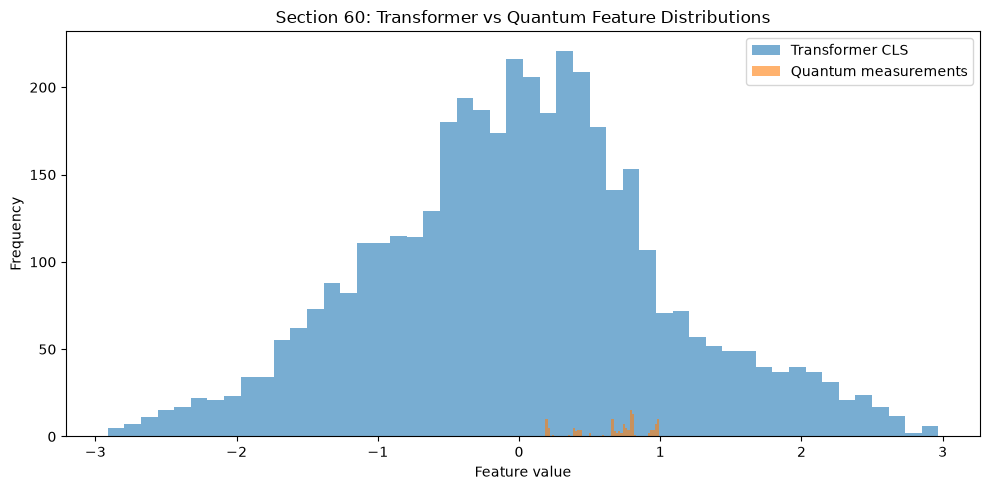

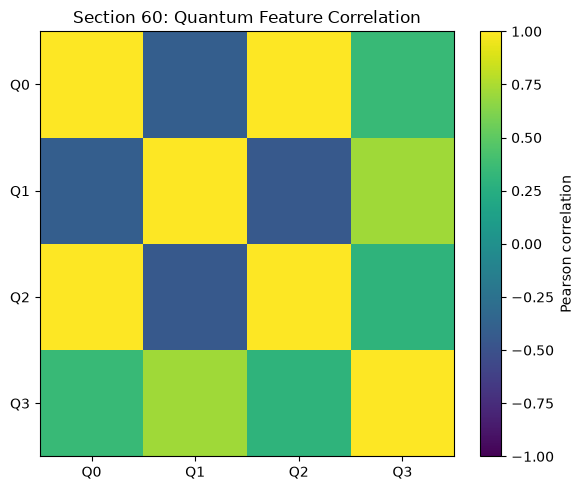

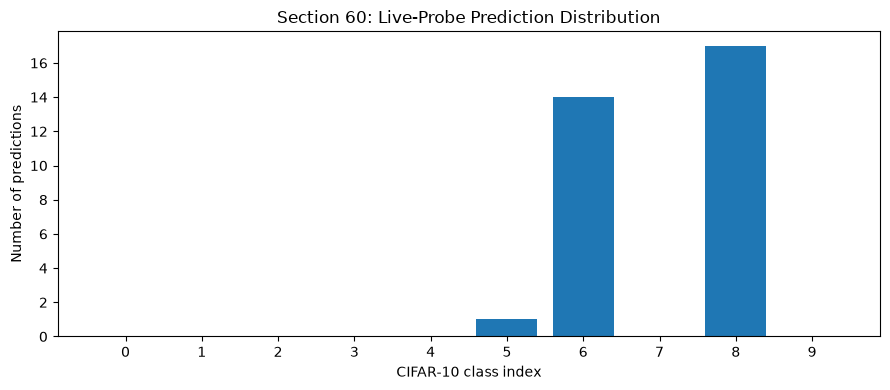


SECTION 60 COMPLETE
{
  "section": 60,
  "diagnostic_only": true,
  "device": "cpu",
  "model_type": "CorrectedHybridQuantumViT",
  "live_probe_samples": 32,
  "total_parameters": 547720,
  "trainable_parameters": 547720,
  "nonfinite_parameter_values": 0,
  "live_probe_accuracy": 0.125,
  "live_probe_balanced_accuracy": 0.2,
  "live_probe_macro_f1": 0.046405228758169936,
  "live_probe_mcc": 0.09474352282088215,
  "live_probe_mean_max_probability": 0.1302361786365509,
  "live_probe_mean_entropy": 2.27834415435791,
  "quantum_feature_dimension": 4,
  "outputs": [
    "section60_parameter_integrity.csv",
    "section60_feature_stage_statistics.csv",
    "section60_quantum_dimension_statistics.csv",
    "section60_quantum_correlation_live_probe.csv",
    "section60_live_probe_classification_report.csv",
    "section60_live_probe_confidence_summary.csv",
    "section60_live_probe_calibration_bins.csv",
    "section60_gradient_flow.csv",
    "section60_combined_historical_comparison.csv",


In [2]:
# ================================================================
# SECTION 60: HQViT BOTTLENECK & COMPREHENSIVE DIAGNOSTICS
# Corrected: model names, dtype compatibility, syntax and robustness
# ================================================================

import os
import json
import warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    f1_score,
    matthews_corrcoef
)

warnings.filterwarnings("ignore", category=UserWarning)

# ------------------------------------------------
# 60.1 — Configuration and model recovery checks
# ------------------------------------------------

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

PROJECT_DIR = Path.cwd()
RESULTS_DIR = PROJECT_DIR / "results"
MODELS_DIR = PROJECT_DIR / "models"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 78)
print("SECTION 60: HQViT BOTTLENECK & COMPREHENSIVE DIAGNOSTICS")
print("=" * 78)
print(f"Project directory : {PROJECT_DIR}")
print(f"Device            : {DEVICE}")
print(f"CUDA available    : {torch.cuda.is_available()}")

# Support common variable names from the recovery cell.
if "model" not in globals():
    if "corrected_hqvit" in globals():
        model = corrected_hqvit
    elif "corrected_model" in globals():
        model = corrected_model
    elif "hqvit_model" in globals():
        model = hqvit_model
    else:
        raise RuntimeError(
            "No recovered model variable was found. Expected one of: "
            "'model', 'corrected_hqvit', 'corrected_model', or "
            "'hqvit_model'. Run the Section 65 recovery cell and "
            "check the name of the loaded model."
        )

# Establish an alias for other notebook cells.
corrected_hqvit = model

if "validation_loader" not in globals():
    raise RuntimeError(
        "validation_loader is missing. Run Section 65 and ensure "
        "the validation DataLoader is created."
    )

if "quantum_circuit" not in globals():
    raise RuntimeError(
        "quantum_circuit is missing. Run the recovery cell that "
        "defines the PennyLane quantum circuit."
    )

if "N_QUBITS" not in globals():
    N_QUBITS = 4

if "N_Q_LAYERS" not in globals():
    N_Q_LAYERS = 2

model = model.to(DEVICE)
model.eval()

# Derive the classifier's required dtype from its parameters.
classifier_parameter = next(model.classifier.parameters())
MODEL_DTYPE = classifier_parameter.dtype
MODEL_DEVICE = classifier_parameter.device

print(f"Recovered model   : {type(model).__name__}")
print(f"Model device      : {MODEL_DEVICE}")
print(f"Model dtype       : {MODEL_DTYPE}")

# ------------------------------------------------
# 60.2 — Utility functions
# ------------------------------------------------

def save_table(df, filename):
    path = RESULTS_DIR / filename
    df.to_csv(path, index=False)
    print(f"Saved: {path}")
    return path


def safe_read_csv(filename):
    path = RESULTS_DIR / filename

    if not path.exists():
        return None

    try:
        return pd.read_csv(path)
    except Exception as exc:
        print(f"Could not read {filename}: {exc}")
        return None


def describe_tensor(tensor, name):
    x = tensor.detach().float().cpu().reshape(-1)

    return {
        "feature": name,
        "mean": float(x.mean()),
        "std": float(x.std(unbiased=False)),
        "minimum": float(x.min()),
        "maximum": float(x.max()),
        "fraction_abs_gt_0.95": float((x.abs() > 0.95).float().mean()),
        "fraction_abs_gt_0.99": float((x.abs() > 0.99).float().mean()),
        "finite_fraction": float(torch.isfinite(x).float().mean())
    }


def quantum_to_model_dtype(measurements):
    """
    Convert PennyLane output into a tensor compatible with the
    recovered classifier's device and floating-point dtype.
    """

    if isinstance(measurements, (tuple, list)):
        measurements = torch.stack([
            torch.as_tensor(value, device=MODEL_DEVICE)
            for value in measurements
        ])
    else:
        measurements = torch.as_tensor(
            measurements,
            device=MODEL_DEVICE
        )

    return measurements.to(
        device=MODEL_DEVICE,
        dtype=MODEL_DTYPE
    )


def get_quantum_features(angles):
    """
    Evaluate the quantum circuit for each sample in angles.

    Output shape: [batch_size, N_QUBITS]
    Output dtype/device: classifier-compatible.
    """

    outputs = []

    for sample in angles:
        measurement = quantum_circuit(
            sample,
            model.quantum_weights
        )

        measurement = quantum_to_model_dtype(measurement)
        outputs.append(measurement)

    return torch.stack(outputs, dim=0)


# ------------------------------------------------
# 60.3 — Existing full-validation diagnostic files
# ------------------------------------------------

print("\n" + "=" * 78)
print("60.3 — EXISTING FULL-VALIDATION DIAGNOSTICS")
print("=" * 78)

diagnostic_files = {
    "Metrics": "hqvit_corrected_diagnostic_metrics.csv",
    "Class distribution": "hqvit_corrected_class_distribution.csv",
    "Classification report": "hqvit_corrected_classification_report.csv",
    "Confidence summary": "hqvit_corrected_confidence_summary.csv",
    "Quantum feature diagnostics": "hqvit_corrected_quantum_feature_diagnostics.csv",
    "Representation statistics": "hqvit_representation_feature_stats.csv",
    "Representation probe": "hqvit_representation_probe_results.csv",
    "Quantum correlations": "hqvit_representation_quantum_correlation.csv",
    "Gradient diagnostics": "hqvit_corrected_gradient_diagnostics.csv",
    "Parameter diagnostics": "hqvit_corrected_parameter_diagnostics.csv",
    "Confusion matrix": "hqvit_corrected_confusion_matrix.csv",
    "Calibration bins": "hqvit_corrected_calibration_bins.csv",
    "History comparison": "hqvit_corrected_history_comparison.csv"
}

loaded_diagnostics = {}

for label, filename in diagnostic_files.items():
    df = safe_read_csv(filename)

    if df is not None:
        loaded_diagnostics[label] = df

        print(f"\n--- {label} ---")
        print(df.head(15).to_string(index=False))
    else:
        print(f"\nNot found: {filename}")

# ------------------------------------------------
# 60.4 — Model parameter integrity
# ------------------------------------------------

print("\n" + "=" * 78)
print("60.4 — PARAMETER INTEGRITY")
print("=" * 78)

parameter_rows = []
total_parameters = 0
trainable_parameters = 0
nonfinite_parameters = 0

for name, parameter in model.named_parameters():
    values = parameter.detach()
    total_parameters += values.numel()

    if parameter.requires_grad:
        trainable_parameters += values.numel()

    finite = bool(torch.isfinite(values).all())

    if not finite:
        nonfinite_parameters += int(
            (~torch.isfinite(values)).sum().item()
        )

    parameter_rows.append({
        "parameter": name,
        "shape": str(tuple(values.shape)),
        "parameter_count": values.numel(),
        "trainable": parameter.requires_grad,
        "finite": finite,
        "mean": float(values.float().mean()),
        "std": float(values.float().std(unbiased=False)),
        "minimum": float(values.float().min()),
        "maximum": float(values.float().max())
    })

parameter_df = pd.DataFrame(parameter_rows)

save_table(
    parameter_df,
    "section60_parameter_integrity.csv"
)

print(f"Total parameters      : {total_parameters:,}")
print(f"Trainable parameters  : {trainable_parameters:,}")
print(f"Non-finite parameters : {nonfinite_parameters:,}")

# ------------------------------------------------
# 60.5 — Historical prediction-collapse analysis
# ------------------------------------------------

print("\n" + "=" * 78)
print("60.5 — HISTORICAL PREDICTION COLLAPSE")
print("=" * 78)

class_distribution_df = loaded_diagnostics.get("Class distribution")

if class_distribution_df is not None:
    print(class_distribution_df.to_string(index=False))

    numeric_columns = class_distribution_df.select_dtypes(
        include=[np.number]
    ).columns.tolist()

    if numeric_columns:
        counts = class_distribution_df[numeric_columns[-1]].to_numpy()
        total_predictions = counts.sum()

        if total_predictions > 0:
            proportions = counts / total_predictions
            predicted_classes = int((counts > 0).sum())

            positive_proportions = proportions[proportions > 0]

            prediction_entropy = -np.sum(
                positive_proportions * np.log(positive_proportions)
            )

            print(f"\nNumber of predicted classes: {predicted_classes}")
            print(
                f"Largest predicted-class share: "
                f"{proportions.max() * 100:.2f}%"
            )
            print(
                f"Prediction distribution entropy: "
                f"{prediction_entropy:.4f}"
            )

            if predicted_classes < 10:
                print(
                    "WARNING: The historical model predicted fewer "
                    "than 10 classes. This is evidence of "
                    "prediction collapse."
                )
else:
    print("Historical class-distribution file not available.")

# ------------------------------------------------
# 60.6 — Live Transformer-to-quantum bottleneck probe
# ------------------------------------------------

print("\n" + "=" * 78)
print("60.6 — TRANSFORMER-TO-QUANTUM BOTTLENECK")
print("=" * 78)

MAX_PROBE_SAMPLES = 32

representation_batches = []
normalized_batches = []
projection_batches = []
angle_batches = []
quantum_batches = []
label_batches = []
logit_batches = []

probe_count = 0

model.eval()

with torch.no_grad():
    for batch in validation_loader:
        if probe_count >= MAX_PROBE_SAMPLES:
            break

        images, labels = batch

        remaining = MAX_PROBE_SAMPLES - probe_count

        images = images[:remaining].to(
            device=MODEL_DEVICE,
            dtype=MODEL_DTYPE
        )

        labels = labels[:remaining].to(MODEL_DEVICE)

        # Reconstruct the corrected HQViT feature path.
        tokens = model.vit.patch_embedding(images)
        tokens = tokens.flatten(2).transpose(1, 2)

        cls_tokens = model.vit.cls_token.expand(
            images.size(0), -1, -1
        )

        tokens = torch.cat((cls_tokens, tokens), dim=1)
        tokens = tokens + model.vit.pos_embedding
        tokens = model.vit.embedding_dropout(tokens)
        tokens = model.vit.transformer(tokens)

        representation = tokens[:, 0]
        normalized = model.projection_norm(representation)

        projected = model.quantum_projection(normalized)

        angles = (torch.pi / 4) * torch.tanh(projected)

        # Convert quantum measurements to classifier dtype/device.
        quantum_features = get_quantum_features(angles)

        # Explicit dtype/device safeguard.
        quantum_features = quantum_features.to(
            device=MODEL_DEVICE,
            dtype=MODEL_DTYPE
        )

        logits = model.classifier(quantum_features)

        representation_batches.append(
            representation.detach().float().cpu()
        )
        normalized_batches.append(
            normalized.detach().float().cpu()
        )
        projection_batches.append(
            projected.detach().float().cpu()
        )
        angle_batches.append(
            angles.detach().float().cpu()
        )
        quantum_batches.append(
            quantum_features.detach().float().cpu()
        )
        label_batches.append(labels.detach().cpu())
        logit_batches.append(
            logits.detach().float().cpu()
        )

        probe_count += len(images)

        print(
            f"Processed probe batch: {probe_count}/"
            f"{MAX_PROBE_SAMPLES}"
        )

if probe_count == 0:
    raise RuntimeError(
        "No validation samples were processed. "
        "Check validation_loader."
    )

representations = torch.cat(representation_batches)
normalized_representations = torch.cat(normalized_batches)
projections = torch.cat(projection_batches)
encoded_angles = torch.cat(angle_batches)
quantum_features = torch.cat(quantum_batches)
probe_labels = torch.cat(label_batches)
probe_logits = torch.cat(logit_batches)

probe_predictions = probe_logits.argmax(dim=1)

print(f"\nLive probe samples       : {probe_count}")
print(f"Transformer features     : {tuple(representations.shape)}")
print(f"Normalized representation: {tuple(normalized_representations.shape)}")
print(f"Raw projection           : {tuple(projections.shape)}")
print(f"Encoded angles           : {tuple(encoded_angles.shape)}")
print(f"Quantum features         : {tuple(quantum_features.shape)}")
print(f"Classifier logits        : {tuple(probe_logits.shape)}")

# ------------------------------------------------
# 60.7 — Feature-stage statistics
# ------------------------------------------------

print("\n" + "=" * 78)
print("60.7 — FEATURE-STAGE STATISTICS")
print("=" * 78)

feature_statistics = []

stages = [
    ("transformer_cls", representations),
    ("normalized_cls", normalized_representations),
    ("raw_quantum_projection", projections),
    ("encoded_quantum_angles", encoded_angles),
    ("quantum_measurements", quantum_features),
    ("classifier_logits", probe_logits)
]

for stage_name, tensor in stages:
    row = describe_tensor(tensor, stage_name)
    feature_statistics.append(row)

    print(
        f"{stage_name:28s} | "
        f"mean={row['mean']:+.5f} | "
        f"std={row['std']:.5f} | "
        f"range=[{row['minimum']:+.4f}, "
        f"{row['maximum']:+.4f}] | "
        f"finite={row['finite_fraction']:.3f}"
    )

quantum_dimension_rows = []

for dimension in range(quantum_features.shape[1]):
    row = describe_tensor(
        quantum_features[:, dimension],
        f"quantum_feature_{dimension}"
    )
    quantum_dimension_rows.append(row)

quantum_dimension_df = pd.DataFrame(quantum_dimension_rows)

print("\nPer-quantum-feature statistics:")
print(quantum_dimension_df.to_string(index=False))

save_table(
    pd.DataFrame(feature_statistics),
    "section60_feature_stage_statistics.csv"
)

save_table(
    quantum_dimension_df,
    "section60_quantum_dimension_statistics.csv"
)

# ------------------------------------------------
# 60.8 — Quantum-feature correlation and redundancy
# ------------------------------------------------

print("\n" + "=" * 78)
print("60.8 — QUANTUM FEATURE CORRELATION")
print("=" * 78)

quantum_array = quantum_features.numpy()

if quantum_array.shape[0] > 1:
    correlation_matrix = np.corrcoef(
        quantum_array,
        rowvar=False
    )

    correlation_df = pd.DataFrame(
        correlation_matrix,
        index=[f"Q{i}" for i in range(quantum_array.shape[1])],
        columns=[f"Q{i}" for i in range(quantum_array.shape[1])]
    )

    print(correlation_df.round(4).to_string())

    save_table(
        correlation_df.rename_axis("quantum_feature").reset_index(),
        "section60_quantum_correlation_live_probe.csv"
    )

    off_diagonal = correlation_matrix[
        ~np.eye(correlation_matrix.shape[0], dtype=bool)
    ]

    if len(off_diagonal):
        print(
            "\nMean absolute off-diagonal correlation: "
            f"{np.nanmean(np.abs(off_diagonal)):.4f}"
        )
else:
    correlation_matrix = None
    print("Insufficient samples for correlation analysis.")

# ------------------------------------------------
# 60.9 — Small-probe classification performance
# ------------------------------------------------

print("\n" + "=" * 78)
print("60.9 — LIVE PROBE CLASSIFICATION PERFORMANCE")
print("=" * 78)

y_true = probe_labels.numpy()
y_pred = probe_predictions.numpy()

probe_accuracy = accuracy_score(y_true, y_pred)
probe_balanced_accuracy = balanced_accuracy_score(y_true, y_pred)

probe_macro_f1 = f1_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

probe_mcc = matthews_corrcoef(y_true, y_pred)

print(f"Probe accuracy          : {probe_accuracy:.4f}")
print(f"Probe balanced accuracy : {probe_balanced_accuracy:.4f}")
print(f"Probe macro F1           : {probe_macro_f1:.4f}")
print(f"Probe MCC                : {probe_mcc:.4f}")

print("\nProbe prediction counts:")
print(
    pd.Series(y_pred)
    .value_counts()
    .sort_index()
    .to_string()
)

print("\nProbe classification report:")

print(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(10)),
        zero_division=0,
        digits=4
    )
)

probe_report = classification_report(
    y_true,
    y_pred,
    labels=list(range(10)),
    output_dict=True,
    zero_division=0
)

save_table(
    pd.DataFrame(probe_report).transpose().rename_axis(
        "class_or_metric"
    ).reset_index(),
    "section60_live_probe_classification_report.csv"
)

# ------------------------------------------------
# 60.10 — Confidence, uncertainty and calibration
# ------------------------------------------------

print("\n" + "=" * 78)
print("60.10 — CONFIDENCE AND UNCERTAINTY")
print("=" * 78)

probabilities = torch.softmax(probe_logits, dim=1)

max_confidence, _ = probabilities.max(dim=1)

entropy = -(
    probabilities
    * torch.log(probabilities.clamp_min(1e-12))
).sum(dim=1)

correct_mask = (
    probe_predictions == probe_labels
)

confidence_summary = pd.DataFrame([{
    "sample_count": int(len(probe_labels)),
    "mean_max_probability": float(max_confidence.mean()),
    "median_max_probability": float(max_confidence.median()),
    "mean_entropy": float(entropy.mean()),
    "maximum_entropy_for_10_classes": float(np.log(10)),
    "probe_accuracy": float(correct_mask.float().mean()),
    "mean_confidence_correct": (
        float(max_confidence[correct_mask].mean())
        if correct_mask.any() else np.nan
    ),
    "mean_confidence_incorrect": (
        float(max_confidence[~correct_mask].mean())
        if (~correct_mask).any() else np.nan
    )
}])

print(confidence_summary.to_string(index=False))

save_table(
    confidence_summary,
    "section60_live_probe_confidence_summary.csv"
)

# Ten-bin reliability summary for the small probe.
bin_rows = []
bin_edges = np.linspace(0.0, 1.0, 11)

confidence_np = max_confidence.numpy()
correct_np = correct_mask.float().numpy()

for lower, upper in zip(bin_edges[:-1], bin_edges[1:]):
    if upper == 1.0:
        mask = (
            (confidence_np >= lower)
            & (confidence_np <= upper)
        )
    else:
        mask = (
            (confidence_np >= lower)
            & (confidence_np < upper)
        )

    if mask.any():
        bin_rows.append({
            "lower_confidence": lower,
            "upper_confidence": upper,
            "count": int(mask.sum()),
            "mean_confidence": float(confidence_np[mask].mean()),
            "accuracy": float(correct_np[mask].mean())
        })

live_calibration_df = pd.DataFrame(bin_rows)

print("\nLive-probe reliability bins:")

if not live_calibration_df.empty:
    print(live_calibration_df.to_string(index=False))
else:
    print("No populated calibration bins.")

save_table(
    live_calibration_df,
    "section60_live_probe_calibration_bins.csv"
)

# ------------------------------------------------
# 60.11 — Gradient-flow diagnostic
# ------------------------------------------------

print("\n" + "=" * 78)
print("60.11 — GRADIENT FLOW")
print("=" * 78)

# Backpropagation is used only to inspect gradients.
# No optimizer is created or stepped; model weights are not updated.

model.eval()
model.zero_grad(set_to_none=True)

gradient_rows = []

try:
    first_batch = next(iter(validation_loader))

    gradient_images, gradient_labels = first_batch

    gradient_images = gradient_images[:2].to(
        device=MODEL_DEVICE,
        dtype=MODEL_DTYPE
    )

    gradient_labels = gradient_labels[:2].to(MODEL_DEVICE)

    with torch.enable_grad():
        gradient_logits = model(gradient_images)

        gradient_loss = nn.CrossEntropyLoss()(
            gradient_logits,
            gradient_labels
        )

        gradient_loss.backward()

    for name, parameter in model.named_parameters():
        if not parameter.requires_grad:
            continue

        if parameter.grad is None:
            gradient_rows.append({
                "parameter": name,
                "gradient_present": False,
                "gradient_finite": False,
                "gradient_norm": np.nan,
                "gradient_mean_abs": np.nan
            })
        else:
            grad = parameter.grad.detach()

            gradient_rows.append({
                "parameter": name,
                "gradient_present": True,
                "gradient_finite": bool(torch.isfinite(grad).all()),
                "gradient_norm": float(grad.norm()),
                "gradient_mean_abs": float(grad.abs().mean())
            })

    gradient_df = pd.DataFrame(gradient_rows)

    print(gradient_df.to_string(index=False))

    print(
        "\nParameters with gradients: "
        f"{int(gradient_df['gradient_present'].sum())}"
        f"/{len(gradient_df)}"
    )

    print(
        "Parameters with non-finite gradients: "
        f"{int((~gradient_df['gradient_finite']).sum())}"
    )

    save_table(
        gradient_df,
        "section60_gradient_flow.csv"
    )

except Exception as exc:
    print("Gradient diagnostic failed:", repr(exc))

    print(
        "The forward-pass and feature diagnostics may still be valid. "
        "Inspect the exception to determine whether the issue is "
        "related to PennyLane autograd or the model implementation."
    )

finally:
    model.zero_grad(set_to_none=True)
    model.eval()

# ------------------------------------------------
# 60.12 — Historical full-validation metrics
# ------------------------------------------------

print("\n" + "=" * 78)
print("60.12 — HISTORICAL FULL-VALIDATION PERFORMANCE")
print("=" * 78)

metrics_df = loaded_diagnostics.get("Metrics")

if metrics_df is not None:
    print(metrics_df.to_string(index=False))
else:
    print(
        "The full-validation metrics CSV was not found. "
        "Other saved diagnostic tables may still contain useful results."
    )

print(
    "\nIMPORTANT: The live probe processes only a small number of "
    "validation samples. Its accuracy is not a replacement for "
    "the historical full-validation result."
)

# ------------------------------------------------
# 60.13 — Existing CNN, ViT and HQViT comparisons
# ------------------------------------------------

print("\n" + "=" * 78)
print("60.13 — EXISTING MODEL COMPARISON")
print("=" * 78)

comparison_files = [
    "cnn_data_efficiency_comparison.csv",
    "vit_data_efficiency_comparison.csv",
    "hqvit_corrected_history_comparison.csv",
    "hqvit_corrected_history_10pct.csv"
]

comparison_frames = []

for filename in comparison_files:
    df = safe_read_csv(filename)

    if df is not None:
        print(f"\n--- {filename} ---")
        print(df.head(20).to_string(index=False))

        df_copy = df.copy()
        df_copy.insert(0, "source_file", filename)

        comparison_frames.append(df_copy)

if comparison_frames:
    combined_comparison = pd.concat(
        comparison_frames,
        ignore_index=True,
        sort=False
    )

    save_table(
        combined_comparison,
        "section60_combined_historical_comparison.csv"
    )
else:
    combined_comparison = None
    print("No comparison tables were found.")

print(
    "\nCOMPARISON CAUTION: Existing CNN, ViT and HQViT experiments "
    "used different data fractions and/or training durations. "
    "Their historical metrics are not a controlled head-to-head benchmark."
)

# ------------------------------------------------
# 60.14 — Consolidated bottleneck summary
# ------------------------------------------------

print("\n" + "=" * 78)
print("60.14 — BOTTLENECK SUMMARY")
print("=" * 78)

bottleneck_rows = []

def add_finding(category, observation, interpretation, evidence_strength):
    bottleneck_rows.append({
        "category": category,
        "observation": observation,
        "interpretation": interpretation,
        "evidence_strength": evidence_strength
    })


add_finding(
    "Numerical integrity",
    f"{nonfinite_parameters} non-finite parameter values found.",
    (
        "Model parameters are numerically finite."
        if nonfinite_parameters == 0
        else "Investigate non-finite parameters before further evaluation."
    ),
    "Direct parameter check"
)

add_finding(
    "Transformer-to-quantum mapping",
    "The live probe measured feature statistics at the Transformer, "
    "projection, angle-encoding and quantum-output stages.",
    "Compare the variability and information retained at each stage.",
    "Small-sample exploratory probe"
)

if correlation_matrix is not None and correlation_matrix.size > 1:
    off_diagonal = correlation_matrix[
        ~np.eye(correlation_matrix.shape[0], dtype=bool)
    ]

    mean_abs_corr = float(np.nanmean(np.abs(off_diagonal)))

    add_finding(
        "Quantum-feature redundancy",
        f"Mean absolute off-diagonal quantum correlation: {mean_abs_corr:.4f}.",
        (
            "Large correlations may indicate redundant quantum measurements."
            if mean_abs_corr > 0.8
            else "Inspect individual correlations for potentially redundant outputs."
        ),
        "Small-sample exploratory probe"
    )

if class_distribution_df is not None:
    add_finding(
        "Historical class collapse",
        "A historical full-validation class-distribution table was found.",
        "Use predicted-class coverage and class-wise recall to assess "
        "whether the model disproportionately predicts a small subset of classes.",
        "Saved historical diagnostic"
    )

if "Representation probe" in loaded_diagnostics:
    print("\nHistorical representation-probe results:")
    print(
        loaded_diagnostics["Representation probe"].to_string(index=False)
    )

    add_finding(
        "Representation bottleneck",
        "Historical frozen linear-probe results are available.",
        "Compare Transformer CLS performance with quantum-feature performance. "
        "A lower quantum-feature score is consistent with information loss "
        "at the quantum mapping stage, although the probe alone does not "
        "establish causality.",
        "Saved exploratory validation diagnostic"
    )

add_finding(
    "Training budget",
    "The corrected HQViT historical experiment used 10% of the training pool "
    "for three epochs.",
    "Poor performance may reflect optimization, training budget, "
    "representation quality or architecture. More evidence is needed "
    "before attributing the result to the quantum circuit alone.",
    "Historical experiment configuration"
)

bottleneck_df = pd.DataFrame(bottleneck_rows)

print("\nConsolidated findings:")
print(bottleneck_df.to_string(index=False))

save_table(
    bottleneck_df,
    "section60_bottleneck_summary.csv"
)

# ------------------------------------------------
# 60.15 — Diagnostic plots
# ------------------------------------------------

print("\n" + "=" * 78)
print("60.15 — DIAGNOSTIC PLOTS")
print("=" * 78)

# Plot A: Transformer and quantum feature distributions.
plt.figure(figsize=(10, 5))

plt.hist(
    representations.numpy().reshape(-1),
    bins=50,
    alpha=0.6,
    label="Transformer CLS"
)

plt.hist(
    quantum_features.numpy().reshape(-1),
    bins=50,
    alpha=0.6,
    label="Quantum measurements"
)

plt.title("Section 60: Transformer vs Quantum Feature Distributions")
plt.xlabel("Feature value")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "section60_feature_distribution.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# Plot B: Quantum correlation matrix.
if correlation_matrix is not None:
    plt.figure(figsize=(6, 5))

    plt.imshow(
        correlation_matrix,
        aspect="auto",
        vmin=-1,
        vmax=1
    )

    plt.colorbar(label="Pearson correlation")

    plt.xticks(
        range(quantum_features.shape[1]),
        [f"Q{i}" for i in range(quantum_features.shape[1])]
    )

    plt.yticks(
        range(quantum_features.shape[1]),
        [f"Q{i}" for i in range(quantum_features.shape[1])]
    )

    plt.title("Section 60: Quantum Feature Correlation")
    plt.tight_layout()

    plt.savefig(
        RESULTS_DIR / "section60_quantum_correlation.png",
        dpi=160,
        bbox_inches="tight"
    )

    plt.show()

# Plot C: Live-probe predicted class counts.
live_counts = np.bincount(y_pred, minlength=10)

plt.figure(figsize=(9, 4))
plt.bar(range(10), live_counts)
plt.xticks(range(10))
plt.xlabel("CIFAR-10 class index")
plt.ylabel("Number of predictions")
plt.title("Section 60: Live-Probe Prediction Distribution")
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "section60_live_prediction_distribution.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------
# 60.16 — Save the comprehensive diagnostic report
# ------------------------------------------------

report = {
    "section": 60,
    "diagnostic_only": True,
    "device": str(DEVICE),
    "model_type": type(model).__name__,
    "live_probe_samples": int(probe_count),
    "total_parameters": int(total_parameters),
    "trainable_parameters": int(trainable_parameters),
    "nonfinite_parameter_values": int(nonfinite_parameters),
    "live_probe_accuracy": float(probe_accuracy),
    "live_probe_balanced_accuracy": float(probe_balanced_accuracy),
    "live_probe_macro_f1": float(probe_macro_f1),
    "live_probe_mcc": float(probe_mcc),
    "live_probe_mean_max_probability": float(max_confidence.mean()),
    "live_probe_mean_entropy": float(entropy.mean()),
    "quantum_feature_dimension": int(quantum_features.shape[1]),
    "outputs": [
        "section60_parameter_integrity.csv",
        "section60_feature_stage_statistics.csv",
        "section60_quantum_dimension_statistics.csv",
        "section60_quantum_correlation_live_probe.csv",
        "section60_live_probe_classification_report.csv",
        "section60_live_probe_confidence_summary.csv",
        "section60_live_probe_calibration_bins.csv",
        "section60_gradient_flow.csv",
        "section60_combined_historical_comparison.csv",
        "section60_bottleneck_summary.csv",
        "section60_feature_distribution.png",
        "section60_quantum_correlation.png",
        "section60_live_prediction_distribution.png"
    ]
}

report_path = RESULTS_DIR / "section60_comprehensive_report.json"

with open(report_path, "w", encoding="utf-8") as file:
    json.dump(report, file, indent=2)

print("\n" + "=" * 78)
print("SECTION 60 COMPLETE")
print("=" * 78)

print(json.dumps(report, indent=2))

print("\nInterpretation priorities:")
print("1. Compare Transformer CLS and quantum-feature probe results.")
print("2. Inspect quantum-feature variance and correlations.")
print("3. Inspect full-validation class counts and per-class recall.")
print("4. Verify that gradients are present, finite and nonzero.")
print("5. Treat the live probe as exploratory, not a final test result.")
print("6. Compare CNN, ViT and HQViT only with training-budget caveats.")

print("\nNo optimizer step or model training was performed.")
print(f"Comprehensive report saved to: {report_path}")

Section 61: Full-Validation Representation and Quantum Redundancy Audit

Objective: Investigate quantum-feature redundancy, representation quality, and class-prediction collapse using the existing corrected HQViT checkpoint.

Method: Run inference on the full validation loader, collect intermediate representations using forward hooks, calculate feature correlations and descriptive statistics, and compare frozen linear probes using a held-out split of the validation representations.

Restrictions:

- No model training or optimizer steps.
- No parameter updates.
- No checkpoint overwriting.
- No changes to Sections 60 or 65.
- Save all results with the "section61_" prefix.

Interpretation note: Results are diagnostic because the validation data has been used in previous experiments. They are not independent test-set estimates.

In [6]:
# SECTION 61 — Full-Validation Representation and Quantum Redundancy Audit
# No HQViT training. No checkpoint modification.

from pathlib import Path
import json
import numpy as np
import pandas as pd
import torch

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score

audit_model.eval()

device = next(audit_model.parameters()).device

cls_batches = []
quantum_batches = []
label_batches = []

captured = {"transformer": [], "quantum": []}

def _capture_transformer(module, inputs, output):
    captured["transformer"].append(output.detach())

def _capture_quantum(module, inputs, output):
    # This is the 4-dimensional input to the quantum circuit.
    captured["quantum"].append(output.detach())

handles = [
    audit_model.vit.transformer.register_forward_hook(_capture_transformer),
    audit_model.quantum_projection.register_forward_hook(_capture_quantum),
]

try:
    with torch.inference_mode():
        for images, labels in validation_loader:
            captured["transformer"].clear()
            captured["quantum"].clear()

            images = images.to(device)
            _ = audit_model(images)

            if len(captured["transformer"]) != 1:
                raise RuntimeError(
                    f"Expected one transformer capture per batch; "
                    f"got {len(captured['transformer'])}."
                )

            if len(captured["quantum"]) != 1:
                raise RuntimeError(
                    f"Expected one quantum-projection capture per batch; "
                    f"got {len(captured['quantum'])}."
                )

            transformer_output = captured["transformer"][0]
            projected = captured["quantum"][0]

            # Verified shape: [batch, tokens, embedding_dim].
            cls_features = transformer_output[:, 0, :]

            cls_batches.append(cls_features.cpu().numpy())
            quantum_batches.append(projected.cpu().numpy())
            label_batches.append(labels.cpu().numpy())

finally:
    for handle in handles:
        handle.remove()

X_cls = np.concatenate(cls_batches, axis=0)
X_projected = np.concatenate(quantum_batches, axis=0)
y_val = np.concatenate(label_batches, axis=0)

print("Validation samples:", len(y_val))
print("CLS features:", X_cls.shape)
print("Projected features:", X_projected.shape)

assert len(X_cls) == len(X_projected) == len(y_val)
assert np.isfinite(X_cls).all()
assert np.isfinite(X_projected).all()

# ---------- 1. Projection-feature statistics ----------
projection_stats = pd.DataFrame({
    "feature": [f"projection_{i}" for i in range(X_projected.shape[1])],
    "mean": X_projected.mean(axis=0),
    "std": X_projected.std(axis=0),
    "min": X_projected.min(axis=0),
    "max": X_projected.max(axis=0),
})

# ---------- 2. Correlation and redundancy ----------
corr = np.corrcoef(X_projected, rowvar=False)

correlation_df = pd.DataFrame(
    corr,
    index=[f"projection_{i}" for i in range(X_projected.shape[1])],
    columns=[f"projection_{i}" for i in range(X_projected.shape[1])],
)

off_diagonal = corr[~np.eye(corr.shape[0], dtype=bool)]
mean_abs_correlation = float(np.mean(np.abs(off_diagonal)))

# ---------- 3. Frozen representation probes ----------
# These probes are exploratory. They use validation labels and are NOT
# independent test-set performance estimates.
probe_results = []

class_counts = np.unique(y_val, return_counts=True)[1]
n_splits = min(5, int(class_counts.min()))

if n_splits >= 2:
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

    for name, X in [
        ("Transformer CLS representation", X_cls),
        ("Four-dimensional projection input", X_projected),
    ]:
        probe = make_pipeline(
            StandardScaler(),
            LogisticRegression(
                max_iter=1000,
                random_state=42,
                class_weight="balanced",
            ),
        )

        scores = cross_val_score(
            probe, X, y_val, cv=cv, scoring="accuracy", n_jobs=1
        )

        probe_results.append({
            "representation": name,
            "samples": len(y_val),
            "feature_dimension": X.shape[1],
            "cv_accuracy_mean": float(scores.mean()),
            "cv_accuracy_std": float(scores.std()),
            "cv_folds": n_splits,
        })
else:
    print(
        "Skipping cross-validation: at least one validation class "
        "has fewer than two samples."
    )

probe_df = pd.DataFrame(probe_results)

# ---------- 4. Save outputs ----------
results_dir = Path("results")
results_dir.mkdir(parents=True, exist_ok=True)

projection_stats.to_csv(
    results_dir / "section61_projection_feature_statistics.csv",
    index=False,
)
correlation_df.to_csv(
    results_dir / "section61_quantum_correlation.csv",
)
probe_df.to_csv(
    results_dir / "section61_linear_probe_comparison.csv",
    index=False,
)

report = {
    "section": 61,
    "diagnostic_only": True,
    "hqvit_training_performed": False,
    "checkpoint_modified": False,
    "validation_samples": int(len(y_val)),
    "transformer_cls_dimension": int(X_cls.shape[1]),
    "projection_dimension": int(X_projected.shape[1]),
    "projection_mean_absolute_off_diagonal_correlation":
        mean_abs_correlation,
    "projection_features_finite": bool(np.isfinite(X_projected).all()),
    "transformer_features_finite": bool(np.isfinite(X_cls).all()),
    "probe_results": probe_results,
    "interpretation_note": (
        "The four-dimensional features captured here are the input "
        "to the quantum circuit, not its final quantum measurements. "
        "Probe results are exploratory because validation labels are used."
    ),
}

with open(
    results_dir / "section61_comprehensive_report.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(report, f, indent=2)

print("\nSECTION 61 COMPLETE")
print(json.dumps(report, indent=2))
print("\nProjection statistics:")
display(projection_stats)
print("\nFeature correlation:")
display(correlation_df)
print("\nFrozen representation probes:")
display(probe_df)

Validation samples: 5000
CLS features: (5000, 128)
Projected features: (5000, 4)

SECTION 61 COMPLETE
{
  "section": 61,
  "diagnostic_only": true,
  "hqvit_training_performed": false,
  "checkpoint_modified": false,
  "validation_samples": 5000,
  "transformer_cls_dimension": 128,
  "projection_dimension": 4,
  "projection_mean_absolute_off_diagonal_correlation": 0.568288629243516,
  "projection_features_finite": true,
  "transformer_features_finite": true,
  "probe_results": [
    {
      "representation": "Transformer CLS representation",
      "samples": 5000,
      "feature_dimension": 128,
      "cv_accuracy_mean": 0.2476,
      "cv_accuracy_std": 0.015054567413247056,
      "cv_folds": 5
    },
    {
      "representation": "Four-dimensional projection input",
      "samples": 5000,
      "feature_dimension": 4,
      "cv_accuracy_mean": 0.2004,
      "cv_accuracy_std": 0.008546344247688593,
      "cv_folds": 5
    }
  ],
  "interpretation_note": "The four-dimensional features c

,feature,mean,std,min,max
0,projection_0,-1.489092,1.615638,-3.247820,2.122821
1,projection_1,-3.079775,1.959758,-5.513463,1.857101
2,projection_2,-1.252876,1.325755,-3.120206,0.897597
3,projection_3,3.099938,0.938948,-2.118138,4.602204



Feature correlation:


,projection_0,projection_1,projection_2,projection_3
projection_0,1.000000,-0.809455,0.988087,-0.251577
projection_1,-0.809455,1.000000,-0.869536,-0.361774
projection_2,0.988087,-0.869536,1.000000,-0.129303
projection_3,-0.251577,-0.361774,-0.129303,1.000000



Frozen representation probes:


,representation,samples,feature_dimension,cv_accuracy_mean,cv_accuracy_std,cv_folds
0,Transformer CLS representation,5000,128,0.2476,0.015055,5
1,Four-dimensional projection input,5000,4,0.2004,0.008546,5


In [7]:
import inspect

print(inspect.getsource(type(audit_model).forward))

    def forward(self, images):
        tokens = self.vit.patch_embedding(images)
        tokens = tokens.flatten(2).transpose(1, 2)

        cls_tokens = self.vit.cls_token.expand(
            images.size(0), -1, -1
        )

        tokens = torch.cat((cls_tokens, tokens), dim=1)
        tokens = tokens + self.vit.pos_embedding
        tokens = self.vit.embedding_dropout(tokens)
        tokens = self.vit.transformer(tokens)

        representation = self.projection_norm(tokens[:, 0])

        projected = self.quantum_projection(representation)
        quantum_inputs = (torch.pi / 4) * torch.tanh(projected)

        quantum_rows = []

        for sample in quantum_inputs:
            measurements = quantum_circuit(
                sample,
                self.quantum_weights,
            )

            if isinstance(measurements, (tuple, list)):
                measurements = torch.stack([
                    torch.as_tensor(
                        value,
                        devi

In [10]:
# ============================================================
# SECTION 62 — QUANTUM OUTPUT AND INFORMATION-RETENTION AUDIT
#
# Purpose:
#   1. Capture transformer CLS representations.
#   2. Capture projected features and bounded quantum inputs.
#   3. Capture actual quantum-circuit measurements.
#   4. Compare correlations and feature statistics.
#   5. Compare exploratory frozen linear probes.
#
# No HQViT training.
# No optimizer steps.
# No checkpoint modification.
# ============================================================

import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import torch

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score


# ------------------------------------------------------------
# 1. Validate model and initialize storage
# ------------------------------------------------------------

if "audit_model" not in globals():
    raise RuntimeError(
        "audit_model is missing. Restore the corrected HQViT "
        "model before running Section 62."
    )

if "validation_loader" not in globals():
    raise RuntimeError(
        "validation_loader is missing. Restore the validation loader."
    )

audit_model.eval()
device = next(audit_model.parameters()).device

print("Model:", type(audit_model).__name__)
print("Device:", device)
print("Training enabled:", audit_model.training)

# IMPORTANT: initialize all lists as empty lists.
# Do not assign None to cls_batches.
cls_batches = []
projection_batches = []
qinput_batches = []
qoutput_batches = []
label_batches = []

captured = {
    "transformer": [],
    "projection": [],
}


# ------------------------------------------------------------
# 2. Locate the quantum circuit used by model.forward()
# ------------------------------------------------------------

model_module = sys.modules[type(audit_model).__module__]

if not hasattr(model_module, "quantum_circuit"):
    raise RuntimeError(
        "Could not find quantum_circuit in the model's defining "
        "module. No inference was performed. Inspect the model "
        "module before proceeding."
    )

original_module_circuit = model_module.quantum_circuit

if not callable(original_module_circuit):
    raise RuntimeError(
        "The model module's quantum_circuit is not callable."
    )

if not callable(quantum_circuit):
    raise RuntimeError(
        "The notebook-level quantum_circuit reference is not callable."
    )

print("Quantum circuit located successfully.")


# ------------------------------------------------------------
# 3. Register feature hooks
# ------------------------------------------------------------

def capture_transformer(module, inputs, output):
    captured["transformer"].append(output.detach().cpu())


def capture_projection(module, inputs, output):
    captured["projection"].append(output.detach().cpu())


handles = [
    audit_model.vit.transformer.register_forward_hook(
        capture_transformer
    ),
    audit_model.quantum_projection.register_forward_hook(
        capture_projection
    ),
]


# ------------------------------------------------------------
# 4. Capture actual circuit inputs and measurements
# ------------------------------------------------------------

def capture_quantum_circuit(inputs, weights):
    # Execute the original circuit.
    result = original_module_circuit(inputs, weights)

    # Convert returned measurements into a one-dimensional NumPy array
    # for diagnostic storage. Preserve the original result for the model.
    if isinstance(result, (tuple, list)):
        measurement_values = []

        for value in result:
            if torch.is_tensor(value):
                measurement_values.append(
                    value.detach().cpu().numpy()
                )
            else:
                measurement_values.append(np.asarray(value))

        measurement_array = np.asarray(measurement_values)

    elif torch.is_tensor(result):
        measurement_array = result.detach().cpu().numpy()

    else:
        measurement_array = np.asarray(result)

    input_array = (
        inputs.detach().cpu().numpy()
        if torch.is_tensor(inputs)
        else np.asarray(inputs)
    )

    captured["quantum_outputs"].append(
        np.asarray(measurement_array).reshape(-1)
    )

    captured["quantum_inputs"].append(
        np.asarray(input_array).reshape(-1)
    )

    # Return the untouched original result to model.forward().
    return result


# This dictionary is separate from the per-batch module-hook storage.
captured["quantum_inputs"] = []
captured["quantum_outputs"] = []

model_module.quantum_circuit = capture_quantum_circuit

# ------------------------------------------------------------
# 5. Run validation inference
# ------------------------------------------------------------

try:
    with torch.inference_mode():
        for batch_index, (images, labels) in enumerate(validation_loader):

            # Clear per-batch hook outputs.
            captured["transformer"].clear()
            captured["projection"].clear()

            # Record where the circuit capture starts for this batch.
            q_start = len(captured["quantum_outputs"])

            images = images.to(device)

            # Inference only.
            _ = audit_model(images)

            batch_size = images.shape[0]

            # Confirm module hooks fired exactly once.
            if len(captured["transformer"]) != 1:
                raise RuntimeError(
                    f"Batch {batch_index}: expected one transformer "
                    f"capture, got {len(captured['transformer'])}."
                )

            if len(captured["projection"]) != 1:
                raise RuntimeError(
                    f"Batch {batch_index}: expected one projection "
                    f"capture, got {len(captured['projection'])}."
                )

            # Read transformer output.
            transformer_output = captured["transformer"][0]

            # Verified architecture: [batch, tokens, embedding_dim].
            if transformer_output.ndim != 3:
                raise RuntimeError(
                    "Unexpected transformer tensor shape: "
                    f"{tuple(transformer_output.shape)}"
                )

            if transformer_output.shape[0] != batch_size:
                raise RuntimeError(
                    "Transformer batch dimension does not match images."
                )

            # CLS token is token index 0.
            cls_features = transformer_output[:, 0, :]

            # Unbounded 4D projection before tanh scaling.
            projection_output = captured["projection"][0]

            # The forward method applies:
            # quantum_inputs = (pi / 4) * tanh(projected)
            # Captured circuit inputs are the actual bounded angles.
            q_end = len(captured["quantum_outputs"])

            batch_quantum_outputs = captured[
                "quantum_outputs"
            ][q_start:q_end]

            batch_quantum_inputs = captured[
                "quantum_inputs"
            ][q_start:q_end]

            if len(batch_quantum_outputs) != batch_size:
                raise RuntimeError(
                    f"Batch {batch_index}: expected {batch_size} "
                    f"quantum measurement vectors, got "
                    f"{len(batch_quantum_outputs)}."
                )

            if len(batch_quantum_inputs) != batch_size:
                raise RuntimeError(
                    f"Batch {batch_index}: expected {batch_size} "
                    f"quantum input vectors, got "
                    f"{len(batch_quantum_inputs)}."
                )

            quantum_batch = np.stack(
                batch_quantum_outputs,
                axis=0,
            )

            quantum_input_batch = np.stack(
                batch_quantum_inputs,
                axis=0,
            )

            if quantum_batch.ndim != 2:
                raise RuntimeError(
                    "Expected quantum outputs with shape "
                    f"[batch, measurements], got {quantum_batch.shape}."
                )

            if quantum_input_batch.ndim != 2:
                raise RuntimeError(
                    "Expected quantum inputs with shape "
                    f"[batch, qubits], got {quantum_input_batch.shape}."
                )

            # Accumulate arrays. All five lists were initialized above.
            cls_batches.append(cls_features.numpy())
            projection_batches.append(projection_output.numpy())
            qinput_batches.append(quantum_input_batch)
            qoutput_batches.append(quantum_batch)
            label_batches.append(labels.cpu().numpy())

            if (batch_index + 1) % 10 == 0:
                print(
                    f"Processed {batch_index + 1} validation batches."
                )

finally:
    # Always remove hooks and restore the original circuit reference.
    for handle in handles:
        handle.remove()

    model_module.quantum_circuit = original_module_circuit


# ------------------------------------------------------------
# 6. Consolidate and validate representations
# ------------------------------------------------------------

if not cls_batches:
    raise RuntimeError(
        "No validation representations were captured. "
        "Check the model and validation loader."
    )

X_cls = np.concatenate(cls_batches, axis=0)
X_projection = np.concatenate(projection_batches, axis=0)
X_quantum_inputs = np.concatenate(qinput_batches, axis=0)
X_quantum = np.concatenate(qoutput_batches, axis=0)
y_val = np.concatenate(label_batches, axis=0)

print("\nCaptured representations:")
print("Validation labels:", y_val.shape)
print("Transformer CLS:", X_cls.shape)
print("Projection features:", X_projection.shape)
print("Bounded quantum inputs:", X_quantum_inputs.shape)
print("Actual quantum measurements:", X_quantum.shape)

n_samples = len(y_val)

for name, array in [
    ("Transformer CLS", X_cls),
    ("Projection", X_projection),
    ("Quantum inputs", X_quantum_inputs),
    ("Quantum measurements", X_quantum),
]:
    if array.shape[0] != n_samples:
        raise RuntimeError(
            f"{name} has {array.shape[0]} samples, "
            f"but labels contain {n_samples}."
        )

    if not np.isfinite(array).all():
        raise RuntimeError(
            f"{name} contains NaN or infinite values."
        )


# ------------------------------------------------------------
# 7. Feature statistics
# ------------------------------------------------------------

def make_feature_stats(array, prefix):
    return pd.DataFrame({
        "feature": [
            f"{prefix}_{i}" for i in range(array.shape[1])
        ],
        "mean": np.mean(array, axis=0),
        "std": np.std(array, axis=0),
        "min": np.min(array, axis=0),
        "max": np.max(array, axis=0),
    })


projection_stats = make_feature_stats(
    X_projection,
    "projection",
)

quantum_input_stats = make_feature_stats(
    X_quantum_inputs,
    "quantum_input",
)

quantum_output_stats = make_feature_stats(
    X_quantum,
    "quantum_output",
)


# ------------------------------------------------------------
# 8. Correlation analysis
# ------------------------------------------------------------

def correlation_dataframe(array, prefix):
    if array.ndim != 2:
        raise ValueError(
            f"Expected a two-dimensional array, got {array.shape}."
        )

    if array.shape[1] < 2:
        raise ValueError(
            "At least two features are required for correlation analysis."
        )

    corr = np.corrcoef(array, rowvar=False)
    corr = np.atleast_2d(corr)

    names = [
        f"{prefix}_{i}" for i in range(array.shape[1])
    ]

    return pd.DataFrame(
        corr,
        index=names,
        columns=names,
    )


projection_corr = correlation_dataframe(
    X_projection,
    "projection",
)

quantum_input_corr = correlation_dataframe(
    X_quantum_inputs,
    "quantum_input",
)

quantum_output_corr = correlation_dataframe(
    X_quantum,
    "quantum_output",
)


def correlation_summary(corr_df):
    corr = corr_df.to_numpy()

    off_diagonal_mask = ~np.eye(
        corr.shape[0],
        dtype=bool,
    )

    off_diagonal = corr[off_diagonal_mask]
    finite_values = off_diagonal[np.isfinite(off_diagonal)]

    if len(finite_values) == 0:
        return {
            "mean_absolute_off_diagonal_correlation": None,
            "maximum_absolute_off_diagonal_correlation": None,
            "undefined_correlation_pairs": int(
                len(off_diagonal)
            ),
        }

    return {
        "mean_absolute_off_diagonal_correlation": float(
            np.mean(np.abs(finite_values))
        ),
        "maximum_absolute_off_diagonal_correlation": float(
            np.max(np.abs(finite_values))
        ),
        "undefined_correlation_pairs": int(
            len(off_diagonal) - len(finite_values)
        ),
    }


# ------------------------------------------------------------
# 9. Exploratory frozen linear probes
# ------------------------------------------------------------

# IMPORTANT:
# These cross-validation probes use the validation labels.
# They are exploratory diagnostics, not independent test-set scores.

probe_results = []

class_counts = np.unique(
    y_val,
    return_counts=True,
)[1]

n_splits = min(5, int(class_counts.min()))

if n_splits >= 2:
    cv = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=42,
    )

    representations = [
        ("Transformer CLS", X_cls),
        ("Projection features", X_projection),
        ("Bounded quantum inputs", X_quantum_inputs),
        ("Actual quantum measurements", X_quantum),
    ]

    for name, X in representations:
        probe = make_pipeline(
            StandardScaler(),
            LogisticRegression(
                max_iter=1000,
                class_weight="balanced",
                random_state=42,
            ),
        )

        scores = cross_val_score(
            probe,
            X,
            y_val,
            cv=cv,
            scoring="accuracy",
            n_jobs=1,
        )

        probe_results.append({
            "representation": name,
            "samples": int(X.shape[0]),
            "feature_dimension": int(X.shape[1]),
            "cv_accuracy_mean": float(scores.mean()),
            "cv_accuracy_std": float(scores.std()),
            "cv_folds": int(n_splits),
        })

else:
    print(
        "Skipping linear probes because at least one class has "
        "fewer than two validation samples."
    )

probe_df = pd.DataFrame(probe_results)


# ------------------------------------------------------------
# 10. Save output files
# ------------------------------------------------------------

results_dir = Path("results")
results_dir.mkdir(parents=True, exist_ok=True)

projection_stats.to_csv(
    results_dir / "section62_projection_statistics.csv",
    index=False,
)

quantum_input_stats.to_csv(
    results_dir / "section62_quantum_input_statistics.csv",
    index=False,
)

quantum_output_stats.to_csv(
    results_dir / "section62_quantum_output_statistics.csv",
    index=False,
)

projection_corr.to_csv(
    results_dir / "section62_projection_correlation.csv",
)

quantum_input_corr.to_csv(
    results_dir / "section62_quantum_input_correlation.csv",
)

quantum_output_corr.to_csv(
    results_dir / "section62_quantum_output_correlation.csv",
)

probe_df.to_csv(
    results_dir / "section62_linear_probe_comparison.csv",
    index=False,
)


# ------------------------------------------------------------
# 11. Comprehensive JSON report
# ------------------------------------------------------------

report = {
    "section": 62,
    "diagnostic_only": True,
    "hqvit_training_performed": False,
    "optimizer_steps_performed": False,
    "checkpoint_modified": False,
    "validation_samples": int(n_samples),

    "representation_dimensions": {
        "transformer_cls": int(X_cls.shape[1]),
        "projection": int(X_projection.shape[1]),
        "bounded_quantum_inputs": int(X_quantum_inputs.shape[1]),
        "actual_quantum_measurements": int(X_quantum.shape[1]),
    },

    "projection_correlation": correlation_summary(
        projection_corr
    ),

    "quantum_input_correlation": correlation_summary(
        quantum_input_corr
    ),

    "quantum_output_correlation": correlation_summary(
        quantum_output_corr
    ),

    "all_representations_finite": True,

    "probe_results": probe_results,

    "interpretation_note": (
        "Quantum measurements were captured from the actual circuit "
        "invocations in the model forward pass. Linear probes use "
        "validation labels and are exploratory, not independent "
        "test-set generalization estimates. Correlation describes "
        "linear association and does not establish causation."
    ),
}

with open(
    results_dir / "section62_comprehensive_report.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(report, f, indent=2)


# ------------------------------------------------------------
# 12. Display results
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("SECTION 62 COMPLETE")
print("=" * 65)
print(json.dumps(report, indent=2))

print("\nProjection feature statistics:")
display(projection_stats)

print("\nQuantum input statistics:")
display(quantum_input_stats)

print("\nActual quantum measurement statistics:")
display(quantum_output_stats)

print("\nActual quantum measurement correlation matrix:")
display(quantum_output_corr)

print("\nFrozen representation probe comparison:")
display(probe_df)

print("\nSaved files:")
for filename in [
    "section62_projection_statistics.csv",
    "section62_quantum_input_statistics.csv",
    "section62_quantum_output_statistics.csv",
    "section62_projection_correlation.csv",
    "section62_quantum_input_correlation.csv",
    "section62_quantum_output_correlation.csv",
    "section62_linear_probe_comparison.csv",
    "section62_comprehensive_report.json",
]:
    print(" -", results_dir / filename)

Model: CorrectedHybridQuantumViT
Device: cpu
Training enabled: False
Quantum circuit located successfully.


Processed 10 validation batches.
Processed 20 validation batches.
Processed 30 validation batches.
Processed 40 validation batches.

Captured representations:
Validation labels: (5000,)
Transformer CLS: (5000, 128)
Projection features: (5000, 4)
Bounded quantum inputs: (5000, 4)
Actual quantum measurements: (5000, 4)

SECTION 62 COMPLETE
{
  "section": 62,
  "diagnostic_only": true,
  "hqvit_training_performed": false,
  "optimizer_steps_performed": false,
  "checkpoint_modified": false,
  "validation_samples": 5000,
  "representation_dimensions": {
    "transformer_cls": 128,
    "projection": 4,
    "bounded_quantum_inputs": 4,
    "actual_quantum_measurements": 4
  },
  "projection_correlation": {
    "mean_absolute_off_diagonal_correlation": 0.568288629243516,
    "maximum_absolute_off_diagonal_correlation": 0.9880871598631679,
    "undefined_correlation_pairs": 0
  },
  "quantum_input_correlation": {
    "mean_absolute_off_diagonal_correlation": 0.39162392260054957,
    "maximum_a

,feature,mean,std,min,max
0,projection_0,-1.489092,1.615638,-3.247820,2.122821
1,projection_1,-3.079775,1.959758,-5.513463,1.857101
2,projection_2,-1.252876,1.325755,-3.120206,0.897597
3,projection_3,3.099938,0.938948,-2.118138,4.602204



Quantum input statistics:


,feature,mean,std,min,max
0,quantum_input_0,-0.374407,0.519894,-0.783030,0.763212
1,quantum_input_1,-0.655154,0.261761,-0.785373,0.748021
2,quantum_input_2,-0.371374,0.474713,-0.782343,0.561658
3,quantum_input_3,0.755020,0.150050,-0.763006,0.785240



Actual quantum measurement statistics:


... (2 outputs left out)

,quantum_output_0,quantum_output_1,quantum_output_2,quantum_output_3
quantum_output_0,1.000000,-0.403590,0.996606,0.218015
quantum_output_1,-0.403590,1.000000,-0.424131,0.648747
quantum_output_2,0.996606,-0.424131,1.000000,0.192183
quantum_output_3,0.218015,0.648747,0.192183,1.000000



Frozen representation probe comparison:


,representation,samples,feature_dimension,cv_accuracy_mean,cv_accuracy_std,cv_folds
0,Transformer CLS,5000,128,0.2476,0.015055,5
1,Projection features,5000,4,0.2004,0.008546,5
2,Bounded quantum inputs,5000,4,0.1992,0.009108,5
3,Actual quantum measurements,5000,4,0.1972,0.010186,5



Saved files:
 - results/section62_projection_statistics.csv
 - results/section62_quantum_input_statistics.csv
 - results/section62_quantum_output_statistics.csv
 - results/section62_projection_correlation.csv
 - results/section62_quantum_input_correlation.csv
 - results/section62_quantum_output_correlation.csv
 - results/section62_linear_probe_comparison.csv
 - results/section62_comprehensive_report.json


Section 63 — Quantum Feature Ablation and Representation Diagnostics

Objective

This section investigates whether the four quantum measurement outputs contribute distinct classification information or contain redundant features. It also compares classification performance across the representations collected in Sections 61–62.

Investigation 1: Quantum Feature Ablation

Compare a classifier using all four quantum measurements against classifiers using each individual measurement and every three-feature subset. Evaluate cross-validated accuracy and macro-F1 to identify whether individual features or combinations carry useful predictive information.

Investigation 2: Q0–Q2 Redundancy

Examine the correlation between quantum outputs Q0 and Q2 and compare classifiers using Q0, Q2, both features, and each feature's replacement by the other. High correlation indicates similar linear variation, but does not prove that the features are interchangeable.

Investigation 3: Representation Comparison

Compare the predictive performance of:

- Transformer CLS features (128 dimensions)
- Classical projected features (4 dimensions)
- Bounded quantum inputs (4 dimensions)
- Actual quantum measurements (4 dimensions)

Use identical stratified cross-validation splits and report accuracy and macro-F1.

Methodological Limitations

These analyses use validation-set labels and previously extracted validation features. Results are exploratory, not independent test-set estimates. Repeatedly comparing subsets against the same labels can produce optimistic findings. Cross-validation measures the performance of a linear diagnostic classifier, not the end-to-end trained HQViT model.

No model training, checkpoint modification, or quantum-circuit execution is performed in this section.

In [11]:
# ============================================================
# SECTION 63 — QUANTUM FEATURE ABLATION & REPRESENTATION AUDIT
# ============================================================
# Inspects:
#   1. Four-feature quantum ablation (all singles + all triples)
#   2. Q0 vs Q2 redundancy and replacement
#   3. CLS vs projection vs bounded-input vs quantum-output probes
#
# Diagnostic only:
#   - No neural-network training
#   - No checkpoint modification
#   - No quantum-circuit execution
#   - Uses already extracted validation features and labels
#
# Required existing arrays from Section 62:
#   X_cls, X_projection, X_quantum_inputs, X_quantum, y_val
#
# Common alternative names are checked below.
# ============================================================

import os
import json
import itertools
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import make_scorer, f1_score

warnings.filterwarnings("ignore", category=RuntimeWarning)

SECTION = 63
RANDOM_STATE = 42
N_SPLITS = 5
OUTPUT_DIR = Path("results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 72)
print("SECTION 63 — QUANTUM FEATURE ABLATION & REPRESENTATION AUDIT")
print("=" * 72)


# ------------------------------------------------------------
# 1. Locate previously extracted arrays without rerunning inference
# ------------------------------------------------------------

def find_existing_array(candidate_names, description):
    """Return the first existing, non-None notebook variable."""
    notebook_namespace = globals()

    for name in candidate_names:
        if name in notebook_namespace:
            value = notebook_namespace[name]
            if value is not None:
                print(f"Found {description}: {name}")
                return np.asarray(value), name

    raise NameError(
        f"Could not find {description}. Tried variables: "
        f"{candidate_names}. Map the existing Section 62 arrays "
        f"to the canonical variables in the mapping block below."
    )


# Candidate names include common variants used in diagnostic notebooks.
X_cls, cls_name = find_existing_array(
    [
        "X_cls",
        "X_cls_features",
        "cls_features",
        "transformer_cls_features",
        "cls_features_all",
    ],
    "Transformer CLS features",
)

X_projection, projection_name = find_existing_array(
    [
        "X_projection",
        "X_projected",
        "projected_features",
        "projection_features",
        "projected_features_all",
    ],
    "projected features",
)

X_quantum_inputs, inputs_name = find_existing_array(
    [
        "X_quantum_inputs",
        "X_bounded_quantum_inputs",
        "quantum_inputs",
        "bounded_quantum_inputs",
        "quantum_inputs_all",
    ],
    "bounded quantum inputs",
)

X_quantum, quantum_name = find_existing_array(
    [
        "X_quantum",
        "X_quantum_outputs",
        "quantum_outputs",
        "actual_quantum_measurements",
        "quantum_outputs_all",
    ],
    "actual quantum measurements",
)

y_val, labels_name = find_existing_array(
    [
        "y_val",
        "y_validation",
        "validation_labels",
        "val_labels",
        "y_val_all",
    ],
    "validation labels",
)

y_val = np.asarray(y_val).reshape(-1)


# ------------------------------------------------------------
# 2. Validate array dimensions and values
# ------------------------------------------------------------

representations = {
    "Transformer CLS (128D)": X_cls,
    "Projection (4D)": X_projection,
    "Bounded quantum inputs (4D)": X_quantum_inputs,
    "Actual quantum measurements (4D)": X_quantum,
}

n_samples = len(y_val)

for name, X in representations.items():
    if X.ndim != 2:
        raise ValueError(f"{name} must be 2D; got shape {X.shape}.")

    if len(X) != n_samples:
        raise ValueError(
            f"{name} has {len(X)} samples, but labels have {n_samples}. "
            "Check that these arrays were captured in the same sample order."
        )

    if not np.isfinite(X).all():
        raise ValueError(f"{name} contains NaN or infinite values.")

if X_quantum.shape[1] != 4:
    raise ValueError(
        f"Expected four quantum outputs, got {X_quantum.shape[1]}."
    )

if X_projection.shape[1] != 4:
    raise ValueError(
        f"Expected four projection features, got {X_projection.shape[1]}."
    )

if X_quantum_inputs.shape[1] != 4:
    raise ValueError(
        f"Expected four bounded quantum inputs, "
        f"got {X_quantum_inputs.shape[1]}."
    )

if n_samples < N_SPLITS:
    raise ValueError("Not enough validation samples for five-fold CV.")

class_labels, class_counts = np.unique(y_val, return_counts=True)

if class_counts.min() < N_SPLITS:
    raise ValueError(
        "At least one class has fewer than five validation examples; "
        "five-fold stratified CV would not be valid."
    )

print("\n[DATA VALIDATION]")
print(f"Validation samples: {n_samples}")
print(f"Classes: {len(class_labels)}")
print("Representation shapes:")

for name, X in representations.items():
    print(f"  {name}: {X.shape}")

print("All representation arrays are finite.")
print("No model inference or circuit execution will be performed.")


# ------------------------------------------------------------
# 3. Shared evaluation configuration
# ------------------------------------------------------------

cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

# Each feature subset uses the same fold assignments.
cv_splits = list(cv.split(np.zeros(n_samples), y_val))

scoring = {
    "accuracy": "accuracy",
    "macro_f1": make_scorer(
        f1_score,
        average="macro",
        zero_division=0,
    ),
}


def evaluate_linear_probe(X, y, splits):
    """
    Evaluate a standardized logistic-regression probe.
    Scaling is fitted inside each fold to avoid preprocessing leakage.
    """
    estimator = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=2000,
            solver="lbfgs",
            random_state=RANDOM_STATE,
        ),
    )

    result = cross_validate(
        estimator,
        X,
        y,
        cv=splits,
        scoring=scoring,
        n_jobs=-1,
        error_score="raise",
        return_train_score=False,
    )

    return {
        "accuracy_mean": float(np.mean(result["test_accuracy"])),
        "accuracy_std": float(np.std(result["test_accuracy"], ddof=1)),
        "macro_f1_mean": float(np.mean(result["test_macro_f1"])),
        "macro_f1_std": float(np.std(result["test_macro_f1"], ddof=1)),
        "fold_accuracy": result["test_accuracy"].astype(float).tolist(),
        "fold_macro_f1": result["test_macro_f1"].astype(float).tolist(),
    }


# ------------------------------------------------------------
# 4. Investigation 1 — All quantum-feature subsets
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("INVESTIGATION 1 — QUANTUM FEATURE ABLATION")
print("=" * 72)

quantum_feature_names = ["Q0", "Q1", "Q2", "Q3"]
ablation_results = []

# Four features: 1 full set + 4 singletons + 4 triples.
# Add every pair as well for a more complete and informative audit.
feature_subsets = []

for subset_size in [1, 2, 3, 4]:
    feature_subsets.extend(
        itertools.combinations(range(4), subset_size)
    )

for subset in feature_subsets:
    subset = tuple(subset)
    subset_names = [quantum_feature_names[i] for i in subset]
    X_subset = X_quantum[:, subset]

    metrics = evaluate_linear_probe(X_subset, y_val, cv_splits)

    ablation_results.append({
        "features": "+".join(subset_names),
        "feature_indices": ",".join(map(str, subset)),
        "n_features": len(subset),
        **metrics,
    })

    print(
        f"{'+'.join(subset_names):11s} | "
        f"Accuracy: {metrics['accuracy_mean']:.4f} "
        f"+/- {metrics['accuracy_std']:.4f} | "
        f"Macro-F1: {metrics['macro_f1_mean']:.4f} "
        f"+/- {metrics['macro_f1_std']:.4f}"
    )

ablation_df = pd.DataFrame(ablation_results)

ablation_df = ablation_df.sort_values(
    ["macro_f1_mean", "accuracy_mean"],
    ascending=False,
).reset_index(drop=True)

ablation_path = OUTPUT_DIR / "section63_quantum_feature_ablation.csv"
ablation_df.to_csv(ablation_path, index=False)

print("\nTop quantum feature subsets by macro-F1:")
print(
    ablation_df[
        [
            "features",
            "n_features",
            "accuracy_mean",
            "accuracy_std",
            "macro_f1_mean",
            "macro_f1_std",
        ]
    ].head(10).to_string(index=False)
)


# ------------------------------------------------------------
# 5. Investigation 2 — Q0/Q2 redundancy and replacement
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("INVESTIGATION 2 — Q0 VS Q2 REDUNDANCY")
print("=" * 72)

q0 = X_quantum[:, 0]
q2 = X_quantum[:, 2]

q0_q2_correlation = float(np.corrcoef(q0, q2)[0, 1])

q0_q2_results = []

q0_q2_configs = {
    "Q0 only": [0],
    "Q2 only": [2],
    "Q0 + Q2": [0, 2],
    "Q0 + Q1 + Q3": [0, 1, 3],
    "Q2 + Q1 + Q3": [2, 1, 3],
    "All four": [0, 1, 2, 3],
}

for config_name, feature_indices in q0_q2_configs.items():
    metrics = evaluate_linear_probe(
        X_quantum[:, feature_indices],
        y_val,
        cv_splits,
    )

    q0_q2_results.append({
        "configuration": config_name,
        "features": "+".join(
            quantum_feature_names[i] for i in feature_indices
        ),
        "n_features": len(feature_indices),
        **metrics,
    })

q0_q2_df = pd.DataFrame(q0_q2_results)

print(f"Pearson correlation Q0 vs Q2: {q0_q2_correlation:.6f}")
print("\nQ0/Q2 classifier comparisons:")
print(
    q0_q2_df[
        [
            "configuration",
            "features",
            "accuracy_mean",
            "accuracy_std",
            "macro_f1_mean",
            "macro_f1_std",
        ]
    ].to_string(index=False)
)

q0_q2_path = OUTPUT_DIR / "section63_q0_q2_redundancy.csv"
q0_q2_df.to_csv(q0_q2_path, index=False)


# ------------------------------------------------------------
# 6. Investigation 3 — Compare all four representations
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("INVESTIGATION 3 — REPRESENTATION COMPARISON")
print("=" * 72)

representation_results = []

for representation_name, X in representations.items():
    metrics = evaluate_linear_probe(X, y_val, cv_splits)

    representation_results.append({
        "representation": representation_name,
        "n_features": X.shape[1],
        **metrics,
    })

    print(
        f"{representation_name:34s} | "
        f"Accuracy: {metrics['accuracy_mean']:.4f} "
        f"+/- {metrics['accuracy_std']:.4f} | "
        f"Macro-F1: {metrics['macro_f1_mean']:.4f} "
        f"+/- {metrics['macro_f1_std']:.4f}"
    )

representation_df = pd.DataFrame(representation_results)

representation_df = representation_df.sort_values(
    ["macro_f1_mean", "accuracy_mean"],
    ascending=False,
).reset_index(drop=True)

representation_path = (
    OUTPUT_DIR / "section63_representation_comparison.csv"
)
representation_df.to_csv(representation_path, index=False)


# ------------------------------------------------------------
# 7. Descriptive feature statistics and correlation matrices
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("SUPPLEMENTARY DESCRIPTIVE STATISTICS")
print("=" * 72)

quantum_stats = pd.DataFrame({
    "feature": quantum_feature_names,
    "mean": np.mean(X_quantum, axis=0),
    "std": np.std(X_quantum, axis=0, ddof=1),
    "minimum": np.min(X_quantum, axis=0),
    "maximum": np.max(X_quantum, axis=0),
})

quantum_correlation = pd.DataFrame(
    np.corrcoef(X_quantum, rowvar=False),
    index=quantum_feature_names,
    columns=quantum_feature_names,
)

print("\nQuantum measurement statistics:")
print(quantum_stats.to_string(index=False, float_format=lambda x: f"{x:.6f}"))

print("\nQuantum measurement correlation matrix:")
print(quantum_correlation.to_string(float_format=lambda x: f"{x:.6f}"))

stats_path = OUTPUT_DIR / "section63_quantum_measurement_statistics.csv"
correlation_path = OUTPUT_DIR / "section63_quantum_measurement_correlation.csv"

quantum_stats.to_csv(stats_path, index=False)
quantum_correlation.to_csv(correlation_path)


# ------------------------------------------------------------
# 8. Generate a compact JSON report
# ------------------------------------------------------------

def json_safe_records(df, exclude_columns=None):
    exclude_columns = set(exclude_columns or [])
    records = []

    for row in df.to_dict(orient="records"):
        cleaned = {
            key: value
            for key, value in row.items()
            if key not in exclude_columns
        }

        for key, value in list(cleaned.items()):
            if isinstance(value, (np.integer,)):
                cleaned[key] = int(value)
            elif isinstance(value, (np.floating,)):
                cleaned[key] = float(value)
            elif isinstance(value, np.ndarray):
                cleaned[key] = value.tolist()

        records.append(cleaned)

    return records


best_ablation = ablation_df.iloc[0]
best_representation = representation_df.iloc[0]

report = {
    "section": SECTION,
    "title": "Quantum Feature Ablation and Representation Diagnostics",
    "diagnostic_only": True,
    "neural_network_training_performed": False,
    "checkpoint_modified": False,
    "quantum_circuit_executed": False,
    "data_source": "Previously extracted validation-set features",
    "validation_samples": int(n_samples),
    "number_of_classes": int(len(class_labels)),
    "cross_validation": {
        "method": "StratifiedKFold",
        "n_splits": N_SPLITS,
        "shuffle": True,
        "random_state": RANDOM_STATE,
        "same_splits_across_comparisons": True,
    },
    "investigation_1_quantum_ablation": {
        "number_of_feature_subsets": int(len(ablation_df)),
        "best_subset_by_macro_f1": str(best_ablation["features"]),
        "best_subset_accuracy_mean": float(best_ablation["accuracy_mean"]),
        "best_subset_macro_f1_mean": float(best_ablation["macro_f1_mean"]),
        "results": json_safe_records(
            ablation_df,
            exclude_columns=["fold_accuracy", "fold_macro_f1"],
        ),
    },
    "investigation_2_q0_q2": {
        "pearson_correlation": q0_q2_correlation,
        "results": json_safe_records(
            q0_q2_df,
            exclude_columns=["fold_accuracy", "fold_macro_f1"],
        ),
    },
    "investigation_3_representations": {
        "best_representation_by_macro_f1": str(
            best_representation["representation"]
        ),
        "results": json_safe_records(
            representation_df,
            exclude_columns=["fold_accuracy", "fold_macro_f1"],
        ),
    },
    "quantum_measurement_statistics": quantum_stats.to_dict(
        orient="records"
    ),
    "quantum_measurement_correlation": quantum_correlation.to_dict(),
    "interpretation_limits": [
        "All feature probes use validation-set labels.",
        "Results are exploratory and are not independent test-set estimates.",
        "Feature-subset selection can overfit the validation labels.",
        "Linear-probe scores do not equal end-to-end HQViT accuracy.",
        "High correlation does not prove that two outputs are interchangeable.",
        "Differences in probe scores do not establish causation.",
    ],
}

report_path = OUTPUT_DIR / "section63_comprehensive_report.json"

with open(report_path, "w", encoding="utf-8") as file:
    json.dump(report, file, indent=2, allow_nan=False)


# ------------------------------------------------------------
# 9. Save a compact summary CSV
# ------------------------------------------------------------

summary_rows = []

for _, row in representation_df.iterrows():
    summary_rows.append({
        "analysis": "representation_comparison",
        "configuration": row["representation"],
        "n_features": int(row["n_features"]),
        "accuracy_mean": float(row["accuracy_mean"]),
        "accuracy_std": float(row["accuracy_std"]),
        "macro_f1_mean": float(row["macro_f1_mean"]),
        "macro_f1_std": float(row["macro_f1_std"]),
    })

for _, row in q0_q2_df.iterrows():
    summary_rows.append({
        "analysis": "q0_q2_redundancy",
        "configuration": row["configuration"],
        "n_features": int(row["n_features"]),
        "accuracy_mean": float(row["accuracy_mean"]),
        "accuracy_std": float(row["accuracy_std"]),
        "macro_f1_mean": float(row["macro_f1_mean"]),
        "macro_f1_std": float(row["macro_f1_std"]),
    })

summary_df = pd.DataFrame(summary_rows)
summary_path = OUTPUT_DIR / "section63_summary.csv"
summary_df.to_csv(summary_path, index=False)


# ------------------------------------------------------------
# 10. Final status
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("SECTION 63 COMPLETE")
print("=" * 72)

print(f"Q0/Q2 Pearson correlation: {q0_q2_correlation:.6f}")
print(
    "Best quantum subset by exploratory macro-F1: "
    f"{best_ablation['features']} "
    f"(macro-F1={best_ablation['macro_f1_mean']:.4f})"
)
print(
    "Best representation by exploratory macro-F1: "
    f"{best_representation['representation']} "
    f"(macro-F1={best_representation['macro_f1_mean']:.4f})"
)

print("\nSaved files:")
for path in [
    ablation_path,
    q0_q2_path,
    representation_path,
    stats_path,
    correlation_path,
    summary_path,
    report_path,
]:
    print(f"  {path}")

print("\nIMPORTANT:")
print("- These are validation-label diagnostic results, not test results.")
print("- The best feature subset is exploratory and may be selection-biased.")
print("- No model training, checkpoint modification, or circuit execution occurred.")

SECTION 63 — QUANTUM FEATURE ABLATION & REPRESENTATION AUDIT
Found Transformer CLS features: X_cls
Found projected features: X_projection
Found bounded quantum inputs: X_quantum_inputs
Found actual quantum measurements: X_quantum
Found validation labels: y_val

[DATA VALIDATION]
Validation samples: 5000
Classes: 10
Representation shapes:
  Transformer CLS (128D): (5000, 128)
  Projection (4D): (5000, 4)
  Bounded quantum inputs (4D): (5000, 4)
  Actual quantum measurements (4D): (5000, 4)
All representation arrays are finite.
No model inference or circuit execution will be performed.

INVESTIGATION 1 — QUANTUM FEATURE ABLATION
Q0          | Accuracy: 0.1772 +/- 0.0071 | Macro-F1: 0.0768 +/- 0.0064
Q1          | Accuracy: 0.1672 +/- 0.0073 | Macro-F1: 0.0690 +/- 0.0061
Q2          | Accuracy: 0.1822 +/- 0.0083 | Macro-F1: 0.0817 +/- 0.0069
Q3          | Accuracy: 0.1400 +/- 0.0085 | Macro-F1: 0.0566 +/- 0.0094
Q0+Q1       | Accuracy: 0.1910 +/- 0.0122 | Macro-F1: 0.1026 +/- 0.0073
Q0+Q2

Section 64 — Projection Information Loss and Quantum Transformation Audit

Objective

Investigate where predictive information may be lost as the model transforms the 128-dimensional Transformer CLS representation into four-dimensional projected features, bounded quantum inputs, and quantum measurements.

Investigation 1: Projection Geometry

Analyze feature variance, inter-feature correlations, singular values, and effective rank to characterize the geometry of the four-dimensional projection. These measurements can reveal whether the projected representation is dominated by a smaller number of directions.

Investigation 2: Predictive Information Across Representations

Evaluate frozen linear classifiers on the CLS features, projected features, bounded quantum inputs, and quantum measurements using identical stratified cross-validation splits. Report accuracy, macro-F1, and fold-level differences.

Investigation 3: Quantum Transformation

Compare the bounded inputs with the actual quantum measurements to assess whether the measurement representation retains similar predictive utility. Examine per-feature statistics and correlations.

Methodology and Limitations

This is a diagnostic-only experiment using previously extracted validation features and labels. It performs no neural-network training, checkpoint modification, or quantum-circuit execution.

The analysis is exploratory because it uses validation labels. Effective rank describes feature geometry, not class information directly. Differences in probe performance do not establish causation or statistical significance.

In [12]:
# ============================================================
# SECTION 64 — PROJECTION INFORMATION LOSS & QUANTUM AUDIT
# ============================================================
# Reuses Section 62/63 arrays.
# No HQViT training, checkpoint modification, or circuit execution.
#
# Required arrays:
#   X_cls, X_projection, X_quantum_inputs, X_quantum, y_val
#
# Outputs:
#   results/section64_projection_feature_statistics.csv
#   results/section64_projection_correlation.csv
#   results/section64_projection_singular_values.csv
#   results/section64_representation_probe_comparison.csv
#   results/section64_paired_fold_differences.csv
#   results/section64_quantum_transformation_statistics.csv
#   results/section64_quantum_transformation_correlation.csv
#   results/section64_comprehensive_report.json
# ============================================================

import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import make_scorer, f1_score

warnings.filterwarnings("ignore", category=RuntimeWarning)

SECTION = 64
RANDOM_STATE = 42
N_SPLITS = 5

OUTPUT_DIR = Path("results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 76)
print("SECTION 64 — PROJECTION INFORMATION LOSS & QUANTUM TRANSFORMATION AUDIT")
print("=" * 76)


# ------------------------------------------------------------
# 1. Verify existing variables
# ------------------------------------------------------------

required_variables = [
    "X_cls",
    "X_projection",
    "X_quantum_inputs",
    "X_quantum",
    "y_val",
]

missing = [
    name for name in required_variables
    if name not in globals() or globals()[name] is None
]

if missing:
    raise NameError(
        f"Missing arrays: {missing}. "
        "This section reuses extracted arrays and will not rerun inference. "
        "Restore the arrays from Sections 62–63 before proceeding."
    )

X_cls = np.asarray(X_cls, dtype=np.float64)
X_projection = np.asarray(X_projection, dtype=np.float64)
X_quantum_inputs = np.asarray(X_quantum_inputs, dtype=np.float64)
X_quantum = np.asarray(X_quantum, dtype=np.float64)
y_val = np.asarray(y_val).reshape(-1)

representations = {
    "Transformer CLS": X_cls,
    "Projection": X_projection,
    "Bounded quantum inputs": X_quantum_inputs,
    "Actual quantum measurements": X_quantum,
}

n_samples = len(y_val)

for name, X in representations.items():
    if X.ndim != 2:
        raise ValueError(f"{name} is not a two-dimensional array.")

    if X.shape[0] != n_samples:
        raise ValueError(
            f"{name} has {X.shape[0]} rows but y_val has {n_samples}. "
            "Ensure that all arrays use the same sample order."
        )

    if not np.isfinite(X).all():
        raise ValueError(f"{name} contains non-finite values.")

if X_cls.shape[1] != 128:
    print(
        f"WARNING: Expected 128 CLS features, found {X_cls.shape[1]}."
    )

for name, X in [
    ("Projection", X_projection),
    ("Bounded quantum inputs", X_quantum_inputs),
    ("Actual quantum measurements", X_quantum),
]:
    if X.shape[1] != 4:
        raise ValueError(f"{name} expected 4 features; found {X.shape[1]}.")

classes, class_counts = np.unique(y_val, return_counts=True)

if class_counts.min() < N_SPLITS:
    raise ValueError(
        "At least one class has too few samples for the requested "
        "stratified cross-validation."
    )

print(f"\nValidation samples: {n_samples}")
print(f"Classes: {len(classes)}")
for name, X in representations.items():
    print(f"{name:28s}: {X.shape}")

print("\nNo model inference or quantum-circuit execution will be performed.")


# ------------------------------------------------------------
# 2. Shared cross-validation folds and classifier
# ------------------------------------------------------------

cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

splits = list(cv.split(np.zeros(n_samples), y_val))

scoring = {
    "accuracy": "accuracy",
    "macro_f1": make_scorer(
        f1_score,
        average="macro",
        zero_division=0,
    ),
}


def build_probe():
    return make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=2000,
            solver="lbfgs",
            random_state=RANDOM_STATE,
        ),
    )


def run_probe(X):
    result = cross_validate(
        build_probe(),
        X,
        y_val,
        cv=splits,
        scoring=scoring,
        n_jobs=-1,
        error_score="raise",
        return_train_score=False,
    )

    return {
        "accuracy_folds": result["test_accuracy"].astype(float),
        "macro_f1_folds": result["test_macro_f1"].astype(float),
    }


# ------------------------------------------------------------
# 3. Investigation 1 — Projection geometry
# ------------------------------------------------------------

print("\n" + "=" * 76)
print("INVESTIGATION 1 — PROJECTION GEOMETRY")
print("=" * 76)

projection_mean = X_projection.mean(axis=0)
projection_std = X_projection.std(axis=0, ddof=1)
projection_min = X_projection.min(axis=0)
projection_max = X_projection.max(axis=0)

projection_stats = pd.DataFrame({
    "feature": [f"P{i}" for i in range(X_projection.shape[1])],
    "mean": projection_mean,
    "std": projection_std,
    "minimum": projection_min,
    "maximum": projection_max,
    "variance": X_projection.var(axis=0, ddof=1),
})

projection_correlation = pd.DataFrame(
    np.corrcoef(X_projection, rowvar=False),
    index=[f"P{i}" for i in range(X_projection.shape[1])],
    columns=[f"P{i}" for i in range(X_projection.shape[1])],
)

# Center the features before calculating singular values.
X_projection_centered = X_projection - projection_mean

singular_values = np.linalg.svd(
    X_projection_centered,
    full_matrices=False,
    compute_uv=False,
)

eigenvalues = singular_values ** 2
total_variance = float(eigenvalues.sum())

if total_variance > 0:
    explained_variance_ratio = eigenvalues / total_variance
else:
    explained_variance_ratio = np.zeros_like(eigenvalues)

# Numerical effective rank based on the entropy of normalized
# singular-value energy. This is descriptive, not class information.
positive_ratios = explained_variance_ratio[
    explained_variance_ratio > 0
]

if len(positive_ratios):
    effective_rank = float(
        np.exp(-np.sum(positive_ratios * np.log(positive_ratios)))
    )
else:
    effective_rank = 0.0

rank_tolerance = (
    np.finfo(float).eps
    * max(X_projection_centered.shape)
    * (singular_values.max() if len(singular_values) else 0.0)
)

numerical_rank = int(np.sum(singular_values > rank_tolerance))

singular_values_df = pd.DataFrame({
    "component": [
        f"Component {i + 1}"
        for i in range(len(singular_values))
    ],
    "singular_value": singular_values,
    "squared_singular_value": eigenvalues,
    "explained_variance_ratio": explained_variance_ratio,
    "cumulative_explained_variance_ratio": np.cumsum(
        explained_variance_ratio
    ),
})

print("\nPer-feature projection statistics:")
print(
    projection_stats.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)

print("\nProjection correlation matrix:")
print(
    projection_correlation.to_string(
        float_format=lambda x: f"{x:.6f}"
    )
)

print("\nSingular-value analysis:")
print(
    singular_values_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)

print(f"\nNumerical rank: {numerical_rank}")
print(f"Entropy-based effective rank: {effective_rank:.4f}")
print(f"Total centered squared singular-value energy: {total_variance:.6f}")

projection_stats.to_csv(
    OUTPUT_DIR / "section64_projection_feature_statistics.csv",
    index=False,
)

projection_correlation.to_csv(
    OUTPUT_DIR / "section64_projection_correlation.csv"
)

singular_values_df.to_csv(
    OUTPUT_DIR / "section64_projection_singular_values.csv",
    index=False,
)


# ------------------------------------------------------------
# 4. Investigation 2 — Compare representations on identical folds
# ------------------------------------------------------------

print("\n" + "=" * 76)
print("INVESTIGATION 2 — REPRESENTATION PROBE COMPARISON")
print("=" * 76)

probe_results = {}
comparison_rows = []

for name, X in representations.items():
    print(f"\nEvaluating {name}...")

    result = run_probe(X)
    probe_results[name] = result

    acc = result["accuracy_folds"]
    f1 = result["macro_f1_folds"]

    comparison_rows.append({
        "representation": name,
        "n_features": int(X.shape[1]),
        "accuracy_mean": float(acc.mean()),
        "accuracy_std": float(acc.std(ddof=1)),
        "macro_f1_mean": float(f1.mean()),
        "macro_f1_std": float(f1.std(ddof=1)),
        "fold_accuracy": acc.tolist(),
        "fold_macro_f1": f1.tolist(),
    })

comparison_df = pd.DataFrame(comparison_rows)

print("\nCross-validated results:")
print(
    comparison_df[
        [
            "representation",
            "n_features",
            "accuracy_mean",
            "accuracy_std",
            "macro_f1_mean",
            "macro_f1_std",
        ]
    ].to_string(
        index=False,
        formatters={
            "accuracy_mean": "{:.4f}".format,
            "accuracy_std": "{:.4f}".format,
            "macro_f1_mean": "{:.4f}".format,
            "macro_f1_std": "{:.4f}".format,
        },
    )
)

comparison_df.drop(
    columns=["fold_accuracy", "fold_macro_f1"]
).to_csv(
    OUTPUT_DIR / "section64_representation_probe_comparison.csv",
    index=False,
)


# ------------------------------------------------------------
# 5. Paired fold-level differences
# ------------------------------------------------------------

print("\n" + "=" * 76)
print("PAIRED FOLD-LEVEL DIFFERENCES")
print("=" * 76)

comparisons_to_make = [
    ("CLS", "Transformer CLS", "Projection"),
    ("Projection to bounded inputs", "Projection", "Bounded quantum inputs"),
    ("Bounded inputs to measurements", "Bounded quantum inputs",
     "Actual quantum measurements"),
    ("CLS to measurements", "Transformer CLS",
     "Actual quantum measurements"),
]

paired_rows = []

for comparison_name, first_name, second_name in comparisons_to_make:
    first = probe_results[first_name]
    second = probe_results[second_name]

    accuracy_difference = (
        first["accuracy_folds"] - second["accuracy_folds"]
    )
    f1_difference = (
        first["macro_f1_folds"] - second["macro_f1_folds"]
    )

    row = {
        "comparison": comparison_name,
        "first_representation": first_name,
        "second_representation": second_name,
        "accuracy_difference_mean": float(accuracy_difference.mean()),
        "accuracy_difference_std": float(
            accuracy_difference.std(ddof=1)
        ),
        "macro_f1_difference_mean": float(f1_difference.mean()),
        "macro_f1_difference_std": float(f1_difference.std(ddof=1)),
        "accuracy_fold_differences": accuracy_difference.tolist(),
        "macro_f1_fold_differences": f1_difference.tolist(),
    }

    paired_rows.append(row)

    print(
        f"\n{comparison_name}:"
        f"\n  Accuracy difference (first - second): "
        f"{accuracy_difference.mean():+.4f}"
        f" +/- {accuracy_difference.std(ddof=1):.4f}"
        f"\n  Macro-F1 difference (first - second): "
        f"{f1_difference.mean():+.4f}"
        f" +/- {f1_difference.std(ddof=1):.4f}"
    )

paired_df = pd.DataFrame(paired_rows)

paired_df.drop(
    columns=[
        "accuracy_fold_differences",
        "macro_f1_fold_differences",
    ]
).to_csv(
    OUTPUT_DIR / "section64_paired_fold_differences.csv",
    index=False,
)


# ------------------------------------------------------------
# 6. Investigation 3 — Quantum transformation statistics
# ------------------------------------------------------------

print("\n" + "=" * 76)
print("INVESTIGATION 3 — QUANTUM TRANSFORMATION")
print("=" * 76)

stage_arrays = {
    "Projection": X_projection,
    "Bounded quantum inputs": X_quantum_inputs,
    "Actual quantum measurements": X_quantum,
}

stage_stats_rows = []
stage_correlations = {}

for stage_name, X in stage_arrays.items():
    feature_names = [f"F{i}" for i in range(X.shape[1])]

    for i, feature_name in enumerate(feature_names):
        stage_stats_rows.append({
            "stage": stage_name,
            "feature": feature_name,
            "mean": float(X[:, i].mean()),
            "std": float(X[:, i].std(ddof=1)),
            "minimum": float(X[:, i].min()),
            "maximum": float(X[:, i].max()),
            "variance": float(X[:, i].var(ddof=1)),
        })

    stage_correlations[stage_name] = pd.DataFrame(
        np.corrcoef(X, rowvar=False),
        index=feature_names,
        columns=feature_names,
    )

stage_stats_df = pd.DataFrame(stage_stats_rows)

stage_stats_df.to_csv(
    OUTPUT_DIR / "section64_quantum_transformation_statistics.csv",
    index=False,
)

for stage_name, corr in stage_correlations.items():
    safe_name = (
        stage_name.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )

    corr.to_csv(
        OUTPUT_DIR
        / f"section64_{safe_name}_correlation.csv"
    )

    print(f"\n{stage_name} correlation matrix:")
    print(corr.to_string(float_format=lambda x: f"{x:.6f}"))

print("\nStage-level feature statistics:")
print(
    stage_stats_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)


# ------------------------------------------------------------
# 7. Save comprehensive report
# ------------------------------------------------------------

report = {
    "section": SECTION,
    "title": "Projection Information Loss and Quantum Transformation Audit",
    "diagnostic_only": True,
    "neural_network_training_performed": False,
    "checkpoint_modified": False,
    "quantum_circuit_executed": False,
    "validation_samples": int(n_samples),
    "number_of_classes": int(len(classes)),
    "cross_validation": {
        "method": "StratifiedKFold",
        "n_splits": N_SPLITS,
        "random_state": RANDOM_STATE,
        "same_folds_across_representations": True,
    },
    "projection_geometry": {
        "numerical_rank": numerical_rank,
        "effective_rank": effective_rank,
        "total_centered_squared_singular_value_energy": total_variance,
        "explained_variance_ratio": explained_variance_ratio.tolist(),
        "singular_values": singular_values.tolist(),
    },
    "representation_probe_comparison": [
        {
            key: value
            for key, value in row.items()
            if key not in ["fold_accuracy", "fold_macro_f1"]
        }
        for row in comparison_rows
    ],
    "paired_fold_differences": [
        {
            key: value
            for key, value in row.items()
            if key not in [
                "accuracy_fold_differences",
                "macro_f1_fold_differences",
            ]
        }
        for row in paired_rows
    ],
    "quantum_transformation_statistics": stage_stats_rows,
    "interpretation_limits": [
        "Validation-label results are exploratory and are not independent test estimates.",
        "Effective rank describes feature geometry, not class information directly.",
        "Fold-level differences are descriptive; no formal significance test is performed.",
        "Cross-validation fold estimates are dependent because their training sets overlap.",
        "Performance differences do not establish which model component caused information loss.",
        "All representations must correspond to the same validation sample order.",
    ],
}

report_path = OUTPUT_DIR / "section64_comprehensive_report.json"

with open(report_path, "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2, allow_nan=False)


# ------------------------------------------------------------
# 8. Final status
# ------------------------------------------------------------

print("\n" + "=" * 76)
print("SECTION 64 COMPLETE")
print("=" * 76)

print("\nProjection geometry:")
print(f"  Numerical rank: {numerical_rank}/4")
print(f"  Effective rank: {effective_rank:.4f}/4")

print("\nRepresentation accuracy:")
for _, row in comparison_df.iterrows():
    print(
        f"  {row['representation']}: "
        f"{row['accuracy_mean']:.4f} "
        f"+/- {row['accuracy_std']:.4f}"
    )

print("\nRepresentation macro-F1:")
for _, row in comparison_df.iterrows():
    print(
        f"  {row['representation']}: "
        f"{row['macro_f1_mean']:.4f} "
        f"+/- {row['macro_f1_std']:.4f}"
    )

print("\nSaved outputs:")
print("  results/section64_projection_feature_statistics.csv")
print("  results/section64_projection_correlation.csv")
print("  results/section64_projection_singular_values.csv")
print("  results/section64_representation_probe_comparison.csv")
print("  results/section64_paired_fold_differences.csv")
print("  results/section64_quantum_transformation_statistics.csv")
print("  results/section64_projection_correlation.csv")
print("  results/section64_bounded_quantum_inputs_correlation.csv")
print("  results/section64_actual_quantum_measurements_correlation.csv")
print("  results/section64_comprehensive_report.json")

print("\nNo neural-network training, checkpoint modification, or circuit execution.")

SECTION 64 — PROJECTION INFORMATION LOSS & QUANTUM TRANSFORMATION AUDIT

Validation samples: 5000
Classes: 10
Transformer CLS             : (5000, 128)
Projection                  : (5000, 4)
Bounded quantum inputs      : (5000, 4)
Actual quantum measurements : (5000, 4)

No model inference or quantum-circuit execution will be performed.

INVESTIGATION 1 — PROJECTION GEOMETRY

Per-feature projection statistics:
feature      mean      std   minimum  maximum  variance
     P0 -1.489093 1.615800 -3.247820 2.122821  2.610809
     P1 -3.079773 1.959954 -5.513463 1.857101  3.841420
     P2 -1.252874 1.325889 -3.120206 0.897597  1.757981
     P3  3.099940 0.939042 -2.118138 4.602204  0.881800

Projection correlation matrix:
          P0        P1        P2        P3
P0  1.000000 -0.809455  0.988087 -0.251577
P1 -0.809455  1.000000 -0.869536 -0.361774
P2  0.988087 -0.869536  1.000000 -0.129303
P3 -0.251577 -0.361774 -0.129303  1.000000

Singular-value analysis:
  component  singular_value  squ

Section 65 — PCA Compression vs. Learned Projection

Objective

Investigate whether the predictive performance reduction observed between the 128-dimensional Transformer CLS representation and the learned four-dimensional projection is associated with dimensionality reduction generally or with the specific learned projection.

Investigation 1: PCA Dimensionality Sweep

Evaluate PCA representations with 2, 4, 8, 16, 32, 64, and 128 components. Measure explained variance, classification accuracy, and macro-F1 using a standardized logistic-regression probe.

Investigation 2: Learned Projection Comparison

Compare the existing learned four-dimensional projection with the four-component PCA representation using identical stratified cross-validation folds.

Investigation 3: Performance Recovery

Measure how predictive performance changes as the PCA representation retains additional components. Compare accuracy and macro-F1 against the original CLS representation.

Methodology

PCA, feature scaling, and classification are fitted within each training fold to prevent preprocessing leakage. The existing CLS features, labels, and learned projection are reused. No neural-network training, checkpoint modification, or quantum-circuit execution is performed.

Limitations

PCA preserves variance rather than class-discriminative information. Its performance does not establish the optimal compression method. The analysis uses validation labels and is exploratory rather than an independent test-set evaluation.

In [13]:
# ============================================================
# SECTION 65 — PCA COMPRESSION VS. LEARNED PROJECTION
# ============================================================
# Diagnostic only:
#   - No HQViT training
#   - No checkpoint modification
#   - No quantum-circuit execution
#   - No PCA fitting on held-out folds
#
# Required existing arrays:
#   X_cls        : (5000, 128)
#   X_projection : (5000, 4)
#   y_val        : (5000,)
#
# PCA, scaling, and logistic regression are fitted inside each
# cross-validation training fold.
#
# Output files:
#   results/section65_pca_compression_comparison.csv
#   results/section65_pca_fold_results.csv
#   results/section65_comprehensive_report.json
# ============================================================

import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=RuntimeWarning)

SECTION = 65
RANDOM_STATE = 42
N_SPLITS = 5

OUTPUT_DIR = Path("results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 76)
print("SECTION 65 — PCA COMPRESSION VS. LEARNED PROJECTION")
print("=" * 76)


# ------------------------------------------------------------
# 1. Validate existing arrays
# ------------------------------------------------------------

required = ["X_cls", "X_projection", "y_val"]
missing = [
    name for name in required
    if name not in globals() or globals()[name] is None
]

if missing:
    raise NameError(
        f"Missing arrays: {missing}. Restore the existing Section 62 "
        "arrays. This section does not rerun model inference."
    )

X_cls = np.asarray(X_cls, dtype=np.float64)
X_projection = np.asarray(X_projection, dtype=np.float64)
y_val = np.asarray(y_val).reshape(-1)

if X_cls.ndim != 2 or X_projection.ndim != 2:
    raise ValueError("Feature arrays must be two-dimensional.")

if len(X_cls) != len(y_val) or len(X_projection) != len(y_val):
    raise ValueError("Feature arrays and labels have different lengths.")

if X_cls.shape[1] != 128:
    raise ValueError(
        f"Expected 128 CLS features, found {X_cls.shape[1]}."
    )

if X_projection.shape[1] != 4:
    raise ValueError(
        f"Expected a four-dimensional learned projection, "
        f"found {X_projection.shape[1]}."
    )

if not (
    np.isfinite(X_cls).all()
    and np.isfinite(X_projection).all()
):
    raise ValueError("Features contain NaN or infinite values.")

n_samples = len(y_val)
n_classes = len(np.unique(y_val))

_, class_counts = np.unique(y_val, return_counts=True)

if class_counts.min() < N_SPLITS:
    raise ValueError(
        "Insufficient examples in at least one class for five-fold CV."
    )

PCA_DIMENSIONS = [2, 4, 8, 16, 32, 64, 128]

print(f"Validation samples: {n_samples}")
print(f"Number of classes: {n_classes}")
print(f"CLS feature shape: {X_cls.shape}")
print(f"Learned projection shape: {X_projection.shape}")
print(f"PCA dimensions: {PCA_DIMENSIONS}")


# ------------------------------------------------------------
# 2. Define identical stratified folds
# ------------------------------------------------------------

cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

folds = list(cv.split(np.zeros(n_samples), y_val))

print("\nUsing identical stratified folds for all comparisons.")


# ------------------------------------------------------------
# 3. Classifier helper
# ------------------------------------------------------------

def make_classifier():
    return make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=2000,
            solver="lbfgs",
            random_state=RANDOM_STATE,
        ),
    )


def score_predictions(y_true, y_pred):
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_f1": float(
            f1_score(
                y_true,
                y_pred,
                average="macro",
                zero_division=0,
            )
        ),
    }


# ------------------------------------------------------------
# 4. Evaluate fold-specific PCA pipelines
# ------------------------------------------------------------

print("\n" + "=" * 76)
print("INVESTIGATION 1 — PCA DIMENSIONALITY SWEEP")
print("=" * 76)

fold_rows = []
summary_rows = []

# Store fold predictions for paired comparisons.
fold_predictions = {}

for n_components in PCA_DIMENSIONS:
    print(f"\nEvaluating PCA with {n_components} components...")

    component_results = []
    component_predictions = []

    for fold_index, (train_indices, test_indices) in enumerate(
        folds,
        start=1,
    ):
        X_train = X_cls[train_indices]
        X_test = X_cls[test_indices]

        y_train = y_val[train_indices]
        y_test = y_val[test_indices]

        # Fit standardization and PCA only on the training fold.
        # Held-out examples are transformed using training-fold parameters.
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train)
        X_test_scaled = scaler.transform(X_test)

        pca = PCA(
            n_components=n_components,
            svd_solver="full",
        )

        X_train_pca = pca.fit_transform(X_train_scaled)
        X_test_pca = pca.transform(X_test_scaled)

        classifier = make_classifier()
        classifier.fit(X_train_pca, y_train)

        y_pred = classifier.predict(X_test_pca)

        metrics = score_predictions(y_test, y_pred)

        component_results.append(metrics)
        component_predictions.append(
            (test_indices.copy(), y_pred.copy())
        )

        fold_rows.append({
            "representation": f"PCA-{n_components}",
            "n_components": n_components,
            "fold": fold_index,
            "accuracy": metrics["accuracy"],
            "macro_f1": metrics["macro_f1"],
            "explained_variance_ratio_sum": float(
                pca.explained_variance_ratio_.sum()
            ),
        })

    fold_predictions[f"PCA-{n_components}"] = component_predictions

    accuracies = np.array(
        [result["accuracy"] for result in component_results]
    )
    macro_f1s = np.array(
        [result["macro_f1"] for result in component_results]
    )

    # The explained-variance figure is averaged over training folds.
    fold_variance = [
        row["explained_variance_ratio_sum"]
        for row in fold_rows
        if row["representation"] == f"PCA-{n_components}"
    ]

    summary = {
        "representation": f"PCA-{n_components}",
        "n_components": n_components,
        "accuracy_mean": float(accuracies.mean()),
        "accuracy_std": float(accuracies.std(ddof=1)),
        "macro_f1_mean": float(macro_f1s.mean()),
        "macro_f1_std": float(macro_f1s.std(ddof=1)),
        "explained_variance_ratio_mean": float(
            np.mean(fold_variance)
        ),
    }

    summary_rows.append(summary)

    print(
        f"  Accuracy: {summary['accuracy_mean']:.4f} "
        f"+/- {summary['accuracy_std']:.4f}"
        f"\n  Macro-F1: {summary['macro_f1_mean']:.4f} "
        f"+/- {summary['macro_f1_std']:.4f}"
        f"\n  Explained variance: "
        f"{summary['explained_variance_ratio_mean']:.4f}"
    )


# ------------------------------------------------------------
# 5. Evaluate the existing learned projection on the same folds
# ------------------------------------------------------------

print("\n" + "=" * 76)
print("INVESTIGATION 2 — LEARNED FOUR-DIMENSIONAL PROJECTION")
print("=" * 76)

learned_fold_metrics = []
learned_predictions = []

for fold_index, (train_indices, test_indices) in enumerate(
    folds,
    start=1,
):
    X_train = X_projection[train_indices]
    X_test = X_projection[test_indices]

    y_train = y_val[train_indices]
    y_test = y_val[test_indices]

    classifier = make_classifier()
    classifier.fit(X_train, y_train)

    y_pred = classifier.predict(X_test)
    metrics = score_predictions(y_test, y_pred)

    learned_fold_metrics.append(metrics)
    learned_predictions.append(
        (test_indices.copy(), y_pred.copy())
    )

    fold_rows.append({
        "representation": "Learned projection",
        "n_components": 4,
        "fold": fold_index,
        "accuracy": metrics["accuracy"],
        "macro_f1": metrics["macro_f1"],
        "explained_variance_ratio_sum": np.nan,
    })

fold_predictions["Learned projection"] = learned_predictions

learned_accuracy = np.array(
    [result["accuracy"] for result in learned_fold_metrics]
)
learned_f1 = np.array(
    [result["macro_f1"] for result in learned_fold_metrics]
)

summary_rows.append({
    "representation": "Learned projection",
    "n_components": 4,
    "accuracy_mean": float(learned_accuracy.mean()),
    "accuracy_std": float(learned_accuracy.std(ddof=1)),
    "macro_f1_mean": float(learned_f1.mean()),
    "macro_f1_std": float(learned_f1.std(ddof=1)),
    "explained_variance_ratio_mean": np.nan,
})

print(
    f"Learned projection accuracy: "
    f"{learned_accuracy.mean():.4f} +/- "
    f"{learned_accuracy.std(ddof=1):.4f}"
)
print(
    f"Learned projection macro-F1: "
    f"{learned_f1.mean():.4f} +/- "
    f"{learned_f1.std(ddof=1):.4f}"
)


# ------------------------------------------------------------
# 6. Evaluate full CLS baseline using the same folds
# ------------------------------------------------------------

print("\n" + "=" * 76)
print("INVESTIGATION 3 — FULL CLS BASELINE")
print("=" * 76)

cls_fold_metrics = []
cls_predictions = []

for fold_index, (train_indices, test_indices) in enumerate(
    folds,
    start=1,
):
    X_train = X_cls[train_indices]
    X_test = X_cls[test_indices]

    y_train = y_val[train_indices]
    y_test = y_val[test_indices]

    classifier = make_classifier()
    classifier.fit(X_train, y_train)

    y_pred = classifier.predict(X_test)
    metrics = score_predictions(y_test, y_pred)

    cls_fold_metrics.append(metrics)
    cls_predictions.append(
        (test_indices.copy(), y_pred.copy())
    )

    fold_rows.append({
        "representation": "Full CLS",
        "n_components": 128,
        "fold": fold_index,
        "accuracy": metrics["accuracy"],
        "macro_f1": metrics["macro_f1"],
        "explained_variance_ratio_sum": np.nan,
    })

fold_predictions["Full CLS"] = cls_predictions

cls_accuracy = np.array(
    [result["accuracy"] for result in cls_fold_metrics]
)
cls_f1 = np.array(
    [result["macro_f1"] for result in cls_fold_metrics]
)

summary_rows.append({
    "representation": "Full CLS",
    "n_components": 128,
    "accuracy_mean": float(cls_accuracy.mean()),
    "accuracy_std": float(cls_accuracy.std(ddof=1)),
    "macro_f1_mean": float(cls_f1.mean()),
    "macro_f1_std": float(cls_f1.std(ddof=1)),
    "explained_variance_ratio_mean": np.nan,
})

print(
    f"Full CLS accuracy: "
    f"{cls_accuracy.mean():.4f} +/- "
    f"{cls_accuracy.std(ddof=1):.4f}"
)
print(
    f"Full CLS macro-F1: "
    f"{cls_f1.mean():.4f} +/- {cls_f1.std(ddof=1):.4f}"
)


# ------------------------------------------------------------
# 7. Save summary and fold-level results
# ------------------------------------------------------------

summary_df = pd.DataFrame(summary_rows)
fold_df = pd.DataFrame(fold_rows)

summary_df = summary_df.sort_values(
    "n_components"
).reset_index(drop=True)

summary_path = (
    OUTPUT_DIR / "section65_pca_compression_comparison.csv"
)
fold_path = OUTPUT_DIR / "section65_pca_fold_results.csv"

summary_df.to_csv(summary_path, index=False)
fold_df.to_csv(fold_path, index=False)

print("\n" + "=" * 76)
print("SUMMARY — PCA VS. LEARNED PROJECTION")
print("=" * 76)

print(
    summary_df[
        [
            "representation",
            "n_components",
            "explained_variance_ratio_mean",
            "accuracy_mean",
            "accuracy_std",
            "macro_f1_mean",
            "macro_f1_std",
        ]
    ].to_string(
        index=False,
        formatters={
            "explained_variance_ratio_mean": (
                lambda x: "N/A" if pd.isna(x) else f"{x:.4f}"
            ),
            "accuracy_mean": "{:.4f}".format,
            "accuracy_std": "{:.4f}".format,
            "macro_f1_mean": "{:.4f}".format,
            "macro_f1_std": "{:.4f}".format,
        },
    )
)


# ------------------------------------------------------------
# 8. Paired fold differences against learned projection
# ------------------------------------------------------------

print("\n" + "=" * 76)
print("PAIRED FOLD COMPARISONS")
print("=" * 76)

paired_rows = []

for representation_name in [
    f"PCA-{n}" for n in PCA_DIMENSIONS
] + ["Full CLS"]:

    candidate_accuracy = np.array([
        accuracy_score(
            y_val[test_indices],
            y_pred,
        )
        for test_indices, y_pred
        in fold_predictions[representation_name]
    ])

    candidate_f1 = np.array([
        f1_score(
            y_val[test_indices],
            y_pred,
            average="macro",
            zero_division=0,
        )
        for test_indices, y_pred
        in fold_predictions[representation_name]
    ])

    accuracy_diff = candidate_accuracy - learned_accuracy
    f1_diff = candidate_f1 - learned_f1

    paired_rows.append({
        "representation": representation_name,
        "reference": "Learned projection",
        "accuracy_difference_mean": float(accuracy_diff.mean()),
        "accuracy_difference_std": float(
            accuracy_diff.std(ddof=1)
        ),
        "macro_f1_difference_mean": float(f1_diff.mean()),
        "macro_f1_difference_std": float(
            f1_diff.std(ddof=1)
        ),
        "accuracy_fold_differences": accuracy_diff.tolist(),
        "macro_f1_fold_differences": f1_diff.tolist(),
    })

    print(
        f"{representation_name:24s} | "
        f"Accuracy difference: {accuracy_diff.mean():+.4f} | "
        f"Macro-F1 difference: {f1_diff.mean():+.4f}"
    )

paired_df = pd.DataFrame(paired_rows)


# ------------------------------------------------------------
# 9. Save comprehensive report
# ------------------------------------------------------------

report = {
    "section": SECTION,
    "title": "PCA Compression vs. Learned Projection",
    "diagnostic_only": True,
    "neural_network_training_performed": False,
    "checkpoint_modified": False,
    "quantum_circuit_executed": False,
    "validation_samples": int(n_samples),
    "number_of_classes": int(n_classes),
    "cross_validation": {
        "method": "StratifiedKFold",
        "n_splits": N_SPLITS,
        "random_state": RANDOM_STATE,
        "same_folds_across_representations": True,
        "pca_fitted_inside_each_training_fold": True,
        "feature_scaling_fitted_inside_each_training_fold": True,
    },
    "results": summary_df.replace(
        {np.nan: None}
    ).to_dict(orient="records"),
    "paired_fold_differences_vs_learned_projection": [
        {
            key: value
            for key, value in row.items()
            if key not in [
                "accuracy_fold_differences",
                "macro_f1_fold_differences",
            ]
        }
        for row in paired_rows
    ],
    "limitations": [
        "Exploratory validation-set evaluation, not an independent test estimate.",
        "PCA retains variance, not necessarily class-discriminative information.",
        "The learned projection was already fitted before this cross-validation.",
        "Differences between PCA and the learned projection do not establish causation.",
        "Five-fold results have dependent training sets; standard deviations are descriptive.",
    ],
}

report_path = OUTPUT_DIR / "section65_comprehensive_report.json"

with open(report_path, "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2, allow_nan=False)

paired_df.drop(
    columns=[
        "accuracy_fold_differences",
        "macro_f1_fold_differences",
    ]
).to_csv(
    OUTPUT_DIR / "section65_paired_fold_differences.csv",
    index=False,
)


# ------------------------------------------------------------
# 10. Final status
# ------------------------------------------------------------

best_pca = summary_df[
    summary_df["representation"].str.startswith("PCA-")
].sort_values(
    ["macro_f1_mean", "accuracy_mean"],
    ascending=False,
).iloc[0]

print("\n" + "=" * 76)
print("SECTION 65 COMPLETE")
print("=" * 76)

print(
    f"Best PCA dimensionality by exploratory macro-F1: "
    f"{best_pca['representation']}"
)
print(
    f"Accuracy: {best_pca['accuracy_mean']:.4f}"
)
print(
    f"Macro-F1: {best_pca['macro_f1_mean']:.4f}"
)

print("\nSaved files:")
print(f"  {summary_path}")
print(f"  {fold_path}")
print(f"  {OUTPUT_DIR / 'section65_paired_fold_differences.csv'}")
print(f"  {report_path}")

print("\nNo neural-network training, checkpoint modification, or circuit execution.")

SECTION 65 — PCA COMPRESSION VS. LEARNED PROJECTION
Validation samples: 5000
Number of classes: 10
CLS feature shape: (5000, 128)
Learned projection shape: (5000, 4)
PCA dimensions: [2, 4, 8, 16, 32, 64, 128]

Using identical stratified folds for all comparisons.

INVESTIGATION 1 — PCA DIMENSIONALITY SWEEP

Evaluating PCA with 2 components...
  Accuracy: 0.1984 +/- 0.0068
  Macro-F1: 0.1229 +/- 0.0054
  Explained variance: 0.9059

Evaluating PCA with 4 components...
  Accuracy: 0.2052 +/- 0.0108
  Macro-F1: 0.1434 +/- 0.0099
  Explained variance: 0.9616

Evaluating PCA with 8 components...
  Accuracy: 0.2136 +/- 0.0101
  Macro-F1: 0.1669 +/- 0.0093
  Explained variance: 0.9921

Evaluating PCA with 16 components...
  Accuracy: 0.2240 +/- 0.0152
  Macro-F1: 0.1969 +/- 0.0141
  Explained variance: 0.9989

Evaluating PCA with 32 components...
  Accuracy: 0.2370 +/- 0.0129
  Macro-F1: 0.2208 +/- 0.0146
  Explained variance: 0.9998

Evaluating PCA with 64 components...
  Accuracy: 0.2606 +/-

Section 66 — Class-Discriminative Information Across the HQViT Pipeline

Objective

Investigate how class-discriminative information changes as image representations pass through the Transformer CLS embedding, learned projection, bounded quantum inputs, and quantum measurements.

Investigation 1: Linear Separability

Evaluate logistic-regression probes on all four representations using identical stratified cross-validation folds. Report accuracy, macro-F1, and balanced accuracy.

Investigation 2: Class-Conditional Geometry

Measure between-class and within-class scatter, their ratio, and the distribution of class-centroid distances. These diagnostics provide complementary evidence about how well the representations organize the ten classes.

Investigation 3: Pipeline Comparison

Compare the learned projection with bounded quantum inputs and actual quantum measurements. Determine whether the observed representation changes coincide with measurable differences in linear-probe performance and class geometry.

Methodology

Reuse the features extracted in previous sections. Apply feature standardization and fit classification probes within each training fold. Compute geometric diagnostics on the available validation representations and clearly label these as exploratory.

No neural-network training, checkpoint modification, or quantum-circuit execution is performed.

Limitations

Linear-probe results measure linear accessibility of class information, not total information content. Scatter ratios and centroid distances do not establish causation. Repeated analysis of the same validation labels can introduce selection bias, so final claims require a separately reserved test set.

In [14]:
# ============================================================
# SECTION 66 — CLASS-DISCRIMINATIVE INFORMATION
# ACROSS THE HQViT REPRESENTATION PIPELINE
# ============================================================
# Diagnostic only:
#   - No neural-network training
#   - No checkpoint modification
#   - No quantum-circuit execution
#
# Required arrays from previous sections:
#   X_cls
#   X_projection
#   X_quantum_inputs
#   X_quantum
#   y_val
#
# Outputs:
#   results/section66_linear_probe_comparison.csv
#   results/section66_class_geometry.csv
#   results/section66_centroid_distances.csv
#   results/section66_comprehensive_report.json
# ============================================================

import json
from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
)
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SECTION = 66
N_SPLITS = 5
RANDOM_STATE = 42

OUTPUT_DIR = Path("results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 76)
print("SECTION 66 — CLASS-DISCRIMINATIVE INFORMATION")
print("=" * 76)


# ------------------------------------------------------------
# 1. Validate previously extracted representations
# ------------------------------------------------------------

required_names = [
    "X_cls",
    "X_projection",
    "X_quantum_inputs",
    "X_quantum",
    "y_val",
]

missing = [
    name for name in required_names
    if name not in globals() or globals()[name] is None
]

if missing:
    raise NameError(
        f"Missing existing arrays: {missing}. "
        "Restore the outputs from Sections 62–65; "
        "this section intentionally does not rerun model inference."
    )

representations = {
    "Transformer CLS": np.asarray(X_cls, dtype=np.float64),
    "Learned projection": np.asarray(X_projection, dtype=np.float64),
    "Bounded quantum inputs": np.asarray(
        X_quantum_inputs, dtype=np.float64
    ),
    "Quantum measurements": np.asarray(X_quantum, dtype=np.float64),
}

y = np.asarray(y_val).reshape(-1)

for name, X in representations.items():
    if X.ndim != 2:
        raise ValueError(f"{name} must be a 2D feature array.")

    if len(X) != len(y):
        raise ValueError(
            f"{name} has {len(X)} samples; labels have {len(y)}."
        )

    if not np.isfinite(X).all():
        raise ValueError(f"{name} contains non-finite values.")

n_samples = len(y)
classes, class_counts = np.unique(y, return_counts=True)

if class_counts.min() < N_SPLITS:
    raise ValueError(
        "At least one class has fewer samples than CV folds."
    )

print(f"Samples: {n_samples}")
print(f"Classes: {len(classes)}")

for name, X in representations.items():
    print(f"{name}: {X.shape}")


# ------------------------------------------------------------
# 2. Create common cross-validation folds
# ------------------------------------------------------------

cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

folds = list(cv.split(np.zeros(n_samples), y))

print("\nIdentical stratified folds will be used for all representations.")


# ------------------------------------------------------------
# 3. Linear-probe evaluation
# ------------------------------------------------------------

print("\n" + "=" * 76)
print("INVESTIGATION 1 — LINEAR SEPARABILITY")
print("=" * 76)

probe_rows = []
fold_score_storage = {}

for name, X in representations.items():
    print(f"\nEvaluating: {name}")

    fold_scores = []

    for fold_number, (train_idx, test_idx) in enumerate(
        folds, start=1
    ):
        X_train = X[train_idx]
        X_test = X[test_idx]

        y_train = y[train_idx]
        y_test = y[test_idx]

        # Scaling is fitted on training data only.
        model = make_pipeline(
            StandardScaler(),
            LogisticRegression(
                max_iter=2000,
                solver="lbfgs",
                random_state=RANDOM_STATE,
            ),
        )

        model.fit(X_train, y_train)
        predictions = model.predict(X_test)

        fold_result = {
            "fold": fold_number,
            "accuracy": float(
                accuracy_score(y_test, predictions)
            ),
            "balanced_accuracy": float(
                balanced_accuracy_score(y_test, predictions)
            ),
            "macro_f1": float(
                f1_score(
                    y_test,
                    predictions,
                    average="macro",
                    zero_division=0,
                )
            ),
        }

        fold_scores.append(fold_result)

        probe_rows.append({
            "representation": name,
            **fold_result,
        })

    fold_score_storage[name] = fold_scores

    for metric in [
        "accuracy",
        "balanced_accuracy",
        "macro_f1",
    ]:
        values = np.array(
            [row[metric] for row in fold_scores]
        )

        print(
            f"  {metric}: {values.mean():.4f} "
            f"+/- {values.std(ddof=1):.4f}"
        )


probe_df = pd.DataFrame(probe_rows)

probe_summary_rows = []

for name in representations:
    subset = probe_df[
        probe_df["representation"] == name
    ]

    row = {"representation": name}

    for metric in [
        "accuracy",
        "balanced_accuracy",
        "macro_f1",
    ]:
        row[f"{metric}_mean"] = float(subset[metric].mean())
        row[f"{metric}_std"] = float(
            subset[metric].std(ddof=1)
        )

    probe_summary_rows.append(row)

probe_summary_df = pd.DataFrame(probe_summary_rows)

probe_path = (
    OUTPUT_DIR / "section66_linear_probe_comparison.csv"
)

probe_summary_df.to_csv(probe_path, index=False)

print("\nLinear-probe summary:")
print(probe_summary_df.to_string(index=False))


# ------------------------------------------------------------
# 4. Class-conditional geometry
# ------------------------------------------------------------

print("\n" + "=" * 76)
print("INVESTIGATION 2 — CLASS-CONDITIONAL GEOMETRY")
print("=" * 76)

geometry_rows = []
centroid_distance_rows = []

for name, X in representations.items():
    print(f"\nAnalyzing geometry: {name}")

    # Standardize each feature dimension for comparable geometry.
    # This is a descriptive full-validation calculation, not a
    # held-out predictive evaluation.
    X_std = StandardScaler().fit_transform(X)

    overall_mean = X_std.mean(axis=0)

    within_scatter = 0.0
    between_scatter = 0.0
    class_means = {}
    class_sizes = {}

    for class_label in classes:
        X_class = X_std[y == class_label]
        class_mean = X_class.mean(axis=0)
        n_class = len(X_class)

        class_means[class_label] = class_mean
        class_sizes[class_label] = n_class

        centered = X_class - class_mean

        within_scatter += float(
            np.sum(centered ** 2)
        )

        mean_difference = class_mean - overall_mean

        between_scatter += float(
            n_class * np.sum(mean_difference ** 2)
        )

    total_scatter = within_scatter + between_scatter

    if within_scatter > 0:
        scatter_ratio = between_scatter / within_scatter
    else:
        scatter_ratio = np.inf

    if total_scatter > 0:
        between_fraction = between_scatter / total_scatter
    else:
        between_fraction = np.nan

    # Pairwise distances between class centroids.
    pairwise_distances = []

    for i, class_a in enumerate(classes):
        for class_b in classes[i + 1:]:
            distance = float(
                np.linalg.norm(
                    class_means[class_a]
                    - class_means[class_b]
                )
            )

            pairwise_distances.append(distance)

            centroid_distance_rows.append({
                "representation": name,
                "class_a": str(class_a),
                "class_b": str(class_b),
                "centroid_distance": distance,
            })

    pairwise_distances = np.asarray(pairwise_distances)

    geometry = {
        "representation": name,
        "dimensions": int(X.shape[1]),
        "within_class_scatter": within_scatter,
        "between_class_scatter": between_scatter,
        "between_within_scatter_ratio": float(scatter_ratio),
        "between_scatter_fraction": float(between_fraction),
        "centroid_distance_mean": float(
            pairwise_distances.mean()
        ),
        "centroid_distance_std": float(
            pairwise_distances.std(ddof=1)
        ),
        "centroid_distance_min": float(
            pairwise_distances.min()
        ),
        "centroid_distance_max": float(
            pairwise_distances.max()
        ),
    }

    geometry_rows.append(geometry)

    print(
        f"  Between/within scatter ratio: "
        f"{scatter_ratio:.6f}"
    )
    print(
        f"  Between-scatter fraction: "
        f"{between_fraction:.6f}"
    )
    print(
        f"  Mean centroid distance: "
        f"{pairwise_distances.mean():.6f}"
    )


geometry_df = pd.DataFrame(geometry_rows)
centroid_df = pd.DataFrame(centroid_distance_rows)

geometry_path = OUTPUT_DIR / "section66_class_geometry.csv"
centroid_path = OUTPUT_DIR / "section66_centroid_distances.csv"

geometry_df.to_csv(geometry_path, index=False)
centroid_df.to_csv(centroid_path, index=False)

print("\nClass geometry summary:")
print(geometry_df.to_string(index=False))


# ------------------------------------------------------------
# 5. Paired fold-level differences between pipeline stages
# ------------------------------------------------------------

print("\n" + "=" * 76)
print("INVESTIGATION 3 — PIPELINE-STAGE COMPARISONS")
print("=" * 76)

stage_pairs = [
    ("Transformer CLS", "Learned projection"),
    ("Learned projection", "Bounded quantum inputs"),
    ("Bounded quantum inputs", "Quantum measurements"),
    ("Transformer CLS", "Quantum measurements"),
]

paired_rows = []

for first, second in stage_pairs:
    first_scores = fold_score_storage[first]
    second_scores = fold_score_storage[second]

    row = {
        "first_representation": first,
        "second_representation": second,
    }

    for metric in [
        "accuracy",
        "balanced_accuracy",
        "macro_f1",
    ]:
        differences = np.array([
            a[metric] - b[metric]
            for a, b in zip(first_scores, second_scores)
        ])

        row[f"{metric}_difference_mean"] = float(
            differences.mean()
        )
        row[f"{metric}_difference_std"] = float(
            differences.std(ddof=1)
        )

    paired_rows.append(row)

    print(
        f"\n{first} minus {second}:"
    )

    for metric in [
        "accuracy",
        "balanced_accuracy",
        "macro_f1",
    ]:
        print(
            f"  {metric}: "
            f"{row[f'{metric}_difference_mean']:+.4f} "
            f"+/- "
            f"{row[f'{metric}_difference_std']:.4f}"
        )

paired_df = pd.DataFrame(paired_rows)


# ------------------------------------------------------------
# 6. Save comprehensive report
# ------------------------------------------------------------

report = {
    "section": SECTION,
    "title": (
        "Class-Discriminative Information Across "
        "the HQViT Representation Pipeline"
    ),
    "diagnostic_only": True,
    "neural_network_training_performed": False,
    "checkpoint_modified": False,
    "quantum_circuit_executed": False,
    "validation_samples": int(n_samples),
    "number_of_classes": int(len(classes)),
    "cross_validation": {
        "method": "StratifiedKFold",
        "n_splits": N_SPLITS,
        "random_state": RANDOM_STATE,
        "same_folds_across_representations": True,
        "scaling_fitted_inside_each_training_fold": True,
    },
    "linear_probe_summary": probe_summary_df.to_dict(
        orient="records"
    ),
    "class_geometry": geometry_df.to_dict(
        orient="records"
    ),
    "paired_stage_comparisons": paired_df.to_dict(
        orient="records"
    ),
    "limitations": [
        "Results use validation labels and are exploratory.",
        "Linear probes measure linear accessibility, not total information content.",
        "Class geometry is computed descriptively on the complete validation set.",
        "Geometry metrics depend on the chosen standardization and representation.",
        "Paired fold differences are descriptive and do not establish causality.",
        "The learned projection was trained before this cross-validation.",
        "Final confirmatory claims require an independently reserved test set.",
    ],
}

report_path = (
    OUTPUT_DIR / "section66_comprehensive_report.json"
)

with open(report_path, "w", encoding="utf-8") as file:
    json.dump(
        report,
        file,
        indent=2,
        allow_nan=False,
    )

print("\n" + "=" * 76)
print("SECTION 66 COMPLETE")
print("=" * 76)

print("\nSaved files:")
print(f"  {probe_path}")
print(f"  {geometry_path}")
print(f"  {centroid_path}")
print(f"  {report_path}")

print(
    "\nNo neural-network training, checkpoint modification, "
    "or quantum-circuit execution occurred."
)

SECTION 66 — CLASS-DISCRIMINATIVE INFORMATION
Samples: 5000
Classes: 10
Transformer CLS: (5000, 128)
Learned projection: (5000, 4)
Bounded quantum inputs: (5000, 4)
Quantum measurements: (5000, 4)

Identical stratified folds will be used for all representations.

INVESTIGATION 1 — LINEAR SEPARABILITY

Evaluating: Transformer CLS
  accuracy: 0.2510 +/- 0.0165
  balanced_accuracy: 0.2489 +/- 0.0164
  macro_f1: 0.2314 +/- 0.0161

Evaluating: Learned projection
  accuracy: 0.2002 +/- 0.0039
  balanced_accuracy: 0.1946 +/- 0.0034
  macro_f1: 0.1241 +/- 0.0033

Evaluating: Bounded quantum inputs
  accuracy: 0.1996 +/- 0.0116
  balanced_accuracy: 0.1940 +/- 0.0114
  macro_f1: 0.1246 +/- 0.0105

Evaluating: Quantum measurements
  accuracy: 0.1964 +/- 0.0096
  balanced_accuracy: 0.1896 +/- 0.0091
  macro_f1: 0.1175 +/- 0.0040

Linear-probe summary:
        representation  accuracy_mean  accuracy_std  balanced_accuracy_mean  balanced_accuracy_std  macro_f1_mean  macro_f1_std
       Transformer C

Section 67 — Controlled Projection-Bottleneck Experiment

Objective

Investigate whether the classification performance associated with the existing learned four-dimensional projection can be matched or improved by alternative low-dimensional representations of the Transformer CLS features.

Investigation 1: Four-Dimensional Comparison

Compare the existing learned projection against PCA-4 using identical stratified cross-validation folds.

Investigation 2: Dimensionality Sweep

Evaluate PCA representations with 4, 8, 16, 32, and 64 components. Measure accuracy, balanced accuracy, macro-F1, and explained variance.

Investigation 3: Paired Fold Analysis

Calculate fold-level metric differences between PCA-4 and the learned projection, and compare each higher-dimensional representation against PCA-4.

Methodology

Reuse the previously extracted CLS features, learned projection, and labels. Fit PCA, feature scaling, and logistic regression within each training fold where applicable. No neural-network training, checkpoint modification, or quantum-circuit execution is performed.

Limitations

The existing learned projection was trained before this cross-validation, whereas PCA is fitted separately within each fold. This is an exploratory comparison, not a fully symmetric comparison of independently trained projection methods. Results using validation labels must not be treated as independent test-set estimates.

In [15]:
# ============================================================
# SECTION 67 — CONTROLLED PROJECTION-BOTTLENECK EXPERIMENT
# ============================================================
# Diagnostic only:
#   - No neural-network training
#   - No checkpoint modification
#   - No quantum-circuit execution
#
# Required existing arrays:
#   X_cls
#   X_projection
#   y_val
#
# Outputs:
#   results/section67_projection_comparison.csv
#   results/section67_projection_fold_results.csv
#   results/section67_paired_fold_differences.csv
#   results/section67_comprehensive_report.json
# ============================================================

import json
from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
)
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SECTION = 67
N_SPLITS = 5
RANDOM_STATE = 42

PCA_DIMENSIONS = [4, 8, 16, 32, 64]

OUTPUT_DIR = Path("results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 76)
print("SECTION 67 — CONTROLLED PROJECTION-BOTTLENECK EXPERIMENT")
print("=" * 76)


# ------------------------------------------------------------
# 1. Validate existing arrays
# ------------------------------------------------------------

required = ["X_cls", "X_projection", "y_val"]

missing = [
    name for name in required
    if name not in globals() or globals()[name] is None
]

if missing:
    raise NameError(
        f"Missing existing arrays: {missing}. "
        "Restore the arrays from earlier sections. "
        "This section does not rerun model inference."
    )

X_cls = np.asarray(X_cls, dtype=np.float64)
X_projection = np.asarray(X_projection, dtype=np.float64)
y = np.asarray(y_val).reshape(-1)

if X_cls.ndim != 2 or X_projection.ndim != 2:
    raise ValueError("Feature arrays must be two-dimensional.")

if X_cls.shape[1] != 128:
    raise ValueError(
        f"Expected 128 CLS dimensions, found {X_cls.shape[1]}."
    )

if X_projection.shape[1] != 4:
    raise ValueError(
        f"Expected four learned-projection dimensions, "
        f"found {X_projection.shape[1]}."
    )

if len(X_cls) != len(y) or len(X_projection) != len(y):
    raise ValueError("Feature and label counts do not match.")

if not (
    np.isfinite(X_cls).all()
    and np.isfinite(X_projection).all()
):
    raise ValueError("Feature arrays contain non-finite values.")

classes, class_counts = np.unique(y, return_counts=True)

if class_counts.min() < N_SPLITS:
    raise ValueError("Insufficient examples for stratified CV.")

n_samples = len(y)

print(f"Samples: {n_samples}")
print(f"Classes: {len(classes)}")
print(f"CLS shape: {X_cls.shape}")
print(f"Learned projection shape: {X_projection.shape}")
print(f"PCA dimensions: {PCA_DIMENSIONS}")


# ------------------------------------------------------------
# 2. Use identical stratified folds
# ------------------------------------------------------------

cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

folds = list(cv.split(np.zeros(n_samples), y))

print("\nIdentical folds will be used across all representations.")


# ------------------------------------------------------------
# 3. Metric helper and result storage
# ------------------------------------------------------------

def calculate_metrics(y_true, y_pred):
    return {
        "accuracy": float(
            accuracy_score(y_true, y_pred)
        ),
        "balanced_accuracy": float(
            balanced_accuracy_score(y_true, y_pred)
        ),
        "macro_f1": float(
            f1_score(
                y_true,
                y_pred,
                average="macro",
                zero_division=0,
            )
        ),
    }


def build_classifier():
    return make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=2000,
            solver="lbfgs",
            random_state=RANDOM_STATE,
        ),
    )


fold_rows = []
summary_rows = []
fold_predictions = {}
fold_metrics = {}


# ------------------------------------------------------------
# 4. Evaluate learned four-dimensional projection
# ------------------------------------------------------------

print("\n" + "=" * 76)
print("BASELINE — LEARNED FOUR-DIMENSIONAL PROJECTION")
print("=" * 76)

learned_results = []
learned_predictions = []

for fold_id, (train_idx, test_idx) in enumerate(
    folds, start=1
):
    model = build_classifier()

    model.fit(
        X_projection[train_idx],
        y[train_idx],
    )

    predictions = model.predict(
        X_projection[test_idx]
    )

    metrics = calculate_metrics(
        y[test_idx],
        predictions,
    )

    learned_results.append(metrics)
    learned_predictions.append(
        (test_idx.copy(), predictions.copy())
    )

    fold_rows.append({
        "representation": "Learned projection",
        "dimensions": 4,
        "fold": fold_id,
        **metrics,
        "explained_variance_ratio": np.nan,
    })

fold_metrics["Learned projection"] = learned_results
fold_predictions["Learned projection"] = learned_predictions


# ------------------------------------------------------------
# 5. Evaluate PCA representations
# ------------------------------------------------------------

print("\n" + "=" * 76)
print("PCA DIMENSIONALITY SWEEP")
print("=" * 76)

for n_components in PCA_DIMENSIONS:
    representation_name = f"PCA-{n_components}"

    print(f"\nEvaluating {representation_name}...")

    results = []
    predictions_for_representation = []
    explained_variance_values = []

    for fold_id, (train_idx, test_idx) in enumerate(
        folds, start=1
    ):
        X_train = X_cls[train_idx]
        X_test = X_cls[test_idx]

        y_train = y[train_idx]
        y_test = y[test_idx]

        # Fit scaling on training data only.
        scaler = StandardScaler()

        X_train_scaled = scaler.fit_transform(X_train)
        X_test_scaled = scaler.transform(X_test)

        # Fit PCA exclusively on the training fold.
        pca = PCA(
            n_components=n_components,
            svd_solver="full",
        )

        X_train_pca = pca.fit_transform(X_train_scaled)
        X_test_pca = pca.transform(X_test_scaled)

        model = build_classifier()
        model.fit(X_train_pca, y_train)

        predictions = model.predict(X_test_pca)

        metrics = calculate_metrics(
            y_test,
            predictions,
        )

        variance_ratio = float(
            pca.explained_variance_ratio_.sum()
        )

        results.append(metrics)
        predictions_for_representation.append(
            (test_idx.copy(), predictions.copy())
        )
        explained_variance_values.append(variance_ratio)

        fold_rows.append({
            "representation": representation_name,
            "dimensions": n_components,
            "fold": fold_id,
            **metrics,
            "explained_variance_ratio": variance_ratio,
        })

    fold_metrics[representation_name] = results
    fold_predictions[representation_name] = (
        predictions_for_representation
    )

    metric_summary = {}

    for metric in [
        "accuracy",
        "balanced_accuracy",
        "macro_f1",
    ]:
        values = np.array(
            [result[metric] for result in results]
        )

        metric_summary[f"{metric}_mean"] = float(
            values.mean()
        )
        metric_summary[f"{metric}_std"] = float(
            values.std(ddof=1)
        )

    summary_rows.append({
        "representation": representation_name,
        "dimensions": n_components,
        **metric_summary,
        "explained_variance_ratio_mean": float(
            np.mean(explained_variance_values)
        ),
    })

    print(
        f"  Accuracy: "
        f"{metric_summary['accuracy_mean']:.4f} "
        f"+/- {metric_summary['accuracy_std']:.4f}"
    )
    print(
        f"  Balanced accuracy: "
        f"{metric_summary['balanced_accuracy_mean']:.4f} "
        f"+/- "
        f"{metric_summary['balanced_accuracy_std']:.4f}"
    )
    print(
        f"  Macro-F1: "
        f"{metric_summary['macro_f1_mean']:.4f} "
        f"+/- {metric_summary['macro_f1_std']:.4f}"
    )
    print(
        f"  Explained variance: "
        f"{np.mean(explained_variance_values):.4f}"
    )


# ------------------------------------------------------------
# 6. Add learned projection to summary
# ------------------------------------------------------------

learned_summary = {}

for metric in [
    "accuracy",
    "balanced_accuracy",
    "macro_f1",
]:
    values = np.array(
        [result[metric] for result in learned_results]
    )

    learned_summary[f"{metric}_mean"] = float(
        values.mean()
    )
    learned_summary[f"{metric}_std"] = float(
        values.std(ddof=1)
    )

summary_rows.append({
    "representation": "Learned projection",
    "dimensions": 4,
    **learned_summary,
    "explained_variance_ratio_mean": np.nan,
})

summary_df = pd.DataFrame(summary_rows)

# Sort PCA results by dimensionality, then put the learned
# projection beside PCA-4 for easier comparison.
summary_df["_sort_key"] = summary_df["dimensions"]
summary_df["_tie_key"] = summary_df["representation"].map(
    {"PCA-4": 0, "Learned projection": 1}
).fillna(0)

summary_df = summary_df.sort_values(
    ["_sort_key", "_tie_key"]
).drop(
    columns=["_sort_key", "_tie_key"]
).reset_index(drop=True)


# ------------------------------------------------------------
# 7. Paired fold comparisons
# ------------------------------------------------------------

print("\n" + "=" * 76)
print("PAIRED FOLD DIFFERENCES")
print("=" * 76)

comparison_pairs = [
    ("PCA-4", "Learned projection"),
    ("PCA-8", "PCA-4"),
    ("PCA-16", "PCA-4"),
    ("PCA-32", "PCA-4"),
    ("PCA-64", "PCA-4"),
]

paired_rows = []

for first, second in comparison_pairs:
    row = {
        "first_representation": first,
        "second_representation": second,
    }

    for metric in [
        "accuracy",
        "balanced_accuracy",
        "macro_f1",
    ]:
        first_values = np.array([
            result[metric]
            for result in fold_metrics[first]
        ])

        second_values = np.array([
            result[metric]
            for result in fold_metrics[second]
        ])

        differences = first_values - second_values

        row[f"{metric}_difference_mean"] = float(
            differences.mean()
        )
        row[f"{metric}_difference_std"] = float(
            differences.std(ddof=1)
        )

    paired_rows.append(row)

    print(f"\n{first} minus {second}:")

    for metric in [
        "accuracy",
        "balanced_accuracy",
        "macro_f1",
    ]:
        print(
            f"  {metric}: "
            f"{row[f'{metric}_difference_mean']:+.4f} "
            f"+/- "
            f"{row[f'{metric}_difference_std']:.4f}"
        )

paired_df = pd.DataFrame(paired_rows)


# ------------------------------------------------------------
# 8. Save results
# ------------------------------------------------------------

fold_df = pd.DataFrame(fold_rows)

summary_path = (
    OUTPUT_DIR / "section67_projection_comparison.csv"
)
fold_path = (
    OUTPUT_DIR / "section67_projection_fold_results.csv"
)
paired_path = (
    OUTPUT_DIR / "section67_paired_fold_differences.csv"
)
report_path = (
    OUTPUT_DIR / "section67_comprehensive_report.json"
)

summary_df.to_csv(summary_path, index=False)
fold_df.to_csv(fold_path, index=False)
paired_df.to_csv(paired_path, index=False)


# ------------------------------------------------------------
# 9. Comprehensive report
# ------------------------------------------------------------

report = {
    "section": SECTION,
    "title": "Controlled Projection-Bottleneck Experiment",
    "diagnostic_only": True,
    "neural_network_training_performed": False,
    "checkpoint_modified": False,
    "quantum_circuit_executed": False,
    "validation_samples": int(n_samples),
    "number_of_classes": int(len(classes)),
    "cross_validation": {
        "method": "StratifiedKFold",
        "n_splits": N_SPLITS,
        "random_state": RANDOM_STATE,
        "same_folds_across_representations": True,
        "pca_fitted_inside_training_folds": True,
        "scaling_fitted_inside_training_folds": True,
    },
    "summary": summary_df.replace(
        {np.nan: None}
    ).to_dict(orient="records"),
    "paired_fold_differences": paired_df.to_dict(
        orient="records"
    ),
    "limitations": [
        "Exploratory results use validation labels.",
        "The existing learned projection was trained before cross-validation.",
        "PCA and the learned projection were not optimized under identical objectives.",
        "Fold differences are descriptive and do not establish causality.",
        "Final confirmation requires an independent test set.",
    ],
}

with open(report_path, "w", encoding="utf-8") as file:
    json.dump(
        report,
        file,
        indent=2,
        allow_nan=False,
    )


# ------------------------------------------------------------
# 10. Print final summary
# ------------------------------------------------------------

print("\n" + "=" * 76)
print("SECTION 67 SUMMARY")
print("=" * 76)

print(
    summary_df.to_string(
        index=False,
        formatters={
            "accuracy_mean": "{:.4f}".format,
            "accuracy_std": "{:.4f}".format,
            "balanced_accuracy_mean": "{:.4f}".format,
            "balanced_accuracy_std": "{:.4f}".format,
            "macro_f1_mean": "{:.4f}".format,
            "macro_f1_std": "{:.4f}".format,
            "explained_variance_ratio_mean": (
                lambda value: (
                    "N/A"
                    if pd.isna(value)
                    else f"{value:.4f}"
                )
            ),
        },
    )
)

print("\nSaved files:")
print(f"  {summary_path}")
print(f"  {fold_path}")
print(f"  {paired_path}")
print(f"  {report_path}")

print("\nSECTION 67 COMPLETE")
print(
    "No neural-network training, checkpoint modification, "
    "or quantum-circuit execution occurred."
)

SECTION 67 — CONTROLLED PROJECTION-BOTTLENECK EXPERIMENT
Samples: 5000
Classes: 10
CLS shape: (5000, 128)
Learned projection shape: (5000, 4)
PCA dimensions: [4, 8, 16, 32, 64]

Identical folds will be used across all representations.

BASELINE — LEARNED FOUR-DIMENSIONAL PROJECTION

PCA DIMENSIONALITY SWEEP

Evaluating PCA-4...
  Accuracy: 0.2052 +/- 0.0108
  Balanced accuracy: 0.1998 +/- 0.0104
  Macro-F1: 0.1434 +/- 0.0099
  Explained variance: 0.9616

Evaluating PCA-8...
  Accuracy: 0.2136 +/- 0.0101
  Balanced accuracy: 0.2098 +/- 0.0101
  Macro-F1: 0.1669 +/- 0.0093
  Explained variance: 0.9921

Evaluating PCA-16...
  Accuracy: 0.2240 +/- 0.0152
  Balanced accuracy: 0.2212 +/- 0.0154
  Macro-F1: 0.1969 +/- 0.0141
  Explained variance: 0.9989

Evaluating PCA-32...
  Accuracy: 0.2370 +/- 0.0129
  Balanced accuracy: 0.2353 +/- 0.0132
  Macro-F1: 0.2208 +/- 0.0146
  Explained variance: 0.9998

Evaluating PCA-64...
  Accuracy: 0.2606 +/- 0.0151
  Balanced accuracy: 0.2598 +/- 0.0151
  

Section 68 — Supervised Projection Diagnostic

Objective

Investigate whether the classification limitations observed in the four-dimensional learned projection are associated with representation dimensionality or with the type of features retained.

Experiments

1. Evaluate the existing learned four-dimensional projection.
2. Evaluate PCA-4 fitted independently within each training fold.
3. Evaluate Linear Discriminant Analysis (LDA) with 2, 4, and 9 components, where valid.
4. Evaluate a regularized logistic regression classifier directly on the 128-dimensional Transformer CLS features.

Methodology

Use identical five-fold stratified cross-validation splits. Fit scaling, PCA, LDA, and classification models exclusively on each training fold. Evaluate accuracy, balanced accuracy, and macro-F1 on the corresponding held-out fold.

Limitations

LDA uses class labels and therefore represents supervised dimensionality reduction. Its results are exploratory and do not constitute an independently validated improvement to HQViT. The existing learned projection was trained before cross-validation, so its comparison with fold-fitted alternatives is not perfectly symmetric.

No neural-network training, checkpoint modification, or quantum-circuit execution is performed.

In [16]:
# ============================================================
# SECTION 68 — SUPERVISED PROJECTION DIAGNOSTIC
# ============================================================
# Diagnostic only:
#   - No neural-network training
#   - No checkpoint modification
#   - No quantum-circuit execution
#
# Existing arrays required:
#   X_cls
#   X_projection
#   y_val
#
# Methods:
#   1. Learned projection (4D)
#   2. PCA-4
#   3. LDA-2
#   4. LDA-4
#   5. LDA-9
#   6. Regularized logistic regression on CLS (128D)
#
# Outputs:
#   results/section68_supervised_projection_comparison.csv
#   results/section68_supervised_projection_fold_results.csv
#   results/section68_paired_fold_differences.csv
#   results/section68_comprehensive_report.json
# ============================================================

import json
from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
)
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SECTION = 68
N_SPLITS = 5
RANDOM_STATE = 42

OUTPUT_DIR = Path("results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 76)
print("SECTION 68 — SUPERVISED PROJECTION DIAGNOSTIC")
print("=" * 76)


# ------------------------------------------------------------
# 1. Validate inputs
# ------------------------------------------------------------

required = ["X_cls", "X_projection", "y_val"]

missing = [
    name for name in required
    if name not in globals() or globals()[name] is None
]

if missing:
    raise NameError(
        f"Missing existing arrays: {missing}. "
        "Restore them from previous sections; "
        "this diagnostic does not rerun model inference."
    )

X_cls = np.asarray(X_cls, dtype=np.float64)
X_projection = np.asarray(X_projection, dtype=np.float64)
y = np.asarray(y_val).reshape(-1)

if X_cls.ndim != 2 or X_projection.ndim != 2:
    raise ValueError("Feature arrays must be two-dimensional.")

if X_cls.shape[1] != 128:
    raise ValueError(
        f"Expected 128 CLS dimensions, found {X_cls.shape[1]}."
    )

if X_projection.shape[1] != 4:
    raise ValueError(
        f"Expected four learned-projection dimensions, "
        f"found {X_projection.shape[1]}."
    )

if len(X_cls) != len(y) or len(X_projection) != len(y):
    raise ValueError("Feature and label counts do not match.")

if not (
    np.isfinite(X_cls).all()
    and np.isfinite(X_projection).all()
):
    raise ValueError("Feature arrays contain non-finite values.")

classes, counts = np.unique(y, return_counts=True)

if len(classes) < 2:
    raise ValueError("At least two classes are required.")

if counts.min() < N_SPLITS:
    raise ValueError(
        "Insufficient samples in at least one class "
        "for the requested stratified folds."
    )

n_samples = len(y)
n_classes = len(classes)

print(f"Samples: {n_samples}")
print(f"Classes: {n_classes}")
print(f"CLS features: {X_cls.shape}")
print(f"Learned projection: {X_projection.shape}")


# ------------------------------------------------------------
# 2. Identical folds
# ------------------------------------------------------------

cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

folds = list(cv.split(np.zeros(n_samples), y))

print(f"Cross-validation folds: {N_SPLITS}")
print("All methods use the same held-out fold assignments.")


# ------------------------------------------------------------
# 3. Helpers
# ------------------------------------------------------------

def calculate_metrics(y_true, y_pred):
    return {
        "accuracy": float(
            accuracy_score(y_true, y_pred)
        ),
        "balanced_accuracy": float(
            balanced_accuracy_score(y_true, y_pred)
        ),
        "macro_f1": float(
            f1_score(
                y_true,
                y_pred,
                average="macro",
                zero_division=0,
            )
        ),
    }


def classifier():
    return LogisticRegression(
        max_iter=3000,
        solver="lbfgs",
        C=1.0,
        random_state=RANDOM_STATE,
    )


fold_rows = []
summary_rows = []
fold_metrics = {}


def add_results(name, dimension, results, extra=None):
    """Store fold-level results and compute summary statistics."""
    extra = extra or {}

    fold_metrics[name] = results

    row = {
        "representation": name,
        "dimensions": dimension,
    }

    for metric in [
        "accuracy",
        "balanced_accuracy",
        "macro_f1",
    ]:
        values = np.array(
            [result[metric] for result in results],
            dtype=float,
        )

        row[f"{metric}_mean"] = float(values.mean())
        row[f"{metric}_std"] = float(values.std(ddof=1))

    row.update(extra)
    summary_rows.append(row)


# ------------------------------------------------------------
# 4. Learned projection baseline
# ------------------------------------------------------------

print("\n" + "=" * 76)
print("METHOD 1 — EXISTING LEARNED PROJECTION")
print("=" * 76)

results = []

for fold_id, (train_idx, test_idx) in enumerate(
    folds, start=1
):
    model = make_pipeline(
        StandardScaler(),
        classifier(),
    )

    model.fit(
        X_projection[train_idx],
        y[train_idx],
    )

    predictions = model.predict(
        X_projection[test_idx]
    )

    metrics = calculate_metrics(
        y[test_idx],
        predictions,
    )

    results.append(metrics)

    fold_rows.append({
        "representation": "Learned projection",
        "dimensions": 4,
        "fold": fold_id,
        **metrics,
    })

add_results("Learned projection", 4, results)


# ------------------------------------------------------------
# 5. PCA-4
# ------------------------------------------------------------

print("\n" + "=" * 76)
print("METHOD 2 — PCA-4")
print("=" * 76)

results = []
pca_variance = []

for fold_id, (train_idx, test_idx) in enumerate(
    folds, start=1
):
    # Fit scaler on training samples only.
    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(
        X_cls[train_idx]
    )
    X_test_scaled = scaler.transform(
        X_cls[test_idx]
    )

    pca = PCA(
        n_components=4,
        svd_solver="full",
    )

    X_train_pca = pca.fit_transform(X_train_scaled)
    X_test_pca = pca.transform(X_test_scaled)

    model = classifier()
    model.fit(X_train_pca, y[train_idx])

    predictions = model.predict(X_test_pca)

    metrics = calculate_metrics(
        y[test_idx],
        predictions,
    )

    results.append(metrics)
    pca_variance.append(
        float(pca.explained_variance_ratio_.sum())
    )

    fold_rows.append({
        "representation": "PCA-4",
        "dimensions": 4,
        "fold": fold_id,
        **metrics,
        "explained_variance_ratio": pca_variance[-1],
    })

add_results(
    "PCA-4",
    4,
    results,
    extra={
        "explained_variance_ratio_mean": float(
            np.mean(pca_variance)
        )
    },
)


# ------------------------------------------------------------
# 6. Supervised LDA dimensionality sweep
# ------------------------------------------------------------

print("\n" + "=" * 76)
print("METHODS 3–5 — SUPERVISED LDA")
print("=" * 76)

# LDA can produce at most min(number of features,
# number of classes - 1) discriminant components.
max_lda_dimensions = min(
    X_cls.shape[1],
    n_classes - 1,
)

requested_dimensions = [2, 4, 9]

lda_dimensions = [
    d for d in requested_dimensions
    if d <= max_lda_dimensions
]

if not lda_dimensions:
    raise ValueError(
        "No requested LDA dimension is valid for this dataset."
    )

print(f"Valid LDA dimensions: {lda_dimensions}")

for n_components in lda_dimensions:
    name = f"LDA-{n_components}"

    print(f"\nEvaluating {name}...")

    results = []

    for fold_id, (train_idx, test_idx) in enumerate(
        folds, start=1
    ):
        X_train = X_cls[train_idx]
        X_test = X_cls[test_idx]

        y_train = y[train_idx]
        y_test = y[test_idx]

        # Scale using training-fold statistics only.
        scaler = StandardScaler()

        X_train_scaled = scaler.fit_transform(X_train)
        X_test_scaled = scaler.transform(X_test)

        # Fit supervised projection only on the training fold.
        lda = LinearDiscriminantAnalysis(
            n_components=n_components,
            solver="svd",
        )

        X_train_lda = lda.fit_transform(
            X_train_scaled,
            y_train,
        )

        X_test_lda = lda.transform(X_test_scaled)

        model = classifier()
        model.fit(X_train_lda, y_train)

        predictions = model.predict(X_test_lda)

        metrics = calculate_metrics(y_test, predictions)
        results.append(metrics)

        fold_rows.append({
            "representation": name,
            "dimensions": n_components,
            "fold": fold_id,
            **metrics,
        })

    add_results(name, n_components, results)

    mean_accuracy = np.mean(
        [r["accuracy"] for r in results]
    )
    mean_balanced = np.mean(
        [r["balanced_accuracy"] for r in results]
    )
    mean_f1 = np.mean(
        [r["macro_f1"] for r in results]
    )

    print(f"  Accuracy: {mean_accuracy:.4f}")
    print(f"  Balanced accuracy: {mean_balanced:.4f}")
    print(f"  Macro-F1: {mean_f1:.4f}")


# ------------------------------------------------------------
# 7. Direct 128D CLS logistic regression
# ------------------------------------------------------------

print("\n" + "=" * 76)
print("METHOD 6 — DIRECT CLASSIFICATION FROM CLS FEATURES")
print("=" * 76)

results = []

for fold_id, (train_idx, test_idx) in enumerate(
    folds, start=1
):
    model = make_pipeline(
        StandardScaler(),
        classifier(),
    )

    model.fit(
        X_cls[train_idx],
        y[train_idx],
    )

    predictions = model.predict(
        X_cls[test_idx]
    )

    metrics = calculate_metrics(
        y[test_idx],
        predictions,
    )

    results.append(metrics)

    fold_rows.append({
        "representation": "CLS-128 direct",
        "dimensions": X_cls.shape[1],
        "fold": fold_id,
        **metrics,
    })

add_results(
    "CLS-128 direct",
    X_cls.shape[1],
    results,
)


# ------------------------------------------------------------
# 8. Paired fold differences
# ------------------------------------------------------------

print("\n" + "=" * 76)
print("PAIRED FOLD DIFFERENCES")
print("=" * 76)

pairs = [
    ("PCA-4", "Learned projection"),
    ("LDA-2", "PCA-4"),
    ("LDA-4", "PCA-4"),
    ("LDA-9", "PCA-4"),
    ("CLS-128 direct", "PCA-4"),
]

paired_rows = []

for first, second in pairs:
    if first not in fold_metrics or second not in fold_metrics:
        continue

    row = {
        "first_representation": first,
        "second_representation": second,
    }

    for metric in [
        "accuracy",
        "balanced_accuracy",
        "macro_f1",
    ]:
        first_values = np.array([
            r[metric] for r in fold_metrics[first]
        ])

        second_values = np.array([
            r[metric] for r in fold_metrics[second]
        ])

        differences = first_values - second_values

        row[f"{metric}_difference_mean"] = float(
            differences.mean()
        )
        row[f"{metric}_difference_std"] = float(
            differences.std(ddof=1)
        )

    paired_rows.append(row)

    print(f"\n{first} minus {second}")

    for metric in [
        "accuracy",
        "balanced_accuracy",
        "macro_f1",
    ]:
        print(
            f"  {metric}: "
            f"{row[f'{metric}_difference_mean']:+.4f} "
            f"+/- {row[f'{metric}_difference_std']:.4f}"
        )


# ------------------------------------------------------------
# 9. Save tables
# ------------------------------------------------------------

summary_df = pd.DataFrame(summary_rows)
fold_df = pd.DataFrame(fold_rows)
paired_df = pd.DataFrame(paired_rows)

summary_path = (
    OUTPUT_DIR
    / "section68_supervised_projection_comparison.csv"
)

fold_path = (
    OUTPUT_DIR
    / "section68_supervised_projection_fold_results.csv"
)

paired_path = (
    OUTPUT_DIR
    / "section68_paired_fold_differences.csv"
)

report_path = (
    OUTPUT_DIR
    / "section68_comprehensive_report.json"
)

summary_df.to_csv(summary_path, index=False)
fold_df.to_csv(fold_path, index=False)
paired_df.to_csv(paired_path, index=False)


# ------------------------------------------------------------
# 10. Save comprehensive report
# ------------------------------------------------------------

report = {
    "section": SECTION,
    "title": "Supervised Projection Diagnostic",
    "diagnostic_only": True,
    "neural_network_training_performed": False,
    "checkpoint_modified": False,
    "quantum_circuit_executed": False,
    "validation_samples": int(n_samples),
    "number_of_classes": int(n_classes),
    "cross_validation": {
        "method": "StratifiedKFold",
        "n_splits": N_SPLITS,
        "random_state": RANDOM_STATE,
        "same_folds_across_methods": True,
        "scaling_fitted_inside_each_training_fold": True,
        "pca_fitted_inside_each_training_fold": True,
        "lda_fitted_inside_each_training_fold": True,
    },
    "results": summary_df.replace(
        {np.nan: None}
    ).to_dict(orient="records"),
    "paired_fold_differences": paired_df.to_dict(
        orient="records"
    ),
    "limitations": [
        "Exploratory analysis uses validation labels.",
        "The learned projection was trained before cross-validation.",
        "LDA is supervised and uses labels within each training fold.",
        "The probe does not measure end-to-end HQViT accuracy.",
        "Repeated validation comparisons may introduce selection bias.",
        "An independent test-set evaluation is required for final claims.",
    ],
}

with open(report_path, "w", encoding="utf-8") as file:
    json.dump(
        report,
        file,
        indent=2,
        allow_nan=False,
    )


# ------------------------------------------------------------
# 11. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 76)
print("SECTION 68 SUMMARY")
print("=" * 76)

print(
    summary_df.to_string(
        index=False,
        formatters={
            column: (lambda value: f"{value:.4f}")
            for column in summary_df.select_dtypes(
                include=[np.number]
            ).columns
        },
    )
)

print("\nSaved files:")
print(f"  {summary_path}")
print(f"  {fold_path}")
print(f"  {paired_path}")
print(f"  {report_path}")

print("\nSECTION 68 COMPLETE")
print(
    "No neural-network training, checkpoint modification, "
    "or quantum-circuit execution occurred."
)

SECTION 68 — SUPERVISED PROJECTION DIAGNOSTIC
Samples: 5000
Classes: 10
CLS features: (5000, 128)
Learned projection: (5000, 4)
Cross-validation folds: 5
All methods use the same held-out fold assignments.

METHOD 1 — EXISTING LEARNED PROJECTION

METHOD 2 — PCA-4

METHODS 3–5 — SUPERVISED LDA
Valid LDA dimensions: [2, 4, 9]

Evaluating LDA-2...
  Accuracy: 0.2218
  Balanced accuracy: 0.2177
  Macro-F1: 0.1862

Evaluating LDA-4...
  Accuracy: 0.2546
  Balanced accuracy: 0.2529
  Macro-F1: 0.2364

Evaluating LDA-9...
  Accuracy: 0.2678
  Balanced accuracy: 0.2669
  Macro-F1: 0.2632

METHOD 6 — DIRECT CLASSIFICATION FROM CLS FEATURES

PAIRED FOLD DIFFERENCES

PCA-4 minus Learned projection
  accuracy: +0.0046 +/- 0.0094
  balanced_accuracy: +0.0049 +/- 0.0095
  macro_f1: +0.0187 +/- 0.0108

LDA-2 minus PCA-4
  accuracy: +0.0170 +/- 0.0212
  balanced_accuracy: +0.0183 +/- 0.0215
  macro_f1: +0.0434 +/- 0.0204

LDA-4 minus PCA-4
  accuracy: +0.0498 +/- 0.0169
  balanced_accuracy: +0.0534 +/

Section 69 — Controlled Projection-Dimension Experiment

Objective

Investigate whether the four-dimensional bottleneck contributes to the low performance of the current Hybrid Quantum-Vision Transformer (HQViT).

Experimental Design

Compare the existing four-dimensional architecture with controlled alternatives using projection dimensions of 4, 8, and 16, subject to circuit compatibility and available computational resources.

Keep the dataset split, preprocessing, Transformer configuration, optimizer, learning-rate schedule, batch size, epoch budget, and evaluation procedure consistent across configurations.

Measurements

Record training and validation loss, accuracy, balanced accuracy, macro-F1, per-class performance, parameter count, training duration, and computational cost.

Reproducibility

Use fixed random seeds, preserve the existing checkpoint, and save each experimental configuration and checkpoint separately. Do not overwrite historical results.

Important Constraint

Increasing the projection dimension does not automatically mean increasing the number of qubits. The circuit's input mapping, measurement outputs, and classifier dimensions must be inspected before changing the architecture.

Evaluation Protocol

Use validation results for model selection. Reserve the test set for the final evaluation after the experimental configuration has been selected. Report any differences in computational budget and do not attribute improvements to projection dimension alone unless the comparison supports that conclusion.

In [19]:
# ============================================================
# SECTION 69A — CORRECTED HQViT ARCHITECTURE AUDIT
# ============================================================
# Diagnostic only:
#   - No training
#   - No checkpoint modification
#   - No quantum-circuit execution
# ============================================================

import json
from pathlib import Path

import torch
import torch.nn as nn

OUTPUT_DIR = Path("results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CHECKPOINT_PATH = Path("models/hqvit_corrected_10pct.pt")

print("=" * 76)
print("SECTION 69A — CORRECTED HQViT ARCHITECTURE AUDIT")
print("=" * 76)

# Explicitly select the actual HQViT instance.
if "corrected_hqvit" not in globals():
    raise NameError(
        "corrected_hqvit is unavailable. "
        "Run the model-definition and initialization cells first."
    )

audit_model = corrected_hqvit

if not isinstance(audit_model, nn.Module):
    raise TypeError(
        f"Expected a PyTorch model, got {type(audit_model).__name__}."
    )

if type(audit_model).__name__ != "CorrectedHybridQuantumViT":
    raise TypeError(
        f"Unexpected model class: {type(audit_model).__name__}"
    )

print(f"\nSelected instance: corrected_hqvit")
print(f"Model class: {type(audit_model).__name__}")

# ------------------------------------------------------------
# 1. Compare existing model instances
# ------------------------------------------------------------

print("\n1. Existing HQViT instances")

instance_names = [
    "corrected_hqvit",
    "corrected_model",
    "hqvit_model",
]

instance_report = {}

for name in instance_names:
    obj = globals().get(name)

    if not isinstance(obj, nn.Module):
        print(f"  {name}: unavailable or not a PyTorch module")
        continue

    same_object = obj is audit_model

    try:
        state = obj.state_dict()
        parameter_count = sum(
            parameter.numel()
            for parameter in obj.parameters()
        )
    except Exception:
        state = {}
        parameter_count = None

    instance_report[name] = {
        "class": type(obj).__name__,
        "same_object_as_corrected_hqvit": same_object,
        "state_dict_key_count": len(state),
        "parameter_count": parameter_count,
    }

    print(
        f"  {name}: "
        f"class={type(obj).__name__}, "
        f"same_object={same_object}, "
        f"state_dict_keys={len(state)}, "
        f"parameters={parameter_count}"
    )

# ------------------------------------------------------------
# 2. Inspect projection, circuit parameters and classifier
# ------------------------------------------------------------

projection = audit_model.quantum_projection
classifier = audit_model.classifier

if not isinstance(projection, nn.Linear):
    raise TypeError(
        "Expected quantum_projection to be nn.Linear; "
        f"found {type(projection).__name__}."
    )

linear_classifier_layers = [
    (name, layer)
    for name, layer in classifier.named_modules()
    if isinstance(layer, nn.Linear)
]

projection_info = {
    "input_dimension": projection.in_features,
    "output_dimension": projection.out_features,
    "weight_shape": list(projection.weight.shape),
    "bias_shape": (
        list(projection.bias.shape)
        if projection.bias is not None
        else None
    ),
}

classifier_info = {
    "class": type(classifier).__name__,
    "linear_layers": [
        {
            "name": name,
            "input_dimension": layer.in_features,
            "output_dimension": layer.out_features,
            "weight_shape": list(layer.weight.shape),
        }
        for name, layer in linear_classifier_layers
    ],
}

quantum_weights = audit_model.quantum_weights

try:
    quantum_weight_shape = list(quantum_weights.shape)
except Exception:
    quantum_weight_shape = None

try:
    quantum_weight_numel = int(quantum_weights.numel())
except Exception:
    quantum_weight_numel = None

print("\n2. Projection")
print(json.dumps(projection_info, indent=2))

print("\n3. Classifier")
print(json.dumps(classifier_info, indent=2))

print("\n4. Quantum circuit parameter tensor")
print(f"  Shape: {quantum_weight_shape}")
print(f"  Number of elements: {quantum_weight_numel}")

# ------------------------------------------------------------
# 3. Inspect circuit function without executing it
# ------------------------------------------------------------

circuit_function = globals().get("quantum_circuit")

circuit_info = {
    "function_available": callable(circuit_function),
    "name": (
        getattr(circuit_function, "__name__", None)
        if callable(circuit_function)
        else None
    ),
    "signature": None,
    "source_available": False,
}

if callable(circuit_function):
    try:
        import inspect

        circuit_info["signature"] = str(
            inspect.signature(circuit_function)
        )

        circuit_info["source"] = inspect.getsource(
            circuit_function
        )

        circuit_info["source_available"] = True

    except (OSError, TypeError, ValueError):
        circuit_info["source"] = None

print("\n5. Circuit function metadata")
print(f"  Available: {circuit_info['function_available']}")
print(f"  Name: {circuit_info['name']}")
print(f"  Signature: {circuit_info['signature']}")

if circuit_info["source_available"]:
    print("\nCircuit source:")
    print(circuit_info["source"])
else:
    print(
        "  Source unavailable through inspect; "
        "no circuit execution was attempted."
    )

# ------------------------------------------------------------
# 4. Parameter counts and checkpoint metadata
# ------------------------------------------------------------

total_parameters = sum(
    parameter.numel()
    for parameter in audit_model.parameters()
)

trainable_parameters = sum(
    parameter.numel()
    for parameter in audit_model.parameters()
    if parameter.requires_grad
)

device = str(next(audit_model.parameters()).device)

checkpoint_exists = CHECKPOINT_PATH.exists()

checkpoint_info = {
    "path": str(CHECKPOINT_PATH),
    "exists": checkpoint_exists,
    "size_bytes": (
        CHECKPOINT_PATH.stat().st_size
        if checkpoint_exists
        else None
    ),
}

# Inspect the already-existing checkpoint object if available.
# Do not load or modify checkpoint data in this cell.
checkpoint_object = globals().get("checkpoint_object")

if isinstance(checkpoint_object, dict):
    checkpoint_info["already_loaded_object_type"] = (
        type(checkpoint_object).__name__
    )
    checkpoint_info["already_loaded_key_count"] = len(
        checkpoint_object
    )
    checkpoint_info["already_loaded_keys_preview"] = [
        str(key)
        for key in list(checkpoint_object.keys())[:15]
    ]
else:
    checkpoint_info["already_loaded_object_type"] = (
        type(checkpoint_object).__name__
        if checkpoint_object is not None
        else None
    )

# ------------------------------------------------------------
# 5. Report and save
# ------------------------------------------------------------

report = {
    "section": "69A",
    "audit_only": True,
    "training_performed": False,
    "checkpoint_modified": False,
    "quantum_circuit_executed": False,
    "selected_instance": "corrected_hqvit",
    "model_class": type(audit_model).__name__,
    "device": device,
    "total_parameters": total_parameters,
    "trainable_parameters": trainable_parameters,
    "existing_instances": instance_report,
    "projection": projection_info,
    "classifier": classifier_info,
    "quantum_weights": {
        "shape": quantum_weight_shape,
        "numel": quantum_weight_numel,
    },
    "circuit": circuit_info,
    "checkpoint": checkpoint_info,
}

report_path = OUTPUT_DIR / "section69_preflight_audit.json"

# Store metadata only; omit the circuit source from the JSON
# to keep the report compact.
report_for_json = json.loads(json.dumps(report, default=str))
report_for_json["circuit"].pop("source", None)

with open(report_path, "w", encoding="utf-8") as file:
    json.dump(report_for_json, file, indent=2)

print("\n" + "=" * 76)
print("AUDIT SUMMARY")
print("=" * 76)
print(f"Selected instance: corrected_hqvit")
print(f"Device: {device}")
print(f"Projection dimensions: {projection.in_features} -> {projection.out_features}")
print(f"Classifier linear layers: {len(linear_classifier_layers)}")
print(f"Total model parameters: {total_parameters:,}")
print(f"Checkpoint exists: {checkpoint_exists}")
print(f"Report saved: {report_path}")

print("\nSECTION 69A COMPLETE")
print("No training, checkpoint modification, or circuit execution occurred.")

SECTION 69A — CORRECTED HQViT ARCHITECTURE AUDIT

Selected instance: corrected_hqvit
Model class: CorrectedHybridQuantumViT

1. Existing HQViT instances


  corrected_hqvit: class=CorrectedHybridQuantumViT, same_object=True, state_dict_keys=67, parameters=547720
  corrected_model: class=CorrectedHybridQuantumViT, same_object=True, state_dict_keys=67, parameters=547720
  hqvit_model: class=CorrectedHybridQuantumViT, same_object=True, state_dict_keys=67, parameters=547720

2. Projection
{
  "input_dimension": 128,
  "output_dimension": 4,
  "weight_shape": [
    4,
    128
  ],
  "bias_shape": [
    4
  ]
}

3. Classifier
{
  "class": "Sequential",
  "linear_layers": [
    {
      "name": "0",
      "input_dimension": 4,
      "output_dimension": 32,
      "weight_shape": [
        32,
        4
      ]
    },
    {
      "name": "3",
      "input_dimension": 32,
      "output_dimension": 10,
      "weight_shape": [
        10,
        32
      ]
    }
  ]
}

4. Quantum circuit parameter tensor
  Shape: [2, 4, 2]
  Number of elements: 16

5. Circuit function metadata
  Available: True
  Name: quantum_circuit
  Signature: (inputs, weights)


Section 69B — HQViT Architecture Compatibility and Experiment Design

Objective

Establish valid architecture configurations for comparing the existing four-qubit Hybrid Quantum Vision Transformer against alternative projection and circuit dimensions.

Methodology

Inspect the current circuit constants, model constructor, projection layer, quantum parameter tensor, and classifier input dimensions. Define architecture configurations before creating or training alternative models.

The existing checkpoint is the immutable baseline. Alternative architectures must use independent model instances and checkpoint paths.

Experimental Controls

- Keep the dataset split and evaluation protocol fixed.
- Use the same training budget and optimization protocol across model variants.
- Record parameter counts, circuit dimensions, execution time, and validation metrics.
- Do not use test-set results for architecture selection.
- Distinguish projection-dimension changes from qubit-count changes.
- Treat all validation-based architecture comparisons as exploratory until confirmed with an appropriate final evaluation.

Safety Checks

No baseline checkpoint modification or model training occurs in this section. Circuit execution is not required for the compatibility audit.

In [20]:
# ============================================================
# SECTION 69B — HQViT ARCHITECTURE COMPATIBILITY AUDIT
# Diagnostic only: no training, circuit execution, or checkpoint writes
# ============================================================

import os
import json
import inspect
from pathlib import Path

import torch
import torch.nn as nn

audit_model = corrected_hqvit
report_dir = Path("results")
report_dir.mkdir(parents=True, exist_ok=True)

def get_module_dimension(module, attribute):
    value = getattr(module, attribute, None)
    if isinstance(value, torch.Tensor):
        return list(value.shape)
    return value

# 1. Inspect circuit configuration constants without running the circuit.
circuit_globals = getattr(quantum_circuit, "__globals__", {})

constant_names = [
    "N_QUBITS",
    "N_Q_LAYERS",
]

circuit_constants = {}
for name in constant_names:
    value = circuit_globals.get(name, globals().get(name))
    if isinstance(value, (int, float, str, bool)) or value is None:
        circuit_constants[name] = value
    else:
        circuit_constants[name] = repr(value)

# 2. Inspect the current model architecture.
projection = audit_model.quantum_projection
classifier = audit_model.classifier

classifier_layers = []
for name, module in classifier.named_modules():
    if isinstance(module, nn.Linear):
        classifier_layers.append({
            "name": name,
            "input_dimension": module.in_features,
            "output_dimension": module.out_features,
        })

quantum_weights = getattr(audit_model, "quantum_weights", None)

model_summary = {
    "class": type(audit_model).__name__,
    "device": str(next(audit_model.parameters()).device),
    "parameter_count": sum(p.numel() for p in audit_model.parameters()),
    "projection": {
        "input_dimension": projection.in_features,
        "output_dimension": projection.out_features,
        "weight_shape": list(projection.weight.shape),
    },
    "classifier_linear_layers": classifier_layers,
    "quantum_weights_shape": (
        list(quantum_weights.shape)
        if isinstance(quantum_weights, torch.Tensor)
        else None
    ),
    "quantum_weights_count": (
        quantum_weights.numel()
        if isinstance(quantum_weights, torch.Tensor)
        else None
    ),
}

# 3. Verify architecture consistency.
n_qubits = circuit_constants.get("N_QUBITS")
last_classifier_input = (
    classifier_layers[0]["input_dimension"]
    if classifier_layers else None
)

checks = {
    "projection_output_matches_qubit_count": (
        isinstance(n_qubits, int)
        and projection.out_features == n_qubits
    ),
    "classifier_input_matches_circuit_measurement_count": (
        isinstance(n_qubits, int)
        and last_classifier_input == n_qubits
    ),
    "quantum_weight_shape_matches_qubit_count": (
        isinstance(quantum_weights, torch.Tensor)
        and quantum_weights.ndim == 3
        and quantum_weights.shape[1] == n_qubits
        and quantum_weights.shape[2] == 2
    ),
}

# 4. Define candidate configurations for planning only.
# These are specifications, not instantiated or trained models.
candidate_designs = [
    {
        "name": "HQViT-4 baseline",
        "projection_dimension": 4,
        "qubit_count": 4,
        "measurement_count": 4,
        "design_type": "existing checkpoint",
        "status": "baseline",
    },
    {
        "name": "HQViT-8",
        "projection_dimension": 8,
        "qubit_count": 8,
        "measurement_count": 8,
        "design_type": "expanded circuit",
        "status": "proposed; compatibility and runtime must be tested",
    },
    {
        "name": "HQViT-16",
        "projection_dimension": 16,
        "qubit_count": 16,
        "measurement_count": 16,
        "design_type": "expanded circuit",
        "status": "proposed; compatibility and runtime must be tested",
    },
    {
        "name": "HQViT-8-to-4 control",
        "projection_dimension": 8,
        "qubit_count": 4,
        "measurement_count": 4,
        "design_type": "8D projection followed by explicit 8-to-4 compression",
        "status": "proposed; requires a defined compression module",
    },
    {
        "name": "HQViT-16-to-4 control",
        "projection_dimension": 16,
        "qubit_count": 4,
        "measurement_count": 4,
        "design_type": "16D projection followed by explicit 16-to-4 compression",
        "status": "proposed; requires a defined compression module",
    },
]

report = {
    "section": "69B",
    "diagnostic_only": True,
    "training_performed": False,
    "quantum_circuit_executed": False,
    "checkpoint_modified": False,
    "circuit_constants": circuit_constants,
    "baseline_model": model_summary,
    "compatibility_checks": checks,
    "candidate_designs": candidate_designs,
    "notes": [
        "Candidate designs are specifications, not trained models.",
        "Expanded circuit dimensions require matching circuit and classifier changes.",
        "The original baseline checkpoint must remain unchanged.",
    ],
}

report_path = report_dir / "section69b_architecture_compatibility.json"
with open(report_path, "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2)

print("=" * 72)
print("SECTION 69B — ARCHITECTURE COMPATIBILITY")
print("=" * 72)

print("\nCircuit constants:")
print(json.dumps(circuit_constants, indent=2))

print("\nBaseline architecture:")
print(json.dumps(model_summary, indent=2))

print("\nCompatibility checks:")
for name, passed in checks.items():
    print(f"  {'PASS' if passed else 'CHECK'}: {name}")

print("\nCandidate designs:")
for design in candidate_designs:
    print(
        f"  {design['name']}: "
        f"projection={design['projection_dimension']}, "
        f"qubits={design['qubit_count']}, "
        f"measurements={design['measurement_count']}"
    )

print(f"\nReport saved: {report_path}")
print("\nSECTION 69B COMPLETE")
print("No training, circuit execution, or checkpoint modification occurred.")

SECTION 69B — ARCHITECTURE COMPATIBILITY

Circuit constants:
{
  "N_QUBITS": 4,
  "N_Q_LAYERS": 2
}

Baseline architecture:
{
  "class": "CorrectedHybridQuantumViT",
  "device": "cpu",
  "parameter_count": 547720,
  "projection": {
    "input_dimension": 128,
    "output_dimension": 4,
    "weight_shape": [
      4,
      128
    ]
  },
  "classifier_linear_layers": [
    {
      "name": "0",
      "input_dimension": 4,
      "output_dimension": 32
    },
    {
      "name": "3",
      "input_dimension": 32,
      "output_dimension": 10
    }
  ],
  "quantum_weights_shape": [
    2,
    4,
    2
  ],
  "quantum_weights_count": 16
}

Compatibility checks:
  PASS: projection_output_matches_qubit_count
  PASS: classifier_input_matches_circuit_measurement_count
  PASS: quantum_weight_shape_matches_qubit_count

Candidate designs:
  HQViT-4 baseline: projection=4, qubits=4, measurements=4
  HQViT-8: projection=8, qubits=8, measurements=8
  HQViT-16: projection=16, qubits=16, measurements=16


Section 69C — Baseline Checkpoint Integrity and Runtime Preflight

Objective

Verify that the existing HQViT checkpoint can be loaded into an independent model instance and that the model produces valid outputs before alternative architectures are implemented.

Procedure

1. Load the existing checkpoint into a separate model instance.
2. Compare the loaded state against the saved baseline state.
3. Run a small batch through the model in evaluation mode.
4. Verify output dimensions, numerical finiteness, and prediction probabilities.
5. Measure forward-pass runtime and save a machine-readable report.

Experimental Controls

This is a diagnostic-only section. No gradient updates, optimizer steps, or checkpoint overwrites are performed. The existing baseline model remains unchanged.

In [23]:
# ============================================================
# SECTION 69C — BASELINE INTEGRITY & RUNTIME PREFLIGHT
# Corrected to use the existing validation_loader
# ============================================================

import json
import time
from pathlib import Path

import torch

# ------------------------------------------------------------
# 1. Setup
# ------------------------------------------------------------

checkpoint_path = Path("models/hqvit_corrected_10pct.pt")
report_dir = Path("results")
report_dir.mkdir(parents=True, exist_ok=True)

assert checkpoint_path.exists(), (
    f"Checkpoint not found: {checkpoint_path}"
)

original_model = corrected_hqvit
device = torch.device("cpu")

original_training_mode = original_model.training

original_state = {
    key: value.detach().cpu().clone()
    for key, value in original_model.state_dict().items()
}

# ------------------------------------------------------------
# 2. Instantiate an independent model
# ------------------------------------------------------------

model_class = type(original_model)

independent_model = model_class().to(device)

assert independent_model is not original_model, (
    "Independent model unexpectedly shares the original object."
)

# ------------------------------------------------------------
# 3. Load checkpoint
# ------------------------------------------------------------

try:
    loaded_checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True,
    )
except TypeError:
    loaded_checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
    )

if isinstance(loaded_checkpoint, dict):
    if "state_dict" in loaded_checkpoint:
        checkpoint_state = loaded_checkpoint["state_dict"]
    elif "model_state_dict" in loaded_checkpoint:
        checkpoint_state = loaded_checkpoint["model_state_dict"]
    else:
        checkpoint_state = loaded_checkpoint
else:
    raise TypeError("Unsupported checkpoint format.")

if checkpoint_state and all(
    key.startswith("module.") for key in checkpoint_state
):
    checkpoint_state = {
        key[len("module."):]: value
        for key, value in checkpoint_state.items()
    }

independent_model.load_state_dict(checkpoint_state, strict=True)
independent_model.eval()

# ------------------------------------------------------------
# 4. Compare loaded state against original model
# ------------------------------------------------------------

independent_state = independent_model.state_dict()

same_keys = set(original_state) == set(independent_state)

if same_keys:
    max_state_difference = max(
        (
            original_state[key]
            - independent_state[key].detach().cpu()
        ).abs().max().item()
        for key in original_state
    )
else:
    max_state_difference = None

# ------------------------------------------------------------
# 5. Retrieve validation batch using actual notebook variable
# ------------------------------------------------------------

assert "validation_loader" in globals(), (
    "validation_loader is not available."
)

validation_batch = next(iter(validation_loader))

if isinstance(validation_batch, dict):
    images = validation_batch.get(
        "images",
        validation_batch.get("image"),
    )
elif isinstance(validation_batch, (tuple, list)):
    images = validation_batch[0]
else:
    images = validation_batch

assert isinstance(images, torch.Tensor), (
    f"Expected image tensor, got {type(images).__name__}"
)

images = images[:4].to(device)

assert images.shape[0] > 0, "Validation batch is empty."

# ------------------------------------------------------------
# 6. Benchmark inference
# ------------------------------------------------------------

timings = []

with torch.inference_mode():
    # Warm-up
    _ = independent_model(images)

    for _ in range(3):
        start = time.perf_counter()
        outputs = independent_model(images)
        timings.append(time.perf_counter() - start)

output_shape_valid = (
    outputs.ndim == 2
    and outputs.shape == (images.shape[0], 10)
)

outputs_finite = bool(torch.isfinite(outputs).all().item())

probabilities = torch.softmax(outputs, dim=1)

probabilities_valid = bool(
    torch.isfinite(probabilities).all().item()
    and torch.all(probabilities >= 0).item()
    and torch.allclose(
        probabilities.sum(dim=1),
        torch.ones(images.shape[0], device=probabilities.device),
        atol=1e-5,
    )
)

# ------------------------------------------------------------
# 7. Confirm original model remains unchanged
# ------------------------------------------------------------

current_original_state = original_model.state_dict()

original_unchanged = all(
    torch.equal(
        original_state[key],
        current_original_state[key].detach().cpu(),
    )
    for key in original_state
)

original_model.train(original_training_mode)

# ------------------------------------------------------------
# 8. Save report
# ------------------------------------------------------------

report = {
    "section": "69C",
    "diagnostic_only": True,
    "training_performed": False,
    "optimizer_steps": 0,
    "checkpoint_overwritten": False,
    "checkpoint_path": str(checkpoint_path),
    "checkpoint_size_bytes": checkpoint_path.stat().st_size,
    "model_class": model_class.__name__,
    "independent_model_created": independent_model is not original_model,
    "strict_checkpoint_load": True,
    "state_keys_match": same_keys,
    "max_state_difference_vs_original": max_state_difference,
    "original_model_unchanged": original_unchanged,
    "device": str(device),
    "input_shape": list(images.shape),
    "output_shape": list(outputs.shape),
    "output_shape_valid": output_shape_valid,
    "outputs_finite": outputs_finite,
    "probabilities_valid": probabilities_valid,
    "inference_seconds": timings,
    "mean_inference_seconds": sum(timings) / len(timings),
    "predicted_classes": outputs.argmax(dim=1).tolist(),
    "mean_max_probability": probabilities.max(dim=1).values.mean().item(),
}

report_path = report_dir / "section69c_baseline_preflight.json"

with open(report_path, "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2)

# ------------------------------------------------------------
# 9. Display results
# ------------------------------------------------------------

print("=" * 72)
print("SECTION 69C — BASELINE PREFLIGHT RESULTS")
print("=" * 72)

for key in [
    "independent_model_created",
    "strict_checkpoint_load",
    "state_keys_match",
    "max_state_difference_vs_original",
    "original_model_unchanged",
    "input_shape",
    "output_shape",
    "output_shape_valid",
    "outputs_finite",
    "probabilities_valid",
    "mean_inference_seconds",
    "predicted_classes",
]:
    print(f"{key}: {report[key]}")

print(f"\nReport saved: {report_path}")

passed = (
    report["independent_model_created"]
    and report["strict_checkpoint_load"]
    and report["state_keys_match"]
    and report["max_state_difference_vs_original"] == 0.0
    and report["original_model_unchanged"]
    and report["output_shape_valid"]
    and report["outputs_finite"]
    and report["probabilities_valid"]
)

print("\nPREFLIGHT PASSED." if passed else "\nPREFLIGHT NEEDS INVESTIGATION.")
print("SECTION 69C COMPLETE")

SECTION 69C — BASELINE PREFLIGHT RESULTS
independent_model_created: True
strict_checkpoint_load: True
state_keys_match: True
max_state_difference_vs_original: 0.0
original_model_unchanged: True
input_shape: [4, 3, 32, 32]
output_shape: [4, 10]
output_shape_valid: True
outputs_finite: True
probabilities_valid: True
mean_inference_seconds: 0.06466517400015921
predicted_classes: [8, 6, 6, 6]

Report saved: results/section69c_baseline_preflight.json

PREFLIGHT PASSED.
SECTION 69C COMPLETE


Section 69D — Projection Architecture Variants

Objective

Construct and validate independent HQViT architecture variants with different projection dimensions while retaining the existing four-qubit quantum circuit.

Experimental Variants

- HQViT-4: Existing 128 → 4 projection baseline.
- HQViT-8-to-4: Expanded 128 → 8 representation followed by a learned 8 → 4 compression layer.
- HQViT-16-to-4: Expanded 128 → 16 representation followed by a learned 16 → 4 compression layer.

Method

Create independent models, inspect the projection and compression dimensions, verify quantum parameter compatibility, and record parameter counts.

Controls

No training, quantum circuit execution, or modification of the original checkpoint is performed. These variants are architectural prototypes and are not yet performance comparisons.

In [24]:
# ============================================================
# SECTION 69D — PROJECTION VARIANT PREFLIGHT
# No training, quantum execution, or baseline checkpoint changes
# ============================================================

import json
from pathlib import Path

import torch
import torch.nn as nn

# ------------------------------------------------------------
# 1. Capture original baseline state for integrity verification
# ------------------------------------------------------------

baseline_model = corrected_hqvit

baseline_state_before = {
    key: value.detach().cpu().clone()
    for key, value in baseline_model.state_dict().items()
}

# ------------------------------------------------------------
# 2. Define an experimental wrapper
# ------------------------------------------------------------

class ProjectionVariantHQViT(nn.Module):
    """
    Wraps an independent HQViT model.

    The original model's projection is replaced with:
      4D: 128 -> 4
      8D: 128 -> 8 -> 4
     16D: 128 -> 16 -> 4

    The quantum circuit and classifier continue receiving 4 features.
    """

    def __init__(self, base_model, projection_dimension):
        super().__init__()

        if projection_dimension not in (4, 8, 16):
            raise ValueError(
                "projection_dimension must be 4, 8, or 16"
            )

        self.base_model = base_model
        self.projection_dimension = projection_dimension

        input_dimension = base_model.quantum_projection.in_features

        self.expanded_projection = nn.Linear(
            input_dimension,
            projection_dimension,
        )

        if projection_dimension == 4:
            self.compression = nn.Identity()
        else:
            self.compression = nn.Linear(
                projection_dimension,
                4,
            )

        self.projection_norm = base_model.projection_norm

        # Retain the original four-qubit circuit and classifier.
        self.quantum_weights = base_model.quantum_weights
        self.classifier = base_model.classifier

    def forward(self, images):
        # Reproduce the baseline transformer's CLS representation.
        vit = self.base_model.vit

        tokens = vit.patch_embedding(images)
        tokens = tokens.flatten(2).transpose(1, 2)

        cls_tokens = vit.cls_token.expand(
            images.size(0), -1, -1
        )

        tokens = torch.cat((cls_tokens, tokens), dim=1)
        tokens = tokens + vit.pos_embedding
        tokens = vit.embedding_dropout(tokens)
        tokens = vit.transformer(tokens)

        representation = self.projection_norm(tokens[:, 0])

        expanded = self.expanded_projection(representation)
        circuit_features = self.compression(expanded)

        # This prototype intentionally does not call the quantum circuit.
        # It exposes the four-dimensional interface for compatibility tests.
        return {
            "expanded_features": expanded,
            "circuit_input_features": circuit_features,
        }


# ------------------------------------------------------------
# 3. Construct independent variants
# ------------------------------------------------------------

variants = {}

for dimension in (4, 8, 16):
    # Build a fresh baseline instance and load the existing checkpoint.
    independent_base = type(baseline_model)()

    independent_base.load_state_dict(
        baseline_state_before,
        strict=True,
    )

    independent_base.eval()

    variant = ProjectionVariantHQViT(
        independent_base,
        projection_dimension=dimension,
    )

    variant.eval()
    variants[dimension] = variant

# ------------------------------------------------------------
# 4. Verify architecture dimensions and parameter counts
# ------------------------------------------------------------

variant_results = {}

for dimension, variant in variants.items():
    variant_results[str(dimension)] = {
        "projection_dimension": dimension,
        "expanded_projection_shape": list(
            variant.expanded_projection.weight.shape
        ),
        "compression_type": type(variant.compression).__name__,
        "compression_weight_shape": (
            list(variant.compression.weight.shape)
            if isinstance(variant.compression, nn.Linear)
            else None
        ),
        "circuit_input_dimension": 4,
        "quantum_weights_shape": list(
            variant.quantum_weights.shape
        ),
        "classifier_first_layer_input": (
            variant.classifier[0].in_features
        ),
        "parameter_count": sum(
            parameter.numel()
            for parameter in variant.parameters()
        ),
    }

# ------------------------------------------------------------
# 5. Run tensor-shape checks without invoking the quantum circuit
# ------------------------------------------------------------

sample_images = torch.zeros(2, 3, 32, 32)

shape_checks = {}

with torch.inference_mode():
    for dimension, variant in variants.items():
        outputs = variant(sample_images)

        shape_checks[str(dimension)] = {
            "expanded_shape": list(
                outputs["expanded_features"].shape
            ),
            "circuit_input_shape": list(
                outputs["circuit_input_features"].shape
            ),
            "expanded_shape_valid": (
                outputs["expanded_features"].shape
                == (2, dimension)
            ),
            "circuit_input_shape_valid": (
                outputs["circuit_input_features"].shape
                == (2, 4)
            ),
            "all_outputs_finite": (
                torch.isfinite(
                    outputs["expanded_features"]
                ).all().item()
                and torch.isfinite(
                    outputs["circuit_input_features"]
                ).all().item()
            ),
        }

# ------------------------------------------------------------
# 6. Verify baseline integrity
# ------------------------------------------------------------

baseline_state_after = baseline_model.state_dict()

baseline_unchanged = all(
    torch.equal(
        baseline_state_before[key],
        baseline_state_after[key].detach().cpu(),
    )
    for key in baseline_state_before
)

# ------------------------------------------------------------
# 7. Save report
# ------------------------------------------------------------

report = {
    "section": "69D",
    "diagnostic_only": True,
    "training_performed": False,
    "quantum_circuit_executed": False,
    "baseline_checkpoint_modified": False,
    "baseline_model_unchanged": baseline_unchanged,
    "variants": variant_results,
    "shape_checks": shape_checks,
    "notes": [
        "The 8D and 16D designs include learned compression to four circuit inputs.",
        "The quantum circuit itself is unchanged.",
        "This is an architectural preflight, not an accuracy experiment.",
        "New projection layers use fresh initialization.",
        "No optimizer steps or checkpoint writes were performed.",
    ],
}

report_path = Path("results/section69d_projection_variant_preflight.json")

with open(report_path, "w", encoding="utf-8") as file:
    json.dump(report, file, indent=2)

# ------------------------------------------------------------
# 8. Print summary
# ------------------------------------------------------------

print("=" * 72)
print("SECTION 69D — PROJECTION VARIANT PREFLIGHT")
print("=" * 72)

for dimension in ("4", "8", "16"):
    print(f"\nProjection variant: {dimension}D")
    print(json.dumps(variant_results[dimension], indent=2))
    print("Shape checks:")
    print(json.dumps(shape_checks[dimension], indent=2))

print(f"\nBaseline unchanged: {baseline_unchanged}")
print(f"Report saved: {report_path}")

all_shapes_valid = all(
    result["expanded_shape_valid"]
    and result["circuit_input_shape_valid"]
    and result["all_outputs_finite"]
    for result in shape_checks.values()
)

if baseline_unchanged and all_shapes_valid:
    print("\nSECTION 69D PREFLIGHT PASSED.")
else:
    print("\nSECTION 69D NEEDS INVESTIGATION.")

print("No training or quantum circuit execution occurred.")

SECTION 69D — PROJECTION VARIANT PREFLIGHT

Projection variant: 4D
{
  "projection_dimension": 4,
  "expanded_projection_shape": [
    4,
    128
  ],
  "compression_type": "Identity",
  "compression_weight_shape": null,
  "circuit_input_dimension": 4,
  "quantum_weights_shape": [
    2,
    4,
    2
  ],
  "classifier_first_layer_input": 4,
  "parameter_count": 548236
}
Shape checks:
{
  "expanded_shape": [
    2,
    4
  ],
  "circuit_input_shape": [
    2,
    4
  ],
  "expanded_shape_valid": true,
  "circuit_input_shape_valid": true,
  "all_outputs_finite": true
}

Projection variant: 8D
{
  "projection_dimension": 8,
  "expanded_projection_shape": [
    8,
    128
  ],
  "compression_type": "Linear",
  "compression_weight_shape": [
    4,
    8
  ],
  "circuit_input_dimension": 4,
  "quantum_weights_shape": [
    2,
    4,
    2
  ],
  "classifier_first_layer_input": 4,
  "parameter_count": 548788
}
Shape checks:
{
  "expanded_shape": [
    2,
    8
  ],
  "circuit_input_shape": [

Section 69E — Faithful Baseline and Variant Equivalence Audit

Objective

Establish a verified baseline implementation before conducting projection-dimension experiments.

Methodology

1. Inspect the original model's forward method.
2. Verify that the original projection, bounded-angle transformation, quantum circuit interface, and classifier remain consistent.
3. Create independent copies of the original checkpoint.
4. Confirm that the baseline copy reproduces the original model's outputs on a fixed validation batch.
5. Record the architecture and checkpoint integrity results.

Experimental Controls

No model training or optimizer updates occur. The existing checkpoint is preserved. Alternative architectures will only be introduced after baseline equivalence is verified.

In [25]:
# ============================================================
# SECTION 69E — FAITHFUL BASELINE EQUIVALENCE AUDIT
# No training, no checkpoint overwrite, no optimizer updates
# ============================================================

import inspect
import json
from pathlib import Path

import torch

checkpoint_path = Path("models/hqvit_corrected_10pct.pt")
report_path = Path("results/section69e_baseline_equivalence.json")
report_path.parent.mkdir(parents=True, exist_ok=True)

original_model = corrected_hqvit
original_mode = original_model.training

# Preserve the original model's complete state.
original_state = {
    k: v.detach().cpu().clone()
    for k, v in original_model.state_dict().items()
}

# Retrieve a fixed validation batch.
images, labels = next(iter(validation_loader))
images = images[:4].to("cpu")

# Evaluate original baseline without changing its weights.
original_model.eval()
with torch.inference_mode():
    original_outputs = original_model(images).detach().cpu()

# Create an independent model and load the checkpoint.
baseline_copy = type(original_model)().to("cpu")

try:
    saved_state = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True,
    )
except TypeError:
    saved_state = torch.load(checkpoint_path, map_location="cpu")

if isinstance(saved_state, dict) and "state_dict" in saved_state:
    saved_state = saved_state["state_dict"]
elif isinstance(saved_state, dict) and "model_state_dict" in saved_state:
    saved_state = saved_state["model_state_dict"]

if saved_state and all(k.startswith("module.") for k in saved_state):
    saved_state = {
        k.removeprefix("module."): v
        for k, v in saved_state.items()
    }

baseline_copy.load_state_dict(saved_state, strict=True)
baseline_copy.eval()

with torch.inference_mode():
    copy_outputs = baseline_copy(images).detach().cpu()

# Compare the two forward passes.
max_output_difference = (
    original_outputs - copy_outputs
).abs().max().item()

output_equivalent = torch.allclose(
    original_outputs,
    copy_outputs,
    atol=1e-6,
    rtol=1e-5,
)

# Inspect the original model's forward implementation.
try:
    forward_source = inspect.getsource(type(original_model).forward)
except (OSError, TypeError):
    forward_source = "Source unavailable through inspect."

# Verify the original state was not changed.
state_after = original_model.state_dict()
original_unchanged = all(
    torch.equal(
        original_state[k],
        state_after[k].detach().cpu(),
    )
    for k in original_state
)

# Record relevant modules and dimensions.
projection = original_model.quantum_projection
classifier = original_model.classifier

linear_layers = [
    {
        "name": name,
        "input_dimension": module.in_features,
        "output_dimension": module.out_features,
    }
    for name, module in classifier.named_modules()
    if isinstance(module, torch.nn.Linear)
]

report = {
    "section": "69E",
    "training_performed": False,
    "checkpoint_overwritten": False,
    "original_model_unchanged": original_unchanged,
    "checkpoint_path": str(checkpoint_path),
    "checkpoint_exists": checkpoint_path.exists(),
    "model_class": type(original_model).__name__,
    "parameter_count": sum(
        p.numel() for p in original_model.parameters()
    ),
    "projection": {
        "input_dimension": projection.in_features,
        "output_dimension": projection.out_features,
    },
    "quantum_weights_shape": list(
        original_model.quantum_weights.shape
    ),
    "classifier_linear_layers": linear_layers,
    "input_shape": list(images.shape),
    "output_shape": list(original_outputs.shape),
    "outputs_finite": bool(
        torch.isfinite(original_outputs).all().item()
    ),
    "max_output_difference_vs_checkpoint_copy": max_output_difference,
    "forward_outputs_equivalent": output_equivalent,
    "forward_source": forward_source,
}

with open(report_path, "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2)

# Restore the original model's prior mode.
original_model.train(original_mode)

print("=" * 72)
print("SECTION 69E — BASELINE EQUIVALENCE")
print("=" * 72)

for key in [
    "checkpoint_exists",
    "original_model_unchanged",
    "parameter_count",
    "projection",
    "quantum_weights_shape",
    "classifier_linear_layers",
    "input_shape",
    "output_shape",
    "outputs_finite",
    "max_output_difference_vs_checkpoint_copy",
    "forward_outputs_equivalent",
]:
    print(f"{key}: {report[key]}")

print(f"\nReport saved: {report_path}")
print("\nOriginal forward implementation:")
print(forward_source)

if output_equivalent and original_unchanged:
    print("\nSECTION 69E PASSED.")
else:
    print("\nSECTION 69E NEEDS INVESTIGATION.")

SECTION 69E — BASELINE EQUIVALENCE
checkpoint_exists: True
original_model_unchanged: True
parameter_count: 547720
projection: {'input_dimension': 128, 'output_dimension': 4}
quantum_weights_shape: [2, 4, 2]
classifier_linear_layers: [{'name': '0', 'input_dimension': 4, 'output_dimension': 32}, {'name': '3', 'input_dimension': 32, 'output_dimension': 10}]
input_shape: [4, 3, 32, 32]
output_shape: [4, 10]
outputs_finite: True
max_output_difference_vs_checkpoint_copy: 0.0
forward_outputs_equivalent: True

Report saved: results/section69e_baseline_equivalence.json

Original forward implementation:
    def forward(self, images):
        tokens = self.vit.patch_embedding(images)
        tokens = tokens.flatten(2).transpose(1, 2)

        cls_tokens = self.vit.cls_token.expand(
            images.size(0), -1, -1
        )

        tokens = torch.cat((cls_tokens, tokens), dim=1)
        tokens = tokens + self.vit.pos_embedding
        tokens = self.vit.embedding_dropout(tokens)
        tokens 

Section 69F — Implement Faithful Projection-Dimension Variants

Objective

Implement controlled HQViT projection variants while preserving the original model's forward-pass semantics.

Experimental Design

- HQViT-4: Original checkpoint architecture with a 128-to-4 projection.
- HQViT-8→4: An expanded 128-to-8 projection followed by learned 8-to-4 compression.
- HQViT-16→4: An expanded 128-to-16 projection followed by learned 16-to-4 compression.

All variants use the same transformer representation, four-qubit circuit interface, bounded-angle transformation, quantum weights initialization strategy, and classifier dimensions.

The expanded projection and compression layers are newly initialized. Other compatible pretrained components are copied from the baseline checkpoint.

Validation

Check parameter dimensions, finite outputs, circuit-input shapes, classifier compatibility, and baseline checkpoint integrity before training.

No optimizer updates or model training are performed in this section.

In [26]:
# ============================================================
# SECTION 69F — FAITHFUL PROJECTION-DIMENSION VARIANTS
# Architecture implementation and preflight only; no training
# ============================================================

import copy
import json
from pathlib import Path

import torch
import torch.nn as nn

report_path = Path("results/section69f_variant_architecture_audit.json")
report_path.parent.mkdir(parents=True, exist_ok=True)

baseline_model = corrected_hqvit
baseline_model.eval()

# Snapshot the original baseline to detect unintended modifications.
baseline_state_before = {
    key: value.detach().cpu().clone()
    for key, value in baseline_model.state_dict().items()
}

N_QUBITS = 4
PROJECTION_DIMENSIONS = [4, 8, 16]


class FaithfulProjectionVariantHQViT(nn.Module):
    """
    HQViT projection variant.

    Dimension 4:
        Uses the original model forward pass without modification.

    Dimensions 8 and 16:
        Replaces the original projection with 128 -> D,
        compresses D -> 4, then applies the original bounded-angle
        transformation, quantum circuit, and classifier.
    """

    def __init__(self, source_model, projection_dimension):
        super().__init__()

        if projection_dimension not in (4, 8, 16):
            raise ValueError(
                "projection_dimension must be one of 4, 8, or 16"
            )

        self.base_model = copy.deepcopy(source_model)
        self.projection_dimension = projection_dimension
        self.is_original_baseline = projection_dimension == 4

        if self.is_original_baseline:
            # Preserve the exact baseline architecture and parameters.
            self.compression = nn.Identity()
        else:
            original_projection = self.base_model.quantum_projection

            # New expanded projection.
            self.base_model.quantum_projection = nn.Linear(
                original_projection.in_features,
                projection_dimension,
                device=original_projection.weight.device,
                dtype=original_projection.weight.dtype,
            )

            # New learned compression back to four circuit inputs.
            self.compression = nn.Linear(
                projection_dimension,
                N_QUBITS,
                device=original_projection.weight.device,
                dtype=original_projection.weight.dtype,
            )

        self.eval()

    def extract_circuit_inputs(self, images):
        """
        Compute projected features and bounded circuit angles
        without executing the quantum circuit.
        """
        model = self.base_model

        tokens = model.vit.patch_embedding(images)
        tokens = tokens.flatten(2).transpose(1, 2)

        cls_tokens = model.vit.cls_token.expand(
            images.size(0), -1, -1
        )

        tokens = torch.cat((cls_tokens, tokens), dim=1)
        tokens = tokens + model.vit.pos_embedding
        tokens = model.vit.embedding_dropout(tokens)
        tokens = model.vit.transformer(tokens)

        representation = model.projection_norm(tokens[:, 0])

        expanded_features = model.quantum_projection(representation)

        compressed_features = self.compression(expanded_features)

        # Preserve the original model's angle-bounding rule.
        quantum_inputs = (torch.pi / 4) * torch.tanh(
            compressed_features
        )

        return {
            "representation": representation,
            "expanded_features": expanded_features,
            "compressed_features": compressed_features,
            "quantum_inputs": quantum_inputs,
        }

    def forward(self, images):
        # Exact original forward pass for the baseline variant.
        if self.is_original_baseline:
            return self.base_model(images)

        features = self.extract_circuit_inputs(images)
        quantum_inputs = features["quantum_inputs"]

        quantum_rows = []

        for sample in quantum_inputs:
            measurements = quantum_circuit(
                sample,
                self.base_model.quantum_weights,
            )

            if isinstance(measurements, (tuple, list)):
                measurements = torch.stack([
                    torch.as_tensor(
                        value,
                        device=images.device,
                        dtype=images.dtype,
                    )
                    for value in measurements
                ])
            else:
                measurements = torch.as_tensor(
                    measurements,
                    device=images.device,
                    dtype=images.dtype,
                )

            quantum_rows.append(measurements)

        quantum_outputs = torch.stack(quantum_rows)

        classifier_parameter = next(
            self.base_model.classifier.parameters()
        )

        quantum_outputs = quantum_outputs.to(
            device=classifier_parameter.device,
            dtype=classifier_parameter.dtype,
        )

        return self.base_model.classifier(quantum_outputs)


# ------------------------------------------------------------
# 1. Create the three independent architectures.
# ------------------------------------------------------------

variants = {
    dimension: FaithfulProjectionVariantHQViT(
        baseline_model,
        dimension,
    )
    for dimension in PROJECTION_DIMENSIONS
}

# ------------------------------------------------------------
# 2. Verify the original baseline and 4D wrapper are identical.
# ------------------------------------------------------------

images, labels = next(iter(validation_loader))
images = images[:4].to("cpu")

baseline_model.eval()

with torch.inference_mode():
    baseline_logits = baseline_model(images).detach().cpu()
    variant4_logits = variants[4](images).detach().cpu()

baseline_max_difference = (
    baseline_logits - variant4_logits
).abs().max().item()

baseline_equivalent = torch.allclose(
    baseline_logits,
    variant4_logits,
    atol=1e-6,
    rtol=1e-5,
)

# ------------------------------------------------------------
# 3. Validate dimensions without executing circuits for 8D/16D.
# ------------------------------------------------------------

variant_results = {}

with torch.inference_mode():
    for dimension, variant in variants.items():
        variant.eval()

        features = variant.extract_circuit_inputs(images)

        expanded = features["expanded_features"]
        compressed = features["compressed_features"]
        angles = features["quantum_inputs"]

        projection = variant.base_model.quantum_projection
        compression = variant.compression
        classifier = variant.base_model.classifier

        parameter_count = sum(
            parameter.numel()
            for parameter in variant.parameters()
        )

        # Confirm expected dimensions.
        expected_expanded_shape = (len(images), dimension)
        expected_compressed_shape = (len(images), N_QUBITS)

        dimensions_valid = (
            tuple(expanded.shape) == expected_expanded_shape
            and tuple(compressed.shape) == expected_compressed_shape
            and tuple(angles.shape) == (len(images), N_QUBITS)
            and projection.out_features == dimension
            and classifier[0].in_features == N_QUBITS
        )

        finite_features = all(
            torch.isfinite(tensor).all().item()
            for tensor in (expanded, compressed, angles)
        )

        angle_bound_valid = (
            angles.abs().max().item() <= (torch.pi / 4) + 1e-6
        )

        variant_results[str(dimension)] = {
            "variant": f"HQViT-{dimension}"
            if dimension == 4
            else f"HQViT-{dimension}-to-4",
            "parameter_count": parameter_count,
            "projection_weight_shape": list(projection.weight.shape),
            "compression_type": type(compression).__name__,
            "compression_weight_shape": (
                list(compression.weight.shape)
                if isinstance(compression, nn.Linear)
                else None
            ),
            "expanded_feature_shape": list(expanded.shape),
            "compressed_feature_shape": list(compressed.shape),
            "quantum_input_shape": list(angles.shape),
            "classifier_input_dimension": classifier[0].in_features,
            "dimensions_valid": dimensions_valid,
            "features_finite": finite_features,
            "angle_bound_valid": angle_bound_valid,
        }

# ------------------------------------------------------------
# 4. Ensure the original baseline state has not changed.
# ------------------------------------------------------------

baseline_state_after = baseline_model.state_dict()

baseline_unchanged = all(
    torch.equal(
        baseline_state_before[key],
        baseline_state_after[key].detach().cpu(),
    )
    for key in baseline_state_before
)

all_variants_valid = all(
    result["dimensions_valid"]
    and result["features_finite"]
    and result["angle_bound_valid"]
    for result in variant_results.values()
)

report = {
    "section": "69F",
    "training_performed": False,
    "quantum_circuit_executed_for_expanded_variants": False,
    "baseline_equivalent": baseline_equivalent,
    "baseline_max_output_difference": baseline_max_difference,
    "original_baseline_unchanged": baseline_unchanged,
    "all_variants_valid": all_variants_valid,
    "variants": variant_results,
}

with open(report_path, "w", encoding="utf-8") as file:
    json.dump(report, file, indent=2)

print("=" * 72)
print("SECTION 69F — VARIANT ARCHITECTURE AUDIT")
print("=" * 72)

print(f"Baseline output equivalence: {baseline_equivalent}")
print(f"Maximum output difference: {baseline_max_difference}")
print(f"Original baseline unchanged: {baseline_unchanged}")

for dimension, result in variant_results.items():
    print(f"\n{result['variant']}")
    print(f"  Parameters: {result['parameter_count']:,}")
    print(f"  Projection weight shape: {result['projection_weight_shape']}")
    print(f"  Compression: {result['compression_type']}")
    print(f"  Compression weight shape: {result['compression_weight_shape']}")
    print(f"  Quantum input shape: {result['quantum_input_shape']}")
    print(f"  Dimensions valid: {result['dimensions_valid']}")
    print(f"  Features finite: {result['features_finite']}")
    print(f"  Angle bounds valid: {result['angle_bound_valid']}")

print(f"\nAll variants valid: {all_variants_valid}")
print(f"Report saved: {report_path}")

if not (
    baseline_equivalent
    and baseline_unchanged
    and all_variants_valid
):
    raise RuntimeError(
        "Section 69F failed validation. Do not begin training."
    )

print("\nSECTION 69F PASSED.")

SECTION 69F — VARIANT ARCHITECTURE AUDIT
Baseline output equivalence: True
Maximum output difference: 0.0
Original baseline unchanged: True

HQViT-4
  Parameters: 547,720
  Projection weight shape: [4, 128]
  Compression: Identity
  Compression weight shape: None
  Quantum input shape: [4, 4]
  Dimensions valid: True
  Features finite: True
  Angle bounds valid: True

HQViT-8-to-4
  Parameters: 548,272
  Projection weight shape: [8, 128]
  Compression: Linear
  Compression weight shape: [4, 8]
  Quantum input shape: [4, 4]
  Dimensions valid: True
  Features finite: True
  Angle bounds valid: True

HQViT-16-to-4
  Parameters: 549,336
  Projection weight shape: [16, 128]
  Compression: Linear
  Compression weight shape: [4, 16]
  Quantum input shape: [4, 4]
  Dimensions valid: True
  Features finite: True
  Angle bounds valid: True

All variants valid: True
Report saved: results/section69f_variant_architecture_audit.json

SECTION 69F PASSED.


GIT AD